# F1 Podium Prediction — Milestone 1
**DMET904 / CSEN 903 — Advanced Computer Lab, GUC, Winter 2026**

**Goal.** For every driver entering a Formula 1 race, predict whether they finish on the podium
(`positionOrder <= 3`) using only information available **after qualifying and before the race starts**.

| Item | Definition |
|---|---|
| Unit of analysis | one driver in one race → `(raceId, driverId)` must be unique in the modeling table |
| Target | `podium = 1` if `positionOrder <= 3`, else `0` (binary classification) |
| Prediction cutoff | grid is fixed, lights not yet out |
| Allowed (pre-race) | grid, qualifying position & lap times, standings *before* this race, form from *past* races, driver/constructor/circuit history |
| Leakage (never a feature) | this race's position / positionText / positionOrder, points, laps, time, milliseconds, status, fastest lap, rank, pit stops, lap times, standings *after* this race |

**Notebook map**
1. Setup & raw audit (load, PK/FK checks, sentinels, EDA **before** cleaning)
2. Cleaning (sentinels → NaN, semantic typing, duplicate rule, Indy 500, EDA **after** cleaning)
3. Data-engineering questions (Q1–Q3)
4. Leakage-safe feature engineering
5. Season-based split & preprocessing-order experiments
6. Models (LogReg baseline, Random Forest, Gradient Boosting, shallow Keras NN)
7. Feature-group ablation & XAI (permutation importance, SHAP, LIME)
8. Inference function `predict_podium(record)`
9. Conclusions
* Appendix: race viewer. Pick any race and compare the predicted podium with the real one (extra, not graded).

The notebook runs top-to-bottom with a single *Run All*, locally and on Kaggle unchanged. On Kaggle, switch
**Internet on** (see §1.1) and attach the 1950–2024 data release; a full run takes roughly 15–25 minutes on Kaggle CPUs.

# 1. Setup & Raw Audit
## 1.1 Environment, seeds and data path
* **Seeds = 42** for Python, NumPy and TensorFlow (and `PYTHONHASHSEED`) so every number in this notebook is
  reproducible. scikit-learn has no global seed — every estimator/split later receives `random_state=SEED` explicitly.
* **Data path** is auto-detected: on Kaggle the CSVs live somewhere under `/kaggle/input`, locally in `../data/raw`.
  The raw CSVs are treated as **immutable** — nothing in this notebook writes to them; all cleaning happens on in-memory copies.
* Figures are saved to `outputs/figures/` (or `/kaggle/working/figures` on Kaggle) for the report.
* **On Kaggle** the first code cell installs, before anything is imported, the packages whose version matters:
  * `scikit-learn==1.9.1`: the random forest relies on native missing-value support, which needs ≥ 1.4;
  * `shap==0.51.0`: older versions cannot read the random forest's missing-value splits;
  * `lime==0.2.0.1`: not always pre-installed.

  This needs **Internet = On** in the Kaggle notebook settings. Locally, `requirements.txt` pins every version.
* **Data version check (§1.2).** The Kaggle dataset is updated over time. Every number in this notebook was computed on
  the release that ends with the **2024 Abu Dhabi GP (2024-12-08, 26,759 results rows)**. The load cell checks this
  and prints a clear warning if another version is attached.

In [1]:
import os, random, re, subprocess, sys, warnings
from importlib.metadata import version, PackageNotFoundError
os.environ['PYTHONHASHSEED'] = '42'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'          # silence TensorFlow C++ start-up logs
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'         # always run TensorFlow on the CPU

# --- Kaggle only: install the package versions this notebook was verified with (needs Internet = On) ---
ON_KAGGLE = os.path.exists('/kaggle/input')
PINNED = {'scikit-learn': '1.9.1',     # random forest with native NaN support needs >= 1.4
          'shap': '0.51.0',            # older shap versions do not read sklearn's missing-value tree splits
          'lime': '0.2.0.1'}           # not always pre-installed

def installed_version(pkg):
    try:
        return version(pkg)
    except PackageNotFoundError:
        return None

if ON_KAGGLE:
    todo = [f'{p}=={v}' for p, v in PINNED.items() if installed_version(p) != v]
    if todo:
        print('Kaggle: installing', todo)
        if subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *todo]).returncode != 0:
            print('!! pip install failed: switch Internet on in the notebook settings and run again '
                  '(the random forest needs scikit-learn >= 1.4).')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import sklearn
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100

# --- data path: Kaggle or local -------------------------------------------
KAGGLE_INPUT = Path('/kaggle/input')
DATA_DIR = next(KAGGLE_INPUT.rglob('results.csv')).parent if KAGGLE_INPUT.exists() else Path('../data/raw')
FIG_DIR = Path('/kaggle/working/figures') if KAGGLE_INPUT.exists() else Path('../outputs/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    """Save a figure for the report (PNG, 150 dpi)."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

print('DATA_DIR:', DATA_DIR.resolve())
print('FIG_DIR :', FIG_DIR.resolve())
for lib in [pd, np, matplotlib, sns, sklearn, tf]:
    print(f'{lib.__name__:<12}{lib.__version__}')
for pkg in ['shap', 'lime']:
    print(f'{pkg:<12}{installed_version(pkg)}')

DATA_DIR: C:\Users\Youss\Desktop\F1-Podium-Prediction\data\raw
FIG_DIR : C:\Users\Youss\Desktop\F1-Podium-Prediction\outputs\figures
pandas      2.2.3
numpy       2.4.6
matplotlib  3.11.2
seaborn     0.13.2
sklearn     1.9.1
tensorflow  2.21.0
shap        0.51.0
lime        0.2.0.1


## 1.2 Load the 14 raw tables
Each CSV is loaded **twice**:
* `raw_str` — every cell as the literal string in the file (`dtype=str`, no NA conversion). This is the **audit copy**:
  it lets us count the `\N` sentinels and other placeholder strings exactly as they appear on disk.
* `raw` — read with `na_values=['\\N']`, so the Ergast sentinel becomes `NaN` and numeric columns get numeric dtypes.
  This is only used for exploration in Step 1; the documented cleaning (typing, dedup, exclusions) happens in Step 2.

In [2]:
TABLES = ['circuits', 'constructors', 'drivers', 'seasons', 'status', 'races', 'results', 'qualifying',
          'sprint_results', 'driver_standings', 'constructor_standings', 'constructor_results',
          'lap_times', 'pit_stops']
SENTINEL = '\\N'

raw_str = {t: pd.read_csv(DATA_DIR / f'{t}.csv', dtype=str, keep_default_na=False) for t in TABLES}
raw     = {t: pd.read_csv(DATA_DIR / f'{t}.csv', na_values=[SENTINEL]) for t in TABLES}

# --- data version check: all numbers in this notebook come from the 1950–2024 release ---
last_result_race = pd.to_datetime(raw['races'].loc[raw['races']['raceId'].isin(raw['results']['raceId']), 'date']).max()
if last_result_race != pd.Timestamp('2024-12-08') or len(raw['results']) != 26_759:
    print('!' * 100 + f'\nDATA VERSION DIFFERS: last race with results {last_result_race.date()}, '
          f'{len(raw["results"]):,} results rows (expected 2024-12-08 and 26,759).\nThe notebook still runs, but numbers '
          'quoted in the markdown will not match. Attach the 1950–2024 release (data/raw in the GitHub repo).\n' + '!' * 100)
else:
    print(f'data version OK: last race {last_result_race.date()}, {len(raw["results"]):,} results rows')

race_year = raw['races'].set_index('raceId')['year']

def seasons_covered(df):
    years = df['raceId'].map(race_year) if 'raceId' in df else df['year'] if 'year' in df else None
    return '—' if years is None else f'{int(years.min())}–{int(years.max())}'

overview = pd.DataFrame([{
    'table': t,
    'rows': len(raw[t]),
    'columns': raw[t].shape[1],
    'memory_MB': round(raw[t].memory_usage(deep=True).sum() / 1e6, 2),
    'sentinel_cells': int((raw_str[t] == SENTINEL).sum().sum()),
    'seasons': seasons_covered(raw[t]),
} for t in TABLES]).set_index('table')
overview

data version OK: last race 2024-12-08, 26,759 results rows


,rows,columns,memory_MB,sentinel_cells,seasons
table,,,,,
circuits,77,9,0.03,0,—
constructors,212,5,0.06,0,—
drivers,861,9,0.41,1559,—
seasons,75,2,0.01,0,1950–2024
status,139,2,0.01,0,—
races,1125,18,0.75,11349,1950–2024
results,26759,18,7.01,122887,1950–2024
qualifying,10494,9,2.17,11600,1994–2024
sprint_results,360,16,0.10,73,2021–2024


**Reading the overview.** `results` (one row per driver entry) is the backbone of the modeling table; every other
race-level table hangs off it through `raceId` / `driverId` / `constructorId`. The season ranges already show the
**coverage drift** that later steps must respect: `qualifying` starts in 1994, `lap_times` in 1996, `pit_stops` in
2011, `sprint_results` in 2021, and constructor tables in 1958 (the Constructors' Championship began that year).
`lap_times` and `pit_stops` are post-race information and are therefore only usable for analysis, never as features
for the same race.

## 1.3 Structure and semantic types
pandas infers types from the file, but several columns are **strings that really are dates, clock times or
durations** (e.g. `"1:26.572"`). The table below finds every text column whose values are mostly digits and
punctuation and summarises its *formats* (every digit replaced by `9`). Multiple formats in one column mean the
conversion in Step 2 must handle each format explicitly.

In [3]:
def fmt(s):
    return s.str.replace(r'\d', '9', regex=True)

rows = []
for t in TABLES:
    for c in raw_str[t].columns:
        if raw[t][c].dtype != object:
            continue
        vals = raw_str[t][c][~raw_str[t][c].isin([SENTINEL, ''])]
        if len(vals) == 0 or vals.str.fullmatch(r'[\d:.+\-]+').mean() < 0.9:
            continue                                   # names, urls, codes -> not a date/time column
        formats = fmt(vals).value_counts()
        rows.append({'table': t, 'column': c, 'non_missing': len(vals), 'n_formats': len(formats),
                     'formats (count)': ', '.join(f'{p} ({n})' for p, n in formats.head(5).items())})
semantic = pd.DataFrame(rows).set_index(['table', 'column'])
semantic

non_missing  n_formats                                    formats (count)
table                 column                                                                                   
drivers               dob                     861          1                                   9999-99-99 (861)
races                 date                   1125          1                                  9999-99-99 (1125)
                      time                    394          1                                     99:99:99 (394)
                      fp1_date                 90          1                                    9999-99-99 (90)
                      fp1_time                 68          1                                      99:99:99 (68)
                      fp2_date                 90          1                                    9999-99-99 (90)
                      fp2_time                 68          1                                      99:99:99 (68)
                      fp3_date                 72          1                                    9999-99-99 (72)
                      fp3_time                 53          1                                      99:99:99 (53)
                      quali_date               90          1                                    9999-99-99 (90)
                      quali_time               68          1                                      99:99:99 (68)
                      sprint_date              18          1                                    9999-99-99 (18)
                      sprint_time              15          1                                      99:99:99 (15)
results               time                   7680         21  +99.999 (2973), +9:99.999 (1614), 9:99:99.999 ...
                      fastestLapTime         8252          1                                    9:99.999 (8252)
qualifying            q1                    10338          2                    9:99.999 (10337), 99:99.999 (1)
                      q2                     5847          1                                    9:99.999 (5847)
                      q3                     3629          1                                    9:99.999 (3629)
sprint_results        positionText            360          5            99 (183), 9 (162), R (13), N (1), W (1)
                      time                    340          4  +99.999 (259), +9.999 (38), +9:99.999 (25), 99...
                      fastestLapTime          351          1                                     9:99.999 (351)
driver_standings      positionText          34863          4             99 (24722), 9 (10120), 999 (20), D (1)
constructor_standings positionText          13391          3                        9 (9493), 99 (3881), E (17)
lap_times             time                 589081          3  9:99.999 (588455), 99:99.999 (583), 9:99:99.99...
pit_stops             time                  11371          1                                   99:99:99 (11371)
                      duration              11371          3     99.999 (10854), 99:99.999 (460), 9:99.999 (57)

**What this tells us for Step 2**
* **Dates** (`races.date`, `drivers.dob`, practice/quali/sprint dates) have one clean `YYYY-MM-DD` format → `pd.to_datetime`.
* **Lap and qualifying times** (`q1–q3`, `lap_times.time`, `fastestLapTime`) are `m:ss.sss`; a few exceed 10 minutes
  (`mm:ss.sss`) and some lap times exceed an hour (`h:mm:ss.sss`, red-flag laps) → one parser that handles all three.
* **`results.time` is not one quantity**: the winner has an absolute race time (`h:mm:ss.sss`), everyone else a *gap*
  (`+s.sss`, `+m:ss.sss`). It is post-race anyway (leakage), so it is only typed for completeness.
* **`pit_stops.duration`** is mostly seconds (`ss.sss`) but some stops are `mm:ss.sss` (stops spanning a red flag).

In [4]:
print('results — first rows (raw):')
display(raw['results'].head())
num_cols = ['grid', 'positionOrder', 'points', 'laps', 'milliseconds', 'fastestLapSpeed']
raw['results'][num_cols].describe().T.round(2)

results — first rows (raw):


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


,count,mean,std,min,25%,50%,75%,max
grid,26759.0,11.13,7.20,0.00,5.00,11.00,17.00,34.00
positionOrder,26759.0,12.79,7.67,1.00,6.00,12.00,18.00,39.00
points,26759.0,1.99,4.35,0.00,0.00,0.00,2.00,50.00
laps,26759.0,46.30,29.50,0.00,23.00,53.00,66.00,200.00
milliseconds,7680.0,6185832.95,1669306.49,526.00,5378454.50,5788193.50,6402676.00,15090540.00
fastestLapSpeed,8252.0,204.12,21.38,89.54,193.32,204.89,217.32,257.32


`grid` has a minimum of **0** — not a real grid slot (examined in §1.8). `positionOrder` is always filled (min 1, no
NaN), which is why it is the target column: `position` is NaN whenever a driver was not classified. Of these columns,
only `grid` is known before the race; the rest are outcomes.

## 1.4 Sentinels and missing values
The Ergast export encodes missing values as the literal string `\N`. We count them per column from the
**string copy**, together with **empty strings** (a second, undocumented placeholder), and then check that the
`na_values=['\\N']` load turned exactly those cells into `NaN`.

In [5]:
miss_rows = []
for t in TABLES:
    s = raw_str[t]
    for c in s.columns:
        n_sent = int((s[c] == SENTINEL).sum())
        n_empty = int((s[c].str.strip() == '').sum())
        if n_sent or n_empty:
            miss_rows.append({'table': t, 'column': c, 'rows': len(s), 'sentinel_\\N': n_sent,
                              'empty_string': n_empty, 'NaN_after_load': int(raw[t][c].isna().sum()),
                              'pct_missing': round(100 * (n_sent + n_empty) / len(s), 1)})
missing = pd.DataFrame(miss_rows).sort_values('pct_missing', ascending=False).reset_index(drop=True)
missing['load_consistent'] = missing['NaN_after_load'] == missing['sentinel_\\N'] + missing['empty_string']
print('Every placeholder became NaN on load:', missing['load_consistent'].all())
missing

Every placeholder became NaN on load: True


,table,column,rows,sentinel_\N,empty_string,NaN_after_load,pct_missing,load_consistent
0,constructor_results,status,12625,12608,0,12608,99.9,True
1,races,sprint_time,1125,1110,0,1110,98.7,True
2,races,sprint_date,1125,1107,0,1107,98.4,True
3,races,fp3_time,1125,1072,0,1072,95.3,True
4,races,fp1_time,1125,1057,0,1057,94.0,True
5,races,fp2_time,1125,1057,0,1057,94.0,True
6,races,quali_time,1125,1057,0,1057,94.0,True
7,races,fp3_date,1125,1053,0,1053,93.6,True
8,drivers,number,861,802,0,802,93.1,True
9,races,fp1_date,1125,1035,0,1035,92.0,True


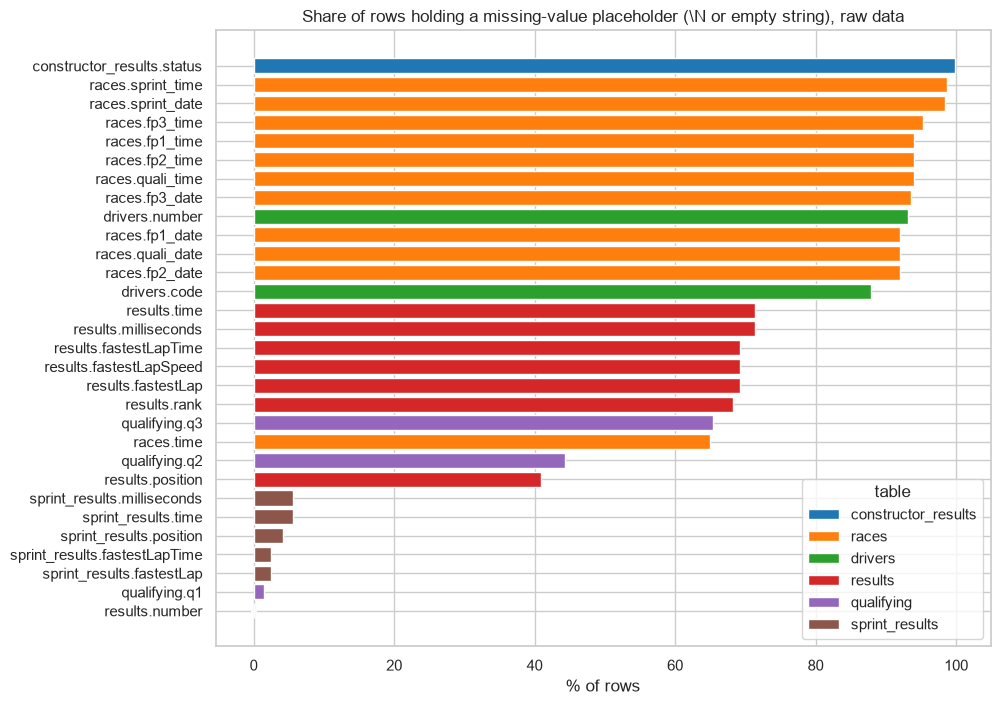

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
labels = missing['table'] + '.' + missing['column']
palette = dict(zip(missing['table'].unique(), sns.color_palette('tab10', missing['table'].nunique())))
ax.barh(labels[::-1], missing['pct_missing'][::-1], color=[palette[t] for t in missing['table'][::-1]])
for t, col in palette.items():
    ax.bar(0, 0, color=col, label=t)
ax.set(title='Share of rows holding a missing-value placeholder (\\N or empty string), raw data',
       xlabel='% of rows', ylabel='')
ax.legend(title='table', loc='lower right')
save_fig(fig, 's1_missing_by_column')
plt.show()

**Interpretation.** Missingness is concentrated in a few, explainable places:
* `races.fp*/quali_*/sprint_*` dates and times exist only for recent seasons (the schedule fields were added later);
  `races.time` (start time) is missing for most older races. None of these are needed as features.
* `constructor_results.status` is almost entirely `\N` (only a handful of disqualification codes) → uninformative.
* `drivers.number` / `drivers.code` exist only for modern drivers (permanent numbers/codes started recently).
* In `results`, the outcome columns (`position`, `time`, `milliseconds`, `fastestLap*`, `rank`) are missing for drivers
  who were not classified or for seasons where the data was never recorded — these are post-race columns and leakage
  anyway.
* **`qualifying.q2` / `q3`** are missing for drivers knocked out earlier (knockout format since 2006) and for older
  single-session formats — **and 22 / 46 cells are empty strings instead of `\N`**. `na_values=['\\N']` alone would not
  catch them; they became NaN only because pandas' default NA list includes `''`. Step 2 will treat both placeholders
  explicitly.

The matrices below show *where* the gaps sit in time (rows sorted chronologically: oldest at the top).

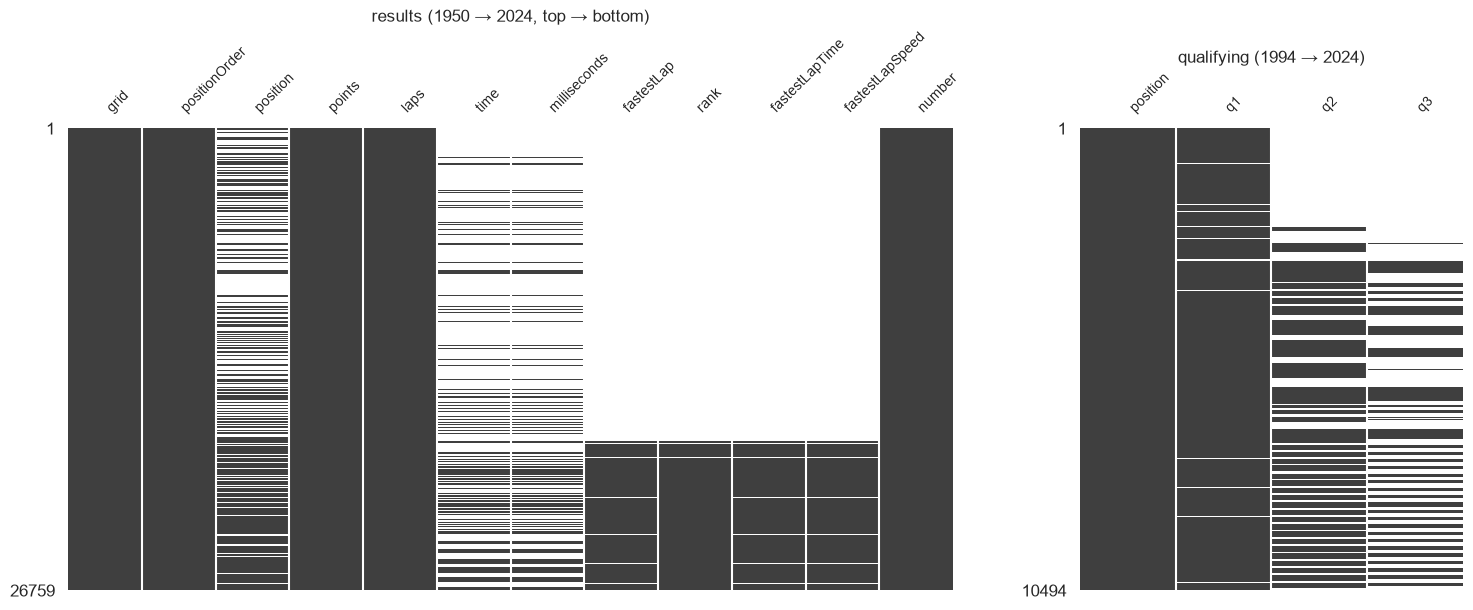

In [7]:
season_cols = raw['races'][['raceId', 'year', 'round']]

res_sorted = raw['results'].merge(season_cols, on='raceId').sort_values(['year', 'round'])
q_sorted = raw['qualifying'].merge(season_cols, on='raceId').sort_values(['year', 'round'])

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [3, 1.3]})
msno.matrix(res_sorted[['grid', 'positionOrder', 'position', 'points', 'laps', 'time', 'milliseconds',
                        'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'number']],
            ax=axes[0], sparkline=False, fontsize=10)
axes[0].set_title('results (1950 → 2024, top → bottom)')
msno.matrix(q_sorted[['position', 'q1', 'q2', 'q3']], ax=axes[1], sparkline=False, fontsize=10)
axes[1].set_title('qualifying (1994 → 2024)')
save_fig(fig, 's1_missingno_results_qualifying')
plt.show()

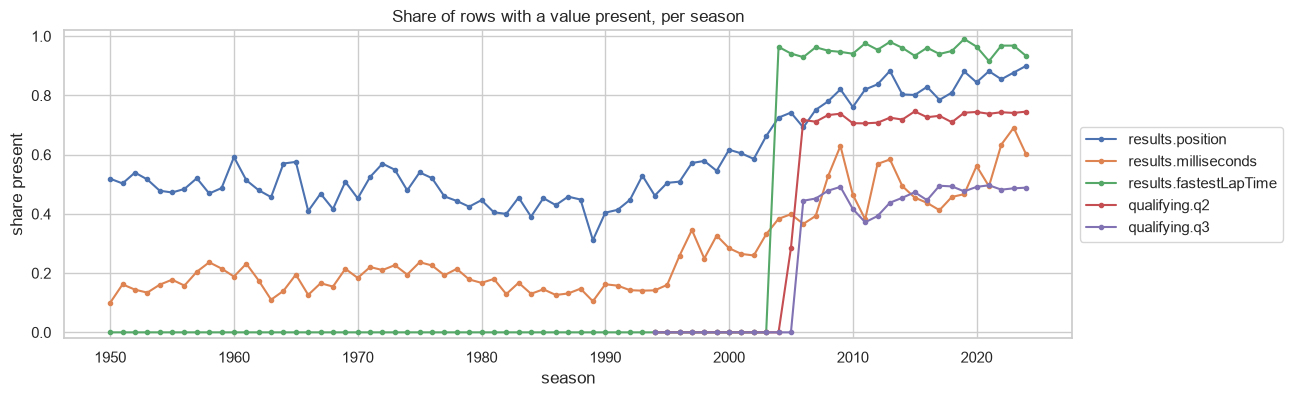

In [8]:
present = pd.concat({
    'results.position': res_sorted.groupby('year')['position'].apply(lambda s: s.notna().mean()),
    'results.milliseconds': res_sorted.groupby('year')['milliseconds'].apply(lambda s: s.notna().mean()),
    'results.fastestLapTime': res_sorted.groupby('year')['fastestLapTime'].apply(lambda s: s.notna().mean()),
    'qualifying.q2': q_sorted.groupby('year')['q2'].apply(lambda s: s.notna().mean()),
    'qualifying.q3': q_sorted.groupby('year')['q3'].apply(lambda s: s.notna().mean()),
}, axis=1)
fig, ax = plt.subplots(figsize=(13, 4))
present.plot(ax=ax, marker='.', linewidth=1.5)
ax.set(title='Share of rows with a value present, per season', xlabel='season', ylabel='share present', ylim=(-0.02, 1.02))
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
save_fig(fig, 's1_presence_by_season')
plt.show()

* `fastestLapTime` is recorded only from **2004** onward (bar a few rows) — it is not "missing at random" but missing by era.
* `q2`/`q3` appear with the 2006 knockout format; within that era 50–63 % of drivers per season have no `q3` by
  design (only the top 10 reach Q3). A missing `q3` is therefore **informative** (it means "eliminated earlier"),
  which matters for qualifying features in Step 4.
* `position` is present for only 40–50 % of rows per decade before 2000 (retirements, non-qualifiers), rising to
  ≈ 85 % in the 2020s — another face of the era drift in reliability and field size.

The next check confirms the documented rule that **`position` is NaN exactly when `positionText` is a letter code**.

In [9]:
r = raw['results']
code_type = np.where(r['positionText'].str.isdigit(), 'numeric', r['positionText'])
ct = pd.crosstab(pd.Series(code_type, name='positionText'), r['position'].isna().rename('position is NaN'))
display(ct)
odd = r[r['positionText'].str.isdigit() & r['position'].isna()]
print(f'Rows with a numeric positionText but NaN position: {len(odd)}')
odd.merge(season_cols, on='raceId')[['resultId', 'year', 'round', 'driverId', 'grid', 'position', 'positionText',
                                       'positionOrder', 'laps', 'statusId']]

position is NaN,False,True
positionText,,
D,0,151
E,0,9
F,0,1368
N,0,190
R,0,8897
W,0,336
numeric,15806,2


Rows with a numeric positionText but NaN position: 2


,resultId,year,round,driverId,grid,position,positionText,positionOrder,laps,statusId
0,1149,2005,1,18,8,NaN,11,11,56,11
1,1152,2005,1,11,20,NaN,14,14,55,12


Letter codes (R retired, F failed to qualify, W withdrawn, N not classified, D disqualified, E excluded) always have
`position = NaN`, as expected. Two rows have a numeric `positionText` but no `position` — a small inconsistency inside
the source data. It does not affect the target (`positionOrder` is filled for both, and neither is a podium), so it is
documented and left as is.

## 1.5 Primary-key checks
A primary key must be **unique and non-null**. We check the surrogate id of every table, the composite key of the two
tables that have none (`lap_times`, `pit_stops`), and the **natural keys** that the analysis relies on — most
importantly `(raceId, driverId)` in `results`, which is our modeling grain.

In [10]:
PK = {'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'], 'seasons': ['year'],
      'status': ['statusId'], 'races': ['raceId'], 'results': ['resultId'], 'qualifying': ['qualifyId'],
      'sprint_results': ['resultId'], 'driver_standings': ['driverStandingsId'],
      'constructor_standings': ['constructorStandingsId'], 'constructor_results': ['constructorResultsId'],
      'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop']}
NATURAL = {'circuits': ['circuitRef'], 'constructors': ['constructorRef'], 'drivers': ['driverRef'],
           'races': ['year', 'round'], 'results': ['raceId', 'driverId'], 'qualifying': ['raceId', 'driverId'],
           'sprint_results': ['raceId', 'driverId'], 'driver_standings': ['raceId', 'driverId'],
           'constructor_standings': ['raceId', 'constructorId'], 'constructor_results': ['raceId', 'constructorId']}

def key_check(t, cols, kind):
    df = raw[t]
    nulls = int(df[cols].isna().any(axis=1).sum())
    dups = int(df.duplicated(cols, keep=False).sum())
    return {'table': t, 'key_type': kind, 'key': ', '.join(cols), 'rows': len(df),
            'null_key_rows': nulls, 'duplicate_key_rows': dups, 'valid_key': nulls == 0 and dups == 0}

keys = pd.DataFrame([key_check(t, c, 'primary') for t, c in PK.items()] +
                    [key_check(t, c, 'natural') for t, c in NATURAL.items()])
keys

,table,key_type,key,rows,null_key_rows,duplicate_key_rows,valid_key
0,circuits,primary,circuitId,77,0,0,True
1,constructors,primary,constructorId,212,0,0,True
2,drivers,primary,driverId,861,0,0,True
3,seasons,primary,year,75,0,0,True
4,status,primary,statusId,139,0,0,True
5,races,primary,raceId,1125,0,0,True
6,results,primary,resultId,26759,0,0,True
7,qualifying,primary,qualifyId,10494,0,0,True
8,sprint_results,primary,resultId,360,0,0,True
9,driver_standings,primary,driverStandingsId,34863,0,0,True


Every primary key and every natural key is valid **except `results (raceId, driverId)`**: 176 rows share a
`(raceId, driverId)` with another row. This violates the required grain (one prediction per driver per race) and is
investigated in §1.7. Note that `qualifying`, `sprint_results` and both standings tables are already unique at their
natural grain, so they can be joined onto `results` without fanning out rows.

## 1.6 Foreign-key checks
Every foreign key value must exist in the table it points to; otherwise joins silently drop or null-out rows.

In [11]:
FK = [('results', 'raceId', 'races', 'raceId'), ('results', 'driverId', 'drivers', 'driverId'),
      ('results', 'constructorId', 'constructors', 'constructorId'), ('results', 'statusId', 'status', 'statusId'),
      ('qualifying', 'raceId', 'races', 'raceId'), ('qualifying', 'driverId', 'drivers', 'driverId'),
      ('qualifying', 'constructorId', 'constructors', 'constructorId'),
      ('sprint_results', 'raceId', 'races', 'raceId'), ('sprint_results', 'driverId', 'drivers', 'driverId'),
      ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
      ('sprint_results', 'statusId', 'status', 'statusId'),
      ('driver_standings', 'raceId', 'races', 'raceId'), ('driver_standings', 'driverId', 'drivers', 'driverId'),
      ('constructor_standings', 'raceId', 'races', 'raceId'),
      ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
      ('constructor_results', 'raceId', 'races', 'raceId'),
      ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
      ('lap_times', 'raceId', 'races', 'raceId'), ('lap_times', 'driverId', 'drivers', 'driverId'),
      ('pit_stops', 'raceId', 'races', 'raceId'), ('pit_stops', 'driverId', 'drivers', 'driverId'),
      ('races', 'circuitId', 'circuits', 'circuitId'), ('races', 'year', 'seasons', 'year')]

def fk_check(child, col, parent, pcol):
    vals = raw[child][col]
    orphan = vals.notna() & ~vals.isin(raw[parent][pcol])
    return {'foreign_key': f'{child}.{col}', 'references': f'{parent}.{pcol}', 'rows': len(vals),
            'null_fk': int(vals.isna().sum()), 'orphan_rows': int(orphan.sum()),
            'orphan_values': int(vals[orphan].nunique()), 'reconciles': not orphan.any() and vals.notna().all()}

fks = pd.DataFrame([fk_check(*f) for f in FK])
print(f'{fks["reconciles"].sum()} / {len(fks)} foreign keys reconcile')
fks

23 / 23 foreign keys reconcile


,foreign_key,references,rows,null_fk,orphan_rows,orphan_values,reconciles
0,results.raceId,races.raceId,26759,0,0,0,True
1,results.driverId,drivers.driverId,26759,0,0,0,True
2,results.constructorId,constructors.constructorId,26759,0,0,0,True
3,results.statusId,status.statusId,26759,0,0,0,True
4,qualifying.raceId,races.raceId,10494,0,0,0,True
5,qualifying.driverId,drivers.driverId,10494,0,0,0,True
6,qualifying.constructorId,constructors.constructorId,10494,0,0,0,True
7,sprint_results.raceId,races.raceId,360,0,0,0,True
8,sprint_results.driverId,drivers.driverId,360,0,0,0,True
9,sprint_results.constructorId,constructors.constructorId,360,0,0,0,True


All 23 foreign-key relationships reconcile: no nulls, no orphans. Referential integrity alone does not guarantee that
the tables *agree with each other*, so we also check cross-table consistency at the `(raceId, driverId)` level.

In [12]:
res_keys = raw['results'][['raceId', 'driverId']].drop_duplicates()

def pairs_missing_from_results(t):
    k = raw[t][['raceId', 'driverId']].drop_duplicates()
    m = k.merge(res_keys, how='left', indicator=True)
    return int((m['_merge'] == 'left_only').sum()), len(k)

checks = []
for t in ['qualifying', 'sprint_results', 'lap_times', 'pit_stops', 'driver_standings']:
    n_missing, n_pairs = pairs_missing_from_results(t)
    checks.append({'check': f'{t} (raceId, driverId) pairs with no results row', 'violations': n_missing, 'out_of': n_pairs})

qc = raw['qualifying'][['raceId', 'driverId', 'constructorId']].merge(
    raw['results'].drop_duplicates(['raceId', 'driverId'])[['raceId', 'driverId', 'constructorId']],
    on=['raceId', 'driverId'], suffixes=('_quali', '_result'))
checks.append({'check': 'qualifying constructor differs from results constructor (same race & driver)',
               'violations': int((qc['constructorId_quali'] != qc['constructorId_result']).sum()), 'out_of': len(qc)})
checks.append({'check': 'races without any results row',
               'violations': int((~raw['races']['raceId'].isin(raw['results']['raceId'])).sum()),
               'out_of': len(raw['races'])})
checks.append({'check': 'seasons without any race',
               'violations': int((~raw['seasons']['year'].isin(raw['races']['year'])).sum()),
               'out_of': len(raw['seasons'])})
display(pd.DataFrame(checks))

print('qualifying vs results constructor mismatches:')
qc[qc['constructorId_quali'] != qc['constructorId_result']].merge(season_cols, on='raceId')

,check,violations,out_of
0,"qualifying (raceId, driverId) pairs with no re...",0,10494
1,"sprint_results (raceId, driverId) pairs with n...",0,360
2,"lap_times (raceId, driverId) pairs with no res...",0,11041
3,"pit_stops (raceId, driverId) pairs with no res...",0,5575
4,"driver_standings (raceId, driverId) pairs with...",8664,34863
5,qualifying constructor differs from results co...,10,10494
6,races without any results row,0,1125
7,seasons without any race,0,75


qualifying vs results constructor mismatches:


,raceId,driverId,constructorId_quali,constructorId_result,year,round
0,937,829,206,209,2015,11
1,937,833,206,209,2015,11
2,941,829,206,209,2015,15
3,941,833,206,209,2015,15
4,942,834,206,209,2015,16
5,942,829,206,209,2015,16
6,943,834,206,209,2015,17
7,943,829,206,209,2015,17
8,944,834,206,209,2015,18
9,944,829,206,209,2015,18


* Qualifying, sprint, lap-time and pit-stop rows all belong to a driver who has a `results` row in that race, so a
  **left join from `results`** keeps every relevant record.
* `driver_standings` contains `(race, driver)` pairs with no `results` row: the standings table lists every driver who
  has scored in the season so far, even if they did not enter that particular round. This matters for Step 4 — the
  "standings before this race" feature must be looked up from the **previous round of the season**, not from a
  same-race join.
* 10 qualifying rows name a different constructor than the driver's `results` row. All 10 are the same team in
  2015 rounds 11–18: `qualifying` still uses **Marussia** (id 206) while `results` uses **Manor Marussia** (id 209) —
  the constructor-rename identity drift described in the F1 primer. `results` (the race entry) is treated as the
  authoritative constructor, so constructor features will be keyed on `results.constructorId`.
* Every race has results and every season has races, so no calendar gaps.

## 1.7 Duplicate `(raceId, driverId)` rows — shared drives
Because every FK reconciles, we can safely build an **audit view** of `results` enriched with season, race name,
status text and names (validated many-to-one joins, row count must stay 26,759).

In [13]:
drivers_name = raw['drivers'].assign(driver=raw['drivers']['forename'] + ' ' + raw['drivers']['surname'])
res = (raw['results']
       .merge(raw['races'][['raceId', 'year', 'round', 'name', 'circuitId']], on='raceId', how='left', validate='many_to_one')
       .merge(raw['status'], on='statusId', how='left', validate='many_to_one')
       .merge(drivers_name[['driverId', 'driver', 'nationality']], on='driverId', how='left', validate='many_to_one')
       .merge(raw['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor'}),
              on='constructorId', how='left', validate='many_to_one'))
res['podium'] = (res['positionOrder'] <= 3).astype(int)
assert len(res) == len(raw['results'])
print(f'audit view: {res.shape[0]:,} rows, overall podium rate = {res["podium"].mean():.3f}')

dup_mask = res.duplicated(['raceId', 'driverId'], keep=False)
dups = res[dup_mask].sort_values(['year', 'raceId', 'driverId', 'resultId'])
n_pairs = dups[['raceId', 'driverId']].drop_duplicates().shape[0]
print(f'duplicate (raceId, driverId): {n_pairs} pairs, {len(dups)} rows '
      f'({len(dups) - n_pairs} surplus rows), in {dups["raceId"].nunique()} races')

audit view: 26,759 rows, overall podium rate = 0.127
duplicate (raceId, driverId): 85 pairs, 176 rows (91 surplus rows), in 42 races


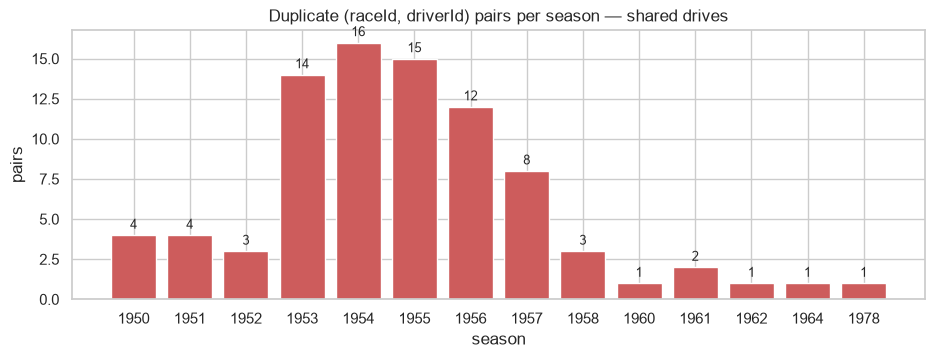

,resultId,year,name,driver,constructor,number,grid,laps,positionOrder,points,status
0,20097,1950,Indianapolis 500,Tony Bettenhausen,Deidt,14.0,8,30,31,0.0,Wheel bearing
1,20179,1950,Indianapolis 500,Tony Bettenhausen,Kurtis Kraft,17.0,9,136,5,1.0,+2 Laps
2,20143,1950,French Grand Prix,Louis Rosier,Talbot-Lago,20.0,6,10,12,0.0,Overheating
3,20182,1950,French Grand Prix,Louis Rosier,Talbot-Lago,26.0,15,56,6,0.0,+8 Laps


In [14]:
pairs_per_year = dups.drop_duplicates(['raceId', 'driverId']).groupby('year').size()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(pairs_per_year.index.astype(str), pairs_per_year.values, color='indianred')
ax.set(title='Duplicate (raceId, driverId) pairs per season — shared drives', xlabel='season', ylabel='pairs')
for x, v in zip(pairs_per_year.index.astype(str), pairs_per_year.values):
    ax.text(x, v + 0.4, str(v), ha='center', fontsize=9)
save_fig(fig, 's1_duplicate_pairs_by_season')
plt.show()

show_cols = ['resultId', 'year', 'name', 'driver', 'constructor', 'number', 'grid', 'laps',
             'positionOrder', 'points', 'status']
example_ids = dups.drop_duplicates(['raceId', 'driverId']).head(2)[['raceId', 'driverId']]
dups.merge(example_ids)[show_cols]

The duplicates are concentrated in **1950–1958** (shared drives: a driver handed his car to a teammate, or took over
a teammate's car after his own retired; points were split) with isolated cases up to 1978. In the examples, each row
is a **different car** (different car number / constructor entry) with its own grid slot and lap count.

**Proposed keep rule** (applied in Step 2, evaluated here):
1. keep the row where the driver **started** the car (`grid > 0`);
2. if still tied, keep the row with the **most laps** (the car the driver drove for most of the race — his main entry);
3. if still tied, keep the **lowest `resultId`** (deterministic tie-break).

The cell below measures which tier actually decides each pair, and whether the rule ever discards a podium in favour
of a non-podium — compared with the alternative rule "keep the best `positionOrder`".

In [15]:
ranked = dups.assign(started=(dups['grid'] > 0).astype(int)).sort_values(
    ['raceId', 'driverId', 'started', 'laps', 'resultId'], ascending=[True, True, False, False, True])
kept = ranked.drop_duplicates(['raceId', 'driverId'], keep='first')

def deciding_tier(g):
    if g['started'].sum() == 1:
        return '1: grid > 0'
    cand = g[g['started'] == 1] if g['started'].sum() > 1 else g
    if (cand['laps'] == cand['laps'].max()).sum() == 1:
        return '2: most laps'
    return '3: lowest resultId'

tiers = pd.Series({k: deciding_tier(g) for k, g in ranked.groupby(['raceId', 'driverId'])}).value_counts().sort_index()
display(tiers.rename('pairs decided').to_frame())

best_pos = dups.sort_values(['raceId', 'driverId', 'positionOrder']).drop_duplicates(['raceId', 'driverId'])
cmp = kept[['raceId', 'driverId', 'resultId', 'podium']].merge(
    best_pos[['raceId', 'driverId', 'resultId', 'podium']], on=['raceId', 'driverId'], suffixes=('_rule', '_bestpos'))
summary = pd.Series({
    'pairs': len(cmp),
    'pairs with any podium row': int(dups.groupby(['raceId', 'driverId'])['podium'].max().sum()),
    'rule keeps a podium row': int(cmp['podium_rule'].sum()),
    'best-positionOrder keeps a podium row': int(cmp['podium_bestpos'].sum()),
    'pairs where the two rules pick different rows': int((cmp['resultId_rule'] != cmp['resultId_bestpos']).sum()),
    'pairs inside Indianapolis 500 races': int(kept['name'].str.contains('Indianapolis 500').sum()),
    'rows before -> after (preview)': f'{len(raw["results"]):,} -> {len(raw["results"]) - (len(dups) - len(kept)):,}',
})
summary.to_frame('value')

,pairs decided
2: most laps,82
3: lowest resultId,3


,value
pairs,85
pairs with any podium row,22
rule keeps a podium row,22
best-positionOrder keeps a podium row,22
pairs where the two rules pick different rows,0
pairs inside Indianapolis 500 races,21
rows before -> after (preview),"26,759 -> 26,668"


**What the evidence says**
* Tier 1 (`grid > 0`) **never** decides: in every pair both cars carry a grid slot, so the "started car" criterion
  alone cannot separate them. **Most laps decides 82 of 85 pairs**; the `resultId` tie-break is needed for 3.
* The rule and "best `positionOrder`" pick **the same row in all 85 pairs**, and all 22 pairs that contain a podium row
  keep it. So the choice does not change a single target label — the rule is preferred because it selects the driver's
  main drive by *how much he drove* rather than by *how well the car finished*, i.e. it is not chosen by the outcome.
* 21 of the 85 pairs are in Indianapolis 500 races, which are excluded in Step 2 anyway.
* Deduplication removes 91 surplus rows (26,759 → 26,668 before any other exclusion). Applied, with before/after
  counts, in Step 2.

## 1.8 Exploratory analysis **before** cleaning
All plots in this section use the raw data (duplicates, `grid = 0` rows and Indianapolis 500 races still included),
so that Step 2 can show the effect of each cleaning decision against this baseline.

### 1.8.1 Season length and field size

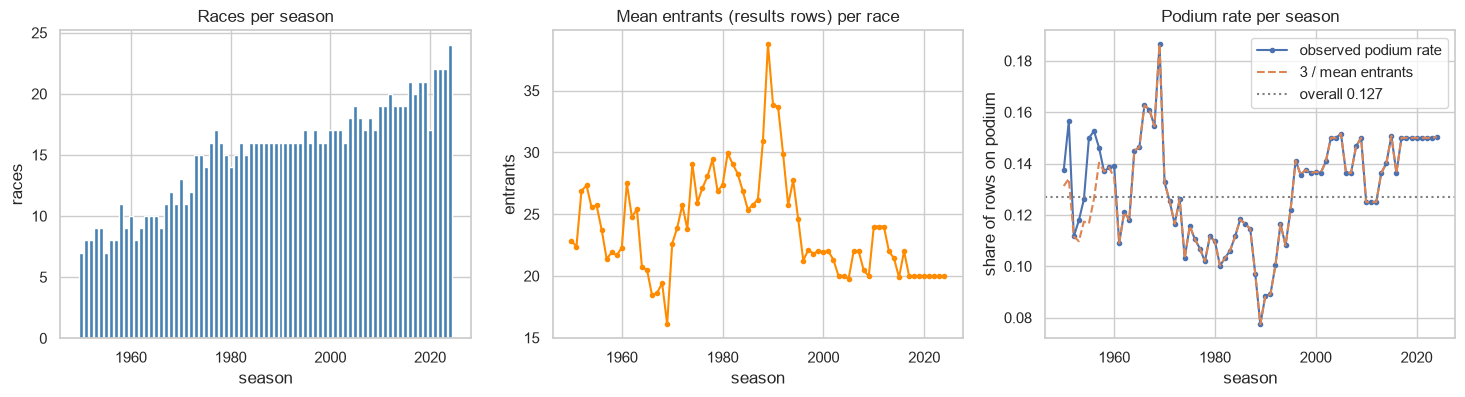

podium rows per race: {3: 1107, 4: 16, 5: 1, 7: 1}
races where two or more rows share the same positionOrder: 46 (seasons 1950–1964)


,year,name,positionOrder,driver,constructor,number,laps,points
20149,1950,Italian Grand Prix,1,Nino Farina,Alfa Romeo,10.0,80,8.0
20150,1950,Italian Grand Prix,2,Dorino Serafini,Ferrari,48.0,80,3.0
20182,1950,Italian Grand Prix,2,Alberto Ascari,Ferrari,48.0,80,3.0
20151,1950,Italian Grand Prix,3,Luigi Fagioli,Alfa Romeo,36.0,80,4.0
19871,1951,Indianapolis 500,1,Lee Wallard,Kurtis Kraft,99.0,200,9.0
19872,1951,Indianapolis 500,2,Mike Nazaruk,Kurtis Kraft,83.0,200,6.0
19873,1951,Indianapolis 500,3,Jack McGrath,Kurtis Kraft,9.0,200,2.0
20184,1951,Indianapolis 500,3,Manny Ayulo,Kurtis Kraft,9.0,200,2.0
19917,1951,French Grand Prix,1,Luigi Fagioli,Alfa Romeo,8.0,77,4.0
20185,1951,French Grand Prix,1,Juan Fangio,Alfa Romeo,8.0,77,5.0


In [16]:
per_race = res.groupby(['year', 'raceId']).agg(entrants=('driverId', 'size'), podiums=('podium', 'sum')).reset_index()
season = per_race.groupby('year').agg(races=('raceId', 'nunique'), mean_entrants=('entrants', 'mean'))
season['podium_rate'] = res.groupby('year')['podium'].mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].bar(season.index, season['races'], color='steelblue')
axes[0].set(title='Races per season', xlabel='season', ylabel='races')
axes[1].plot(season.index, season['mean_entrants'], color='darkorange', marker='.')
axes[1].set(title='Mean entrants (results rows) per race', xlabel='season', ylabel='entrants')
axes[2].plot(season.index, season['podium_rate'], marker='.', label='observed podium rate')
axes[2].plot(season.index, 3 / season['mean_entrants'], linestyle='--', label='3 / mean entrants')
axes[2].axhline(res['podium'].mean(), color='grey', linestyle=':', label=f'overall {res["podium"].mean():.3f}')
axes[2].set(title='Podium rate per season', xlabel='season', ylabel='share of rows on podium')
axes[2].legend()
save_fig(fig, 's1_season_size_podium_rate')
plt.show()

print('podium rows per race:', per_race['podiums'].value_counts().sort_index().to_dict())
shared_pos = res[res.duplicated(['raceId', 'positionOrder'], keep=False)]
print(f'races where two or more rows share the same positionOrder: {shared_pos["raceId"].nunique()} '
      f'(seasons {shared_pos["year"].min()}–{shared_pos["year"].max()})')
over = per_race.loc[per_race['podiums'] != 3, 'raceId']
(res[res['raceId'].isin(over) & (res['podium'] == 1)]
   .sort_values(['year', 'raceId', 'positionOrder'])[['year', 'name', 'positionOrder', 'driver', 'constructor', 'number', 'laps', 'points']]
   .head(12))

* The calendar grew from 7 races (1950) to 24 (2024), while field size peaked in **1989 (≈ 39 entrants per race in
  `results`)** — the pre-qualifying era.
* The podium rate tracks **3 / entrants** closely — it is a mechanical consequence of field size, not of driver
  quality. The base rate therefore drifts across eras (7.7–8.9 % in 1989–91 vs 15 % in 2022–24); this is a key
  argument for restricting the training window and for using **PR-AUC** (whose no-skill baseline equals the positive
  rate) in Step 6.
* **Not every race has exactly 3 podium rows**: 18 races (all 1950–1960) have 4, 5 or 7. The listing shows why —
  when two drivers **shared one car**, both are credited with that car's `positionOrder` (e.g. two rows with
  `positionOrder = 1`, each with half the points). This is a second shared-drive artefact, distinct from the duplicate
  `(raceId, driverId)` rows of §1.7: there each *driver* has two rows, here each *car result* has two drivers. Both
  co-drivers genuinely drove the podium car, so the default is to keep both as podium; the handling is decided and
  documented in Step 2.

### 1.8.2 Table coverage over time (qualifying-coverage drift)

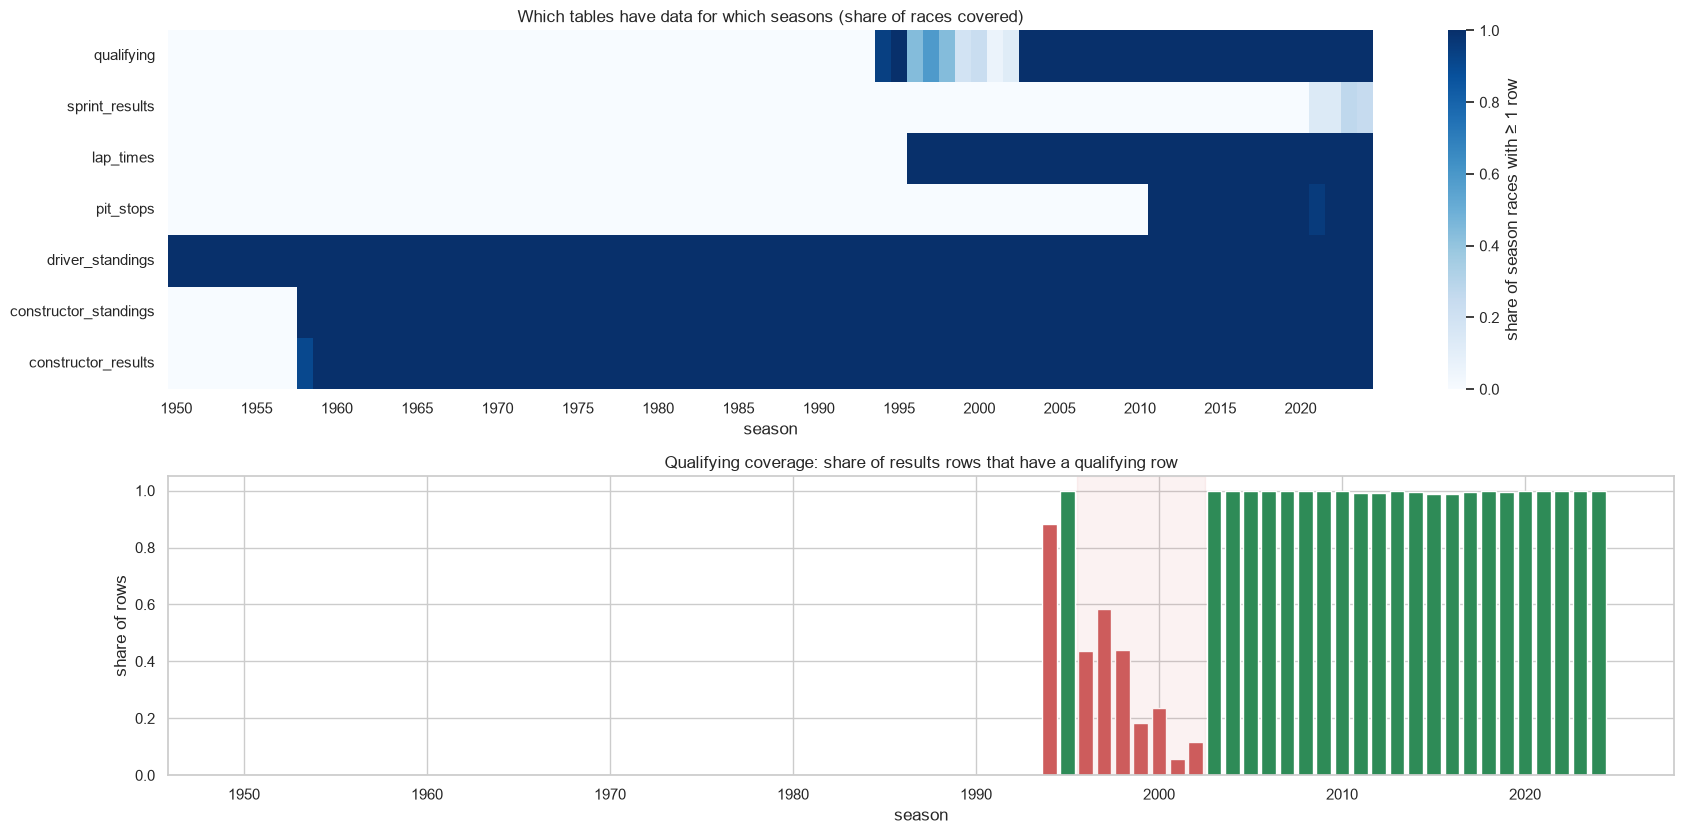

{1993: 0.0, 1994: 0.88, 1995: 1.0, 1996: 0.44, 1997: 0.59, 1998: 0.44, 1999: 0.18, 2000: 0.24, 2001: 0.06, 2002: 0.12, 2003: 1.0, 2004: 1.0}


In [17]:
season_races = raw['races'].groupby('year')['raceId'].nunique()
cov_tables = ['qualifying', 'sprint_results', 'lap_times', 'pit_stops',
              'driver_standings', 'constructor_standings', 'constructor_results']
coverage = pd.DataFrame({
    t: raw[t][['raceId']].drop_duplicates().merge(raw['races'][['raceId', 'year']], on='raceId')
         .groupby('year').size().reindex(season_races.index, fill_value=0) / season_races
    for t in cov_tables}).T

q_keys = raw['qualifying'][['raceId', 'driverId']].drop_duplicates()
res = res.merge(q_keys, on=['raceId', 'driverId'], how='left', indicator='q_merge')
res['has_quali'] = res.pop('q_merge').eq('both')
row_cov = res.groupby('year')['has_quali'].mean()

fig, axes = plt.subplots(2, 1, figsize=(17, 8.5), gridspec_kw={'height_ratios': [1.2, 1]})
sns.heatmap(coverage, cmap='Blues', vmin=0, vmax=1, xticklabels=5, ax=axes[0],
            cbar_kws={'label': 'share of season races with ≥ 1 row'})
axes[0].set(title='Which tables have data for which seasons (share of races covered)', xlabel='season', ylabel='')
colors = np.where(row_cov.index < 1994, 'lightgrey', np.where(row_cov < 0.95, 'indianred', 'seagreen'))
axes[1].bar(row_cov.index, row_cov.values, color=colors)
axes[1].axvspan(1995.5, 2002.5, color='indianred', alpha=0.08)
axes[1].set(title='Qualifying coverage: share of results rows that have a qualifying row',
            xlabel='season', ylabel='share of rows', ylim=(0, 1.05))
plt.tight_layout()
save_fig(fig, 's1_table_coverage_qualifying_drift')
plt.show()

print(row_cov.loc[1993:2004].round(2).to_dict())

This is the **historical qualifying-coverage drift** the brief warns about, confirmed on our own copy:
* **0 %** of rows have qualifying data before **1994**; 1994–95 are almost complete (88 %, 100 %);
* **1996–2002 is patchy (6–59 %)** — qualifying rows are missing for most drivers, not missing at random;
* **≈ 100 % from 2003** on.

A qualifying feature would therefore be NaN for most of history and *structurally* NaN in 1996–2002. The handling
options (fall back to `grid`, add missing-indicators, or restrict the training window to well-covered seasons) are
decided in Steps 4–5 with this plot as evidence. The heatmap also fixes what each table can contribute:
`sprint_results` exists only for a subset of 2021–2024 weekends, constructor standings start in 1958, and
`lap_times`/`pit_stops` are post-race data.

### 1.8.3 Grid position — the strongest pre-race signal, and the `grid = 0` rows

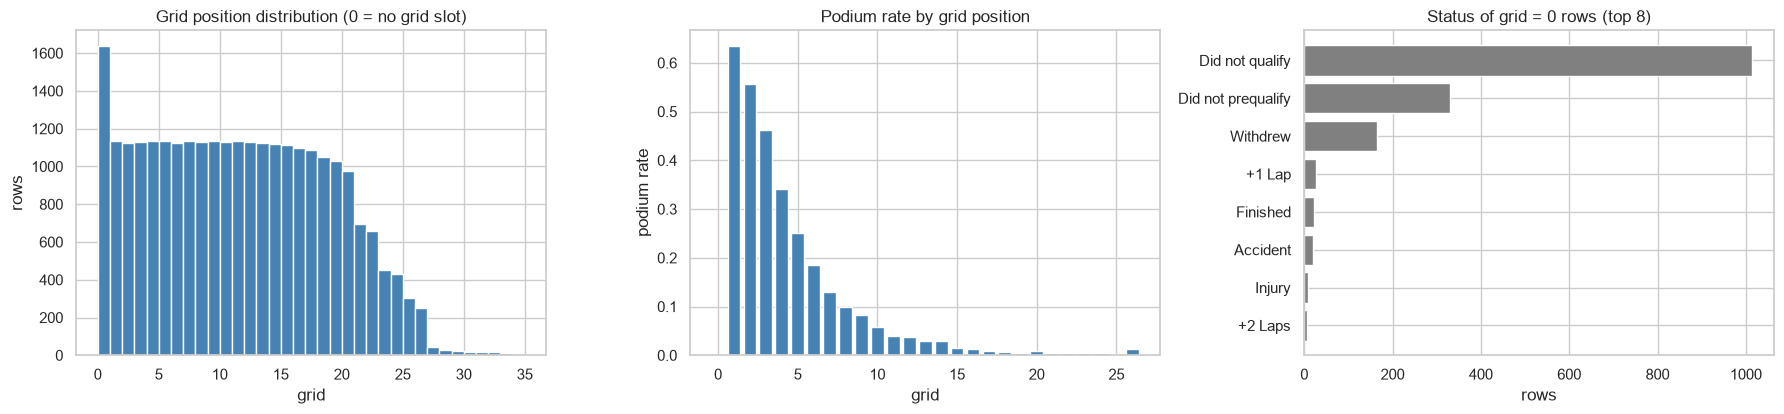

grid == 0: 1,638 rows (6.1%), podiums among them: 0
grid == 0 rows by decade: {1950: 68, 1960: 198, 1970: 351, 1980: 571, 1990: 357, 2000: 8, 2010: 28, 2020: 57}


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
axes[0].hist(res['grid'], bins=range(0, int(res['grid'].max()) + 2), color='steelblue')
axes[0].set(title='Grid position distribution (0 = no grid slot)', xlabel='grid', ylabel='rows')

rate = res[res['grid'] <= 26].groupby('grid')['podium'].mean()
axes[1].bar(rate.index, rate.values, color=['crimson' if g == 0 else 'steelblue' for g in rate.index])
axes[1].set(title='Podium rate by grid position', xlabel='grid', ylabel='podium rate')

g0 = res.loc[res['grid'] == 0, 'status'].value_counts().head(8)
axes[2].barh(g0.index[::-1], g0.values[::-1], color='grey')
axes[2].set(title='Status of grid = 0 rows (top 8)', xlabel='rows')
plt.tight_layout()
save_fig(fig, 's1_grid_distribution_podium_rate')
plt.show()

g0_rows = res[res['grid'] == 0]
print(f'grid == 0: {len(g0_rows):,} rows ({len(g0_rows)/len(res):.1%}), podiums among them: {g0_rows["podium"].sum()}')
print('grid == 0 rows by decade:', g0_rows.groupby(g0_rows['year'] // 10 * 10).size().to_dict())

* Podium probability falls steeply with grid position (pole ≈ 64 %, grid 10 ≈ 6 %) — grid is the natural baseline
  feature.
* **`grid = 0` (1,638 rows) never produced a podium.** These rows are mostly *non-starters* — "Did not qualify",
  "Did not prequalify", "Withdrew" — plus a few genuine pit-lane starts that finished. A non-starter's outcome is
  known before the race (they cannot finish on the podium), so keeping them would inflate the negative class with
  trivially easy rows. How to treat them (drop non-starters vs keep pit-lane starters with a flag) is decided in Step 2.

### 1.8.4 Qualifying position vs grid position (2003–2024, full qualifying coverage)

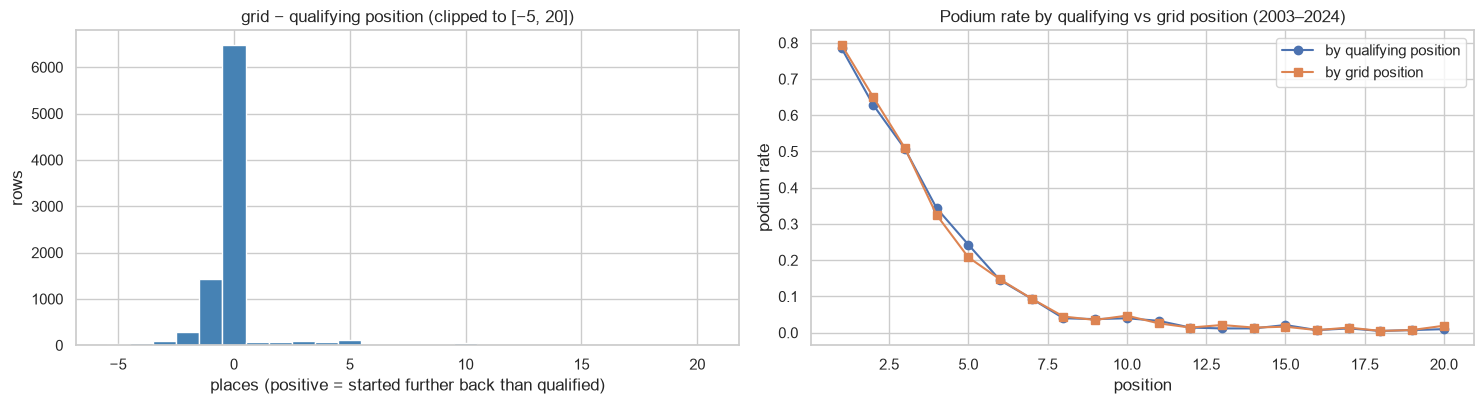

rows where grid == qualifying position: 73.0%;  grid behind qualifying: 5.8%;  grid ahead of qualifying: 21.2%


In [19]:
gq = res[res['year'] >= 2003].merge(
    raw['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'}),
    on=['raceId', 'driverId'], how='inner')
started = gq[gq['grid'] > 0]
diff = started['grid'] - started['quali_pos']

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].hist(diff.clip(-5, 20), bins=np.arange(-5.5, 21.5, 1), color='steelblue')
axes[0].set(title='grid − qualifying position (clipped to [−5, 20])',
            xlabel='places (positive = started further back than qualified)', ylabel='rows')
pr_q = gq.groupby('quali_pos')['podium'].mean().loc[1:20]
pr_g = started.groupby('grid')['podium'].mean().loc[1:20]
axes[1].plot(pr_q.index, pr_q.values, marker='o', label='by qualifying position')
axes[1].plot(pr_g.index, pr_g.values, marker='s', label='by grid position')
axes[1].set(title='Podium rate by qualifying vs grid position (2003–2024)', xlabel='position', ylabel='podium rate')
axes[1].legend()
plt.tight_layout()
save_fig(fig, 's1_grid_vs_qualifying')
plt.show()
print(f'rows where grid == qualifying position: {(diff == 0).mean():.1%};  grid behind qualifying: {(diff > 0).mean():.1%};'
      f'  grid ahead of qualifying: {(diff < 0).mean():.1%}')

Grid and qualifying position differ for **27 % of starters**: 5.8 % start *behind* their qualifying position
(grid penalties), while 21.2 % start *ahead* of it — they inherit places when a car that out-qualified them is
penalised or starts from the pit lane. Both curves are steep, but they are **not
identical**, so the two variables carry different information: qualifying measures one-lap pace, grid is the actual
starting slot. This is why Q1 must distinguish them and why both are candidate features in Step 4.

### 1.8.5 Race status — reliability and non-starters over time

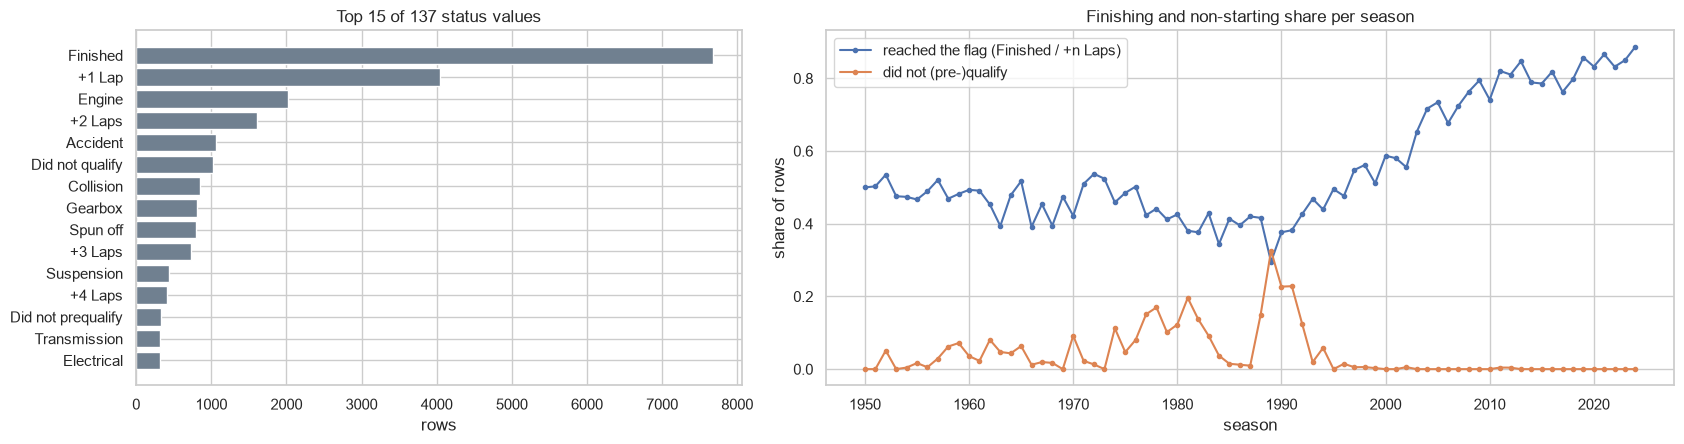

In [20]:
finished = res['status'].eq('Finished') | res['status'].str.fullmatch(r'\+\d+ Laps?')
nonstarter = res['status'].isin(['Did not qualify', 'Did not prequalify'])
by_year = res.assign(finished=finished, nonstarter=nonstarter).groupby('year')[['finished', 'nonstarter']].mean()

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1, 1.4]})
top = res['status'].value_counts().head(15)
axes[0].barh(top.index[::-1], top.values[::-1], color='slategray')
axes[0].set(title=f'Top 15 of {res["status"].nunique()} status values', xlabel='rows')
axes[1].plot(by_year.index, by_year['finished'], marker='.', label='reached the flag (Finished / +n Laps)')
axes[1].plot(by_year.index, by_year['nonstarter'], marker='.', label='did not (pre-)qualify')
axes[1].set(title='Finishing and non-starting share per season', xlabel='season', ylabel='share of rows')
axes[1].legend()
plt.tight_layout()
save_fig(fig, 's1_status_over_time')
plt.show()

* 139 status values, long-tailed: besides "Finished" / "+n Laps", the frequent ones are failure modes (Engine,
  Gearbox, Suspension …), incidents (Accident, Collision, Spun off) and non-starts. Step 2 groups them into
  **finished / mechanical / accident-driver / other** (needed for Q3 and for past-reliability features).
* Reliability improved enormously: only 39–49 % of entries per decade reached the flag before 2000, vs 80–86 % in
  the 2010s–2020s — the same grid slot converts to a podium far more reliably in the modern era (era sensitivity).
* DNQ/DNPQ rows are a late-1980s / early-1990s phenomenon (oversubscribed fields) and coincide with the `grid = 0`
  rows above.

### 1.8.6 The Indianapolis 500 (1950–1960)

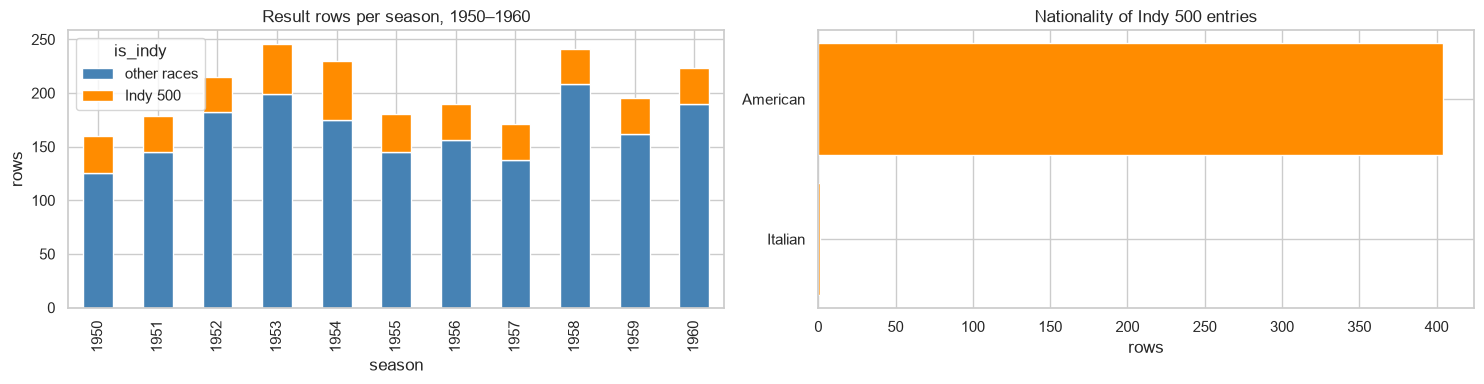

Indy 500 races: 11, rows: 405 (18.2% of 1950–60 rows)
drivers who appear in the Indy 500: 107; of them, never in any other championship race: 103


In [21]:
indy_ids = raw['races'].loc[raw['races']['name'].str.contains('Indianapolis 500'), 'raceId']
res['is_indy'] = res['raceId'].isin(indy_ids)
early = res[res['year'] <= 1960]
entries = early.groupby(['year', 'is_indy']).size().unstack(fill_value=0).rename(columns={False: 'other races', True: 'Indy 500'})

indy_drivers = set(res.loc[res['is_indy'], 'driverId'])
only_indy = indy_drivers - set(res.loc[~res['is_indy'], 'driverId'])
indy_nat = res.loc[res['is_indy'], 'nationality'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
entries.plot(kind='bar', stacked=True, ax=axes[0], color=['steelblue', 'darkorange'])
axes[0].set(title='Result rows per season, 1950–1960', xlabel='season', ylabel='rows')
axes[1].barh(indy_nat.index[::-1], indy_nat.values[::-1], color='darkorange')
axes[1].set(title='Nationality of Indy 500 entries', xlabel='rows')
plt.tight_layout()
save_fig(fig, 's1_indy500')
plt.show()
print(f'Indy 500 races: {len(indy_ids)}, rows: {res["is_indy"].sum()} ({res.loc[res.year <= 1960, "is_indy"].mean():.1%} of 1950–60 rows)')
print(f'drivers who appear in the Indy 500: {len(indy_drivers)}; of them, never in any other championship race: {len(only_indy)}')

The Indy 500 contributes a large share of 1950s rows, is entered almost exclusively by **American** drivers, and most
of those drivers never raced anywhere else in the championship. It therefore (i) inflates race counts and "home race"
counts for US drivers (distorting Q2), (ii) has a different grid structure (33-car oval field), and (iii) contributes
drivers with no history outside one race. Excluding the 11 races is documented and applied in Step 2.

### 1.8.7 Nationality vs circuit country (needed for "home race")

In [22]:
nat = raw['drivers']['nationality'].value_counts()
countries = raw['races'].merge(raw['circuits'][['circuitId', 'country']], on='circuitId')['country'].value_counts()

ws_values = {f'{t}.{c}': sorted(raw_str[t][c][raw_str[t][c] != raw_str[t][c].str.strip()].unique().tolist())
             for t in TABLES for c in raw_str[t].columns
             if (raw_str[t][c] != raw_str[t][c].str.strip()).any()}
print('values with leading/trailing whitespace (all tables):', ws_values)
print(f'{len(nat)} distinct driver nationalities, {len(countries)} distinct circuit countries')
print('nationality strings that literally equal a circuit country:', sorted(set(nat.index) & set(countries.index)))
print('US spellings in circuits:', countries[countries.index.isin(['USA', 'United States'])].to_dict(), '(races)')
print('Argentine spellings in drivers:', nat[nat.index.str.strip().isin(['Argentine', 'Argentinian'])].to_dict())

values with leading/trailing whitespace (all tables): {'drivers.nationality': ['Argentinian ']}
43 distinct driver nationalities, 35 distinct circuit countries
nationality strings that literally equal a circuit country: []
US spellings in circuits: {'USA': 77, 'United States': 2} (races)
Argentine spellings in drivers: {'Argentine': 24, 'Argentinian ': 1}


Nationality is stored as an **adjective** ("British", "Monegasque") while circuits store a **country name** ("UK",
"Monaco") — a direct string join matches nothing, so Q2 and the home-race feature need an explicit, documented
mapping. The audit also surfaces two data-quality issues the mapping must absorb: the trailing space in
`"Argentinian "` (the only whitespace issue in all 14 tables, next to the separate "Argentine" spelling) and the
two spellings **"USA" / "United States"** for US circuits.

### 1.8.8 Correlation of the numeric `results` columns

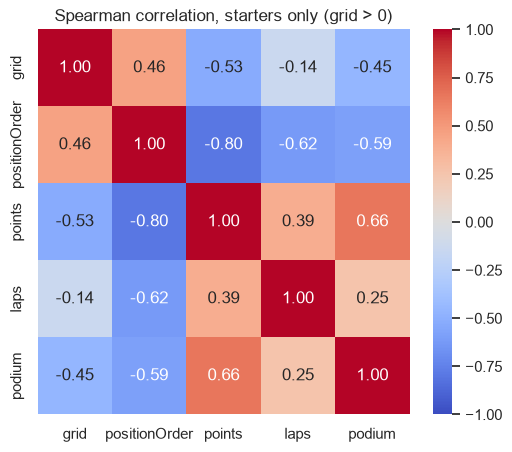

In [23]:
corr_cols = ['grid', 'positionOrder', 'points', 'laps', 'podium']
corr = res.loc[res['grid'] > 0, corr_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Spearman correlation, starters only (grid > 0)')
save_fig(fig, 's1_results_correlation')
plt.show()

`podium` correlates almost perfectly with `points` and `positionOrder` — they are the outcome itself, which is exactly
why they are **leakage** and excluded from features. Among these columns, only `grid` is known before the start; its
rank correlation with the finishing order is moderate (ρ ≈ 0.46) and far from perfect, leaving room for form,
standings and qualifying features to add signal.

## 1.9 Audit summary → what Step 2 onwards must handle

| # | Finding (evidence) | Handling |
|---|---|---|
| 1 | `\N` sentinels in 8 tables + **empty strings** in `qualifying.q2/q3` (§1.4) | Step 2: both placeholders → NaN explicitly |
| 2 | Dates and lap/qualifying/pit times stored as text with several formats (§1.3) | Step 2: `to_datetime`; one time parser → seconds |
| 3 | 2 rows with numeric `positionText` but NaN `position` (§1.4) | documented; no effect on target |
| 4 | All PKs valid; **`results (raceId, driverId)` has 85 duplicate pairs / 176 rows**; most laps decides 82 pairs, same labels as best-position rule (§1.5, §1.7) | Step 2: started-car → most laps → lowest resultId |
| 5 | All 23 FKs reconcile; `driver_standings` also lists drivers who did not enter that round; 10 qualifying rows disagree with `results` on constructor (§1.6) | Step 4: standings from the previous round; constructor from `results` |
| 5b | Shared cars: 18 races (1950–60) have > 3 podium rows because co-drivers share one `positionOrder` (§1.8.1) | Step 2: decide & document (default: keep both co-drivers) |
| 6 | Qualifying coverage drift: 0 % < 1994, patchy 1996–2002, ≈ 100 % from 2003 (§1.8.2) | Steps 4–5: fallback / missing indicator / training window |
| 7 | `grid = 0`: 1,638 rows, 0 podiums, mostly non-starters (§1.8.3) | Step 2: drop non-starters, keep pit-lane starters (flag) |
| 8 | Grid ≠ qualifying position for a substantial share of starters (§1.8.4) | Q1 + both as features (Step 4) |
| 9 | 139 status values; reliability and field size change strongly by era (§1.8.1, §1.8.5) | Step 2: status groups; Steps 4–6: era features, PR-AUC |
| 10 | Indianapolis 500 (11 races) distorts 1950s data (§1.8.6) | Step 2: exclude |
| 11 | Nationality adjectives vs country names, `"Argentinian "`, "USA"/"United States" (§1.8.7) | Step 3: explicit mapping |
| 12 | Podium base rate ≈ 3 / field size, drifts by era (§1.8.1) | Step 6: PR-AUC primary metric, threshold tuned on validation |

# 2. Cleaning
Every step below works on **copies** of the raw tables (`raw_str` / `raw` stay untouched) and is justified by an
audit finding from Section 1. Row-removing steps are applied in a fixed order and logged, so the effect of each one on
row count and podium rate is visible at the end (§2.13).

| Step | What | Evidence (Section 1) |
|---|---|---|
| 2.1 | `\N` and empty strings → NaN, whitespace stripped, numeric typing | §1.4, §1.8.7 |
| 2.2 | Semantic typing: dates → `datetime`, lap/qualifying/pit/race times → seconds | §1.3 |
| 2.3 | Shared drives: one row per `(raceId, driverId)` + `n_cars_driven` / `shared_car` flags | §1.7, §1.8.1 |
| 2.4 | Exclude the Indianapolis 500 | §1.8.6 |
| 2.5 | Status taxonomy: 139 values → finished / mechanical / accident_driver / other | §1.8.5 |
| 2.6 | Entry type; drop entries that never had a grid slot | §1.8.3 |
| 2.7 | Race-level integrity checks | new |
| 2.8 | Qualifying times: error removal, best lap, gap to pole, 107 % flag | §1.3, §1.8.4 |
| 2.9 | Grid source: qualifying vs sprint (2021–22) | §1.8.4, F1 primer |
| 2.10 | Team lineage across constructor renames | §1.6 |
| 2.11 | Nationality → country mapping | §1.8.7 |
| 2.12 | Assemble the cleaned driver–race table | — |
| 2.13 | EDA **after** cleaning and before/after comparison | — |

In [24]:
clean_log = []

def log_step(step, df, note=''):
    """Record rows / races / podium rate after a row-changing cleaning step."""
    clean_log.append({'step': step, 'rows': len(df), 'races': df['raceId'].nunique(),
                      'podium_rows': int((df['positionOrder'] <= 3).sum()),
                      'podium_rate': round((df['positionOrder'] <= 3).mean(), 4), 'note': note})

## 2.1 Placeholders → NaN, whitespace, numeric typing
Instead of relying on pandas' implicit NA list, cleaning starts from the **string copy** and states the rule
explicitly: strip surrounding whitespace, then treat both `\N` and the empty string as missing (§1.4 found both).
A column is converted to a number only if **every** non-missing value parses as one — so codes such as
`positionText` ("R", "D") and clock strings ("1:26.572") are never silently coerced to NaN.

In [25]:
def clean_placeholders(df):
    out = df.apply(lambda s: s.str.strip())
    return out.mask(out.isin([SENTINEL, '']))

def infer_numeric(df):
    out = df.copy()
    for c in out.columns:
        conv = pd.to_numeric(out[c], errors='coerce')
        if conv.notna().sum() == out[c].notna().sum():           # every non-missing value is numeric
            if conv.notna().all() and (conv % 1 == 0).all():
                conv = conv.astype('int64')
            out[c] = conv
    return out

clean = {t: infer_numeric(clean_placeholders(raw_str[t])) for t in TABLES}

rows = []
for t in TABLES:
    s = raw_str[t]
    rows.append({'table': t,
                 'placeholders_to_NaN': int(s.isin([SENTINEL, '']).sum().sum()),
                 'NaN_after_cleaning': int(clean[t].isna().sum().sum()),
                 'values_whitespace_stripped': int((s != s.apply(lambda c: c.str.strip())).sum().sum()),
                 'sentinel_strings_left': int((clean[t] == SENTINEL).sum().sum()),
                 'numeric_columns': int(sum(pd.api.types.is_numeric_dtype(clean[t][c]) for c in clean[t]))})
placeholder_report = pd.DataFrame(rows).set_index('table')
assert (placeholder_report['placeholders_to_NaN'] == placeholder_report['NaN_after_cleaning']).all()
assert placeholder_report['sentinel_strings_left'].sum() == 0
placeholder_report

,placeholders_to_NaN,NaN_after_cleaning,values_whitespace_stripped,sentinel_strings_left,numeric_columns
table,,,,,
circuits,0,0,0,0,4
constructors,0,0,0,0,1
drivers,1559,1559,1,0,2
seasons,0,0,0,0,1
status,0,0,0,0,1
races,11349,11349,0,0,4
results,122887,122887,0,0,15
qualifying,11668,11668,0,0,6
sprint_results,73,73,0,0,13


Every placeholder became NaN, no other value did, and no `\N` string is left anywhere. The single whitespace fix is
`"Argentinian "` → `"Argentinian"` in `drivers.nationality`.

## 2.2 Semantic typing — dates and durations
* **Dates** (`races.date`, session dates, `drivers.dob`) → `datetime64`; session clock times → `timedelta`, and the
  race start becomes one UTC timestamp where the start time is known.
* **Durations** → float **seconds** with one parser for every format found in §1.3 (`ss.sss`, `m:ss.sss`,
  `mm:ss.sss`, `h:mm:ss.sss`, with or without a leading `+`).
* `results.time` mixes two quantities, so it is split: the winner's absolute race time (`race_time_s`) and everyone
  else's gap (`gap_to_winner_s`).

Every parsed duration that has a `milliseconds` twin in the same table is **verified** against it.

In [26]:
def to_seconds(s):
    """'26.898' -> 26.898, '1:26.572' -> 86.572, '1:34:50.616' -> 5690.616, '+5.478' -> 5.478; NaN stays NaN."""
    def one(x):
        if pd.isna(x):
            return np.nan
        total = 0.0
        for part in str(x).lstrip('+').split(':'):
            total = total * 60 + float(part)
        return total
    return s.map(one).astype(float)

R = clean['races']
for c in ['date'] + [c for c in R.columns if c.endswith('_date')]:
    R[c] = pd.to_datetime(R[c], format='%Y-%m-%d')
for c in ['time'] + [c for c in R.columns if c.endswith('_time')]:
    R[c] = pd.to_timedelta(R[c])
R['race_start_utc'] = R['date'] + R['time']
clean['drivers']['dob'] = pd.to_datetime(clean['drivers']['dob'], format='%Y-%m-%d')

Q = clean['qualifying']
for c in ['q1', 'q2', 'q3']:
    Q[f'{c}_s'] = to_seconds(Q[c])

for t in ['results', 'sprint_results']:
    df = clean[t]
    is_gap = df['time'].str.startswith('+', na=False)
    df['race_time_s'] = to_seconds(df['time'].where(~is_gap))
    df['gap_to_winner_s'] = to_seconds(df['time'].where(is_gap))
    df['fastestLapTime_s'] = to_seconds(df['fastestLapTime'])

clean['lap_times']['time_s'] = to_seconds(clean['lap_times']['time'])
clean['pit_stops']['duration_s'] = to_seconds(clean['pit_stops']['duration'])
clean['pit_stops']['time'] = pd.to_timedelta(clean['pit_stops']['time'])

def verify(t, col, text_mask, implied_total_s=None):
    """Parsed count for the text values of `col`; optionally compare an implied total time with `milliseconds`."""
    df = clean[t]
    out = {'column': f'{t}.{col}', 'text_values': int(text_mask.sum()),
           'parsed': int(df.loc[text_mask, col].notna().sum())}
    if implied_total_s is not None:
        diff = (implied_total_s - df['milliseconds'] / 1000).abs()
        out['rows_checked_vs_ms'] = int(diff.notna().sum())
        out['rows_off_by_>0.011s'] = int((diff > 0.011).sum())
        out['max_abs_diff_s'] = round(diff.max(), 3)
    return out

checks = []
for t in ['results', 'sprint_results']:
    df = clean[t]
    is_gap = df['time'].str.startswith('+', na=False)
    winner_s = df.loc[df['positionOrder'] == 1].groupby('raceId')['race_time_s'].first()
    checks += [verify(t, 'race_time_s', df['time'].notna() & ~is_gap, df['race_time_s']),
               verify(t, 'gap_to_winner_s', is_gap, df['raceId'].map(winner_s) + df['gap_to_winner_s']),
               verify(t, 'fastestLapTime_s', df['fastestLapTime'].notna())]
checks += [verify('qualifying', f'{c}_s', clean['qualifying'][c].notna()) for c in ['q1', 'q2', 'q3']]
checks += [verify('lap_times', 'time_s', clean['lap_times']['time'].notna(), clean['lap_times']['time_s']),
           verify('pit_stops', 'duration_s', clean['pit_stops']['duration'].notna(), clean['pit_stops']['duration_s'])]
typing_report = pd.DataFrame(checks)
display(typing_report)

rc_ = clean['results']
win_ = rc_.loc[rc_['positionOrder'] == 1].groupby('raceId')['race_time_s'].first()
off = rc_[((rc_['raceId'].map(win_) + rc_['gap_to_winner_s'] - rc_['milliseconds'] / 1000).abs() > 0.011)
          | ((rc_['race_time_s'] - rc_['milliseconds'] / 1000).abs() > 0.011)]
off.merge(clean['races'][['raceId', 'year', 'name']], on='raceId')[
    ['year', 'name', 'driverId', 'positionOrder', 'time', 'milliseconds', 'race_time_s', 'gap_to_winner_s']]

,column,text_values,parsed,rows_checked_vs_ms,rows_off_by_>0.011s,max_abs_diff_s
0,results.race_time_s,1128,1128,1128.0,1.0,0.526
1,results.gap_to_winner_s,6552,6552,6534.0,10.0,101.069
2,results.fastestLapTime_s,8252,8252,NaN,NaN,NaN
3,sprint_results.race_time_s,18,18,18.0,0.0,0.000
4,sprint_results.gap_to_winner_s,322,322,322.0,0.0,0.000
5,sprint_results.fastestLapTime_s,351,351,NaN,NaN,NaN
6,qualifying.q1_s,10338,10338,NaN,NaN,NaN
7,qualifying.q2_s,5847,5847,NaN,NaN,NaN
8,qualifying.q3_s,3629,3629,NaN,NaN,NaN
9,lap_times.time_s,589081,589081,589081.0,0.0,0.000


,year,name,driverId,positionOrder,time,milliseconds,race_time_s,gap_to_winner_s
0,1994,German Grand Prix,103,3,+1:05.0421,5022621.0,NaN,65.0421
1,1980,Austrian Grand Prix,173,6,+1:14.97,5238540.0,NaN,74.9700
2,2020,Abu Dhabi Grand Prix,839,9,+1:41.069,5799996.0,NaN,101.0690
3,2020,Abu Dhabi Grand Prix,840,10,+1:42.738,5790314.0,NaN,102.7380
4,2021,Portuguese Grand Prix,4,8,+1:04.808,5673229.0,NaN,64.8080
5,2023,Dutch Grand Prix,815,4,+10.068,8655093.0,NaN,10.0680
6,2023,Dutch Grand Prix,852,15,+29.893,8682344.0,NaN,29.8930
7,2023,Dutch Grand Prix,825,16,+31.410,8679515.0,NaN,31.4100
8,2024,Saudi Arabian Grand Prix,815,2,+13.6431,4862704.0,NaN,13.6431
9,2024,Saudi Arabian Grand Prix,825,12,+1:45.7373,4955646.0,NaN,105.7373


* **Every** duration string was parsed (`parsed = text_values` in every row of the report).
* Lap times, pit-stop durations and sprint times reproduce their `milliseconds` twin exactly. In `results`,
  *winner time + gap* reproduces the total race time to within the rounding of the text (0.001–0.01 s) for all but
  **11 rows** (listed above), which are inconsistencies inside the source rather than parsing errors:
  * 2024 Belgium: the car that crossed the line first was disqualified after the race; it keeps an absolute time
    but is classified 20th, and its text time and `milliseconds` disagree by 0.5 s;
  * 10 finishers whose printed gap and `milliseconds` disagree (by up to 101 s) — most likely time penalties
    applied to one column but not the other.

  These are **post-race columns** (never features, and the target uses `positionOrder`), so they are documented
  and left as recorded.
* `fastestLapTime` and `q1–q3` have no millisecond twin; their parse is checked by the count only.
* Dates parsed with an explicit `%Y-%m-%d` format, so a malformed date would have raised an error rather than
  becoming NaT silently.

In [27]:
pd.concat({t: clean[t].dtypes.astype(str).value_counts() for t in ['races', 'drivers', 'results', 'qualifying']},
          axis=1).fillna(0).astype(int)

,races,drivers,results,qualifying
datetime64[ns],7,1,0,0
timedelta64[ns],6,0,0,0
int64,4,1,8,6
object,2,6,3,3
float64,0,1,10,3


## 2.3 Shared drives — one row per `(raceId, driverId)`
Rule from §1.7, applied now: keep the car the driver **started** (`grid > 0`), then the one with the **most laps**
(his main drive), then the **lowest `resultId`**. §1.7 showed the rule never drops a podium row and picks the same
row as "best finishing position" in all 85 pairs, so no target label depends on the choice.

Two traceability flags are added instead of resolving shared drives silently (item 9):
* `n_cars_driven` — how many result rows the driver had in that race before deduplication;
* `shared_car` — the row's car result is shared with another driver (same `positionOrder` in the same race, §1.8.1).

In [28]:
races_cols = clean['races'][['raceId', 'year', 'round', 'date', 'name', 'circuitId']].rename(columns={'name': 'race_name'})
res0 = clean['results'].merge(races_cols, on='raceId', how='left', validate='many_to_one')
log_step('0. raw results', res0, 'all result rows')

res0['n_cars_driven'] = res0.groupby(['raceId', 'driverId'])['resultId'].transform('size')
res1 = (res0.assign(_started=(res0['grid'] > 0).astype(int))
            .sort_values(['raceId', 'driverId', '_started', 'laps', 'resultId'],
                         ascending=[True, True, False, False, True])
            .drop_duplicates(['raceId', 'driverId'], keep='first')
            .drop(columns='_started')
            .sort_values('resultId')
            .reset_index(drop=True))
assert not res1.duplicated(['raceId', 'driverId']).any()
res1['shared_car'] = res1.duplicated(['raceId', 'positionOrder'], keep=False)
log_step('1. deduplicate (raceId, driverId)', res1, 'started car > most laps > lowest resultId')

print(f'rows: {len(res0):,} -> {len(res1):,} (removed {len(res0) - len(res1)})')
print('n_cars_driven:', res1['n_cars_driven'].value_counts().sort_index().to_dict())
sc = res1[res1['shared_car']]
print(f'shared_car rows: {len(sc)} in {sc["raceId"].nunique()} races ({sc["year"].min()}–{sc["year"].max()}); '
      f'of which podium rows: {int((sc["positionOrder"] <= 3).sum())}')

rows: 26,759 -> 26,668 (removed 91)
n_cars_driven: {1: 26583, 2: 79, 3: 6}
shared_car rows: 184 in 45 races (1950–1961); of which podium rows: 39


The log in §2.13 shows that deduplication removes **2 podium rows** — both from the 1955 Argentine GP, where two
drivers each finished on the podium in *two* different shared cars. Each driver keeps one podium row, so no driver
loses a podium label.

**Shared cars are kept as they are.** When two drivers shared a podium car, both are credited with that car's
`positionOrder` (and half the points). Both genuinely drove the car, and the target is "did this driver finish on the
podium", so both rows stay `podium = 1` — the `shared_car` flag lets later steps exclude or down-weight these rows if
needed. All of them are in the 1950s–60s, i.e. outside any realistic training window (Step 5).

## 2.4 Exclude the Indianapolis 500 (1950–1960)
§1.8.6: 11 races, ≈ 18 % of 1950–60 rows, entered almost only by US oval specialists (103 of 107 drivers never
raced anywhere else in the championship). The race behaves like a different competition and would distort home-race
analysis and driver experience, so it is removed.

In [29]:
indy_ids = set(clean['races'].loc[clean['races']['name'].str.contains('Indianapolis 500'), 'raceId'])
res2 = res1[~res1['raceId'].isin(indy_ids)].reset_index(drop=True)
log_step('2. drop Indianapolis 500', res2, f'{len(indy_ids)} races')
print(f'rows: {len(res1):,} -> {len(res2):,} (removed {len(res1) - len(res2)}), races: {len(indy_ids)} removed')

rows: 26,668 -> 26,287 (removed 381), races: 11 removed


## 2.5 Status taxonomy — 139 values → 4 groups
Groups follow the brief's definition (Q3): a **mechanical** retirement is a race that ended because *a component of
the car failed*; crashes, driver-related causes and regulation decisions are not mechanical.

Mapping principle, applied the same way to every value:
* **finished** — `Finished` and every `+n Lap(s)` (reached the flag, possibly lapped);
* **mechanical** — the status names a car component or system (engine, gearbox, hydraulics, brakes, wheel,
  seat, …). The status records *what* failed, not *why*, so a named component counts as mechanical;
* **accident_driver** — crash or contact (`Accident`, `Collision`, `Spun off`, `Collision damage`, `Damage`) and
  driver-related causes (`Physical`, `Injury`, `Illness`, `Driver unwell`, `Stalled`, …);
* **other** — regulation / administrative outcomes (`Disqualified`, `Excluded`, `Underweight`), non-starts
  (`Did not qualify`, `Withdrew`, …), external causes (`Debris`, `Puncture`), team / pit-crew errors
  (`Out of fuel`, `Refuelling`, `Fuel rig`) and the uninformative `Retired` / `Not classified`.

An `assert` guarantees that **every** status value is mapped exactly once.

In [30]:
STATUS_GROUPS = {
    'mechanical': [
        'Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator', 'Suspension',
        'Brakes', 'Differential', 'Overheating', 'Mechanical', 'Tyre', 'Driver Seat', 'Driveshaft',
        'Fuel pressure', 'Front wing', 'Water pressure', 'Wheel', 'Throttle', 'Steering', 'Technical',
        'Electronics', 'Broken wing', 'Heat shield fire', 'Exhaust', 'Oil leak', 'Wheel rim', 'Water leak',
        'Fuel pump', 'Track rod', 'Oil pressure', 'Engine fire', 'Engine misfire', 'Wheel nut', 'Pneumatics',
        'Handling', 'Rear wing', 'Fire', 'Wheel bearing', 'Fuel system', 'Oil line', 'Launch control', 'Fuel',
        'Power loss', 'Vibrations', 'Drivetrain', 'Ignition', 'Chassis', 'Battery', 'Halfshaft', 'Crankshaft',
        'Alternator', 'Safety belt', 'Oil pump', 'Fuel leak', 'Injection', 'Distributor', 'Turbo', 'CV joint',
        'Water pump', 'Spark plugs', 'Fuel pipe', 'Oil pipe', 'Axle', 'Water pipe', 'Magneto', 'Supercharger',
        'Power Unit', 'ERS', 'Brake duct', 'Seat', 'Undertray', 'Cooling system'],
    'accident_driver': [
        'Accident', 'Collision', 'Spun off', 'Collision damage', 'Damage', 'Fatal accident', 'Physical',
        'Injured', 'Injury', 'Driver unwell', 'Eye injury', 'Illness', 'Stalled'],
    'other': [
        'Disqualified', 'Excluded', 'Underweight', 'Withdrew', 'Did not qualify', 'Did not prequalify',
        '107% Rule', 'Not classified', 'Retired', 'Not restarted', 'Safety', 'Safety concerns', 'Debris',
        'Puncture', 'Tyre puncture', 'Out of fuel', 'Refuelling', 'Fuel rig'],
}
listed = [s for v in STATUS_GROUPS.values() for s in v]
assert len(listed) == len(set(listed)), 'a status is listed in two groups'

def status_group(s):
    if s == 'Finished' or re.fullmatch(r'\+\d+ Laps?', s):
        return 'finished'
    return next((g for g, names in STATUS_GROUPS.items() if s in names), None)

status = clean['status'].copy()
status['status_group'] = status['status'].map(status_group)
unmapped = status.loc[status['status_group'].isna(), 'status'].tolist()
assert not unmapped, f'unmapped statuses: {unmapped}'
assert not set(listed) - set(status['status']), 'mapping lists a status that does not exist'

rows_per_status = res2['statusId'].value_counts()
status['rows'] = status['statusId'].map(rows_per_status).fillna(0).astype(int)
with pd.option_context('display.max_colwidth', None):
    display(status.groupby('status_group').agg(
        status_values=('status', 'size'), rows=('rows', 'sum'),
        values=('status', lambda s: ', '.join(v for v in s if not re.fullmatch(r'\+\d+ Laps?', v))
                                     + (', +n Lap(s)' if s.str.fullmatch(r'\+\d+ Laps?').any() else '')))
        .sort_values('rows', ascending=False))
print(f'{len(status)} status values mapped to {status["status_group"].nunique()} groups, 0 unmapped')

,status_values,rows,values
status_group,,,
finished,34,14956,"Finished, +n Lap(s)"
mechanical,74,6371,"Engine, Gearbox, Transmission, Clutch, Hydraulics, Electrical, Radiator, Suspension, Brakes, Differential, Overheating, Mechanical, Tyre, Driver Seat, Driveshaft, Fuel pressure, Front wing, Water pressure, Wheel, Throttle, Steering, Technical, Electronics, Broken wing, Heat shield fire, Exhaust, Oil leak, Wheel rim, Water leak, Fuel pump, Track rod, Oil pressure, Engine fire, Engine misfire, Wheel nut, Pneumatics, Handling, Rear wing, Fire, Wheel bearing, Fuel system, Oil line, Launch control, Fuel, Power loss, Vibrations, Drivetrain, Ignition, Chassis, Battery, Halfshaft, Crankshaft, Alternator, Safety belt, Oil pump, Fuel leak, Injection, Distributor, Turbo, CV joint, Water pump, Spark plugs, Fuel pipe, Oil pipe, Axle, Water pipe, Magneto, Supercharger, Power Unit, ERS, Brake duct, Seat, Undertray, Cooling system"
accident_driver,13,2773,"Accident, Collision, Spun off, Physical, Injured, Injury, Stalled, Driver unwell, Fatal accident, Eye injury, Collision damage, Damage, Illness"
other,18,2187,"Disqualified, Puncture, Retired, Refuelling, Withdrew, Tyre puncture, Out of fuel, Not classified, Fuel rig, 107% Rule, Safety, Did not qualify, Safety concerns, Not restarted, Underweight, Excluded, Did not prequalify, Debris"


139 status values mapped to 4 groups, 0 unmapped


Borderline cases, decided once and applied consistently:
* `Tyre`, `Wheel`, `Wheel nut`, `Front wing`, `Broken wing` → **mechanical** (named component; a front wing *can*
  break from contact, but contact-caused retirements are recorded as `Collision` / `Collision damage`).
* `Puncture`, `Tyre puncture`, `Debris` → **other** (external cause, neither component failure nor driver error).
* `Out of fuel`, `Refuelling`, `Fuel rig` → **other** (team / pit-equipment error, not a failed car component),
  while `Fuel system`, `Fuel pump`, `Fuel leak`, `Fuel pressure` → mechanical.
* `Stalled` → **accident_driver** (most stalls are at the start, a driver action).

## 2.6 Entry type and non-starters
The prediction is made when the grid is fixed. An entry that **never obtained a grid slot** cannot finish on the
podium and is known before the race, so it is not a meaningful prediction — keeping it would add trivially-easy
negatives (§1.8.3: 1,638 `grid = 0` rows, 0 podiums). Entry type is derived **only from information available at the
cutoff** (qualifying outcome and grid), never from laps or finishing data:

| entry_type | rule | kept? |
|---|---|---|
| `did_not_prequalify` | status *Did not prequalify* | dropped |
| `did_not_qualify` | status *Did not qualify* or *107% Rule* | dropped |
| `withdrew_before_grid` | status *Withdrew* and `grid = 0` | dropped |
| `excluded_before_grid` | status *Excluded* and `grid = 0` | dropped |
| `pit_lane_start` | any other `grid = 0` row (took part without a grid slot) | **kept**, flagged |
| `grid_start` | `grid > 0` | **kept** |

A *Withdrew* with `grid > 0` (e.g. withdrawal after the grid was formed) is **kept**: at the cutoff that car was on the
grid, so dropping it would use post-cutoff information.

In [31]:
res2 = res2.merge(status[['statusId', 'status', 'status_group']], on='statusId', how='left', validate='many_to_one')
st_, grid0 = res2['status'], res2['grid'] == 0
res2['entry_type'] = np.select(
    [st_.eq('Did not prequalify'), st_.isin(['Did not qualify', '107% Rule']),
     grid0 & st_.eq('Withdrew'), grid0 & st_.eq('Excluded'), grid0],
    ['did_not_prequalify', 'did_not_qualify', 'withdrew_before_grid', 'excluded_before_grid', 'pit_lane_start'],
    default='grid_start')
NON_STARTERS = ['did_not_prequalify', 'did_not_qualify', 'withdrew_before_grid', 'excluded_before_grid']

entry_summary = (res2.groupby('entry_type')
                 .agg(rows=('resultId', 'size'), podiums=('positionOrder', lambda s: int((s <= 3).sum())),
                      grid_zero=('grid', lambda s: int((s == 0).sum())), first_season=('year', 'min'),
                      last_season=('year', 'max'))
                 .assign(kept=lambda d: ~d.index.isin(NON_STARTERS))
                 .sort_values('rows', ascending=False))
display(entry_summary)

res3 = res2[~res2['entry_type'].isin(NON_STARTERS)].reset_index(drop=True)
res3['pit_lane_start'] = res3['entry_type'].eq('pit_lane_start')
assert int((res2.loc[res2['entry_type'].isin(NON_STARTERS), 'positionOrder'] <= 3).sum()) == 0
log_step('3. drop non-starters', res3, 'no grid slot at the cutoff')
print(f'rows: {len(res2):,} -> {len(res3):,} (removed {len(res2) - len(res3):,}, 0 podiums among them)')
pls = res3[res3['pit_lane_start']]
print('pit_lane_start rows by decade:', pls.groupby(pls['year'] // 10 * 10).size().to_dict())

,rows,podiums,grid_zero,first_season,last_season,kept
entry_type,,,,,,
grid_start,24633,3359,0,1950,2024,True
did_not_qualify,1033,0,1014,1952,2012,False
did_not_prequalify,330,0,330,1965,1992,False
withdrew_before_grid,163,0,163,1952,2023,False
pit_lane_start,122,0,122,1954,2024,True
excluded_before_grid,6,0,6,1987,1992,False


rows: 26,287 -> 24,755 (removed 1,532, 0 podiums among them)
pit_lane_start rows by decade: {1950: 6, 1960: 6, 1970: 7, 1980: 12, 1990: 11, 2000: 3, 2010: 22, 2020: 55}


The dropped entries contain **no podium**, so the positive class is untouched while ≈ 1,500 trivial negatives
disappear. The remaining `grid = 0` rows (`pit_lane_start`) took part in the race; in the modern era these are true
pit-lane starts, in older seasons they may also be entries whose grid slot was simply not recorded. They are kept and
flagged, and Step 4 decides how to encode their starting position.

## 2.7 Race-level integrity checks
Checks that only make sense once the grain is fixed, run on the cleaned rows:

In [32]:
g = res3[res3['grid'] > 0]
rep_grid = g[g.duplicated(['raceId', 'grid'], keep=False)]
field = res3.groupby('raceId')['resultId'].transform('size')
winner_laps = res3.loc[res3['positionOrder'] == 1].groupby('raceId')['laps'].max()
too_many_laps = res3[res3['laps'] > res3['raceId'].map(winner_laps)]
podium_per_race = res3.groupby('raceId')['positionOrder'].apply(lambda s: int((s <= 3).sum()))
has_top3 = res3.groupby('raceId')['positionOrder'].apply(lambda s: {1, 2, 3} <= set(s))
shared_races = set(res3.loc[res3['shared_car'], 'raceId'])

integrity = pd.DataFrame([
    {'check': 'every race still has positionOrder 1, 2 and 3', 'violations': int((~has_top3).sum())},
    {'check': 'races with != 3 podium rows', 'violations': int((podium_per_race != 3).sum()),
     'explained_by': f'shared cars: {int(podium_per_race[podium_per_race != 3].index.isin(shared_races).sum())}'},
    {'check': 'races with a repeated grid value (grid > 0)', 'violations': int(rep_grid['raceId'].nunique()),
     'explained_by': f'seasons {rep_grid["year"].min()}–{rep_grid["year"].max()}'},
    {'check': 'rows with grid > number of entrants', 'violations': int((res3['grid'] > field).sum())},
    {'check': 'rows with more laps than the winner', 'violations': len(too_many_laps)},
])
display(integrity)

rg = rep_grid.drop_duplicates('raceId')
print('repeated-grid races by decade:', rg.groupby(rg['year'] // 10 * 10).size().to_dict())
print('repeated-grid races that contain a shared car:', len(set(rep_grid['raceId']) & shared_races))
print('rows with grid > entrants by decade:', res3[res3['grid'] > field].groupby('year').size().pipe(lambda s: s.groupby(s.index // 10 * 10).sum()).to_dict())
print('\nrepeated grid values since 2000:')
display(rep_grid[rep_grid['year'] >= 2000][['year', 'race_name', 'driverId', 'grid', 'positionOrder', 'status']])
print('row with more laps than the winner:')
too_many_laps[['year', 'race_name', 'driverId', 'grid', 'positionOrder', 'laps', 'status']]

,check,violations,explained_by
0,"every race still has positionOrder 1, 2 and 3",0,NaN
1,races with != 3 podium rows,15,shared cars: 15
2,races with a repeated grid value (grid > 0),100,seasons 1950–2024
3,rows with grid > number of entrants,53,NaN
4,rows with more laps than the winner,1,NaN


repeated-grid races by decade: {1950: 39, 1960: 16, 1970: 22, 1980: 12, 1990: 7, 2000: 1, 2010: 2, 2020: 1}
repeated-grid races that contain a shared car: 39
rows with grid > entrants by decade: {1950: 10, 1960: 29, 1970: 7, 1980: 6, 2000: 1}

repeated grid values since 2000:


,year,race_name,driverId,grid,positionOrder,status
2102,2003,German Grand Prix,35,13,9,+2 Laps
2106,2003,German Grand Prix,21,13,13,Engine
20763,2015,Italian Grand Prix,832,17,11,+1 Lap
20765,2015,Italian Grand Prix,831,17,13,+1 Lap
20825,2015,Russian Grand Prix,829,17,14,+2 Laps
20831,2015,Russian Grand Prix,828,17,20,Collision
24675,2024,São Paulo Grand Prix,830,17,1,Finished
24694,2024,São Paulo Grand Prix,807,17,20,Disqualified


row with more laps than the winner:


,year,race_name,driverId,grid,positionOrder,laps,status
16658,1960,Dutch Grand Prix,481,14,7,78,+5 Laps


* **Target integrity holds:** after all removals every race still has its positions 1, 2 and 3, and every race with
  more than 3 podium rows is explained by shared cars (§2.3).
* **Repeated grid values** (two cars on the same slot) are overwhelmingly an early-era artefact: most of the 100
  races are before 1980 and 39 of them are shared-car races, where the co-drivers inherit the car's grid slot.
  Since 2000 only **4 races** are affected (one pair of cars each, listed above) — source recording errors. The true
  order cannot be recovered from the data, so values are kept as recorded and documented; with 4 races in 25 seasons
  the effect on modern modeling is negligible.
* **Grid larger than the number of entrants** occurs almost only in the 1950s–60s, when grid numbering also counted
  slots of entries that did not start (removed in §2.6 or never recorded in `results`). Grid is therefore an
  ordinal starting slot, not a rank among the remaining rows.
* The single row with more laps than the winner is an inconsistency inside the source data (post-race column only,
  no effect on the target or on pre-race features); documented and left as is.

## 2.8 Qualifying times — error removal, best lap, gap to pole, 107 % flag
Each lap is compared with the **fastest lap of the same session** (`q1`, `q2`, `q3` separately). The historic
"107 % rule" excluded cars slower than 107 % of the fastest time, but §1.3 showed that many slower laps are genuine
(wet sessions, cars with problems, the 1994–95 two-session format), so a lap above 107 % is **flagged, not deleted**.
Only physically impossible values are treated as data errors — the plot shows where that boundary lies.

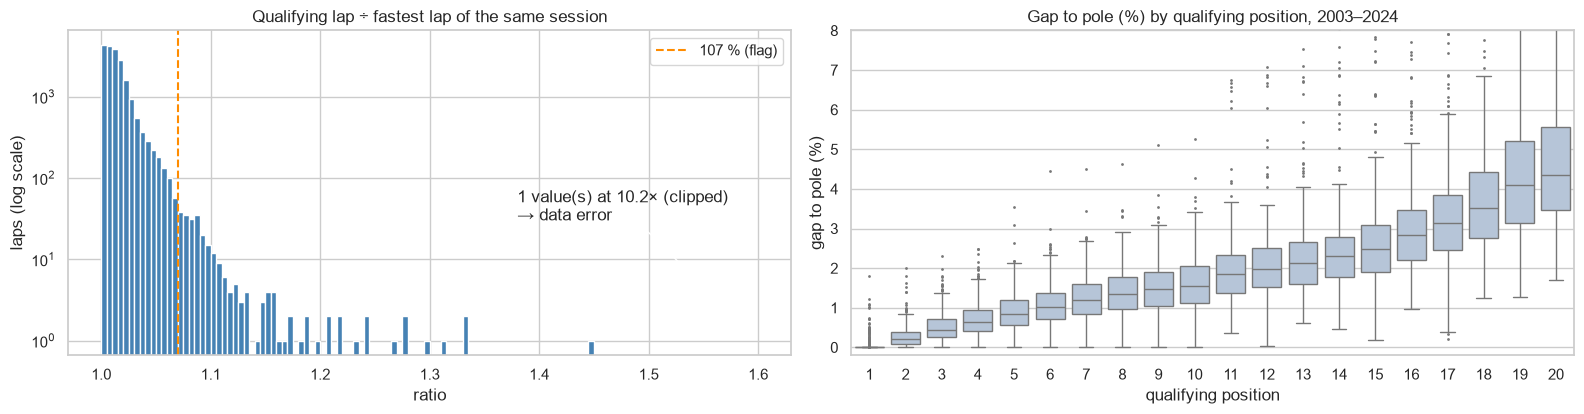

,year,raceId,driverId,position,q1,q1_ratio
2567,1995,255,87,24,16:42.640,10.22862


laps set to NaN (> 2.0x session best): 1
rows flagged outside_107 (Q1 > 107 % of fastest Q1): 205 of 10,494
rows with a best qualifying lap: 10,337 of 10,494


In [33]:
Q = clean['qualifying'].merge(clean['races'][['raceId', 'year']], on='raceId', how='left', validate='many_to_one')
for c in ['q1', 'q2', 'q3']:
    Q[f'{c}_ratio'] = Q[f'{c}_s'] / Q.groupby('raceId')[f'{c}_s'].transform('min')
ratios = pd.concat([Q[f'{c}_ratio'] for c in ['q1', 'q2', 'q3']]).dropna()

ERROR_RATIO = 2.0                     # a lap more than twice the session's best cannot be a timed flying lap
errors = Q[(Q[['q1_ratio', 'q2_ratio', 'q3_ratio']] > ERROR_RATIO).any(axis=1)]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
axes[0].hist(ratios.clip(upper=1.6), bins=np.arange(1.0, 1.605, 0.005), color='steelblue')
axes[0].set_yscale('log')
axes[0].axvline(1.07, color='darkorange', linestyle='--', label='107 % (flag)')
axes[0].annotate(f'{int((ratios > ERROR_RATIO).sum())} value(s) at {ratios.max():.1f}× (clipped)\n→ data error',
                 xy=(1.6, 1), xytext=(1.38, 30), arrowprops={'arrowstyle': '->'})
axes[0].set(title='Qualifying lap ÷ fastest lap of the same session', xlabel='ratio', ylabel='laps (log scale)')
axes[0].legend()

for c in ['q1', 'q2', 'q3']:
    Q.loc[Q[f'{c}_ratio'] > ERROR_RATIO, f'{c}_s'] = np.nan
    Q[f'{c}_ratio'] = Q[f'{c}_s'] / Q.groupby('raceId')[f'{c}_s'].transform('min')
Q['best_q_s'] = Q[['q1_s', 'q2_s', 'q3_s']].min(axis=1)
Q['pole_q_s'] = Q.groupby('raceId')['best_q_s'].transform('min')
Q['gap_to_pole_s'] = Q['best_q_s'] - Q['pole_q_s']
Q['gap_to_pole_pct'] = 100 * (Q['best_q_s'] / Q['pole_q_s'] - 1)
Q['outside_107'] = Q['q1_ratio'] > 1.07

modern = Q[(Q['year'] >= 2003) & Q['position'].between(1, 20)]
sns.boxplot(data=modern, x='position', y='gap_to_pole_pct', ax=axes[1], color='lightsteelblue', fliersize=1)
axes[1].set(title='Gap to pole (%) by qualifying position, 2003–2024', xlabel='qualifying position',
            ylabel='gap to pole (%)', ylim=(-0.2, 8))
plt.tight_layout()
save_fig(fig, 's2_qualifying_ratio_gap_to_pole')
plt.show()

display(errors[['year', 'raceId', 'driverId', 'position', 'q1', 'q1_ratio']])
print(f'laps set to NaN (> {ERROR_RATIO}x session best): {len(errors)}')
print(f'rows flagged outside_107 (Q1 > 107 % of fastest Q1): {int(Q["outside_107"].sum())} of {len(Q):,}')
print(f'rows with a best qualifying lap: {int(Q["best_q_s"].notna().sum()):,} of {len(Q):,}')

* The ratio distribution is continuous up to ≈ 1.45 and then empty until a single lap at **10.2×** — a 16:42.6
  "lap" in 1995 Japan, a recording error (the threshold of 2× sits in the empty gap, so the choice is not sensitive).
  Only that value is set to NaN.
* Laps above 107 % are kept and flagged (`outside_107`) — they concentrate in 1994–95 and in wet or disrupted
  sessions, i.e. they carry real information about a difficult session.
* `gap_to_pole_pct` grows smoothly with qualifying position, so it measures *how far* behind a driver was, which the
  integer position cannot (P2 can be 0.01 % or 1 % off pole). It is a candidate feature for Step 4. Caveat: in the
  knockout format a driver eliminated in Q1 is compared with a pole time set in Q3, on a faster track — the gap is
  slightly inflated for those drivers, which is acceptable because the ordering is preserved.

## 2.9 Grid source — qualifying vs sprint (2021–2022)
On 2021–2022 sprint weekends the **sprint result** set the Sunday grid; from 2023 Friday qualifying set the Sunday grid
and a separate shootout set the sprint grid (F1 primer). If that is true in our data, the Sunday grid should match
the sprint finishing order in 2021–22 and the qualifying order in 2023–24.

,sprint_weekends,grid_equals_sprint_finish,grid_equals_quali_position
year,,,
2021,3,0.46,0.12
2022,3,0.63,0.19
2023,6,0.14,0.69
2024,6,0.17,0.76


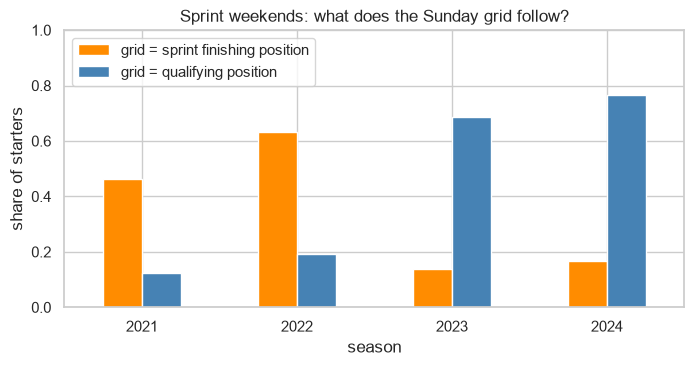

grid_source  qualifying  sprint
year                           
2021                 19       3
2022                 19       3
2023                 22       0
2024                 24       0


In [34]:
sprint_races = set(clean['sprint_results']['raceId'])
sw = (res3[res3['raceId'].isin(sprint_races) & (res3['grid'] > 0)]
      .merge(clean['sprint_results'][['raceId', 'driverId', 'positionOrder']].rename(columns={'positionOrder': 'sprint_pos'}),
             on=['raceId', 'driverId'], how='left', validate='one_to_one')
      .merge(Q[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'}),
             on=['raceId', 'driverId'], how='left', validate='one_to_one'))
evidence = (sw.assign(grid_eq_sprint=sw['grid'] == sw['sprint_pos'], grid_eq_quali=sw['grid'] == sw['quali_pos'])
              .groupby('year').agg(sprint_weekends=('raceId', 'nunique'),
                                   grid_equals_sprint_finish=('grid_eq_sprint', 'mean'),
                                   grid_equals_quali_position=('grid_eq_quali', 'mean')))
display(evidence.round(2))

fig, ax = plt.subplots(figsize=(8, 3.6))
evidence[['grid_equals_sprint_finish', 'grid_equals_quali_position']].plot(kind='bar', ax=ax, color=['darkorange', 'steelblue'])
ax.set(title='Sprint weekends: what does the Sunday grid follow?', xlabel='season', ylabel='share of starters', ylim=(0, 1))
ax.legend(['grid = sprint finishing position', 'grid = qualifying position'], loc='upper left')
plt.xticks(rotation=0)
save_fig(fig, 's2_grid_source_sprint')
plt.show()

res3['grid_source'] = np.where(res3['raceId'].isin(sprint_races) & res3['year'].between(2021, 2022), 'sprint', 'qualifying')
print(res3.loc[res3['year'] >= 2021].groupby(['year', 'grid_source'])['raceId'].nunique().unstack(fill_value=0))

The data confirms the format change: in 2021–22 the Sunday grid follows the sprint finish far more often than
qualifying, in 2023–24 it is the other way round (exact matches stay below 100 % because grid penalties shift
positions). Rows from the six 2021–22 sprint weekends get `grid_source = 'sprint'`: for them "qualifying position"
and "grid" describe two *different* sessions, which matters for Q1 and for how sprint information is treated in Step 4.

## 2.10 Team lineage across constructor renames
A constructor is a team; when a team is sold or renamed it receives a **new `constructorId`** (F1 primer; §1.6 found
Marussia → Manor Marussia inside the 2015 season). Constructor-form features keyed on `constructorId` would reset to
zero at every rename — Brawn's 2009 title would give Mercedes no history in 2010. `team_lineage` links names that
are the **same team operation (same factory and staff) under a new name**:

* Rules are written as `(constructorRef, first season, last season) → lineage`, because some refs are reused for
  unrelated teams decades apart (`renault` covers the 1977–85 works team *and* the Enstone team of 2002–11/2016–20;
  `mercedes`, `honda`, `alfa`, `aston_martin` likewise). Periods outside a rule keep their own ref as lineage.
* Early chassis–engine names (`Cooper-Climax`, `Lotus-BRM`, `Brabham-Repco` …, before 1985) are separate
  constructorIds for the same chassis builder; they are mapped to the chassis maker.
* Tyrrell → BAR (1999) is *not* linked: BAR bought the entry, but built a new team in a new factory.

In [35]:
LINEAGE_RULES = [   # (constructorRef, first season, last season, lineage)
    ('toleman', 1981, 1985, 'enstone'), ('benetton', 1986, 2001, 'enstone'), ('renault', 2002, 2011, 'enstone'),
    ('lotus_f1', 2012, 2015, 'enstone'), ('renault', 2016, 2020, 'enstone'), ('alpine', 2021, 2024, 'enstone'),
    ('jordan', 1991, 2005, 'silverstone'), ('mf1', 2006, 2006, 'silverstone'), ('spyker_mf1', 2006, 2006, 'silverstone'),
    ('spyker', 2007, 2007, 'silverstone'), ('force_india', 2008, 2018, 'silverstone'),
    ('racing_point', 2019, 2020, 'silverstone'), ('aston_martin', 2021, 2024, 'silverstone'),
    ('stewart', 1997, 1999, 'milton_keynes'), ('jaguar', 2000, 2004, 'milton_keynes'), ('red_bull', 2005, 2024, 'milton_keynes'),
    ('minardi', 1985, 2005, 'faenza'), ('toro_rosso', 2006, 2019, 'faenza'), ('alphatauri', 2020, 2023, 'faenza'),
    ('rb', 2024, 2024, 'faenza'),
    ('sauber', 1993, 2005, 'hinwil'), ('bmw_sauber', 2006, 2009, 'hinwil'), ('sauber', 2010, 2024, 'hinwil'),
    ('alfa', 2019, 2023, 'hinwil'),
    ('bar', 1999, 2005, 'brackley'), ('honda', 2006, 2008, 'brackley'), ('brawn', 2009, 2009, 'brackley'),
    ('mercedes', 2010, 2024, 'brackley'),
    ('virgin', 2010, 2011, 'banbury'), ('marussia', 2012, 2015, 'banbury'), ('manor', 2015, 2016, 'banbury'),
    ('lotus_racing', 2010, 2011, 'hingham'), ('caterham', 2012, 2014, 'hingham'),
    ('arrows', 1978, 2002, 'arrows'), ('footwork', 1991, 1996, 'arrows'),
    ('ligier', 1976, 1996, 'ligier_prost'), ('prost', 1997, 2001, 'ligier_prost'),
    ('march', 1970, 1992, 'march'), ('leyton', 1990, 1991, 'march'),
]

cons = clean['constructors'][['constructorId', 'constructorRef', 'name']]
lin = res3[['resultId', 'constructorId', 'year']].merge(cons, on='constructorId', how='left', validate='many_to_one')
lin['team_lineage'] = lin['constructorRef']

name_to_ref = dict(zip(cons['name'], cons['constructorRef']))
name_to_ref['Lotus'] = 'team_lotus'           # 'Lotus' is also the 2010 team's display name
combo = lin['name'].str.contains('-') & (lin['year'] < 1985)
chassis = lin.loc[combo, 'name'].str.split('-').str[0].str.strip()
lin.loc[combo, 'team_lineage'] = chassis.map(lambda c: name_to_ref.get(c, re.sub(r'\W+', '_', c.lower())))

for ref, y0, y1, lineage in LINEAGE_RULES:
    m = lin['constructorRef'].eq(ref) & lin['year'].between(y0, y1)
    assert m.any(), f'rule matches no rows: {ref} {y0}-{y1}'
    lin.loc[m, 'team_lineage'] = lineage
res3 = res3.merge(lin[['resultId', 'team_lineage']], on='resultId', how='left', validate='one_to_one')
assert res3['team_lineage'].notna().all()

print(f'constructorIds: {res3["constructorId"].nunique()}  ->  lineages: {res3["team_lineage"].nunique()} '
      f'(chassis-engine combos merged: {combo.sum():,} rows)')
def year_ranges(years):
    """[2002, 2003, 2016, 2017] -> [(2002, 2003), (2016, 2017)]"""
    ys = sorted(set(years))
    out, start, prev = [], ys[0], ys[0]
    for y in ys[1:]:
        if y != prev + 1:
            out.append((start, prev))
            start = y
        prev = y
    return out + [(start, prev)]

seg = (lin.groupby(['team_lineage', 'name'])['year'].apply(year_ranges).rename('ranges').reset_index())
seg['first'] = seg['ranges'].map(lambda r_: r_[0][0])
seg['last'] = seg['ranges'].map(lambda r_: r_[-1][1])
seg = seg.sort_values(['team_lineage', 'first'])
multi = seg.groupby('team_lineage').filter(lambda d: len(d) > 1 and d['last'].max() >= 1985)
fmt_ranges = lambda rs: ', '.join(f'{a}' if a == b else f'{a}–{str(b)[-2:]}' for a, b in rs)
chains = multi.groupby('team_lineage').apply(
    lambda d: ' → '.join(f'{n} ({fmt_ranges(rs)})' for n, rs in zip(d['name'], d['ranges'])),
    include_groups=False).rename('chain')
with pd.option_context('display.max_colwidth', None):
    display(chains.to_frame())

constructorIds: 167  ->  lineages: 112 (chassis-engine combos merged: 1,483 rows)


,chain
team_lineage,
arrows,"Arrows (1978–90, 1997–02) → Footwork (1991–96)"
banbury,Virgin (2010–11) → Marussia (2012–14) → Manor Marussia (2015–16)
brabham,"Brabham (1962–63, 1970–75, 1977–78, 1980–87, 1989–92) → Brabham-BRM (1964–66) → Brabham-Climax (1964–69) → Brabham-Ford (1964–65, 1967, 1969, 1976, 1979) → Brabham-Repco (1966–69) → Brabham-Alfa Romeo (1976, 1979)"
brackley,BAR (1999–05) → Honda (2006–08) → Brawn (2009) → Mercedes (2010–24)
enstone,"Toleman (1981–85) → Benetton (1986–01) → Renault (2002–11, 2016–20) → Lotus F1 (2012–15) → Alpine F1 Team (2021–24)"
faenza,Minardi (1985–05) → Toro Rosso (2006–19) → AlphaTauri (2020–23) → RB F1 Team (2024)
hingham,Lotus (2010–11) → Caterham (2012–14)
hinwil,"Sauber (1993–05, 2010–18, 2024) → BMW Sauber (2006–09) → Alfa Romeo (2019–23)"
ligier_prost,Ligier (1976–96) → Prost (1997–01)


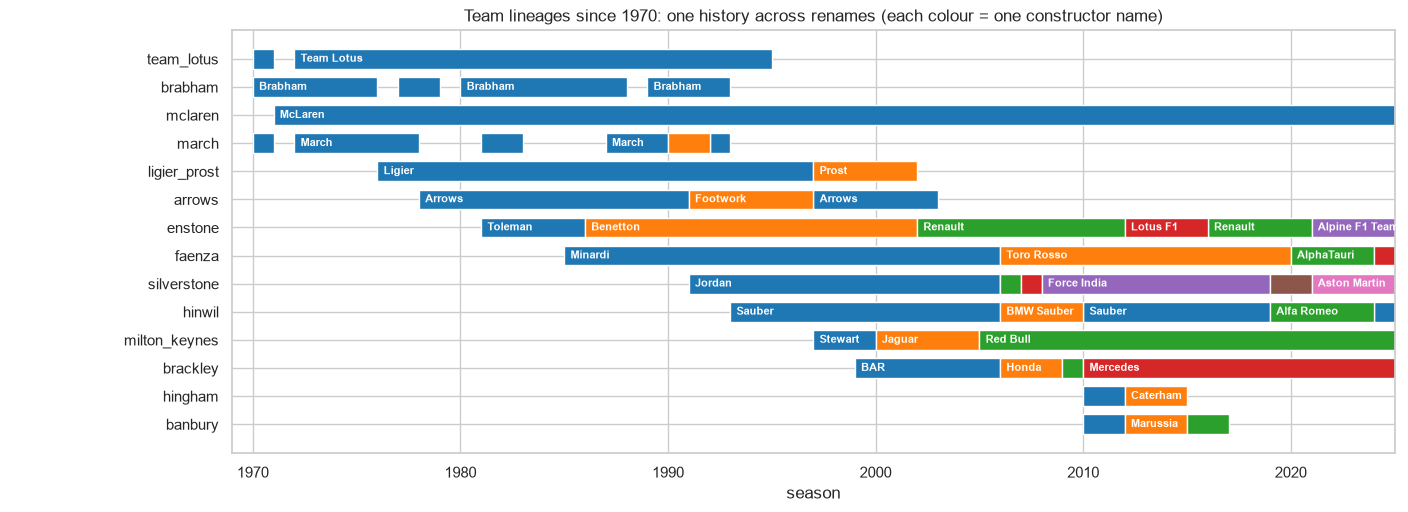

In [36]:
modern_multi = multi[multi['last'] >= 1985]
order = modern_multi.groupby('team_lineage')['first'].min().sort_values().index
fig, ax = plt.subplots(figsize=(15, 5.5))
for i, lineage in enumerate(order):
    d = modern_multi[modern_multi['team_lineage'] == lineage]
    for j, (_, r_) in enumerate(d.iterrows()):
        for a, b in r_['ranges']:
            ax.barh(i, b - a + 1, left=a, color=sns.color_palette('tab10')[j % 10], edgecolor='white', height=0.7)
            if b - a >= 2:
                ax.text(a + 0.3, i, r_['name'], va='center', fontsize=8, color='white', fontweight='bold')
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set(title='Team lineages since 1970: one history across renames (each colour = one constructor name)',
       xlabel='season', xlim=(1969, 2025))
save_fig(fig, 's2_team_lineages')
plt.show()

Each row is now one continuous team history. For example the Brackley lineage runs BAR → Honda → Brawn → Mercedes,
so a "constructor form before this race" feature computed on `team_lineage` carries Brawn's 2009 results into
Mercedes' 2010 season, whereas on `constructorId` Mercedes would start 2010 with no history. Both keys stay in the
table; Step 4 compares them empirically.

## 2.11 Nationality → country
Driver nationality is an adjective ("British"), circuit country a noun ("UK") — §1.8.7 found zero literal matches.
One explicit table maps **every** nationality to the circuit vocabulary, and circuit spellings are unified
(`United States` → `USA`). Decisions:
* dual nationalities (`American-Italian`, `Argentine-Italian`) → the first-listed (racing) nationality;
* `East German` → `Germany` (the German circuits in the data are in today's Germany);
* nationalities whose country never hosted a race (e.g. Finnish, Colombian) map to their real country — such drivers
  simply never have a home race.

In [37]:
NAT_TO_COUNTRY = {
    'American': 'USA', 'American-Italian': 'USA', 'Argentine': 'Argentina', 'Argentine-Italian': 'Argentina',
    'Argentinian': 'Argentina', 'Australian': 'Australia', 'Austrian': 'Austria', 'Belgian': 'Belgium',
    'Brazilian': 'Brazil', 'British': 'UK', 'Canadian': 'Canada', 'Chilean': 'Chile', 'Chinese': 'China',
    'Colombian': 'Colombia', 'Czech': 'Czech Republic', 'Danish': 'Denmark', 'Dutch': 'Netherlands',
    'East German': 'Germany', 'Finnish': 'Finland', 'French': 'France', 'German': 'Germany', 'Hungarian': 'Hungary',
    'Indian': 'India', 'Indonesian': 'Indonesia', 'Irish': 'Ireland', 'Italian': 'Italy', 'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein', 'Malaysian': 'Malaysia', 'Mexican': 'Mexico', 'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand', 'Polish': 'Poland', 'Portuguese': 'Portugal', 'Rhodesian': 'Rhodesia',
    'Russian': 'Russia', 'South African': 'South Africa', 'Spanish': 'Spain', 'Swedish': 'Sweden',
    'Swiss': 'Switzerland', 'Thai': 'Thailand', 'Uruguayan': 'Uruguay', 'Venezuelan': 'Venezuela'}
COUNTRY_FIX = {'United States': 'USA'}

clean['circuits']['country'] = clean['circuits']['country'].replace(COUNTRY_FIX)
clean['drivers']['driver_country'] = clean['drivers']['nationality'].map(NAT_TO_COUNTRY)
missing_nat = clean['drivers'].loc[clean['drivers']['driver_country'].isna(), 'nationality'].unique()
assert len(missing_nat) == 0, f'unmapped nationalities: {missing_nat}'

host_countries = set(clean['races'].merge(clean['circuits'], on='circuitId')['country'])
nat_table = (clean['drivers'].groupby(['nationality', 'driver_country']).size().rename('drivers').reset_index()
             .assign(country_hosted_a_race=lambda d: d['driver_country'].isin(host_countries)))
print(f'{nat_table["nationality"].nunique()} nationalities -> {nat_table["driver_country"].nunique()} countries; '
      f'circuit countries: {len(host_countries)}; drivers whose country hosted a race: '
      f'{nat_table.loc[nat_table["country_hosted_a_race"], "drivers"].sum()} of {nat_table["drivers"].sum()}')
nat_table.sort_values('drivers', ascending=False).reset_index(drop=True)

43 nationalities -> 39 countries; circuit countries: 34; drivers whose country hosted a race: 811 of 861


,nationality,driver_country,drivers,country_hosted_a_race
0,British,UK,166,True
1,American,USA,158,True
2,Italian,Italy,99,True
3,French,France,73,True
4,German,Germany,50,True
5,Brazilian,Brazil,32,True
6,Argentine,Argentina,24,True
7,Swiss,Switzerland,23,True
8,Belgian,Belgium,23,True
9,South African,South Africa,23,True


## 2.12 The cleaned driver–race table
All cleaned pieces are joined onto the deduplicated, filtered results with **validated** joins (`many_to_one` /
`one_to_one`, so no join can multiply rows). The table still contains post-race columns (status, laps, points …)
because the data-engineering questions need them; Step 4 selects the leakage-safe features from it.

In [38]:
drv = clean['drivers'].assign(driver=clean['drivers']['forename'] + ' ' + clean['drivers']['surname'])
circ = clean['circuits'][['circuitId', 'circuitRef', 'name', 'country']].rename(
    columns={'name': 'circuit', 'country': 'circuit_country'})
qcols = Q[['raceId', 'driverId', 'position', 'q1_s', 'q2_s', 'q3_s', 'best_q_s', 'gap_to_pole_s',
           'gap_to_pole_pct', 'outside_107']].rename(columns={'position': 'quali_pos'})

results_clean = (res3
    .merge(circ, on='circuitId', how='left', validate='many_to_one')
    .merge(drv[['driverId', 'driverRef', 'driver', 'dob', 'nationality', 'driver_country']],
           on='driverId', how='left', validate='many_to_one')
    .merge(cons.rename(columns={'name': 'constructor'}), on='constructorId', how='left', validate='many_to_one')
    .merge(qcols, on=['raceId', 'driverId'], how='left', validate='one_to_one'))
results_clean['has_quali'] = results_clean['quali_pos'].notna()
results_clean['podium'] = (results_clean['positionOrder'] <= 3).astype(int)
results_clean = results_clean.sort_values(['date', 'raceId', 'positionOrder']).reset_index(drop=True)

assert len(results_clean) == len(res3)
assert not results_clean.duplicated(['raceId', 'driverId']).any()
print(f'results_clean: {results_clean.shape[0]:,} rows x {results_clean.shape[1]} columns, '
      f'{results_clean["raceId"].nunique():,} races, seasons {results_clean["year"].min()}–{results_clean["year"].max()}, '
      f'podium rate {results_clean["podium"].mean():.3f}')
results_clean[['year', 'race_name', 'driver', 'constructor', 'team_lineage', 'grid', 'quali_pos', 'gap_to_pole_pct',
               'grid_source', 'entry_type', 'status_group', 'positionOrder', 'podium']].tail(5)

results_clean: 24,755 rows x 54 columns, 1,114 races, seasons 1950–2024, podium rate 0.136


,year,race_name,driver,constructor,team_lineage,grid,quali_pos,gap_to_pole_pct,grid_source,entry_type,status_group,positionOrder,podium
24750,2024,Abu Dhabi Grand Prix,Kevin Magnussen,Haas F1 Team,haas,14,15.0,1.255524,qualifying,grid_start,finished,16,0
24751,2024,Abu Dhabi Grand Prix,Liam Lawson,RB F1 Team,faenza,12,12.0,1.061808,qualifying,grid_start,mechanical,17,0
24752,2024,Abu Dhabi Grand Prix,Valtteri Bottas,Sauber,hinwil,9,9.0,0.737333,qualifying,grid_start,accident_driver,18,0
24753,2024,Abu Dhabi Grand Prix,Franco Colapinto,Williams,williams,20,19.0,1.594528,qualifying,grid_start,mechanical,19,0
24754,2024,Abu Dhabi Grand Prix,Sergio Pérez,Red Bull,milton_keynes,10,10.0,0.809976,qualifying,grid_start,accident_driver,20,0


## 2.13 EDA after cleaning — before / after comparison
### 2.13.1 Effect of each row-changing step

,step,rows,rows_removed,races,podium_rows,podiums_removed,podium_rate,note
0,0. raw results,26759,0,1125,3397,0,0.1269,all result rows
1,"1. deduplicate (raceId, driverId)",26668,91,1125,3395,2,0.1273,started car > most laps > lowest resultId
2,2. drop Indianapolis 500,26287,381,1114,3359,36,0.1278,11 races
3,3. drop non-starters,24755,1532,1114,3359,0,0.1357,no grid slot at the cutoff


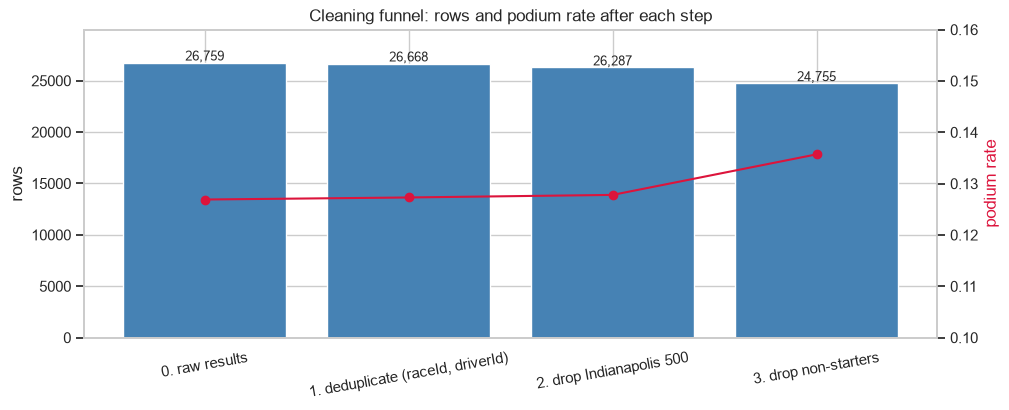

In [39]:
log_df = pd.DataFrame(clean_log)
log_df['rows_removed'] = (-log_df['rows'].diff()).fillna(0).astype(int)
log_df['podiums_removed'] = (-log_df['podium_rows'].diff()).fillna(0).astype(int)
display(log_df[['step', 'rows', 'rows_removed', 'races', 'podium_rows', 'podiums_removed', 'podium_rate', 'note']])

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(log_df['step'], log_df['rows'], color='steelblue')
for x, v in zip(log_df['step'], log_df['rows']):
    ax1.text(x, v + 200, f'{v:,}', ha='center', fontsize=9)
ax1.set(ylabel='rows', title='Cleaning funnel: rows and podium rate after each step', ylim=(0, log_df['rows'].max() * 1.12))
ax2 = ax1.twinx()
ax2.plot(log_df['step'], log_df['podium_rate'], color='crimson', marker='o')
ax2.set_ylabel('podium rate', color='crimson')
ax2.set_ylim(0.10, 0.16)
ax2.grid(False)
plt.setp(ax1.get_xticklabels(), rotation=10)
save_fig(fig, 's2_cleaning_funnel')
plt.show()

### 2.13.2 Summary statistics before vs after

In [40]:
before, after = res, results_clean
rc = clean['results']
compare = pd.DataFrame({
    'raw': {
        'rows': len(before),
        'duplicate (raceId, driverId) rows': int(before.duplicated(['raceId', 'driverId'], keep=False).sum()),
        'races': before['raceId'].nunique(),
        'podium rate': round(before['podium'].mean(), 4),
        'rows with grid = 0': int((before['grid'] == 0).sum()),
        'share of rows with qualifying data': round(before['has_quali'].mean(), 3),
        'share with qualifying data, 2003+': round(before.loc[before['year'] >= 2003, 'has_quali'].mean(), 3),
        "'\\N' / empty placeholder cells (all tables)": int(sum(raw_str[t].isin([SENTINEL, '']).sum().sum() for t in TABLES)),
        'duration columns stored as text': len(typing_report),
        'status categories': before['status'].nunique(),
        'constructor identities': before['constructorId'].nunique(),
        'nationality spellings': raw_str['drivers']['nationality'].nunique(),
    },
    'clean': {
        'rows': len(after),
        'duplicate (raceId, driverId) rows': int(after.duplicated(['raceId', 'driverId'], keep=False).sum()),
        'races': after['raceId'].nunique(),
        'podium rate': round(after['podium'].mean(), 4),
        'rows with grid = 0': int((after['grid'] == 0).sum()),
        'share of rows with qualifying data': round(after['has_quali'].mean(), 3),
        'share with qualifying data, 2003+': round(after.loc[after['year'] >= 2003, 'has_quali'].mean(), 3),
        "'\\N' / empty placeholder cells (all tables)": int(sum((clean[t] == SENTINEL).sum().sum() + (clean[t] == '').sum().sum() for t in TABLES)),
        'duration columns stored as text': 0,
        'status categories': after['status_group'].nunique(),
        'constructor identities': after['team_lineage'].nunique(),
        'nationality spellings': after['driver_country'].nunique(),
    }})
compare

,raw,clean
rows,26759.0000,24755.0000
"duplicate (raceId, driverId) rows",176.0000,0.0000
races,1125.0000,1114.0000
podium rate,0.1269,0.1357
rows with grid = 0,1638.0000,122.0000
share of rows with qualifying data,0.3920,0.4240
"share with qualifying data, 2003+",0.9970,0.9970
'\N' / empty placeholder cells (all tables),160144.0000,0.0000
duration columns stored as text,11.0000,0.0000
status categories,137.0000,4.0000


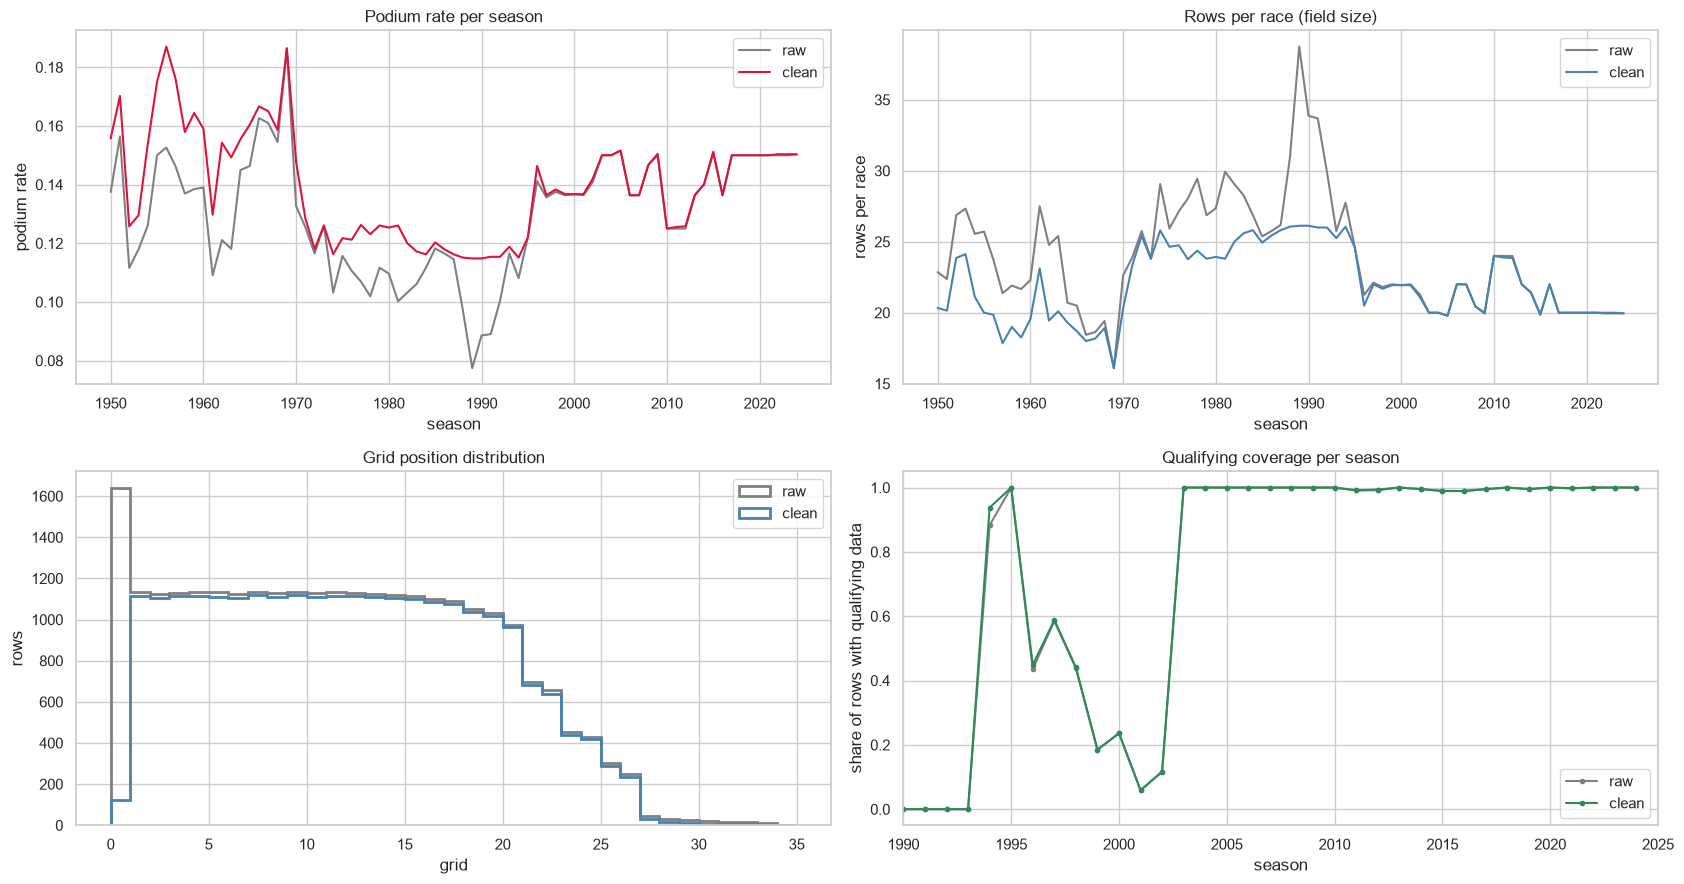

In [41]:
def season_stats(df):
    per = df.groupby(['year', 'raceId']).size().groupby('year').mean().rename('entrants')
    return pd.concat([per, df.groupby('year')['podium'].mean().rename('podium_rate'),
                      df.groupby('year')['has_quali'].mean().rename('quali_coverage')], axis=1)

sb, sa = season_stats(before), season_stats(after)
fig, axes = plt.subplots(2, 2, figsize=(17, 9))
axes[0, 0].plot(sb.index, sb['podium_rate'], color='grey', label='raw')
axes[0, 0].plot(sa.index, sa['podium_rate'], color='crimson', label='clean')
axes[0, 0].set(title='Podium rate per season', xlabel='season', ylabel='podium rate')
axes[0, 1].plot(sb.index, sb['entrants'], color='grey', label='raw')
axes[0, 1].plot(sa.index, sa['entrants'], color='steelblue', label='clean')
axes[0, 1].set(title='Rows per race (field size)', xlabel='season', ylabel='rows per race')
bins = np.arange(0, 36)
axes[1, 0].hist(before['grid'], bins=bins, histtype='step', linewidth=2, color='grey', label='raw')
axes[1, 0].hist(after['grid'], bins=bins, histtype='step', linewidth=2, color='steelblue', label='clean')
axes[1, 0].set(title='Grid position distribution', xlabel='grid', ylabel='rows')
axes[1, 1].plot(sb.index, sb['quali_coverage'], color='grey', marker='.', label='raw')
axes[1, 1].plot(sa.index, sa['quali_coverage'], color='seagreen', marker='.', label='clean')
axes[1, 1].set(title='Qualifying coverage per season', xlabel='season', ylabel='share of rows with qualifying data',
               xlim=(1990, 2025))
for ax in axes.ravel():
    ax.legend()
plt.tight_layout()
save_fig(fig, 's2_before_after')
plt.show()

### 2.13.3 Retirement causes after cleaning

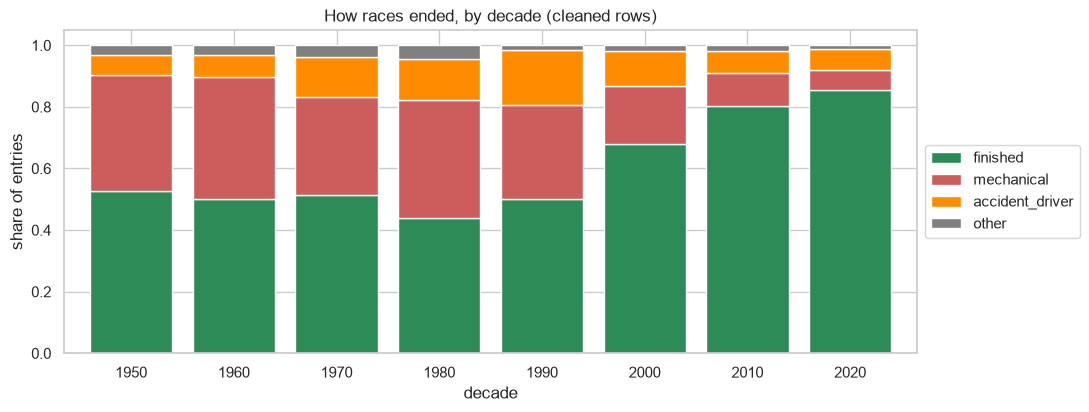

status_group,finished,mechanical,accident_driver,other
year,,,,
1950,0.526,0.376,0.067,0.030
1960,0.500,0.396,0.072,0.032
1970,0.514,0.319,0.127,0.040
1980,0.440,0.381,0.132,0.046
1990,0.502,0.304,0.179,0.015
2000,0.679,0.188,0.115,0.018
2010,0.804,0.105,0.073,0.018
2020,0.856,0.063,0.068,0.014


In [42]:
grp = (after.groupby([after['year'] // 10 * 10, 'status_group']).size().unstack(fill_value=0)
            .pipe(lambda d: d.div(d.sum(axis=1), axis=0))[['finished', 'mechanical', 'accident_driver', 'other']])
fig, ax = plt.subplots(figsize=(11, 4.2))
grp.plot(kind='bar', stacked=True, ax=ax, color=['seagreen', 'indianred', 'darkorange', 'grey'], width=0.8)
ax.set(title='How races ended, by decade (cleaned rows)', xlabel='decade', ylabel='share of entries')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xticks(rotation=0)
save_fig(fig, 's2_status_groups_by_decade')
plt.show()
grp.round(3)

In [43]:
key_cols = ['grid', 'quali_pos', 'q1_s', 'q2_s', 'q3_s', 'best_q_s', 'gap_to_pole_pct', 'team_lineage',
            'driver_country', 'circuit_country', 'dob', 'status_group']
miss = pd.DataFrame({'all seasons': results_clean[key_cols].isna().mean(),
                     '2003+': results_clean.loc[results_clean['year'] >= 2003, key_cols].isna().mean()}).mul(100).round(1)
miss.columns = [f'% missing ({c})' for c in miss.columns]
miss

,% missing (all seasons),% missing (2003+)
grid,0.0,0.0
quali_pos,57.6,0.3
q1_s,58.3,1.6
q2_s,76.4,34.8
q3_s,85.3,59.5
best_q_s,58.3,1.6
gap_to_pole_pct,58.3,1.6
team_lineage,0.0,0.0
driver_country,0.0,0.0
circuit_country,0.0,0.0


**What changed, and why it matters for the model**
* **Grain fixed:** 0 duplicate `(raceId, driverId)` rows; every remaining row is one real prediction (a driver with a
  place in the race at the cutoff).
* **Podium rate rises** because only negatives were removed (non-starters and the Indy 500's large fields) — the
  positive class is intact. The rise is largest in the late 1980s / early 1990s where pre-qualifying inflated the
  field; the base rate is still era-dependent, which Steps 5–6 must account for.
* **The `grid = 0` spike disappears**; the remaining `grid = 0` rows are flagged pit-lane starts.
* **Qualifying coverage** is unchanged in structure — 0 % before 1994, patchy 1996–2002, ≈ 100 % from 2003 — but now
  measured on real starters only. From 2003 the qualifying columns are essentially complete (`q2`/`q3` missing by
  design for drivers eliminated earlier), which is the strongest argument for the training-window decision in Step 5.
* **Reliability drift** is visible in the status groups: mechanical failures ended 30–40 % of entries in every decade
  before the 2000s but only ≈ 6 % in the 2020s, while the finishing share rose from ≈ 50 % to ≈ 86 % — the same grid
  slot converts to a podium far more reliably today (era sensitivity).

### 2.13.4 Outliers in the cleaned numeric columns
A standard check from the labs: values beyond the **1.5 × IQR fences** (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) are
flagged as outliers. In this data the question is not "is the value unusual?" but **"is it an error or a real race
situation?"**. Only errors are removed. The one impossible value found so far, the 16:42 qualifying "lap", was already
removed in §2.8.

,rows,median,IQR fences,outliers,% outliers,largest value
column,,,,,,
grid,24755,12.00,"[-10.5, 33.5]",1,0.00,34 (1953 German Grand Prix)
laps,24755,53.00,"[-25.5, 122]",0,0.00,110 (1963 United States Grand Prix)
points,24755,0.00,"[-3, 5]",3852,15.56,50 (2014 Abu Dhabi Grand Prix)
best_q_s,10328,86.68,"[53.3, 121]",130,1.26,153.9 (1994 Belgian Grand Prix)
gap_to_pole_pct,10328,1.84,"[-2.34, 6.31]",538,5.21,45.6 (2023 Saudi Arabian Grand Prix)
fastestLapTime_s,8252,90.27,"[52.9, 127]",30,0.36,202.3 (2007 European Grand Prix)


best_q_s: most outliers at {'Circuit de Spa-Francorchamps': 97, 'Sepang International Circuit': 10, 'Autódromo Juan y Oscar Gálvez': 6}
gap_to_pole_pct: most outliers at {'Autódromo José Carlos Pace': 51, 'Circuit de Spa-Francorchamps': 50, 'Silverstone Circuit': 48}
fastestLapTime_s: most outliers at {'Nürburgring': 6, 'Autodromo Internazionale del Mugello': 5, 'Circuit de Spa-Francorchamps': 3}


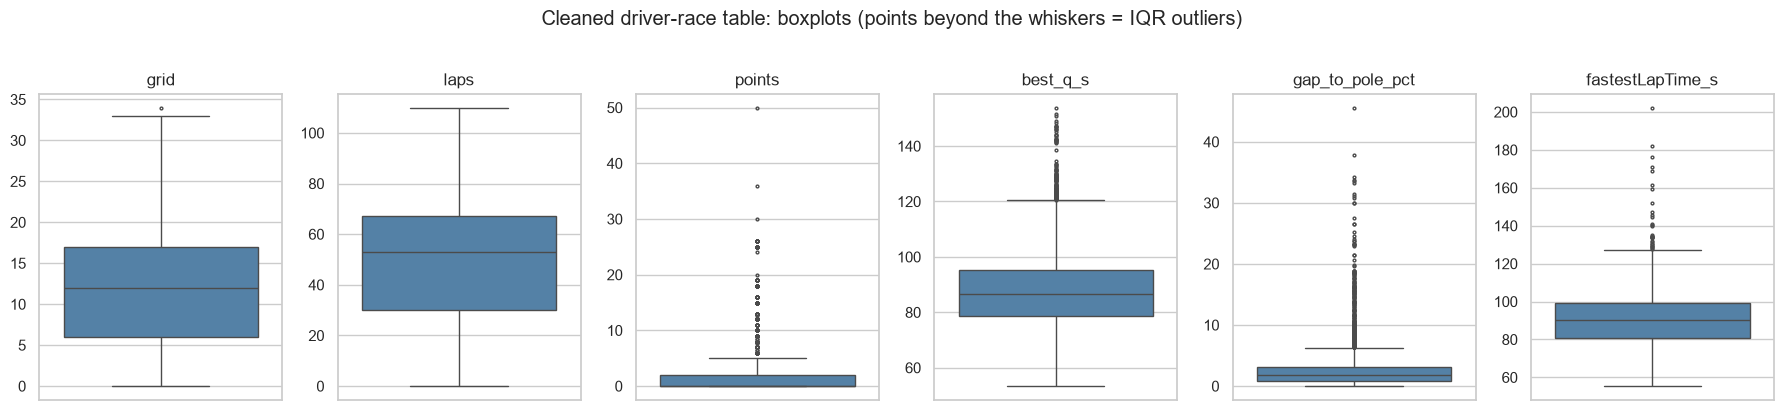

In [44]:
OUT_COLS = ['grid', 'laps', 'points', 'best_q_s', 'gap_to_pole_pct', 'fastestLapTime_s']
out_rows, out_where = [], {}
for c in OUT_COLS:
    s = results_clean[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    out = results_clean.loc[s[(s < lo) | (s > hi)].index]
    big = results_clean.loc[s.idxmax()]
    out_where[c] = out['circuit'].value_counts().head(3).to_dict()
    out_rows.append({'column': c, 'rows': len(s), 'median': s.median(), 'IQR fences': f'[{lo:.3g}, {hi:.3g}]',
                     'outliers': len(out), '% outliers': 100 * len(out) / len(s),
                     'largest value': f'{s.max():.4g} ({big["year"]} {big["race_name"]})'})
display(pd.DataFrame(out_rows).set_index('column').round(2))
for c in ['best_q_s', 'gap_to_pole_pct', 'fastestLapTime_s']:
    print(f'{c}: most outliers at {out_where[c]}')

fig, axes = plt.subplots(1, len(OUT_COLS), figsize=(18, 4))
for ax, c in zip(axes, OUT_COLS):
    sns.boxplot(y=results_clean[c].dropna(), ax=ax, color='steelblue', fliersize=2)
    ax.set(title=c, ylabel='')
fig.suptitle('Cleaned driver-race table: boxplots (points beyond the whiskers = IQR outliers)', y=1.02)
plt.tight_layout()
save_fig(fig, 's2_outliers_boxplots')
plt.show()

**Decision: keep every value. The flagged values are real, not errors.**
* **`grid`:** 1 value above the fence, a 34-car field at the 1953 German GP. The oversized fields of the 1950s are real
  (§1.8.1).
* **`laps`:** no outliers. Race length varies by circuit and era, but within the fences.
* **`best_q_s` (1.3 %) and `fastestLapTime_s` (0.4 %):** almost all at the **longest circuits** (Spa-Francorchamps
  alone has 97 of the 130 qualifying outliers; the old Nürburgring), plus wet sessions. A long lap is a property of the
  circuit, not a measurement error.
* **`gap_to_pole_pct` (5.2 %):** drivers with problems or no representative lap (e.g. 45.6 % at the 2023 Saudi GP).
  The values are real and flagged by `outside_107` (§2.8). The model does not use lap-time gaps anyway (dropped in
  §5.2).
* **`points` (15.6 %):** the IQR rule fails on zero-inflated data. Most entries score 0, so *every* points finish
  falls outside the fences. Points are also post-race information and never a feature.
* **For the models:** clipping or deleting these rows would remove real races. Tree models are insensitive to extreme
  values (they only use split thresholds). For LR/NN the features are positions, rates and counts, scaled in §5.7.1.

## 2.14 Step 2 summary
| Decision | Rule | Evidence |
|---|---|---|
| Missing values | `\N` and `''` → NaN after stripping whitespace; numeric only if every value parses | §2.1 report, 0 placeholders left |
| Typing | dates → datetime; all durations → seconds with one parser | §2.2, verified against `milliseconds` |
| Grain | started car → most laps → lowest resultId; `n_cars_driven`, `shared_car` flags | §1.7 + §2.3 |
| Shared cars | both co-drivers keep `podium = 1` | §2.3 |
| Indy 500 | excluded (11 races) | §1.8.6 |
| Status | 139 values → finished / mechanical / accident_driver / other, all mapped | §2.5 |
| Non-starters | drop entries with no grid slot at the cutoff (0 podiums lost); keep `pit_lane_start` | §2.6 |
| Integrity | target intact in every race; early-era grid ties and 1 laps anomaly documented | §2.7 |
| Qualifying | 1 impossible lap removed (> 2× session best); 107 % flagged not deleted; best lap + gap to pole | §2.8 |
| Grid source | 2021–22 sprint weekends → `grid_source = 'sprint'` | §2.9 |
| Team lineage | renames linked into continuous team histories | §2.10 |
| Home country | explicit nationality → country map, US spelling unified | §2.11 |

# 3. Data-Engineering Questions
Each question is answered from the cleaned tables of Section 2 with **explicit multi-hop joins** (the join path is
printed at the top of each sub-section), a result table, a plot, a written answer, and a note on **grain,
missingness and the pre-race cutoff**.

Shared conventions
* **Unit of analysis:** one driver in one race (the cleaned grain; non-starters and the Indy 500 are already removed).
* **Uncertainty:** every rate is shown with a **95 % Wilson confidence interval** — circuits and teams contribute only
  a few dozen events per era, so raw rates alone would over-interpret noise. Wilson is used instead of the normal
  approximation because it stays inside [0, 1] and behaves well for rates near 0 % or 100 %.
* **Minimum sample:** a circuit is ranked only with ≥ 10 front-row starts in an era (Q1); a team only with ≥ 40 race
  starts in an era (Q3).
* **No test-set influence on modeling:** where a Step 3 result is later used as evidence for a modeling decision
  (Step 4), only **training seasons (≤ 2019)** are quoted for that purpose.

In [45]:
from scipy import stats

def wilson(k, n, z=1.96):
    """Wilson score interval for k successes out of n -> (rate, low, high)."""
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return p, centre - half, centre + half

def rate_table(df, by, flag):
    t = df.groupby(by, observed=True)[flag].agg(n='size', k='sum').reset_index()
    t['rate'], t['ci_low'], t['ci_high'] = wilson(t['k'], t['n'])
    return t

# results-level columns only; every other attribute is joined explicitly per question
base = results_clean[['resultId', 'raceId', 'driverId', 'constructorId', 'statusId', 'grid', 'positionOrder',
                      'podium', 'team_lineage', 'grid_source']].copy()
races_t = clean['races'][['raceId', 'year', 'round', 'circuitId']]
circuits_t = clean['circuits'][['circuitId', 'circuitRef', 'location', 'country']]
drivers_t = clean['drivers'][['driverId', 'driverRef', 'nationality', 'driver_country']]
quali_t = Q[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})
print(f'base: {len(base):,} driver-race rows')

base: 24,755 driver-race rows


## 3.1 Q1 — Which circuits convert a front-row start into a podium most often, and does that change after 2014?
**Join path:** `results` ⋈ `races` (season, circuit) ⋈ `circuits` (venue) ⋈ `qualifying` (qualifying position).

**Definitions**
* **Front row by grid:** started from grid slot 1 or 2 (after penalties and pit-lane starts).
* **Front row by qualifying:** qualified P1 or P2 (before penalties). The two differ — §1.8.4 found grid ≠ qualifying
  position for 27 % of starters — so both are reported.
* **Conversion rate:** share of front-row starters who finish on the podium, per circuit and era.
* **Eras:** **2003–2013** vs **2014–2024** (hybrid engines from 2014). Eleven seasons each, and the window in which
  qualifying data is ≈ 100 % complete (§1.8.2), so the grid and qualifying definitions are compared on the same races.
* **Ranking:** circuits with ≥ 10 front-row starts in an era, ranked by the **lower bound** of the Wilson interval — a
  circuit ranks high only if it converts often *and* the evidence is sufficient.

In [46]:
q1 = (base
      .merge(races_t, on='raceId', how='left', validate='many_to_one')
      .merge(circuits_t, on='circuitId', how='left', validate='many_to_one')
      .merge(quali_t, on=['raceId', 'driverId'], how='left', validate='one_to_one'))
q1 = q1[q1['year'].between(2003, 2024)].copy()
q1['era'] = np.where(q1['year'] <= 2013, '2003–2013', '2014–2024')
q1['front_row_grid'] = q1['grid'].isin([1, 2])
q1['front_row_quali'] = q1['quali_pos'].isin([1, 2])

# readable circuit label (location); disambiguate two layouts in one city
loc_count = q1.drop_duplicates('circuitId')['location'].value_counts()
q1['circuit'] = np.where(q1['location'].map(loc_count) > 1, q1['location'] + ' (' + q1['circuitRef'] + ')', q1['location'])

print(f'rows 2003–2024: {len(q1):,}; races: {q1["raceId"].nunique()}; circuits: {q1["circuitId"].nunique()}')
print(f'missing qualifying position: {q1["quali_pos"].isna().sum()} rows ({q1["quali_pos"].isna().mean():.1%})')
print(f'front-row starters per race: grid {q1.groupby("raceId")["front_row_grid"].sum().mean():.2f}, '
      f'qualifying {q1.groupby("raceId")["front_row_quali"].sum().mean():.2f}')

MIN_FR = 10
conv = {d: rate_table(q1[q1[f'front_row_{d}']], ['circuit', 'era'], 'podium') for d in ['grid', 'quali']}
overall = pd.concat({d: rate_table(q1[q1[f'front_row_{d}']], ['era'], 'podium').set_index('era')
                     for d in ['grid', 'quali']}, names=['definition'])
overall.round(3)

rows 2003–2024: 8,961; races: 428; circuits: 38
missing qualifying position: 23 rows (0.3%)
front-row starters per race: grid 2.00, qualifying 2.00


n    k   rate  ci_low  ci_high
definition era                                        
grid       2003–2013  400  272  0.680   0.633    0.724
           2014–2024  454  345  0.760   0.719    0.797
quali      2003–2013  400  269  0.672   0.625    0.717
           2014–2024  456  336  0.737   0.695    0.775

In [47]:
def ranking(t, era, min_n=MIN_FR):
    r = t[(t['era'] == era) & (t['n'] >= min_n)].sort_values(['ci_low', 'rate'], ascending=False).reset_index(drop=True)
    r.index = r.index + 1
    r['conversion'] = r.apply(lambda x: f"{x['rate']:.0%} [{x['ci_low']:.0%}–{x['ci_high']:.0%}]", axis=1)
    return r[['circuit', 'n', 'k', 'conversion']].rename(columns={'n': 'front-row starts', 'k': 'podiums'})

g = conv['grid']
print('Front row by GRID — top 10 per era (ranked by Wilson lower bound; ≥ 10 front-row starts)')
display(pd.concat({era: ranking(g, era).head(10) for era in ['2003–2013', '2014–2024']}, axis=1))
print('Bottom 5 per era:')
display(pd.concat({era: ranking(g, era).tail(5).rename_axis('rank').reset_index() for era in ['2003–2013', '2014–2024']}, axis=1))

Front row by GRID — top 10 per era (ranked by Wilson lower bound; ≥ 10 front-row starts)


2003–2013                                            2014–2024                                        
        circuit front-row starts podiums     conversion      circuit front-row starts podiums     conversion
1   Magny Cours               12      11  92% [65%–99%]       Suzuka               18      16  89% [67%–97%]
2   Monte-Carlo               22      17  77% [57%–90%]    Abu Dhabi               22      19  86% [67%–95%]
3         Monza               22      17  77% [57%–90%]  Monte-Carlo               20      17  85% [64%–95%]
4      Istanbul               14      11  79% [52%–92%]     Montmeló               22      18  82% [61%–93%]
5   Silverstone               22      16  73% [52%–87%]          Spa               22      18  82% [61%–93%]
6           Spa               18      13  72% [49%–88%]       Austin               20      16  80% [58%–92%]
7        Suzuka               18      13  72% [49%–88%]        Sochi               16      13  81% [57%–93%]
8      Montmeló               22      15  68% [47%–84%]    São Paulo               19      15  79% [57%–91%]
9    Hockenheim               14      10  71% [45%–88%]  Silverstone               24      18  75% [55%–88%]
10       Sakhir               18      12  67% [44%–84%]     Montreal               18      14  78% [55%–91%]

Bottom 5 per era:


2003–2013                                                     2014–2024                                                     
       rank     circuit front-row starts podiums     conversion      rank      circuit front-row starts podiums     conversion
0        17    Montreal               20      12  60% [39%–78%]        15    Melbourne               18      13  72% [49%–88%]
1        18     Nürburg               16       9  56% [33%–77%]        16       Sakhir               24      16  67% [47%–82%]
2        19  Marina Bay               12       7  58% [32%–81%]        17     Budapest               22      13  59% [39%–77%]
3        20   Abu Dhabi               10       6  60% [31%–83%]        18         Baku               16      10  62% [39%–82%]
4        21    Valencia               10       6  60% [31%–83%]        19  Mexico City               18      11  61% [39%–80%]

circuits with ≥ 10 front-row starts in BOTH eras: 14
Spearman rank correlation of circuit rankings, 2003–13 vs 2014–24: rho = 0.21 (p = 0.474)


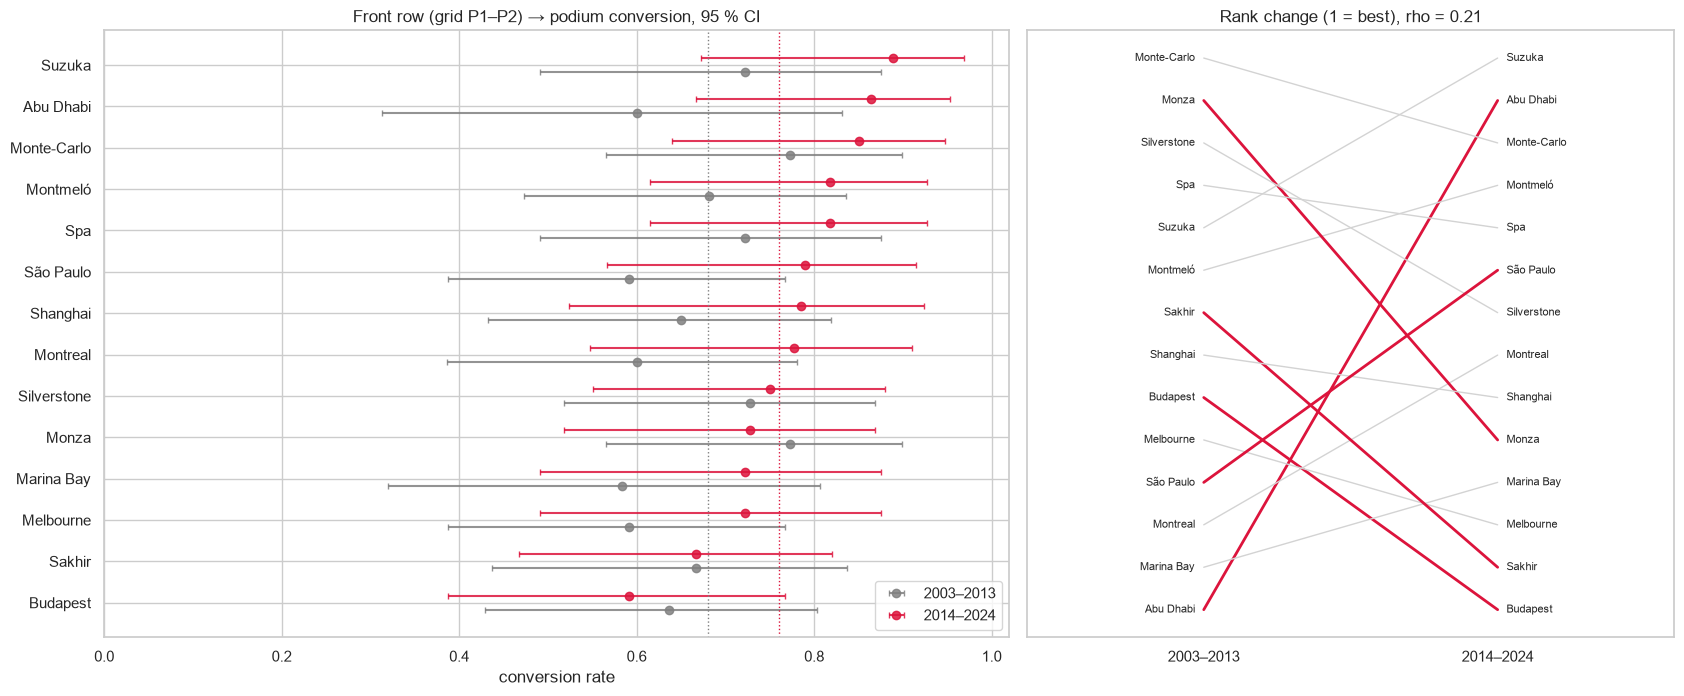

In [48]:
wide = g.pivot(index='circuit', columns='era', values=['n', 'k', 'rate', 'ci_low', 'ci_high'])
both = wide[(wide[('n', '2003–2013')] >= MIN_FR) & (wide[('n', '2014–2024')] >= MIN_FR)].copy()
for era in ['2003–2013', '2014–2024']:
    ordered = both.sort_values([('ci_low', era), ('rate', era)], ascending=False).index
    both[('rank', era)] = pd.Series(np.arange(1, len(ordered) + 1), index=ordered)
rho, p_rho = stats.spearmanr(both[('rank', '2003–2013')], both[('rank', '2014–2024')])
print(f'circuits with ≥ {MIN_FR} front-row starts in BOTH eras: {len(both)}')
print(f'Spearman rank correlation of circuit rankings, 2003–13 vs 2014–24: rho = {rho:.2f} (p = {p_rho:.3f})')

order_ = both[('rate', '2014–2024')].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(17, 0.38 * len(both) + 1.8), gridspec_kw={'width_ratios': [1.4, 1]})
ax = axes[0]
for off, era, col in [(-0.17, '2003–2013', 'grey'), (0.17, '2014–2024', 'crimson')]:
    y = np.arange(len(order_)) + off
    r_ = both.loc[order_, ('rate', era)]
    ax.errorbar(r_, y, xerr=[r_ - both.loc[order_, ('ci_low', era)], both.loc[order_, ('ci_high', era)] - r_],
                fmt='o', color=col, ecolor=col, alpha=0.85, capsize=2, label=era)
ax.set_yticks(np.arange(len(order_)), order_)
ax.axvline(overall.loc[('grid', '2014–2024'), 'rate'], color='crimson', linestyle=':', linewidth=1)
ax.axvline(overall.loc[('grid', '2003–2013'), 'rate'], color='grey', linestyle=':', linewidth=1)
ax.set(title='Front row (grid P1–P2) → podium conversion, 95 % CI', xlabel='conversion rate', xlim=(0, 1.02))
ax.legend(loc='lower right')

ax = axes[1]
left, right = both[('rank', '2003–2013')], both[('rank', '2014–2024')]
for c_ in both.index:
    moved = abs(left[c_] - right[c_]) >= len(both) / 3
    ax.plot([0, 1], [left[c_], right[c_]], color='crimson' if moved else 'lightgrey', linewidth=2 if moved else 1)
    ax.text(-0.03, left[c_], c_, ha='right', va='center', fontsize=8)
    ax.text(1.03, right[c_], c_, ha='left', va='center', fontsize=8)
ax.set(xlim=(-0.6, 1.6), title=f'Rank change (1 = best), rho = {rho:.2f}')
ax.set_xticks([0, 1], ['2003–2013', '2014–2024'])
ax.invert_yaxis()
ax.set_yticks([])
ax.grid(False)
plt.tight_layout()
save_fig(fig, 's3_q1_front_row_conversion')
plt.show()

### Grid vs qualifying front row
The same question with the qualifying definition, and the cases where the two disagree.

n                rate          
era                                  2003–2013 2014–2024 2003–2013 2014–2024
group                                                                       
qualified P1–2                           400.0     456.0     0.672     0.737
started P1–2 (grid)                      400.0     454.0     0.680     0.760
qualified P1–2, started further back       9.0      29.0     0.222     0.310
started P1–2, qualified P3+                9.0      27.0     0.556     0.667

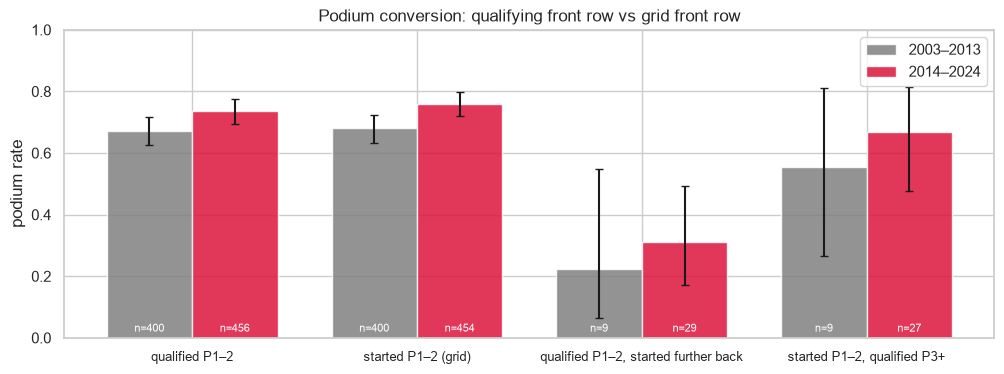

circuit ranking, grid definition vs qualifying definition (Spearman): {'2003–2013': np.float64(0.91), '2014–2024': np.float64(0.84)}
qualifying front-row rows on 2021–22 sprint weekends (grid set by the sprint): 12, of which started from the front row: 7


In [49]:
cats = {
    'qualified P1–2': q1['front_row_quali'],
    'started P1–2 (grid)': q1['front_row_grid'],
    'qualified P1–2, started further back': q1['front_row_quali'] & ~q1['front_row_grid'],
    'started P1–2, qualified P3+': q1['front_row_grid'] & q1['quali_pos'].gt(2),
}
gq_tab = pd.concat({name: rate_table(q1[mask], ['era'], 'podium').set_index('era') for name, mask in cats.items()},
                   names=['group']).reset_index()
display(gq_tab.pivot(index='group', columns='era', values=['n', 'rate']).round(3).loc[list(cats)])

fig, ax = plt.subplots(figsize=(12, 4))
w = 0.38
for j, (era, col) in enumerate([('2003–2013', 'grey'), ('2014–2024', 'crimson')]):
    d = gq_tab[gq_tab['era'] == era].set_index('group').loc[list(cats)]
    x = np.arange(len(cats)) + (j - 0.5) * w
    ax.bar(x, d['rate'], width=w, color=col, alpha=0.85, label=era,
           yerr=[d['rate'] - d['ci_low'], d['ci_high'] - d['rate']], capsize=3)
    for xi, (n_, r_) in zip(x, zip(d['n'], d['rate'])):
        ax.text(xi, 0.02, f'n={n_}', ha='center', fontsize=8, color='white')
ax.set_xticks(np.arange(len(cats)), list(cats), fontsize=9)
ax.set(title='Podium conversion: qualifying front row vs grid front row', ylabel='podium rate', ylim=(0, 1))
ax.legend()
save_fig(fig, 's3_q1_grid_vs_qualifying')
plt.show()

cq = conv['quali']
both_q = cq.pivot(index='circuit', columns='era', values=['n', 'ci_low'])
common = [c_ for c_ in both.index if c_ in both_q.index]
rho_gq = {era: stats.spearmanr(both.loc[common, ('ci_low', era)], both_q.loc[common, ('ci_low', era)])[0]
          for era in ['2003–2013', '2014–2024']}
print('circuit ranking, grid definition vs qualifying definition (Spearman):', {k: round(v, 2) for k, v in rho_gq.items()})
spr = q1[q1['front_row_quali'] & q1['grid_source'].eq('sprint')]
print(f'qualifying front-row rows on 2021–22 sprint weekends (grid set by the sprint): {len(spr)}, '
      f'of which started from the front row: {int(spr["front_row_grid"].sum())}')

### Q1 — Answer
**Overall:** a front-row start converts into a podium **68 %** of the time in 2003–2013 and **76 %** in 2014–2024
(grid definition; 67 % → 74 % by qualifying). The front row became *more* decisive in the hybrid era — consistent
with fewer mechanical failures (Q3) and long periods of one or two dominant teams.

**Circuits that convert most often** (ranked by the lower bound of the 95 % CI, ≥ 10 front-row starts):
* 2003–2013: Magny-Cours 92 % (only 12 starts — wide CI), Monaco 77 %, Monza 77 %, Istanbul 79 %, Silverstone 73 %.
* 2014–2024: **Suzuka 89 %, Abu Dhabi 86 %, Monaco 85 %**, Barcelona 82 %, Spa 82 %.
* Lowest after 2014: Budapest 59 %, Mexico City 61 %, Baku 62 %.

**Does the ranking change after 2014? Yes, substantially.** For the 14 circuits with enough starts in both eras the
rank correlation is only ρ = 0.21 (p = 0.47): Abu Dhabi moves from last (60 %) to 2nd (86 %), while Monza, Sakhir
and Budapest fall from the upper half to the bottom. Monaco is the only circuit near the top in both eras (where
overtaking is hardest, the starting order holds). **Caveat:** with 10–24 front-row starts per circuit and era, the
CIs are ±15–25 percentage points and overlap heavily — individual circuit positions are weak evidence; the robust
findings are the overall rise and the reshuffled ranking.

**Qualifying vs grid.** At circuit level the two definitions give almost the same ranking (ρ = 0.91 / 0.84), because
the qualifying and grid front rows coincide in ≈ 95 % of cases. Where they differ, **grid is what counts**: drivers
who qualified on the front row but started further back after a penalty converted only 22 % / 31 %, while drivers
promoted onto the front row converted 56 % / 67 %. Such cases tripled after 2014 (9 → 29 per definition; engine-part
penalties), which is why the grid definition's conversion rose slightly more than the qualifying one. On the 2021–22
sprint weekends, 5 of 12 qualifying front-row drivers did not start from the front row (the sprint set the grid).

**Grain / missingness / cutoff.** Grain: a front-row starter in one race (exactly 2 per race, 428 races 2003–2024).
Qualifying position is missing for 23 rows (0.3 %) — negligible. Both grid and qualifying position are known
**before** the start, the podium is the outcome, so this is exactly the pre-race relationship a model can use.

## 3.2 Q2 — Do drivers podium more often at home, controlling for starting position?
**Join path:** `results` ⋈ `drivers` (nationality → country, §2.11) and `results` ⋈ `races` ⋈ `circuits` (circuit
country). **Home race** = driver country equals circuit country.

**Why control for the grid?** If home drivers simply start further forward (or further back — e.g. local one-off
entries in weak cars), a raw home-vs-away comparison would measure grid position, not "home". So the comparison is
made **within grid bands** (P1, P2–3, P4–6, P7–10, P11+) and combined into one adjusted effect:
* **Mantel–Haenszel odds ratio** — a weighted average of the within-band odds ratios (OR > 1 means home drivers
  podium more often than away drivers who started from the same band), with a Robins–Breslow–Greenland 95 % CI;
* **permutation test** — within each band the home label is shuffled 10,000 times (drawn exactly from the
  hypergeometric distribution), giving the p-value of "home makes no difference beyond the grid".

Pit-lane starts (`grid = 0`, 122 rows) have no comparable band and are excluded.

**Windows:** the main answer uses **all cleaned seasons (1950–2024)**. The check uses **2003–2019** — modern era,
complete qualifying data, and **training seasons only**, so it can serve as the evidence for a home-race feature in
Step 4 without the validation/test seasons influencing that decision.

In [50]:
q2 = (base
      .merge(races_t, on='raceId', how='left', validate='many_to_one')
      .merge(circuits_t.rename(columns={'country': 'circuit_country'}), on='circuitId', how='left', validate='many_to_one')
      .merge(drivers_t, on='driverId', how='left', validate='many_to_one'))
assert q2[['driver_country', 'circuit_country']].notna().all().all()
q2['home'] = q2['driver_country'].eq(q2['circuit_country'])
q2 = q2[q2['grid'] > 0].copy()
BAND_EDGES, BAND_LABELS = [0, 1, 3, 6, 10, np.inf], ['P1', 'P2–3', 'P4–6', 'P7–10', 'P11+']
q2['grid_band'] = pd.cut(q2['grid'], BAND_EDGES, labels=BAND_LABELS)

def strata_counts(df):
    c = df.groupby(['grid_band', 'home'], observed=True)['podium'].agg(['sum', 'size']).unstack('home').fillna(0)
    a, n1 = c[('sum', True)], c[('size', True)]
    cc, n0 = c[('sum', False)], c[('size', False)]
    return pd.DataFrame({'a': a, 'b': n1 - a, 'c': cc, 'd': n0 - cc}).astype(float)

def mantel_haenszel(t):
    n = t.sum(axis=1)
    R, S = t['a'] * t['d'] / n, t['b'] * t['c'] / n
    P, Qx = (t['a'] + t['d']) / n, (t['b'] + t['c']) / n
    or_mh = R.sum() / S.sum()
    var = ((P * R).sum() / (2 * R.sum() ** 2) + (P * S + Qx * R).sum() / (2 * R.sum() * S.sum())
           + (Qx * S).sum() / (2 * S.sum() ** 2))
    se = np.sqrt(var)
    return or_mh, or_mh * np.exp(-1.96 * se), or_mh * np.exp(1.96 * se)

def permutation_p(t, n_perm=10_000, seed=SEED):
    """Shuffle 'home' within each band: the podium count among home rows is hypergeometric."""
    rng = np.random.default_rng(seed)
    n = t.sum(axis=1).to_numpy()
    n_home, n_pod = (t['a'] + t['b']).to_numpy(), (t['a'] + t['c']).to_numpy()
    a = rng.hypergeometric(n_pod.astype(int), (n - n_pod).astype(int), n_home.astype(int), size=(n_perm, len(t)))
    b, c = n_home - a, n_pod - a
    d = n - n_home - c
    perm = np.abs(np.log((a * d / n).sum(axis=1) / (b * c / n).sum(axis=1)))
    obs = abs(np.log(mantel_haenszel(t)[0]))
    return (np.sum(perm >= obs - 1e-12) + 1) / (n_perm + 1)

def band_table(df):
    rows = []
    for band, g_ in df.groupby('grid_band', observed=True):
        h, a_ = g_[g_['home']], g_[~g_['home']]
        rh, lh, hh = wilson(h['podium'].sum(), len(h))
        ra_, la, ha = wilson(a_['podium'].sum(), len(a_))
        a, b = h['podium'].sum() + 0.5, (1 - h['podium']).sum() + 0.5
        c, d = a_['podium'].sum() + 0.5, (1 - a_['podium']).sum() + 0.5
        lor, se = np.log(a * d / (b * c)), np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
        rows.append({'grid_band': band, 'home_starts': len(h), 'home_rate': rh, 'home_lo': lh, 'home_hi': hh,
                     'away_starts': len(a_), 'away_rate': ra_, 'away_lo': la, 'away_hi': ha,
                     'odds_ratio': np.exp(lor), 'or_lo': np.exp(lor - 1.96 * se), 'or_hi': np.exp(lor + 1.96 * se)})
    return pd.DataFrame(rows).set_index('grid_band')

WINDOWS = {'1950–2024 (all cleaned seasons)': q2,
           '2003–2019 (training seasons, full qualifying)': q2[q2['year'].between(2003, 2019)]}
summary_rows, bands = [], {}
for label, df in WINDOWS.items():
    t = strata_counts(df)
    or_mh, lo, hi = mantel_haenszel(t)
    h, a_ = df[df['home']], df[~df['home']]
    crude = (h['podium'].mean() / (1 - h['podium'].mean())) / (a_['podium'].mean() / (1 - a_['podium'].mean()))
    summary_rows.append({'window': label, 'home_starts': len(h), 'home_podiums': int(h['podium'].sum()),
                         'home_rate': h['podium'].mean(), 'away_rate': a_['podium'].mean(),
                         'mean_grid_home': h['grid'].mean(), 'mean_grid_away': a_['grid'].mean(),
                         'crude_OR': crude, 'MH_OR (grid-adjusted)': or_mh, 'MH_CI_low': lo, 'MH_CI_high': hi,
                         'permutation_p': permutation_p(t)})
    bands[label] = band_table(df)
q2_summary = pd.DataFrame(summary_rows).set_index('window')
display(q2_summary.round(3))
for label, bt in bands.items():
    print(label)
    display(bt.round(3))

,home_starts,home_podiums,home_rate,away_rate,mean_grid_home,mean_grid_away,crude_OR,MH_OR (grid-adjusted),MH_CI_low,MH_CI_high,permutation_p
window,,,,,,,,,,,
1950–2024 (all cleaned seasons),1940,230,0.119,0.138,12.716,11.703,0.841,0.951,0.801,1.128,0.557
"2003–2019 (training seasons, full qualifying)",296,37,0.125,0.142,11.000,11.171,0.861,0.706,0.446,1.118,0.125


1950–2024 (all cleaned seasons)


,home_starts,home_rate,home_lo,home_hi,away_starts,away_rate,away_lo,away_hi,odds_ratio,or_lo,or_hi
grid_band,,,,,,,,,,,
P1,81,0.605,0.496,0.704,1032,0.647,0.618,0.676,0.830,0.524,1.316
P2–3,148,0.554,0.474,0.632,2074,0.510,0.488,0.531,1.194,0.854,1.667
P4–6,225,0.271,0.217,0.333,3108,0.261,0.246,0.277,1.057,0.780,1.432
P7–10,337,0.074,0.051,0.107,4124,0.093,0.085,0.103,0.792,0.522,1.201
P11+,1149,0.011,0.007,0.019,12355,0.017,0.015,0.019,0.695,0.400,1.210


2003–2019 (training seasons, full qualifying)


,home_starts,home_rate,home_lo,home_hi,away_starts,away_rate,away_lo,away_hi,odds_ratio,or_lo,or_hi
grid_band,,,,,,,,,,,
P1,20,0.750,0.531,0.888,301,0.804,0.755,0.845,0.691,0.251,1.905
P2–3,25,0.440,0.267,0.629,616,0.575,0.535,0.613,0.587,0.266,1.294
P4–6,34,0.235,0.124,0.400,929,0.227,0.201,0.255,1.090,0.496,2.395
P7–10,63,0.016,0.003,0.085,1220,0.060,0.048,0.075,0.375,0.073,1.925
P11+,154,0.013,0.004,0.046,3440,0.013,0.010,0.018,1.197,0.332,4.316


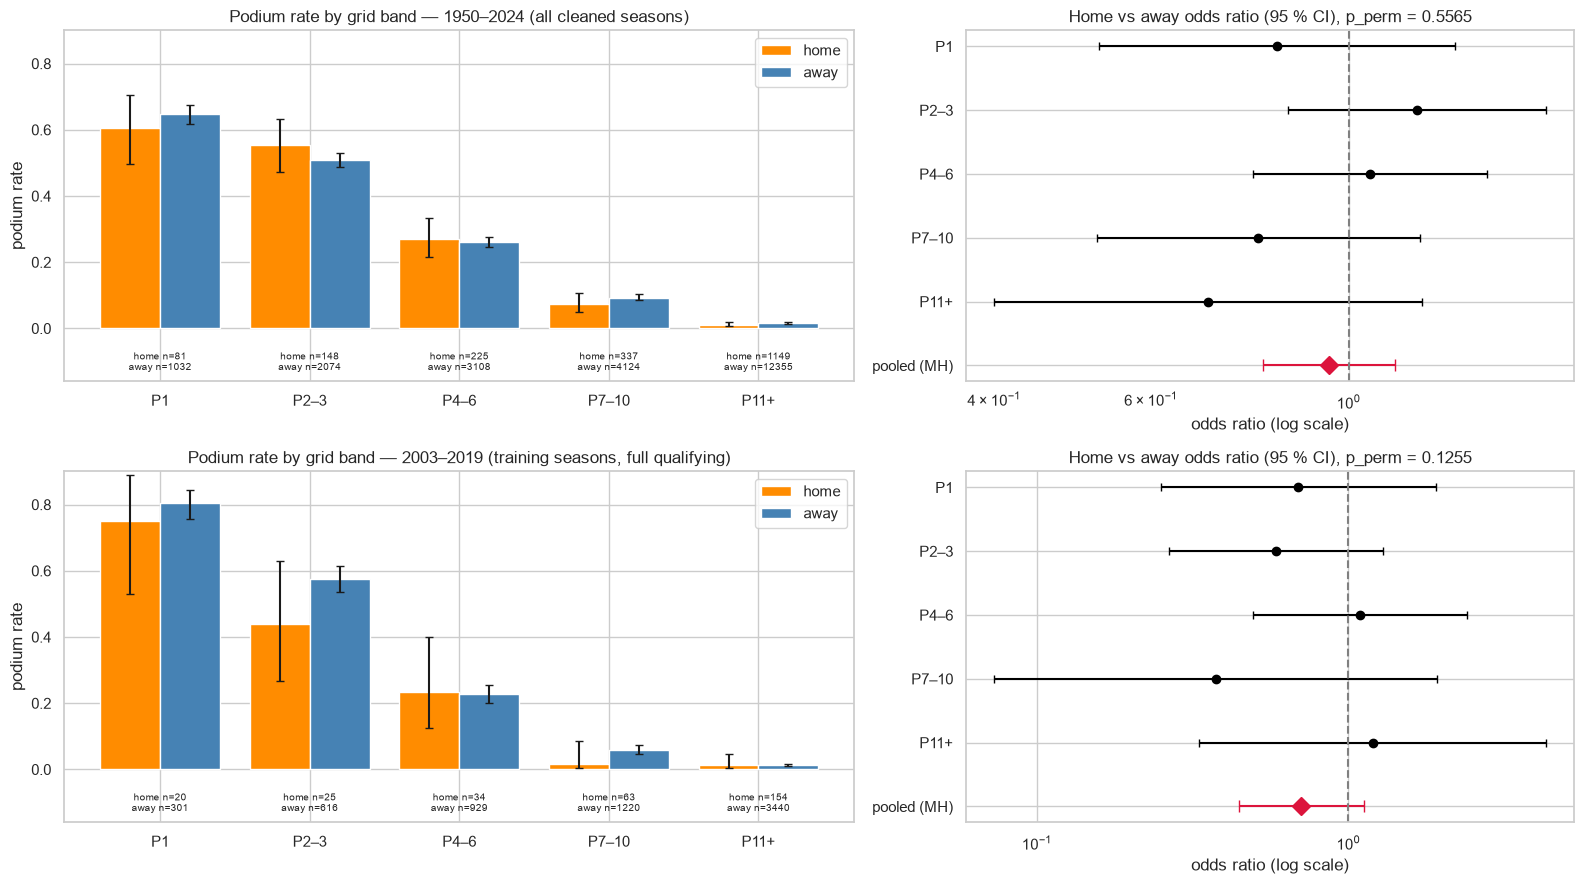

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9), gridspec_kw={'width_ratios': [1.3, 1]})
for row, (label, bt) in enumerate(bands.items()):
    ax = axes[row, 0]
    x = np.arange(len(bt))
    for off, who, col in [(-0.2, 'home', 'darkorange'), (0.2, 'away', 'steelblue')]:
        r_ = bt[f'{who}_rate']
        ax.bar(x + off, r_, width=0.4, color=col, label=who,
               yerr=[r_ - bt[f'{who}_lo'], bt[f'{who}_hi'] - r_], capsize=3)
    for xi, (nh, na) in enumerate(zip(bt['home_starts'], bt['away_starts'])):
        ax.text(xi, -0.07, f'home n={nh}\naway n={na}', ha='center', va='top', fontsize=7)
    ax.set_xticks(x, bt.index)
    ax.set(title=f'Podium rate by grid band — {label}', ylabel='podium rate', ylim=(-0.16, 0.9))
    ax.legend()

    ax = axes[row, 1]
    y = np.arange(len(bt))
    ax.errorbar(bt['odds_ratio'], y, xerr=[bt['odds_ratio'] - bt['or_lo'], bt['or_hi'] - bt['odds_ratio']],
                fmt='o', color='black', capsize=3)
    s_ = q2_summary.loc[label]
    ax.errorbar([s_['MH_OR (grid-adjusted)']], [len(bt)], fmt='D', color='crimson', markersize=9, capsize=4,
                xerr=[[s_['MH_OR (grid-adjusted)'] - s_['MH_CI_low']], [s_['MH_CI_high'] - s_['MH_OR (grid-adjusted)']]])
    ax.axvline(1, color='grey', linestyle='--')
    ax.set_xscale('log')
    ax.set_yticks(list(y) + [len(bt)], list(bt.index) + ['pooled (MH)'])
    ax.invert_yaxis()
    ax.set(title=f'Home vs away odds ratio (95 % CI), p_perm = {s_["permutation_p"]:.4f}', xlabel='odds ratio (log scale)')
plt.tight_layout()
save_fig(fig, 's3_q2_home_advantage')
plt.show()

### Q2 — Answer
**No — there is no evidence that drivers podium more often at home once starting position is controlled for.**
* **Raw comparison (misleading):** home drivers podium *less* often (11.9 % vs 13.8 %), but they also start further
  back on average (grid 12.7 vs 11.7 over all seasons) — partly the early-era local one-off entries in weak cars.
  This is exactly the confounding the brief warns about.
* **Within grid bands** the home-vs-away differences are small and point in both directions (home slightly better
  from P2–3 and P4–6, slightly worse from P1, P7–10 and P11+), all with CIs that include 1.
* **Grid-adjusted effect, 1950–2024:** Mantel–Haenszel OR = **0.95 [0.80–1.13]**, permutation p = **0.56**.
* **Modern training seasons, 2003–2019:** OR = **0.71 [0.45–1.12]**, p = **0.13** — also not significant, and if
  anything below 1 rather than above.

Limitation: home starts in the front bands are few (e.g. 20 home pole starts in 2003–2019), so a *small* home effect
cannot be ruled out — but the data give no support for a meaningful one.

**Consequence for Step 4 (training seasons only):** the 2003–2019 evidence does not support a home-race feature; it
will at most be tested in the ablation, not assumed to help.

**Grain / missingness / cutoff.** Grain: one starter in one race with a grid slot (`grid > 0`; 122 pit-lane starts
excluded because they have no comparable band). Driver and circuit country are complete after the §2.11 mapping
(0 missing). Both "home" and grid position are known **before** the start.

## 3.3 Q3 — Which constructors have the highest mechanical-retirement rate, 2014–2021 vs 2022–2024?
**Join path:** `results` ⋈ `status` (status → group, §2.5) ⋈ `constructors` (→ team lineage, §2.10) ⋈ `races` (season).

**Definitions**
* **Mechanical retirement:** status group `mechanical` — the race ended because a car component failed; crashes,
  driver causes and regulation decisions are excluded (brief's definition, mapping in §2.5).
* **Rate:** mechanical retirements ÷ race starts (all cleaned rows are starters — non-starters were removed in §2.6).
* **Team identity:** `team_lineage`, so renamed teams are compared with themselves across the two eras
  (Force India → Racing Point → Aston Martin; Toro Rosso → AlphaTauri → RB; Renault → Alpine; Sauber → Alfa Romeo →
  Sauber). Each team is labelled with its most recent name.
* **Eligibility:** ≥ 40 starts in an era. Teams have near-equal numbers of starts (two cars per race), so they are
  ranked by rate, with the CI shown to judge which differences are real.
* **Robustness:** the ranking is recomputed with a **strict** definition that drops the borderline statuses of
  §2.5 (`Tyre`, `Wheel`, `Wheel nut`, `Front wing`, `Broken wing`).

In [52]:
q3 = (base
      .merge(status[['statusId', 'status', 'status_group']], on='statusId', how='left', validate='many_to_one')
      .merge(cons[['constructorId', 'constructorRef', 'name']], on='constructorId', how='left', validate='many_to_one')
      .merge(races_t, on='raceId', how='left', validate='many_to_one'))
q3 = q3[q3['year'].between(2014, 2024)].copy()
q3['era'] = np.where(q3['year'] <= 2021, '2014–2021', '2022–2024')
q3['mechanical'] = q3['status_group'].eq('mechanical').astype(int)
STRICT_EXCLUDE = ['Tyre', 'Wheel', 'Wheel nut', 'Front wing', 'Broken wing']
q3['mechanical_strict'] = (q3['mechanical'].eq(1) & ~q3['status'].isin(STRICT_EXCLUDE)).astype(int)

latest = q3.sort_values('year').groupby('team_lineage')['name'].last()
aliases = q3.sort_values('year').groupby('team_lineage')['name'].apply(lambda s: ' / '.join(dict.fromkeys(s)))
q3['team'] = q3['team_lineage'].map(latest)

era_tot = rate_table(q3, ['era'], 'mechanical').set_index('era')
chi2, p_era, _, _ = stats.chi2_contingency(pd.crosstab(q3['era'], q3['mechanical']))
display(era_tot.round(4))
print(f'overall mechanical-retirement rate changed between eras: chi-square p = {p_era:.2g}')
print('\nmost frequent mechanical causes (share of mechanical retirements):')
display(q3[q3['mechanical'] == 1].groupby('era')['status'].value_counts(normalize=True)
          .groupby(level=0).head(5).round(3).rename('share').to_frame())

,n,k,rate,ci_low,ci_high
era,,,,,
2014–2021,3266,323,0.0989,0.0891,0.1096
2022–2024,1357,83,0.0612,0.0496,0.0752


overall mechanical-retirement rate changed between eras: chi-square p = 4.7e-05

most frequent mechanical causes (share of mechanical retirements):


share
era       status           
2014–2021 Engine      0.183
          Brakes      0.139
          Power Unit  0.108
          Gearbox     0.102
          Suspension  0.074
2022–2024 Engine      0.265
          Gearbox     0.108
          Power Unit  0.084
          Hydraulics  0.060
          Brakes      0.048

In [53]:
MIN_STARTS = 40
team_rates = rate_table(q3, ['team', 'era'], 'mechanical')
team_rates['aliases'] = team_rates['team'].map(dict(zip(latest.values, aliases.values)))

def team_ranking(era, col='mechanical'):
    t = rate_table(q3, ['team', 'era'], col)
    r = t[(t['era'] == era) & (t['n'] >= MIN_STARTS)].sort_values('rate', ascending=False).reset_index(drop=True)
    r.index = r.index + 1
    r['mechanical_rate'] = r.apply(lambda x: f"{x['rate']:.1%} [{x['ci_low']:.1%}–{x['ci_high']:.1%}]", axis=1)
    return r[['team', 'n', 'k', 'mechanical_rate']].rename(columns={'n': 'starts', 'k': 'mechanical DNFs'})

with pd.option_context('display.max_colwidth', None):
    display(pd.concat({era: team_ranking(era) for era in ['2014–2021', '2022–2024']}, axis=1))
    display(team_rates.drop_duplicates('team')[['team', 'aliases']].set_index('team'))

rho_strict = {}
for era in ['2014–2021', '2022–2024']:
    sub = q3[q3['era'] == era]
    main_ = rate_table(sub, ['team'], 'mechanical').query('n >= @MIN_STARTS').set_index('team')['rate']
    strict_ = rate_table(sub, ['team'], 'mechanical_strict').set_index('team')['rate'].reindex(main_.index)
    rho_strict[era] = stats.spearmanr(main_, strict_)[0]
print('team ranking, main vs strict mechanical definition (Spearman):', {k: round(v, 2) for k, v in rho_strict.items()})
print('strict-definition ranking:')
display(pd.concat({era: team_ranking(era, 'mechanical_strict') for era in ['2014–2021', '2022–2024']}, axis=1))

top3 = team_ranking('2014–2021')['team'].head(3).tolist() + ['Mercedes']
print('mechanical-retirement rate by season, top-3 teams of 2014–2021 and the lowest (Mercedes):')
(q3[q3['team'].isin(top3)].pivot_table(index='team', columns='year', values='mechanical', aggfunc='mean')
   .loc[top3].round(2))

2014–2021                                                   2022–2024                                           
              team starts mechanical DNFs      mechanical_rate            team starts mechanical DNFs     mechanical_rate
1   Alpine F1 Team    320              48  15.0% [11.5%–19.3%]  Alpine F1 Team  136.0            15.0  11.0% [6.8%–17.4%]
2       RB F1 Team    320              47  14.7% [11.2%–19.0%]          Sauber  136.0            12.0   8.8% [5.1%–14.8%]
3          McLaren    320              46  14.4% [11.0%–18.6%]      RB F1 Team  136.0             9.0   6.6% [3.5%–12.1%]
4         Red Bull    320              34   10.6% [7.7%–14.5%]         Ferrari  136.0             9.0   6.6% [3.5%–12.1%]
5     Haas F1 Team    244              23    9.4% [6.4%–13.7%]        Williams  135.0             8.0   5.9% [3.0%–11.3%]
6           Sauber    320              28    8.8% [6.1%–12.4%]    Aston Martin  135.0             7.0   5.2% [2.5%–10.3%]
7         Williams    319              24    7.5% [5.1%–11.0%]    Haas F1 Team  135.0             7.0   5.2% [2.5%–10.3%]
8   Manor Marussia    109               8    7.3% [3.8%–13.8%]        Mercedes  136.0             6.0    4.4% [2.0%–9.3%]
9     Aston Martin    320              22    6.9% [4.6%–10.2%]         McLaren  136.0             5.0    3.7% [1.6%–8.3%]
10         Ferrari    320              22    6.9% [4.6%–10.2%]        Red Bull  136.0             5.0    3.7% [1.6%–8.3%]
11        Mercedes    320              13     4.1% [2.4%–6.8%]             NaN    NaN             NaN                 NaN

,aliases
team,
Alpine F1 Team,Lotus F1 / Renault / Alpine F1 Team
Aston Martin,Force India / Racing Point / Aston Martin
Caterham,Caterham
Ferrari,Ferrari
Haas F1 Team,Haas F1 Team
Manor Marussia,Marussia / Manor Marussia
McLaren,McLaren
Mercedes,Mercedes
RB F1 Team,Toro Rosso / AlphaTauri / RB F1 Team


team ranking, main vs strict mechanical definition (Spearman): {'2014–2021': np.float64(0.97), '2022–2024': np.float64(1.0)}
strict-definition ranking:


2014–2021                                                   2022–2024                                           
              team starts mechanical DNFs      mechanical_rate            team starts mechanical DNFs     mechanical_rate
1       RB F1 Team    320              47  14.7% [11.2%–19.0%]  Alpine F1 Team  136.0            15.0  11.0% [6.8%–17.4%]
2   Alpine F1 Team    320              45  14.1% [10.7%–18.3%]          Sauber  136.0            12.0   8.8% [5.1%–14.8%]
3          McLaren    320              44  13.8% [10.4%–18.0%]      RB F1 Team  136.0             9.0   6.6% [3.5%–12.1%]
4         Red Bull    320              34   10.6% [7.7%–14.5%]         Ferrari  136.0             9.0   6.6% [3.5%–12.1%]
5           Sauber    320              26    8.1% [5.6%–11.6%]        Williams  135.0             8.0   5.9% [3.0%–11.3%]
6     Haas F1 Team    244              18    7.4% [4.7%–11.4%]    Aston Martin  135.0             7.0   5.2% [2.5%–10.3%]
7   Manor Marussia    109               8    7.3% [3.8%–13.8%]    Haas F1 Team  135.0             6.0    4.4% [2.1%–9.4%]
8         Williams    319              23    7.2% [4.9%–10.6%]        Mercedes  136.0             6.0    4.4% [2.0%–9.3%]
9     Aston Martin    320              21     6.6% [4.3%–9.8%]         McLaren  136.0             5.0    3.7% [1.6%–8.3%]
10         Ferrari    320              17     5.3% [3.3%–8.3%]        Red Bull  136.0             5.0    3.7% [1.6%–8.3%]
11        Mercedes    320              12     3.8% [2.2%–6.4%]             NaN    NaN             NaN                 NaN

mechanical-retirement rate by season, top-3 teams of 2014–2021 and the lowest (Mercedes):


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
team,,,,,,,,,,,
Alpine F1 Team,0.24,0.16,0.12,0.30,0.10,0.07,0.15,0.09,0.16,0.09,0.08
RB F1 Team,0.24,0.24,0.12,0.18,0.17,0.05,0.09,0.11,0.11,0.05,0.04
McLaren,0.05,0.21,0.19,0.30,0.17,0.14,0.06,0.02,0.07,0.05,0.00
Mercedes,0.11,0.05,0.02,0.02,0.05,0.02,0.03,0.02,0.02,0.07,0.04


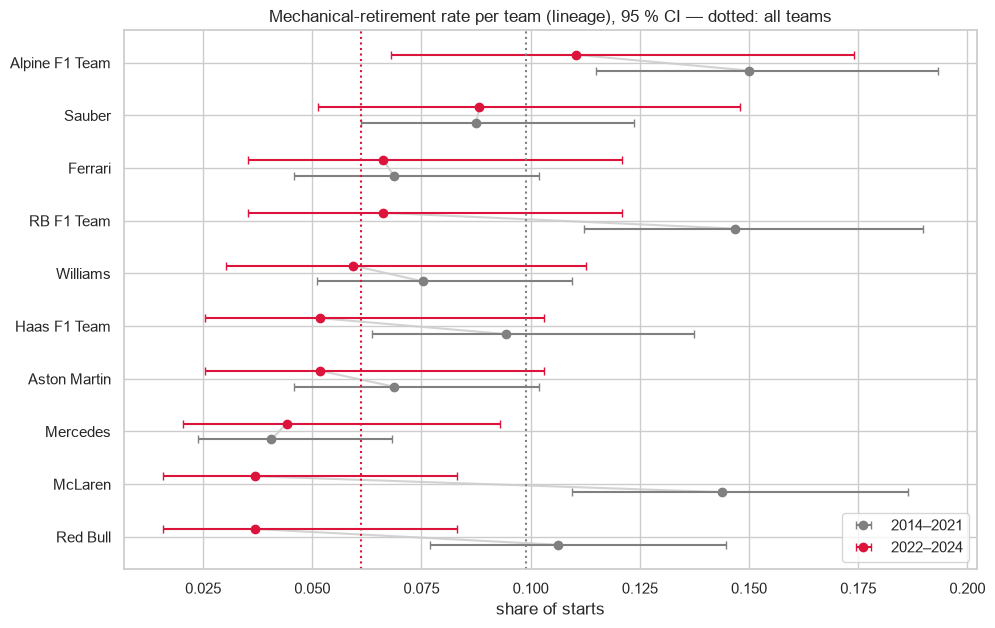

In [54]:
tw = team_rates.pivot(index='team', columns='era', values=['n', 'rate', 'ci_low', 'ci_high'])
tw = tw[(tw[('n', '2014–2021')] >= MIN_STARTS) & (tw[('n', '2022–2024')] >= MIN_STARTS)]
order_t = tw[('rate', '2022–2024')].sort_values().index
fig, ax = plt.subplots(figsize=(11, 0.55 * len(tw) + 1.5))
for off, era, col in [(-0.15, '2014–2021', 'grey'), (0.15, '2022–2024', 'crimson')]:
    y = np.arange(len(order_t)) + off
    r_ = tw.loc[order_t, ('rate', era)]
    ax.errorbar(r_, y, xerr=[r_ - tw.loc[order_t, ('ci_low', era)], tw.loc[order_t, ('ci_high', era)] - r_],
                fmt='o', color=col, capsize=3, label=era)
for i, t_ in enumerate(order_t):
    ax.plot([tw.loc[t_, ('rate', '2014–2021')], tw.loc[t_, ('rate', '2022–2024')]], [i - 0.15, i + 0.15],
            color='lightgrey', zorder=0)
ax.set_yticks(np.arange(len(order_t)), order_t)
ax.axvline(era_tot.loc['2014–2021', 'rate'], color='grey', linestyle=':')
ax.axvline(era_tot.loc['2022–2024', 'rate'], color='crimson', linestyle=':')
ax.set(title='Mechanical-retirement rate per team (lineage), 95 % CI — dotted: all teams', xlabel='share of starts')
ax.legend(loc='lower right')
save_fig(fig, 's3_q3_mechanical_rate')
plt.show()

### Q3 — Answer
**Overall:** mechanical failures ended **9.9 %** of starts in 2014–2021 and **6.1 %** in 2022–2024 (chi-square
p ≈ 5·10⁻⁵) — the cars became markedly more reliable under the new rules. Engines / power units stay the most common
failure in both eras.

**Highest mechanical-retirement rates**
* **2014–2021:** **Alpine lineage (Lotus F1 / Renault) 15.0 %**, RB lineage (Toro Rosso / AlphaTauri) 14.7 %,
  **McLaren 14.4 %** — McLaren's rate peaks at 19–30 % in 2015–2017 (season table above) and falls to 2 % by 2021.
  Lowest: **Mercedes 4.1 %**.
* **2022–2024:** **Alpine 11.0 %**, Sauber (Alfa Romeo) 8.8 %, RB and Ferrari 6.6 %. Lowest: McLaren and Red Bull
  3.7 %.

**What changed:** Alpine is the least reliable team in *both* eras. The biggest improvements are McLaren
(14.4 % → 3.7 %), RB (14.7 % → 6.6 %) and Red Bull (10.6 % → 3.7 %); Mercedes stays low. With ≈ 136 starts per team in
2022–2024 (≈ 5–15 failures), most 2022–24 intervals overlap — only Alpine stands out from the low-failure teams.

**Robustness:** the strict definition (dropping tyre / wheel / wing statuses) gives practically the same ranking
(ρ = 0.97 for 2014–21, 1.00 for 2022–24), so the conclusions do not depend on the borderline mapping decisions.
Caterham (2014 only) has < 40 starts and is not ranked; Manor Marussia exists only in 2014–16.

**Grain / missingness / cutoff.** Grain: one race start (driver × race) in 2014–2024, 4,623 rows; status is complete
(0 missing). Status is **post-race** information — fine for this descriptive question but never a same-race feature.
A team's mechanical-failure rate over *previous* races is pre-race information and is a candidate reliability
feature for Step 4 (computed from past races only).

## 3.4 Section 3 summary
| Question | Answer | Feeds into |
|---|---|---|
| Q1 front row → podium | 68 % → 76 % after 2014; circuit ranking reshuffled (ρ = 0.21); Monaco consistently high; grid matters more than qualifying when they differ | grid + qualifying features, era feature, circuit history (Step 4) |
| Q2 home advantage | none after controlling for grid (OR 0.95, p = 0.56; 2003–19: 0.71, p = 0.13) | home-race feature not supported — ablation only |
| Q3 mechanical DNFs | 9.9 % → 6.1 %; Alpine highest in both eras; McLaren, RB, Red Bull improved most | past-reliability feature, era sensitivity (Steps 4–6) |

# 4. Leakage-Safe Feature Engineering
**Goal:** one row per driver per race with the podium target and features that are all **known before the start**.

**Rules applied to every feature**
1. **Past races only.** Anything describing the past (form, standings, experience, circuit history, ratings) uses
   races with an **earlier date** than the current one (`race_seq`, built from the race date — §2.9 showed the same
   circuit can host two races in one season, so ordering by year would leak).
2. **Same-weekend information** is used only if it exists before lights out: the driver's own grid and qualifying,
   and *other drivers'* qualifying in the same race (all qualifying is finished before the race).
3. **Computed on the full history (1950–2024)** so that early-window rows have their past (2003 form needs 2002).
   The modeling window is decided in Step 5.
4. **No imputation here.** Missing values stay NaN (plus indicator flags where the gap is meaningful); imputation is
   fitted on the training set in Step 5 as part of the preprocessing-order experiments.
5. **Evidence uses training seasons only.** Every number or plot used to *choose* a feature is computed on
   **2003–2019**: training seasons (≤ 2019, the split given in the F1 primer) in which every feature group, including
   qualifying, is defined (§1.8.2). Validation (2020–21) and test (≥ 2022) seasons never influence a feature decision.
6. **Proven, not asserted:** a *time-travel test* (§4.5) deletes all future data and checks that every feature is
   unchanged.

| Group (ablation unit, Step 7) | Features |
|---|---|
| grid | starting slot, slot relative to field, pit-lane flag |
| qualifying | position, gap to pole (s, %), grid penalty, team pace this weekend, gap to teammate |
| standings | driver / constructor championship position, points share of leader, wins — **before** this race |
| driver_form | last-N podium rate, mean finish, DNF rate |
| constructor_form | last-N podium rate, best finish, mechanical-failure rate (team lineage) |
| experience | career starts, age, rookie season, team starts |
| circuit_history | driver's and team's past results at this circuit |
| ratings | Elo ratings of driver and team before the race |
| race_context | ranks within today's field, strong cars ahead, grid-slot prior at this circuit, circuit overtaking difficulty |
| era | field size, season, years since the last major rule change |
| *candidates* | home race (Q2: no effect → ablation only), past pit-stop performance (tested in §4.4) |

## 4.1 Feature pipeline
All features are produced by one function, `build_features`, so that exactly the same code can be re-run on
truncated data in the leakage test. Main building blocks:
* `past_rolling` — mean of the previous *N* rows of a group (`shift(1)` excludes the current race), or an
  exponentially weighted mean;
* a **team–race table** (one row per team per race) for constructor-level form, Elo and circuit history, keyed on
  `team_lineage` so that history survives renames (§2.10);
* **standings before the race** = the official standings after the **previous race in the calendar**; for a season
  opener that is the previous season's final table (flag `season_opener`);
* **Elo ratings**: every race is a set of pairwise duels (who finished ahead). Before the race each competitor's rating
  is stored as the feature; afterwards ratings are updated (K = 32, rating regressed 20 % towards 1500 at each new
  season). Driver Elo **ignores mechanical retirements** (a failed engine says nothing about the driver); team Elo uses
  the team's best car and counts everything (reliability is part of a team's strength).

In [55]:
from sklearn.metrics import roc_auc_score, average_precision_score

REG_CHANGES = [1950, 1958, 1966, 1977, 1989, 1995, 2009, 2014, 2022]     # era starts (F1 primer)
OUTCOME_COLS = ['positionOrder', 'podium', 'status_group']               # post-race columns used for *past* races only

def past_rolling(df, key, col, n):
    """Mean of `col` over the previous n rows of each `key` group; the current row is excluded by shift(1)."""
    g = df.groupby(key, sort=False)[col]
    if n == 'ewm':
        return g.transform(lambda s: s.shift(1).ewm(halflife=5, min_periods=1).mean())
    return g.transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())

def past_expanding(df, key, col):
    return df.groupby(key, sort=False)[col].transform(lambda s: s.shift(1).expanding().mean())

def prepare(res, races):
    df = res[['raceId', 'driverId', 'constructorId', 'team_lineage', 'circuitId', 'year', 'date', 'grid',
              'pit_lane_start', 'quali_pos', 'best_q_s', 'gap_to_pole_s', 'gap_to_pole_pct', 'has_quali', 'dob',
              'driver_country', 'circuit_country'] + OUTCOME_COLS].copy()
    order = races.sort_values('date')[['raceId', 'year']].reset_index(drop=True)
    order['race_seq'] = np.arange(len(order))
    order['prev_raceId'] = order['raceId'].shift(1).fillna(-1).astype(int)
    order['season_opener'] = order['year'].ne(order['year'].shift(1))
    df = df.merge(order.drop(columns='year'), on='raceId', how='left', validate='many_to_one')
    df = df.sort_values(['race_seq', 'driverId'], kind='stable').reset_index(drop=True)
    df['is_dnf'] = df['status_group'].ne('finished').astype(float).where(df['status_group'].notna())
    df['is_mech'] = df['status_group'].eq('mechanical').astype(float).where(df['status_group'].notna())
    df['field_size'] = df.groupby('raceId')['driverId'].transform('size')
    back = np.maximum(df.groupby('raceId')['grid'].transform('max'), df['field_size']) + 1
    df['grid_f'] = df['grid'].where(df['grid'] > 0, back)          # pit-lane start = behind the last slot
    return df

def team_table(df):
    return (df.groupby(['raceId', 'race_seq', 'year', 'circuitId', 'team_lineage'], sort=False)
              .agg(team_podium=('podium', 'mean'), team_best=('positionOrder', 'min'), team_mech=('is_mech', 'mean'))
              .reset_index().sort_values(['race_seq', 'team_lineage'], kind='stable').reset_index(drop=True))

def form_block(df, t, n):
    out = pd.DataFrame(index=df.index)
    out['drv_form_podium'] = past_rolling(df, 'driverId', 'podium', n)
    out['drv_form_finish'] = past_rolling(df, 'driverId', 'positionOrder', n)
    out['drv_form_dnf'] = past_rolling(df, 'driverId', 'is_dnf', n)
    out['drv_form_n'] = df.groupby('driverId').cumcount().clip(upper=10 if n == 'ewm' else n)
    tt = t[['raceId', 'team_lineage']].copy()
    tt['con_form_podium'] = past_rolling(t, 'team_lineage', 'team_podium', n)
    tt['con_form_best'] = past_rolling(t, 'team_lineage', 'team_best', n)
    tt['con_form_mech'] = past_rolling(t, 'team_lineage', 'team_mech', n)
    merged = df[['raceId', 'team_lineage']].merge(tt, on=['raceId', 'team_lineage'], how='left', validate='many_to_one')
    return out.join(merged.drop(columns=['raceId', 'team_lineage']))

def elo(frame, key, pos_col, include=None, k=32, carry=0.8):
    """Pre-race multi-competitor Elo: every pair in a race is a duel decided by finishing order."""
    frame = frame.reset_index(drop=True)
    inc = np.ones(len(frame), bool) if include is None else np.asarray(include, bool)
    keys, years, pos_all = frame[key].to_numpy(), frame['year'].to_numpy(), frame[pos_col].to_numpy(float)
    ratings, season, pre = {}, {}, np.full(len(frame), np.nan)
    groups = frame.groupby('race_seq').indices
    for s in sorted(groups):
        idx = groups[s]
        ids, yr = keys[idx], years[idx[0]]
        r = np.empty(len(idx))
        for j, i_ in enumerate(ids):
            v = ratings.get(i_, 1500.0)
            if season.get(i_, yr) != yr:
                v = 1500 + carry * (v - 1500)
            season[i_], r[j] = yr, v
        pre[idx] = r
        pos = pos_all[idx]
        ok = ~np.isnan(pos) & inc[idx]
        if ok.sum() >= 2:
            rv, pv = r[ok], pos[ok]
            E = 1 / (1 + 10 ** ((rv[None, :] - rv[:, None]) / 400))
            S = (pv[:, None] < pv[None, :]) + 0.5 * (pv[:, None] == pv[None, :])
            np.fill_diagonal(E, 0)
            np.fill_diagonal(S, 0)
            r = r.copy()
            r[ok] = rv + k / (ok.sum() - 1) * (S - E).sum(axis=1)
        for j, i_ in enumerate(ids):
            ratings[i_] = r[j]
    return pre

def prior_counts(df, keys):
    """Podium successes / trials for `keys` over all *previous* races (current race excluded)."""
    t = (df.groupby(['race_seq'] + keys)['podium'].agg(k='sum', n='count').reset_index()
           .sort_values('race_seq', kind='stable'))
    g = t.groupby(keys, sort=False)
    t['k_prev'] = g['k'].transform(lambda s: s.shift(1, fill_value=0).cumsum())
    t['n_prev'] = g['n'].transform(lambda s: s.shift(1, fill_value=0).cumsum())
    return t

In [56]:
def build_features(res, races, drv_st, con_st, pits, form_n):
    df = prepare(res, races)
    t = team_table(df)
    F = df[['raceId', 'driverId', 'constructorId', 'team_lineage', 'circuitId', 'year', 'date', 'race_seq']].copy()
    F['podium'] = df['podium']

    # --- grid --------------------------------------------------------------------------------------------
    F['grid_f'] = df['grid_f']
    F['grid_pct'] = df['grid_f'] / df['field_size']
    F['pit_lane_start'] = df['pit_lane_start'].astype(int)

    # --- qualifying (this weekend, finished before the race) --------------------------------------------
    F['quali_pos'] = df['quali_pos']
    F['gap_to_pole_s'] = df['gap_to_pole_s']
    F['gap_to_pole_pct'] = df['gap_to_pole_pct']
    F['has_quali'] = df['has_quali'].astype(int)
    F['grid_penalty'] = df['grid_f'] - df['quali_pos']
    F['team_best_gap_pct'] = df.groupby(['raceId', 'constructorId'])['gap_to_pole_pct'].transform('min')
    grp_keys = [df['raceId'], df['constructorId']]
    rank_in_team = df.groupby(grp_keys)['best_q_s'].rank(method='first')
    first = df.groupby(grp_keys)['best_q_s'].transform('min')
    second = df['best_q_s'].where(rank_in_team == 2).groupby(grp_keys).transform('max')
    other = np.where(df['best_q_s'] == first, second, first)
    F['teammate_gap_pct'] = 100 * (df['best_q_s'] / other - 1)

    # --- standings before the race -------------------------------------------------------------------------
    F['season_opener'] = df['season_opener'].astype(int)
    ds = drv_st[['raceId', 'driverId', 'points', 'position', 'wins']].rename(columns={'raceId': 'prev_raceId'})
    ds['share'] = (ds['points'] / ds.groupby('prev_raceId')['points'].transform('max')).fillna(0)
    m = df[['prev_raceId', 'driverId']].merge(ds, on=['prev_raceId', 'driverId'], how='left', validate='many_to_one')
    has_tab = df['prev_raceId'].isin(ds['prev_raceId'])
    last_pos = df['prev_raceId'].map(ds.groupby('prev_raceId')['position'].max())
    F['drv_champ_pos'] = m['position'].fillna(last_pos + 1).where(has_tab)
    F['drv_points_share'] = m['share'].fillna(0).where(has_tab)
    F['drv_wins'] = m['wins'].fillna(0).where(has_tab)

    lin_map = df[['constructorId', 'year', 'team_lineage']].drop_duplicates(['constructorId', 'year'])
    cs = (con_st[['raceId', 'constructorId', 'points', 'position']]
          .merge(races[['raceId', 'year']], on='raceId').merge(lin_map, on=['constructorId', 'year'], how='inner')
          .groupby(['raceId', 'team_lineage']).agg(points=('points', 'max'), position=('position', 'min')).reset_index()
          .rename(columns={'raceId': 'prev_raceId'}))
    cs['share'] = (cs['points'] / cs.groupby('prev_raceId')['points'].transform('max')).fillna(0)
    m = df[['prev_raceId', 'team_lineage']].merge(cs, on=['prev_raceId', 'team_lineage'], how='left', validate='many_to_one')
    has_tab = df['prev_raceId'].isin(cs['prev_raceId'])
    last_pos = df['prev_raceId'].map(cs.groupby('prev_raceId')['position'].max())
    F['con_champ_pos'] = m['position'].fillna(last_pos + 1).where(has_tab)
    F['con_points_share'] = m['share'].fillna(0).where(has_tab)

    # --- driver & constructor form ------------------------------------------------------------------------
    F = F.join(form_block(df, t, form_n))

    # --- experience -----------------------------------------------------------------------------------------
    F['drv_starts'] = df.groupby('driverId').cumcount()
    F['drv_age'] = (df['date'] - df['dob']).dt.days / 365.25
    F['rookie_season'] = (df['year'] == df.groupby('driverId')['year'].transform('min')).astype(int)
    t['team_starts'] = t.groupby('team_lineage').cumcount()

    # --- circuit history -------------------------------------------------------------------------------------
    F['drv_circuit_starts'] = df.groupby(['driverId', 'circuitId']).cumcount()
    F['drv_circuit_podium'] = past_expanding(df, ['driverId', 'circuitId'], 'podium')
    t['team_circuit_podium'] = past_expanding(t, ['team_lineage', 'circuitId'], 'team_podium')

    # --- ratings (Elo, stored before each race) -------------------------------------------------------------
    F['drv_elo'] = elo(df[['race_seq', 'year', 'driverId', 'positionOrder']], 'driverId', 'positionOrder',
                       include=df['status_group'].ne('mechanical'))
    t['team_elo'] = elo(t[['race_seq', 'year', 'team_lineage', 'team_best']], 'team_lineage', 'team_best')

    # --- pit-stop candidate: team's pit loss vs race median over previous races (2011+) --------------------
    p = pits.merge(df[['raceId', 'driverId', 'team_lineage']], on=['raceId', 'driverId'], how='inner')
    p['rel'] = p['duration_s'] - p.groupby('raceId')['duration_s'].transform('median')
    p = p[p['rel'].abs() <= 10]                         # drop red-flag stops, stop-go penalties, failures
    t = t.merge(p.groupby(['raceId', 'team_lineage'])['rel'].mean().rename('pit_rel').reset_index(),
                on=['raceId', 'team_lineage'], how='left')
    t['team_pit_loss_rel'] = past_rolling(t, 'team_lineage', 'pit_rel', form_n)

    team_cols = ['team_starts', 'team_circuit_podium', 'team_elo', 'team_pit_loss_rel']
    m = df[['raceId', 'team_lineage']].merge(t[['raceId', 'team_lineage'] + team_cols],
                                             on=['raceId', 'team_lineage'], how='left', validate='many_to_one')
    for c in team_cols:
        F[c] = m[c].to_numpy()

    # --- race context: ranks within today's field, rivals ahead, circuit priors -------------------------------
    for col, asc in [('drv_form_podium', False), ('drv_form_finish', True), ('con_form_podium', False),
                     ('drv_elo', False), ('team_elo', False)]:
        F[f'{col}_rank'] = F.groupby('raceId')[col].rank(ascending=asc, method='average')
    strong = F.loc[F['drv_elo_rank'] <= 3, ['raceId', 'driverId', 'grid_f']]
    pairs = F[['raceId', 'driverId', 'grid_f']].reset_index().merge(strong, on='raceId', suffixes=('', '_s'))
    ahead = pairs[(pairs['driverId_s'] != pairs['driverId']) & (pairs['grid_f_s'] < pairs['grid_f'])]
    F['strong_cars_ahead'] = ahead.groupby('index').size().reindex(F.index, fill_value=0)

    df['gslot'] = df['grid_f'].clip(upper=21)
    glob = prior_counts(df, ['gslot'])
    glob['p_slot'] = glob['k_prev'] / glob['n_prev'].replace(0, np.nan)
    circ = prior_counts(df, ['circuitId', 'gslot']).merge(glob[['race_seq', 'gslot', 'p_slot']], on=['race_seq', 'gslot'])
    M = 5                                               # shrinkage strength (pseudo-races)
    circ['circuit_grid_prior'] = (circ['k_prev'] + M * circ['p_slot']) / (circ['n_prev'] + M)
    m = df[['race_seq', 'circuitId', 'gslot']].merge(circ[['race_seq', 'circuitId', 'gslot', 'circuit_grid_prior']],
                                                     on=['race_seq', 'circuitId', 'gslot'], how='left', validate='many_to_one')
    F['circuit_grid_prior'] = m['circuit_grid_prior'].to_numpy()

    fin = df[df['status_group'].eq('finished') & (df['grid'] > 0)]
    race_shuffle = (fin.assign(d=(fin['grid'] - fin['positionOrder']).abs())
                       .groupby('raceId')['d'].mean().rename('shuffle'))
    rc = df[['raceId', 'race_seq', 'circuitId']].drop_duplicates('raceId').sort_values('race_seq')
    rc['shuffle'] = rc['raceId'].map(race_shuffle)
    rc['circuit_overtaking'] = past_expanding(rc, 'circuitId', 'shuffle')
    F['circuit_overtaking'] = df['raceId'].map(rc.set_index('raceId')['circuit_overtaking']).to_numpy()

    # --- era ---------------------------------------------------------------------------------------------------
    F['field_size'] = df['field_size']
    F['season'] = df['year']
    F['years_since_reg_change'] = df['year'] - df['year'].map(lambda y: max(c for c in REG_CHANGES if c <= y))

    # --- home race (candidate) ----------------------------------------------------------------------------------
    F['home_race'] = df['driver_country'].eq(df['circuit_country']).astype(int)
    return F

## 4.2 Form window N — experiment
"Form" = performance over the previous **N** races. Small N reacts quickly to genuine change (upgrades, team
switches) but is noisy; large N is stable but slow. Four variants are compared — N = 3, 5, 10 and an exponentially
weighted mean (every past race counts, weight halves every 5 races) — by the **single-feature ROC-AUC** of the form
features on the evidence seasons (2003–2019). The best mean AUC sets N for all form features.

,drv_form_podium,drv_form_finish,drv_form_dnf,con_form_podium,con_form_best,con_form_mech,mean_AUC
N,,,,,,,
3,0.8233,0.8443,0.6015,0.8601,0.8812,0.5848,0.7659
5,0.8562,0.8650,0.6291,0.8744,0.8856,0.6176,0.7880
10,0.8752,0.8762,0.6654,0.8821,0.8854,0.6648,0.8082
ewm,0.8911,0.8843,0.6830,0.8941,0.8917,0.6730,0.8195


chosen form window: N = ewm


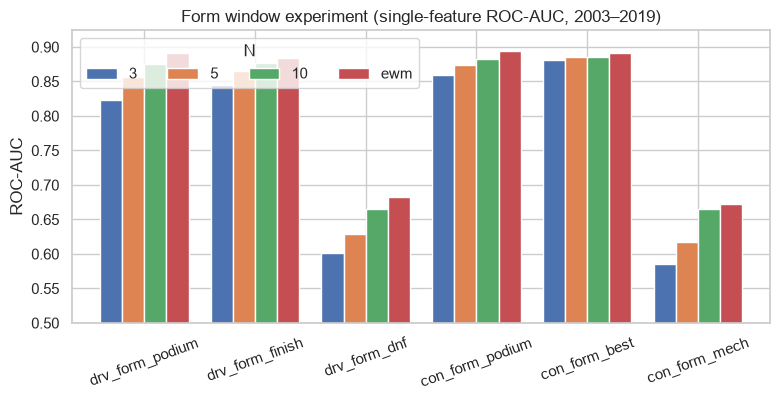

In [57]:
drv_st, con_st = clean['driver_standings'], clean['constructor_standings']
pits_in = clean['pit_stops'][['raceId', 'driverId', 'duration_s']]
EV = (1, 2003, 2019)                                   # evidence seasons: training seasons with full qualifying data

def auc_dir(y, x):
    """Direction-free single-feature ROC-AUC on rows where the feature exists."""
    m_ = x.notna()
    if m_.sum() < 50 or y[m_].nunique() < 2:
        return np.nan, '', m_.mean()
    a = roc_auc_score(y[m_], x[m_])
    return max(a, 1 - a), '+' if a >= 0.5 else '−', m_.mean()

base_df = prepare(results_clean, clean['races'])
base_t = team_table(base_df)
ev_mask = base_df['year'].between(EV[1], EV[2])
rows = []
for n in [3, 5, 10, 'ewm']:
    fb = form_block(base_df, base_t, n)
    r_ = {'N': str(n)}
    for c in ['drv_form_podium', 'drv_form_finish', 'drv_form_dnf', 'con_form_podium', 'con_form_best', 'con_form_mech']:
        r_[c] = auc_dir(base_df.loc[ev_mask, 'podium'], fb.loc[ev_mask, c])[0]
    rows.append(r_)
form_exp = pd.DataFrame(rows).set_index('N')
form_exp['mean_AUC'] = form_exp.mean(axis=1)
display(form_exp.round(4))
FORM_N = form_exp['mean_AUC'].idxmax()
FORM_N = FORM_N if FORM_N == 'ewm' else int(FORM_N)
print(f'chosen form window: N = {FORM_N}')

fig, ax = plt.subplots(figsize=(9, 3.8))
form_exp.drop(columns='mean_AUC').T.plot(kind='bar', ax=ax, width=0.8)
ax.set(title='Form window experiment (single-feature ROC-AUC, 2003–2019)', ylabel='ROC-AUC',
       ylim=(0.5, form_exp.drop(columns='mean_AUC').max().max() + 0.03))
ax.legend(title='N', ncol=4)
plt.xticks(rotation=20)
save_fig(fig, 's4_form_window_experiment')
plt.show()

**Result: longer memory wins.** The AUC of every form feature rises from N = 3 to 5 to 10, and the exponentially
weighted mean (EWM, half-life 5 races) is best for **all six** form features (mean AUC 0.820 vs 0.808 for N = 10 and
0.766 for N = 3). In F1, driver and especially car strength persist over many races, so a short window mostly adds
noise (one crash or safety car swings it), while the EWM keeps long memory *and* still lets recent races count more
(a new upgrade or team switch shows up within a few races). **All form features therefore use the EWM.**

## 4.3 Build the feature table

In [58]:
features = build_features(results_clean, clean['races'], drv_st, con_st, pits_in, FORM_N)

FEATURE_GROUPS = {
    'grid': ['grid_f', 'grid_pct', 'pit_lane_start'],
    'qualifying': ['quali_pos', 'gap_to_pole_s', 'gap_to_pole_pct', 'has_quali', 'grid_penalty',
                   'team_best_gap_pct', 'teammate_gap_pct'],
    'standings': ['drv_champ_pos', 'drv_points_share', 'drv_wins', 'con_champ_pos', 'con_points_share', 'season_opener'],
    'driver_form': ['drv_form_podium', 'drv_form_finish', 'drv_form_dnf', 'drv_form_n'],
    'constructor_form': ['con_form_podium', 'con_form_best', 'con_form_mech'],
    'experience': ['drv_starts', 'drv_age', 'rookie_season', 'team_starts'],
    'circuit_history': ['drv_circuit_starts', 'drv_circuit_podium', 'team_circuit_podium'],
    'ratings': ['drv_elo', 'team_elo'],
    'race_context': ['drv_form_podium_rank', 'drv_form_finish_rank', 'con_form_podium_rank', 'drv_elo_rank',
                     'team_elo_rank', 'strong_cars_ahead', 'circuit_grid_prior', 'circuit_overtaking'],
    'era': ['field_size', 'season', 'years_since_reg_change'],
}
CANDIDATES = {'home': ['home_race'], 'pit_stops': ['team_pit_loss_rel']}
all_feats = [f for g in list(FEATURE_GROUPS.values()) + list(CANDIDATES.values()) for f in g]
assert len(all_feats) == len(set(all_feats)) and set(all_feats) <= set(features.columns)
assert len(features) == len(results_clean) and not features.duplicated(['raceId', 'driverId']).any()
print(f'features: {features.shape[0]:,} rows, {len(all_feats)} candidate features in '
      f'{len(FEATURE_GROUPS)} groups + {len(CANDIDATES)} candidate groups')
features[features['year'] == 2019].sort_values(['race_seq', 'grid_f']).head(6)[
    ['year', 'driverId', 'grid_f', 'quali_pos', 'gap_to_pole_pct', 'teammate_gap_pct', 'drv_champ_pos',
     'drv_form_podium', 'con_form_podium', 'drv_elo', 'team_elo', 'strong_cars_ahead', 'circuit_grid_prior', 'podium']]

features: 24,755 rows, 45 candidate features in 10 groups + 2 candidate groups


,year,driverId,grid_f,quali_pos,gap_to_pole_pct,teammate_gap_pct,drv_champ_pos,drv_form_podium,con_form_podium,drv_elo,team_elo,strong_cars_ahead,circuit_grid_prior,podium
22198,2019,1,1,1.0,0.000000,-0.138961,1.0,0.829573,0.569842,1777.380575,1765.127437,0,0.647208,1
22206,2019,822,2,2.0,0.139155,0.139155,5.0,0.307222,0.569842,1691.342501,1765.127437,1,0.561042,1
22201,2019,20,3,3.0,0.874686,-0.309423,2.0,0.565102,0.553445,1714.045737,1728.153696,1,0.402663,0
22209,2019,830,4,4.0,1.036205,-2.047699,4.0,0.692304,0.369785,1666.852730,1693.762231,2,0.311632,1
22214,2019,844,5,5.0,1.187784,0.310383,13.0,0.000000,0.553445,1491.473999,1728.153696,2,0.260656,0
22202,2019,154,6,6.0,1.664886,-0.332525,14.0,0.000008,0.000000,1458.439678,1449.914348,2,0.320918,0


## 4.4 Pit-stop candidate — does past pit performance add anything?
The **current** race's pit stops are post-race data (leakage). A team's pit performance in **previous** races is
pre-race. Raw `duration` is pit-lane time (entry → exit), dominated by each circuit's pit-lane length, and includes
red-flag stops of many minutes (§1.3: 517 stops > 60 s). The candidate therefore uses each stop **relative to that
race's median stop**, drops stops more than 10 s from the median (red flags, stop-go penalties, failures), averages
per team and race, and takes the mean over the team's previous N races. Data exist only from 2011.

**Decision rule, fixed before looking at the result:** keep it only if it improves PR-AUC by ≥ 0.005 over a small
model that already contains grid, team pace and team strength — otherwise it only repeats what those features
already say. Fit on 2011–2017, evaluate on 2018–2019 (both inside the training seasons).

single-feature ROC-AUC (2011–2019): 0.778 (direction −), coverage 99.3%


,ROC-AUC,PR-AUC
model,,
core features,0.9397,0.7059
core + pit loss,0.9390,0.6817


PR-AUC gain from pit feature: -0.0242 -> EXCLUDE (rule: >= +0.005)


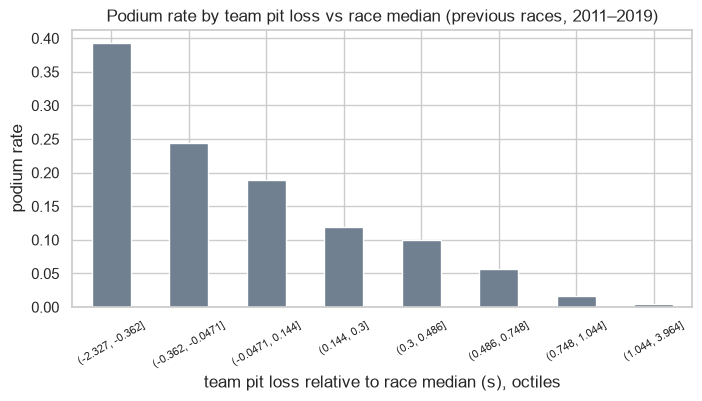

In [59]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

pit_ev = features[features['year'].between(2011, 2019)]
a_, d_, cov_ = auc_dir(pit_ev['podium'], pit_ev['team_pit_loss_rel'])
print(f'single-feature ROC-AUC (2011–2019): {a_:.3f} (direction {d_}), coverage {cov_:.1%}')

core = ['grid_f', 'team_best_gap_pct', 'con_form_podium', 'team_elo']
tr, te = pit_ev[pit_ev['year'] <= 2017], pit_ev[pit_ev['year'] >= 2018]
pit_test = []
for label, cols in [('core features', core), ('core + pit loss', core + ['team_pit_loss_rel'])]:
    mdl = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))
    mdl.fit(tr[cols], tr['podium'])
    p_ = mdl.predict_proba(te[cols])[:, 1]
    pit_test.append({'model': label, 'ROC-AUC': roc_auc_score(te['podium'], p_),
                     'PR-AUC': average_precision_score(te['podium'], p_)})
pit_test = pd.DataFrame(pit_test).set_index('model')
display(pit_test.round(4))
pit_gain = pit_test.loc['core + pit loss', 'PR-AUC'] - pit_test.loc['core features', 'PR-AUC']
KEEP_PIT = pit_gain >= 0.005
print(f'PR-AUC gain from pit feature: {pit_gain:+.4f} -> {"KEEP" if KEEP_PIT else "EXCLUDE"} (rule: >= +0.005)')

fig, ax = plt.subplots(figsize=(8, 3.6))
b = pd.qcut(pit_ev['team_pit_loss_rel'], 8, duplicates='drop')
pit_ev.groupby(b, observed=True)['podium'].mean().plot(kind='bar', ax=ax, color='slategray')
ax.set(title='Podium rate by team pit loss vs race median (previous races, 2011–2019)',
       xlabel='team pit loss relative to race median (s), octiles', ylabel='podium rate')
plt.xticks(rotation=30, fontsize=8)
save_fig(fig, 's4_pit_candidate')
plt.show()

**Result: excluded.** On its own the pit feature looks useful (AUC 0.78; teams with quicker stops podium more), but
that is only because strong teams also have the best pit crews. Added to a model that already knows grid, team pace
and team strength, it does **not** help — PR-AUC drops from 0.706 to 0.682 (−0.024, rule required +0.005). It also
exists only from 2011 (56 % coverage of the 2003–2019 evidence rows). Documented as *tested and excluded*.

## 4.5 Time-travel leakage test
For a sample of races, the whole pipeline is re-run on data where **every later race is deleted** and the race's own
outcome columns (`positionOrder`, `podium`, status) are **blanked**; standings and pit stops are truncated to races
before it. If any feature used future or same-race outcome information, its value would change. The test passes
only if every feature of every driver in those races is identical.

In [60]:
rng = np.random.default_rng(SEED)
modern = features.loc[features['year'] >= 2003, ['raceId', 'season_opener']].drop_duplicates('raceId')
test_races = list(rng.choice(modern.loc[modern['season_opener'] == 0, 'raceId'], 3, replace=False)) + \
             [int(modern.loc[modern['season_opener'] == 1, 'raceId'].iloc[-5])]
race_date = clean['races'].set_index('raceId')['date']
leak_rows = []
for rid in test_races:
    d = race_date[rid]
    res_t = results_clean[results_clean['date'] <= d].copy()
    res_t.loc[res_t['raceId'] == rid, ['positionOrder', 'podium']] = np.nan
    res_t.loc[res_t['raceId'] == rid, 'status_group'] = None
    past_ids = set(race_date[race_date < d].index)
    f_t = build_features(res_t, clean['races'][clean['races']['date'] <= d],
                         drv_st[drv_st['raceId'].isin(past_ids)], con_st[con_st['raceId'].isin(past_ids)],
                         pits_in[pits_in['raceId'].isin(past_ids)], FORM_N)
    a = features[features['raceId'] == rid].set_index('driverId')[all_feats].sort_index()
    b = f_t[f_t['raceId'] == rid].set_index('driverId')[all_feats].sort_index()
    same = np.isclose(a.to_numpy(float), b.to_numpy(float), equal_nan=True, atol=1e-9)
    leak_rows.append({'raceId': rid, 'race': f"{clean['races'].set_index('raceId').loc[rid, 'year']} "
                                             f"{clean['races'].set_index('raceId').loc[rid, 'name']}",
                      'drivers': len(a), 'features_compared': same.size, 'mismatches': int((~same).sum()),
                      'mismatching_features': ', '.join(a.columns[~same.all(axis=0)])})
leak_test = pd.DataFrame(leak_rows)
display(leak_test)
assert leak_test['mismatches'].sum() == 0, 'a feature uses future or same-race outcome information'
print('Time-travel test passed: no feature changes when the future and the race outcome are removed.')

,raceId,race,drivers,features_compared,mismatches,mismatching_features
0,991,2018 Chinese Grand Prix,20,900,0,
1,76,2005 Monaco Grand Prix,18,810,0,
2,1041,2020 Eifel Grand Prix,20,900,0,
3,1031,2020 Austrian Grand Prix,20,900,0,


Time-travel test passed: no feature changes when the future and the race outcome are removed.


## 4.6 Evidence per feature (training seasons 2003–2019)
For every feature: **single-feature ROC-AUC** (how well the feature alone ranks podium finishers above the rest;
0.5 = no signal, direction `+` means higher value → more podiums), **coverage** (share of rows where it exists) and
the group it belongs to. A suspiciously high AUC (> 0.97) would point to leakage.

ROC_AUC direction  coverage
group            feature                                            
circuit_history  team_circuit_podium       0.751         +     0.932
                 drv_circuit_podium        0.705         +     0.762
                 drv_circuit_starts        0.670         +     1.000
constructor_form con_form_podium           0.894         +     0.999
                 con_form_best             0.892         −     0.999
                 con_form_mech             0.673         −     0.999
driver_form      drv_form_podium           0.891         +     0.989
                 drv_form_finish           0.884         −     0.989
                 drv_form_dnf              0.683         −     0.989
                 drv_form_n                0.553         +     1.000
era              field_size                0.522         −     1.000
                 years_since_reg_change    0.506         +     1.000
                 season                    0.501         +     1.000
experience       drv_starts                0.690         +     1.000
                 team_starts               0.619         +     1.000
                 rookie_season             0.577         −     1.000
                 drv_age                   0.575         +     1.000
grid             grid_f                    0.909         −     1.000
                 grid_pct                  0.907         −     1.000
                 pit_lane_start            0.502         −     1.000
home             home_race                 0.503         −     1.000
pit_stops        team_pit_loss_rel         0.778         −     0.558
qualifying       quali_pos                 0.910         −     0.997
                 gap_to_pole_pct           0.896         −     0.982
                 gap_to_pole_s             0.895         −     0.982
                 team_best_gap_pct         0.891         −     0.999
                 teammate_gap_pct          0.588         −     0.964
                 grid_penalty              0.554         +     0.997
                 has_quali                 0.502         +     1.000
race_context     circuit_grid_prior        0.899         +     1.000
                 drv_form_podium_rank      0.883         −     0.989
                 con_form_podium_rank      0.882         −     0.999
                 drv_form_finish_rank      0.877         −     0.989
                 team_elo_rank             0.873         −     1.000
                 drv_elo_rank              0.872         −     1.000
                 strong_cars_ahead         0.866         −     1.000
                 circuit_overtaking        0.502         +     0.966
ratings          team_elo                  0.881         +     1.000
                 drv_elo                   0.878         +     1.000
standings        con_points_share          0.891         +     1.000
                 drv_champ_pos             0.888         −     1.000
                 drv_points_share          0.886         +     1.000
                 con_champ_pos             0.866         −     1.000
                 drv_wins                  0.763         +     1.000
                 season_opener             0.500         +     1.000

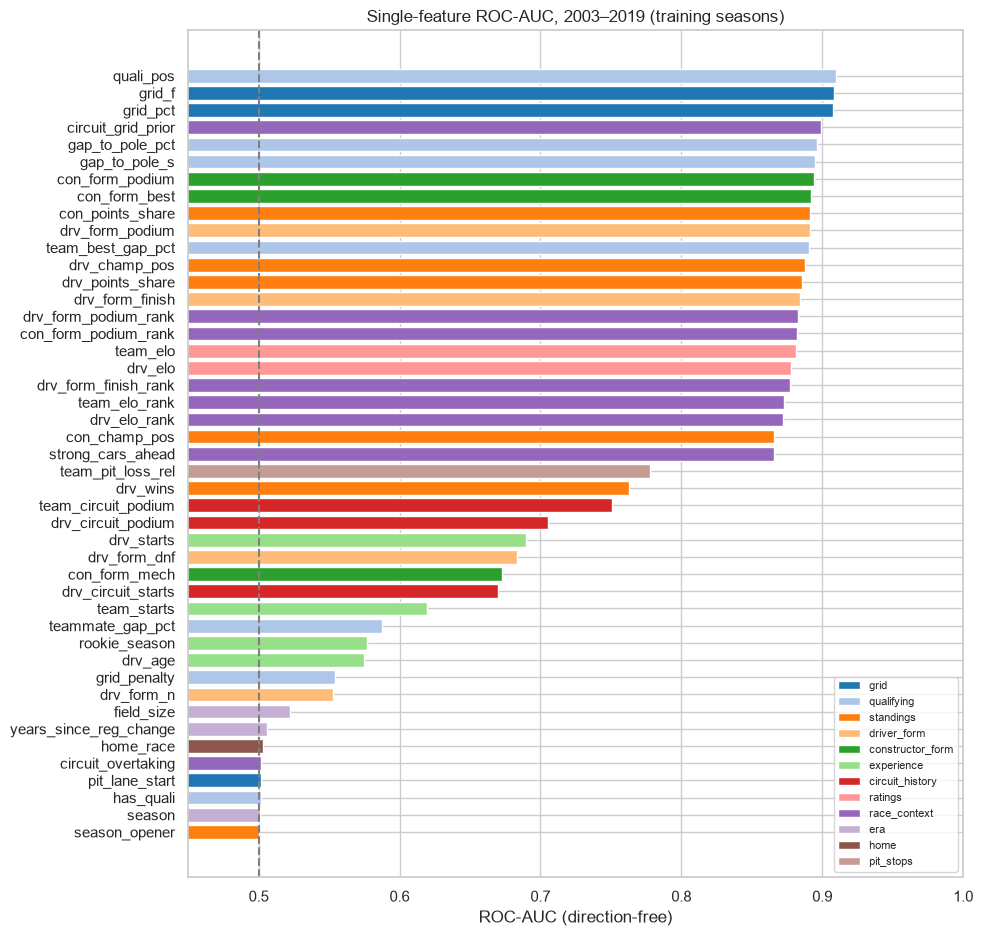

In [61]:
ev = features[features['year'].between(EV[1], EV[2])]
groups_all = {**FEATURE_GROUPS, **CANDIDATES}
evid = pd.DataFrame([{'group': g, 'feature': f, **dict(zip(['ROC_AUC', 'direction', 'coverage'],
                                                         auc_dir(ev['podium'], ev[f])))}
                     for g, fs in groups_all.items() for f in fs])
assert not (evid['ROC_AUC'] > 0.97).any(), 'suspiciously strong single feature — check for leakage'
display(evid.sort_values(['group', 'ROC_AUC'], ascending=[True, False]).set_index(['group', 'feature']).round(3))

fig, ax = plt.subplots(figsize=(10, 11))
e_ = evid.sort_values('ROC_AUC')
pal = dict(zip(groups_all, sns.color_palette('tab20', len(groups_all))))
ax.barh(e_['feature'], e_['ROC_AUC'], color=[pal[g] for g in e_['group']])
for g, c in pal.items():
    ax.barh(0, 0, color=c, label=g)
ax.axvline(0.5, color='grey', linestyle='--')
ax.set(title='Single-feature ROC-AUC, 2003–2019 (training seasons)', xlabel='ROC-AUC (direction-free)', xlim=(0.45, 1))
ax.legend(loc='lower right', fontsize=8)
save_fig(fig, 's4_feature_auc')
plt.show()

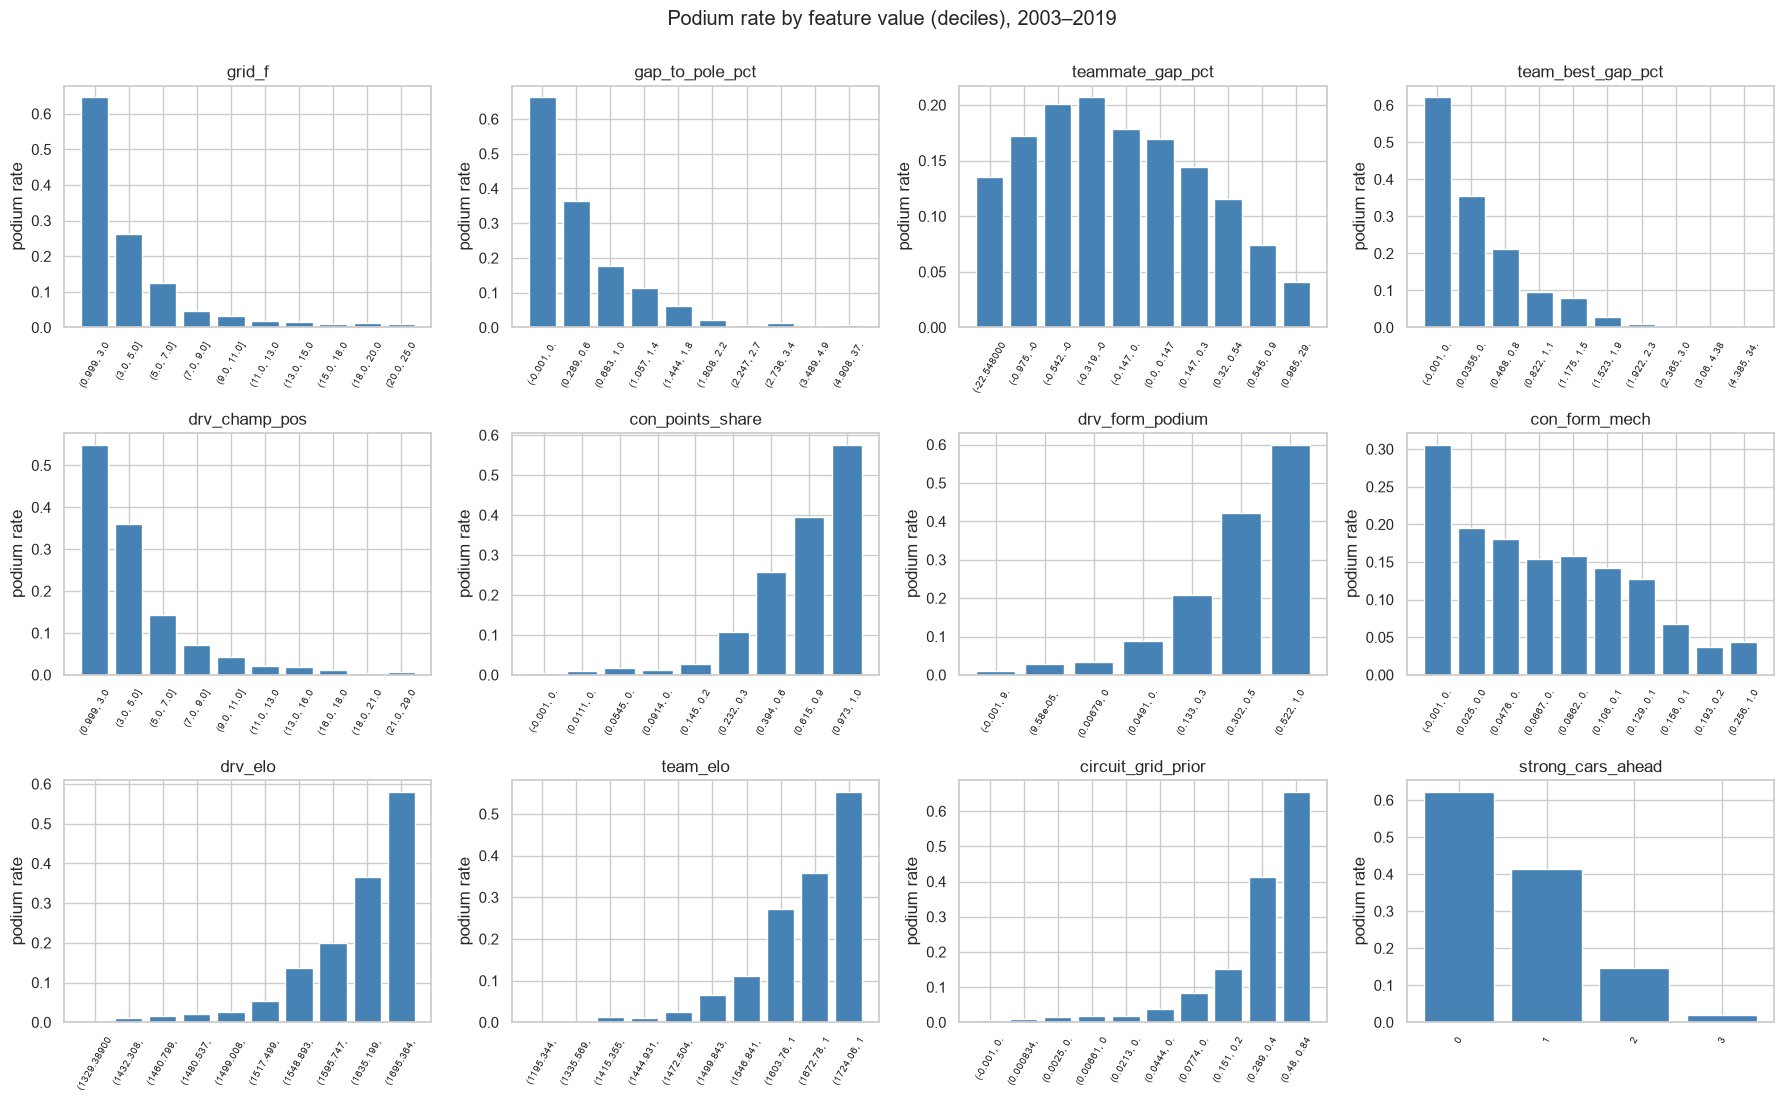

In [62]:
show = ['grid_f', 'gap_to_pole_pct', 'teammate_gap_pct', 'team_best_gap_pct', 'drv_champ_pos', 'con_points_share',
        'drv_form_podium', 'con_form_mech', 'drv_elo', 'team_elo', 'circuit_grid_prior', 'strong_cars_ahead']
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, f in zip(axes.ravel(), show):
    x = ev[f]
    bins = x if x.nunique() <= 12 else pd.qcut(x, 10, duplicates='drop')
    rate = ev.groupby(bins, observed=True)['podium'].mean()
    xs = rate.index.astype(str) if x.nunique() > 12 else rate.index
    ax.bar(range(len(rate)), rate.values, color='steelblue')
    ax.set_xticks(range(len(rate)), [str(v)[:11] for v in xs], rotation=60, fontsize=7)
    ax.set(title=f, ylabel='podium rate')
fig.suptitle('Podium rate by feature value (deciles), 2003–2019', y=1.0)
plt.tight_layout()
save_fig(fig, 's4_feature_podium_rate')
plt.show()

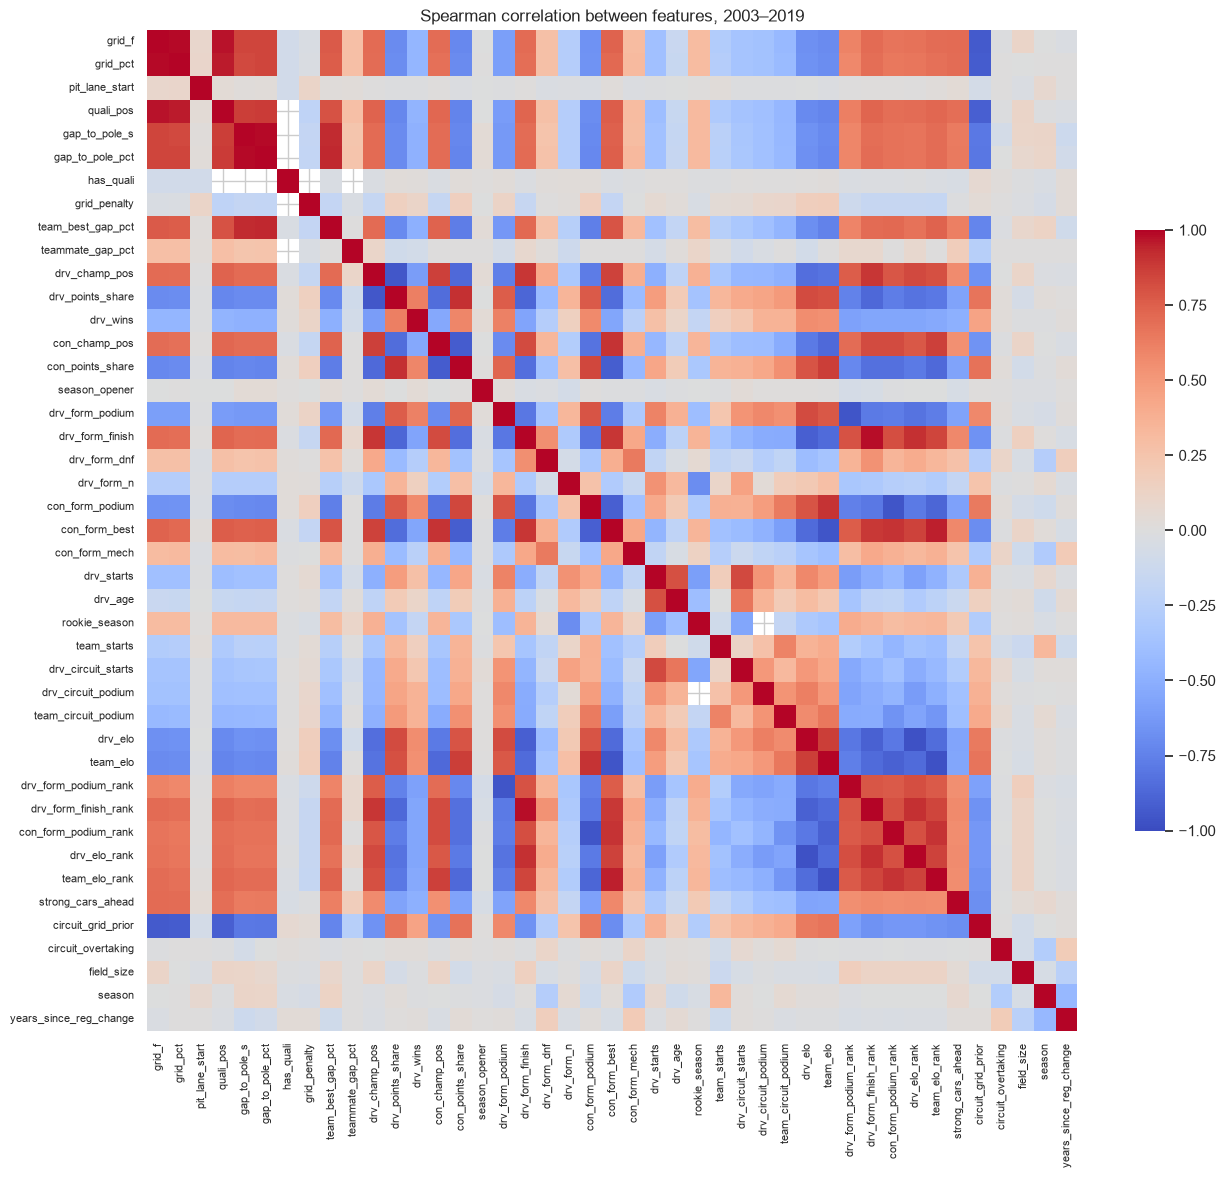

most redundant pairs (|rho| >= 0.9):


grid_f                grid_pct                0.990
gap_to_pole_s         gap_to_pole_pct         0.989
drv_form_finish       drv_form_finish_rank    0.980
drv_elo               drv_elo_rank           -0.971
grid_f                quali_pos               0.970
team_elo              team_elo_rank          -0.969
con_form_best         team_elo               -0.960
drv_form_podium       drv_form_podium_rank   -0.958
grid_pct              quali_pos               0.958
con_form_podium       con_form_podium_rank   -0.956
drv_champ_pos         drv_points_share       -0.951
con_form_best         team_elo_rank           0.949
gap_to_pole_pct       team_best_gap_pct       0.935
grid_f                circuit_grid_prior     -0.935
grid_pct              circuit_grid_prior     -0.930
gap_to_pole_s         team_best_gap_pct       0.925
con_champ_pos         con_points_share       -0.923
con_points_share      con_form_best          -0.920
drv_points_share      con_points_share        0.913
drv_form_fin

In [63]:
model_feats = [f for g in FEATURE_GROUPS.values() for f in g]
corr = ev[model_feats].corr(method='spearman')
fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True, cbar_kws={'shrink': 0.6})
ax.set_title('Spearman correlation between features, 2003–2019')
ax.tick_params(labelsize=8)
save_fig(fig, 's4_feature_correlation')
plt.show()
up = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print('most redundant pairs (|rho| >= 0.9):')
up[up.abs() >= 0.9].sort_values(key=abs, ascending=False).round(3)

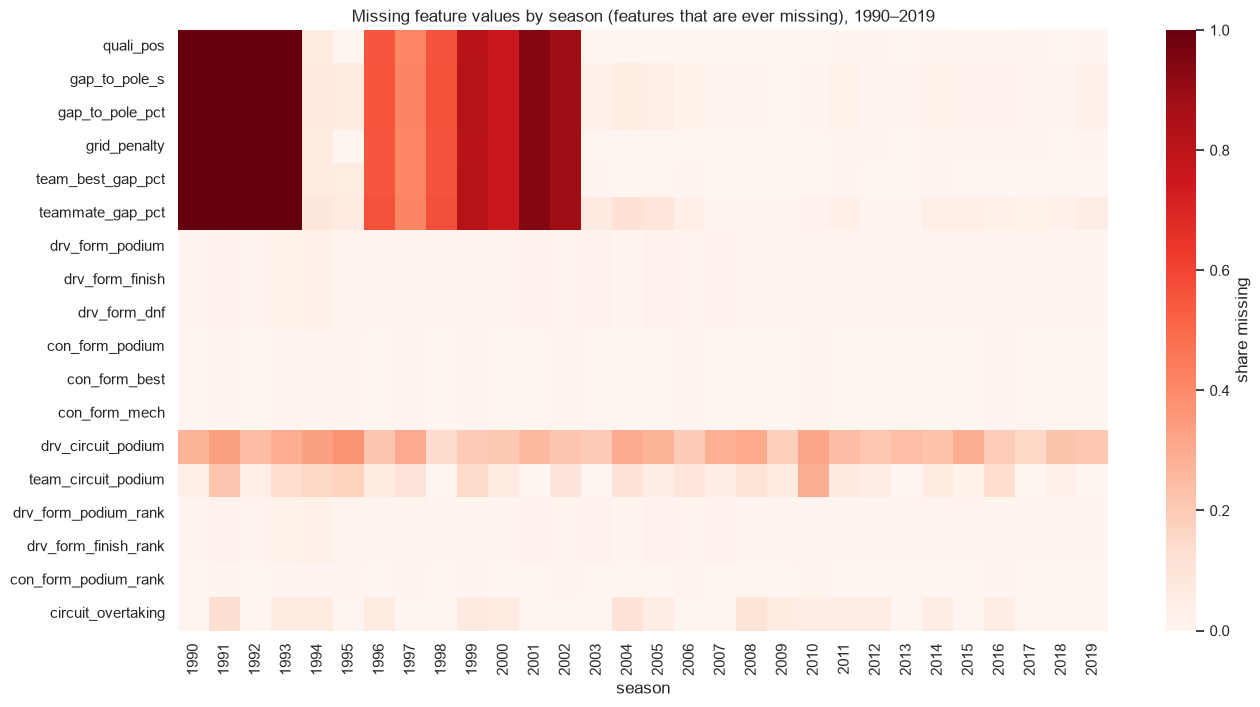

In [64]:
miss_season = (features[features['year'].between(1990, 2019)].groupby('year')[model_feats]
               .apply(lambda d: d.isna().mean()).T)
miss_season = miss_season[miss_season.max(axis=1) > 0]
fig, ax = plt.subplots(figsize=(15, 0.35 * len(miss_season) + 1.5))
sns.heatmap(miss_season, cmap='Reds', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'share missing'})
ax.set(title='Missing feature values by season (features that are ever missing), 1990–2019', xlabel='season')
save_fig(fig, 's4_feature_missingness')
plt.show()

**What the evidence says**
* **Strongest single features (AUC ≈ 0.89–0.91):** qualifying position, grid, the circuit grid-slot prior, gap to pole,
  team pace this weekend, constructor and driver form, standings and Elo. Car strength reaches the model through
  several routes — which is why the ablation (Step 7) removes whole groups, not single features.
* **No leakage signal:** the best single feature reaches 0.91 (< 0.97 alarm threshold) and the time-travel test passed.
* **Weak on their own (≈ 0.50–0.59), kept on purpose:** era features, flags (`season_opener`, `has_quali`,
  `pit_lane_start`), `circuit_overtaking`, `grid_penalty` and `teammate_gap_pct`. These are *modifiers*:
  overtaking difficulty changes how much the grid matters, a penalty matters only together with qualifying pace, and
  the teammate gap is **non-linear** (inverted U in the plot — a huge negative gap usually means the teammate had a
  problem). Single-feature AUC cannot show interactions; tree models and the ablation will.
* **Redundancy:** `grid_f` vs `grid_pct` (ρ = 0.99) and `gap_to_pole_s` vs `gap_to_pole_pct` (ρ = 0.99) are
  near-duplicates → one of each is dropped (§4.9). Race ranks vs raw values (ρ 0.95–0.98) and Elo vs form
  (ρ ≈ 0.90–0.96) are highly correlated in 2003–2019 (stable 20-car fields) but not identical; they are kept and their
  added value is measured by the ablation.
* **Missingness is structural:** qualifying features are missing before 1994 and in 1996–2002 (coverage drift, §1.8.2),
  circuit history is missing on a first visit (≈ 20–30 % of driver rows), everything else is ≈ complete. From 2003 the
  feature table is essentially complete — the basis for the training-window decision in Step 5.

## 4.7 Sprint data decision

In [65]:
spr = features.assign(is_sprint=features['raceId'].isin(sprint_races)).drop_duplicates('raceId')
spr['split'] = np.select([spr['year'] <= 2019, spr['year'] <= 2021], ['train (≤ 2019)', 'validation (2020–21)'], 'test (≥ 2022)')
spr.groupby('split')['is_sprint'].agg(races='size', sprint_weekends='sum')

,races,sprint_weekends
split,,
test (≥ 2022),68,15
train (≤ 2019),1007,0
validation (2020–21),39,3


**Sprint results are technically pre-race information** (the sprint runs before the Grand Prix), so using them would
not be leakage. They are nevertheless **not used as a feature**:
1. **There is no sprint weekend in the training seasons** — the model could not learn what a sprint result means; the
   feature would be missing for every training row and only appear in validation/test.
2. In 2021–22 the sprint result **set the Sunday grid** (§2.9), so its information is already inside `grid_f`.
3. Sprint points from earlier weekends are already part of the **standings before the race**.

## 4.8 Feature register (for the report)

In [66]:
register = pd.DataFrame([
    ('grid', 'grid_f, grid_pct, pit_lane_start', 'results', 'starting slot (pit lane = behind last slot), slot / field size', 'grid is fixed before lights out'),
    ('qualifying', 'quali_pos, gap_to_pole_s/_pct, has_quali, grid_penalty', 'qualifying, results', 'best Q lap vs pole; grid − qualifying position', 'qualifying finishes before the race'),
    ('qualifying', 'team_best_gap_pct, teammate_gap_pct', 'qualifying, results', "team's best car vs pole; own lap vs teammate's", "uses other drivers' qualifying of the same weekend — complete before the race"),
    ('standings', 'drv/con_champ_pos, drv/con_points_share, drv_wins, season_opener', 'driver_/constructor_standings, races', 'official standings after the previous race in the calendar', 'previous race is over before this one starts'),
    ('driver_form', f'drv_form_* (N = {FORM_N})', 'results, status', 'mean over previous N races', 'shift(1): current race excluded'),
    ('constructor_form', f'con_form_* (N = {FORM_N})', 'results, status, constructors', 'team lineage, previous N races', 'shift(1): current race excluded'),
    ('experience', 'drv_starts, drv_age, rookie_season, team_starts', 'results, drivers', 'counts of previous starts; age at race date', 'counts only earlier races; date of birth is static'),
    ('circuit_history', 'drv_circuit_starts, drv_circuit_podium, team_circuit_podium', 'results, races, circuits', 'expanding mean over previous visits', 'previous visits only'),
    ('ratings', 'drv_elo, team_elo', 'results, status', 'pairwise Elo, stored before the race, updated after', 'rating is read before the race is processed'),
    ('race_context', '*_rank, strong_cars_ahead', 'derived', "ranks among today's starters of pre-race features", 'inputs are all pre-race'),
    ('race_context', 'circuit_grid_prior, circuit_overtaking', 'results, races, circuits', 'past podium rate per grid slot at circuit (shrunk); past mean |grid − finish|', 'previous races only'),
    ('era', 'field_size, season, years_since_reg_change', 'results, races', 'number of starters; calendar', 'known when the grid is set'),
    ('home (candidate)', 'home_race', 'drivers, circuits', 'driver country = circuit country', 'static — but Q2: no effect'),
    ('pit_stops (candidate)', 'team_pit_loss_rel', 'pit_stops, results', 'pit loss vs race median, previous N races', 'previous races only'),
], columns=['group', 'features', 'source tables', 'computation', 'why valid at the pre-race cutoff'])
with pd.option_context('display.max_colwidth', None):
    display(register)

,group,features,source tables,computation,why valid at the pre-race cutoff
0,grid,"grid_f, grid_pct, pit_lane_start",results,"starting slot (pit lane = behind last slot), slot / field size",grid is fixed before lights out
1,qualifying,"quali_pos, gap_to_pole_s/_pct, has_quali, grid_penalty","qualifying, results",best Q lap vs pole; grid − qualifying position,qualifying finishes before the race
2,qualifying,"team_best_gap_pct, teammate_gap_pct","qualifying, results",team's best car vs pole; own lap vs teammate's,uses other drivers' qualifying of the same weekend — complete before the race
3,standings,"drv/con_champ_pos, drv/con_points_share, drv_wins, season_opener","driver_/constructor_standings, races",official standings after the previous race in the calendar,previous race is over before this one starts
4,driver_form,drv_form_* (N = ewm),"results, status",mean over previous N races,shift(1): current race excluded
5,constructor_form,con_form_* (N = ewm),"results, status, constructors","team lineage, previous N races",shift(1): current race excluded
6,experience,"drv_starts, drv_age, rookie_season, team_starts","results, drivers",counts of previous starts; age at race date,counts only earlier races; date of birth is static
7,circuit_history,"drv_circuit_starts, drv_circuit_podium, team_circuit_podium","results, races, circuits",expanding mean over previous visits,previous visits only
8,ratings,"drv_elo, team_elo","results, status","pairwise Elo, stored before the race, updated after",rating is read before the race is processed
9,race_context,"*_rank, strong_cars_ahead",derived,ranks among today's starters of pre-race features,inputs are all pre-race


## 4.9 Final feature set
Decisions taken from the evidence above (training seasons only):

In [67]:
EXCLUDED = pd.DataFrame([
    ('grid_pct', 'redundant with grid_f (rho = 0.99); field size is ~constant in the modern era'),
    ('gap_to_pole_s', 'redundant with gap_to_pole_pct (rho = 0.99); % is comparable across circuits of different lap length'),
    ('home_race', 'Q2: no home effect after controlling for grid (2003–2019 OR 0.71, p = 0.13) -> ablation only'),
    ('team_pit_loss_rel', 'tested in §4.4: PR-AUC −0.024 vs core model (rule +0.005); only from 2011'),
    ('sprint results', '§4.7: no sprint weekend in training seasons; already inside grid (2021–22) and standings'),
    ('constructor / driver identity', 'teams change identity and strength across eras -> memorisation; performance features carry the signal'),
    ('reached_q3', 'not built: equals quali_pos <= 10 in the knockout era and is undefined before 2006'),
], columns=['feature', 'reason']).set_index('feature')
with pd.option_context('display.max_colwidth', None):
    display(EXCLUDED)

MODEL_GROUPS = {g: [f for f in fs if f not in EXCLUDED.index] for g, fs in FEATURE_GROUPS.items()}
MODEL_FEATURES = [f for fs in MODEL_GROUPS.values() for f in fs]
KEYS = ['raceId', 'driverId', 'constructorId', 'team_lineage', 'circuitId', 'year', 'date', 'race_seq']
model_table = features[KEYS + MODEL_FEATURES + ['podium']].copy()
print(f'model_table: {model_table.shape[0]:,} rows, {len(MODEL_FEATURES)} features in {len(MODEL_GROUPS)} groups')
with pd.option_context('display.max_colwidth', None):
    display(pd.Series({g: ', '.join(fs) for g, fs in MODEL_GROUPS.items()}, name='features').to_frame())

,reason
feature,
grid_pct,redundant with grid_f (rho = 0.99); field size is ~constant in the modern era
gap_to_pole_s,redundant with gap_to_pole_pct (rho = 0.99); % is comparable across circuits of different lap length
home_race,"Q2: no home effect after controlling for grid (2003–2019 OR 0.71, p = 0.13) -> ablation only"
team_pit_loss_rel,tested in §4.4: PR-AUC −0.024 vs core model (rule +0.005); only from 2011
sprint results,§4.7: no sprint weekend in training seasons; already inside grid (2021–22) and standings
constructor / driver identity,teams change identity and strength across eras -> memorisation; performance features carry the signal
reached_q3,not built: equals quali_pos <= 10 in the knockout era and is undefined before 2006


model_table: 24,755 rows, 41 features in 10 groups


,features
grid,"grid_f, pit_lane_start"
qualifying,"quali_pos, gap_to_pole_pct, has_quali, grid_penalty, team_best_gap_pct, teammate_gap_pct"
standings,"drv_champ_pos, drv_points_share, drv_wins, con_champ_pos, con_points_share, season_opener"
driver_form,"drv_form_podium, drv_form_finish, drv_form_dnf, drv_form_n"
constructor_form,"con_form_podium, con_form_best, con_form_mech"
experience,"drv_starts, drv_age, rookie_season, team_starts"
circuit_history,"drv_circuit_starts, drv_circuit_podium, team_circuit_podium"
ratings,"drv_elo, team_elo"
race_context,"drv_form_podium_rank, drv_form_finish_rank, con_form_podium_rank, drv_elo_rank, team_elo_rank, strong_cars_ahead, circuit_grid_prior, circuit_overtaking"
era,"field_size, season, years_since_reg_change"


## 4.10 Step 4 summary
| Item | Result |
|---|---|
| Feature table | one row per driver-race, 1950–2024, all features computed from information before the start |
| Leakage control | `shift(1)` / previous-race standings / pre-race Elo; **time-travel test passed** on 4 races (0 mismatches) |
| Form window | EWM (half-life 5) beat N = 3, 5, 10 on all six form features |
| Creative features | race-relative ranks, team pace this weekend, teammate gap, Elo, strong cars ahead, circuit grid-slot prior, circuit overtaking |
| Tested & excluded | pit-stop performance (no gain), home race (Q2 → ablation only), sprint results (no training data) |
| Model features | 41 features in 10 groups (`MODEL_GROUPS`, the ablation units for Step 7) |
| Evidence | single-feature AUC, podium-rate plots, correlation and missingness — all on 2003–2019 training seasons |

# 5. Split, Training Data and Preprocessing
**Split (fixed, from the F1 primer):** train ≤ 2019 · validation 2020–2021 · test ≥ 2022. Every decision in this
section is made on training seasons or on validation; **the test seasons are not touched until Step 6**.

**Constraint on the training data:** no season is removed, and no value is invented by statistical guessing. Two
consequences are handled here:
1. **Qualifying position** is missing for every driver before 1994 and most drivers in 1996–2002 (the qualifying table
   has *no rows* for them — §1.8.2). It is **derived from the grid** where no qualifying row exists (§5.1), a
   cross-table derivation validated on the seasons where both are recorded.
2. **Qualifying lap times** (gap to pole, team pace, teammate gap) cannot be derived for those seasons. §5.2 tests
   whether they add anything beyond qualifying *position*; if not, they are dropped and one complete feature table
   covers 1950–2024.

In [68]:
from sklearn.ensemble import HistGradientBoostingClassifier

def race_bootstrap_ci(y, p_a, p_b, race_ids, n_boot=1000, seed=SEED):
    """95 % CI of PR-AUC(p_b) - PR-AUC(p_a), resampling whole races (rows of a race are not independent)."""
    y, p_a, p_b, race_ids = map(np.asarray, (y, p_a, p_b, race_ids))
    rng = np.random.default_rng(seed)
    races = np.unique(race_ids)
    rows_of = {r: np.flatnonzero(race_ids == r) for r in races}
    gains = []
    for _ in range(n_boot):
        idx = np.concatenate([rows_of[r] for r in rng.choice(races, len(races))])
        if y[idx].sum() == 0:
            continue
        gains.append(average_precision_score(y[idx], p_b[idx]) - average_precision_score(y[idx], p_a[idx]))
    return np.percentile(gains, [2.5, 97.5])

def make_lr():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
                         LogisticRegression(max_iter=2000))

def make_hgb():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=SEED)   # handles NaN natively

## 5.1 Qualifying position for every season — derived from the grid
**Technique:** a *coalesce* across two tables with a provenance flag:

`quali_pos_d` = `qualifying.position` if the driver has a qualifying row, otherwise `results.grid` (pit-lane starters:
the slot behind the last car) · `quali_source` = 0 (recorded) / 1 (derived from grid).

This is not a statistical guess: it uses each driver's **actual recorded starting slot**. Before grid penalties became
common, the grid *was* the qualifying order. The derivation is validated by **pretending** that recorded qualifying
positions are missing, deriving them from the grid, and measuring the error — per era.

In [69]:
real = features[features['quali_pos'].notna() & features['pit_lane_start'].eq(0)].copy()
real['era'] = pd.cut(real['year'], [1993, 2002, 2013, 2024], labels=['1994–2002', '2003–2013', '2014–2024'])
real['abs_err'] = (real['grid_f'] - real['quali_pos']).abs()
derive_check = real.groupby('era', observed=True).agg(
    rows=('abs_err', 'size'), exact=('abs_err', lambda e: (e == 0).mean()),
    within_1_place=('abs_err', lambda e: (e <= 1).mean()), mean_abs_error=('abs_err', 'mean'))
display(derive_check.round(3))

features['quali_source'] = features['quali_pos'].isna().astype(int)
features['quali_pos_d'] = features['quali_pos'].fillna(features['grid_f'])
features['grid_penalty_d'] = features['grid_f'] - features['quali_pos_d']
cov = features.groupby(pd.cut(features['year'], [1949, 1993, 2002, 2024], labels=['1950–1993', '1994–2002', '2003–2024']),
                       observed=True)['quali_source'].agg(rows='size', derived_share='mean')
display(cov.round(3))
assert features['quali_pos_d'].notna().all()

,rows,exact,within_1_place,mean_abs_error
era,,,,
1994–2002,1543,0.982,0.998,0.033
2003–2013,4330,0.765,0.933,0.454
2014–2024,4533,0.696,0.868,0.666


,rows,derived_share
year,,
1950–1993,12454,1.000
1994–2002,3340,0.537
2003–2024,8961,0.003


**Result.** Where both are recorded, deriving qualifying position from the grid is exact for **98.2 %** of drivers in
1994–2002 (99.8 % within one place, mean error 0.03 places): before grid penalties became routine, the grid *was* the
qualifying order. The agreement drops to 70–77 % in the modern era (penalties, pit-lane starts) — but there the
derivation is used for only **0.3 %** of rows; it fills 100 % of 1950–1993 rows and 54 % of 1994–2002 rows.

**Assumption (stated as a limitation):** for 1950–1993 there is no qualifying table to check against; we assume the
grid followed qualifying as it did in 1994–2002 (grid penalties for engine changes etc. only became common in the
2000s). `quali_source` flags every derived value, so the model can treat them differently if needed.

## 5.2 Are qualifying lap times needed? (position-only vs position + lap times)
Both versions use every other model feature; they differ only in the qualifying group:
* **position only:** `quali_pos_d`, `grid_penalty_d`, `quali_source`
* **position + lap times:** additionally `gap_to_pole_pct`, `team_best_gap_pct`, `teammate_gap_pct`

**Design:** training seasons 2003–2019 only (lap times exist for everyone there, so both versions see identical rows);
two rolling rounds — fit 2003–2015 → evaluate 2016–17, fit 2003–2017 → evaluate 2018–19; two model types — logistic
regression (linear) and gradient boosting (non-linear). Metric: PR-AUC, with a 95 % bootstrap CI over races.

**Decision rule (fixed before running):** keep the lap-time features only if, for at least one model type, the PR-AUC
gain is **≥ +0.005 and its bootstrap CI excludes 0**; otherwise drop them.

In [70]:
QUALI_POS = ['quali_pos_d', 'grid_penalty_d', 'quali_source']
LAPTIME = ['gap_to_pole_pct', 'team_best_gap_pct', 'teammate_gap_pct']
OTHER = [f for g, fs in MODEL_GROUPS.items() if g != 'qualifying' for f in fs]
SETS = {'position only': OTHER + QUALI_POS, 'position + lap times': OTHER + QUALI_POS + LAPTIME}
ROUNDS = [((2003, 2015), (2016, 2017)), ((2003, 2017), (2018, 2019))]

lt_rows, pooled = [], {}
for mname, make in [('logistic regression', make_lr), ('gradient boosting', make_hgb)]:
    preds = {s: [] for s in SETS}
    ys, rids = [], []
    for (a, b), (c, d) in ROUNDS:
        tr = features[features['year'].between(a, b)]
        te = features[features['year'].between(c, d)]
        for sname, cols in SETS.items():
            mdl = make().fit(tr[cols], tr['podium'])
            p = mdl.predict_proba(te[cols])[:, 1]
            preds[sname].append(p)
            lt_rows.append({'model': mname, 'eval seasons': f'{c}–{d}', 'features': sname,
                            'PR-AUC': average_precision_score(te['podium'], p), 'ROC-AUC': roc_auc_score(te['podium'], p)})
        ys.append(te['podium'].to_numpy())
        rids.append(te['raceId'].to_numpy())
    y_all, r_all = np.concatenate(ys), np.concatenate(rids)
    p_pos, p_lap = np.concatenate(preds['position only']), np.concatenate(preds['position + lap times'])
    lo, hi = race_bootstrap_ci(y_all, p_pos, p_lap, r_all)
    pooled[mname] = {'PR-AUC position only': average_precision_score(y_all, p_pos),
                     'PR-AUC + lap times': average_precision_score(y_all, p_lap),
                     'gain': average_precision_score(y_all, p_lap) - average_precision_score(y_all, p_pos),
                     'gain CI low': lo, 'gain CI high': hi}
display(pd.DataFrame(lt_rows).pivot_table(index=['model', 'eval seasons'], columns='features',
                                          values=['PR-AUC', 'ROC-AUC']).round(4))
lap_test = pd.DataFrame(pooled).T
display(lap_test.round(4))
KEEP_LAPTIME = bool(((lap_test['gain'] >= 0.005) & (lap_test['gain CI low'] > 0)).any())
print('Decision:', 'KEEP lap-time features (use stacking)' if KEEP_LAPTIME else
      'DROP lap-time features -> one complete feature table for 1950–2024')

PR-AUC                            ROC-AUC              
features                         position + lap times position only position + lap times position only
model               eval seasons                                                                      
gradient boosting   2016–2017                  0.7660        0.7622               0.9509        0.9480
                    2018–2019                  0.6803        0.7006               0.9414        0.9429
logistic regression 2016–2017                  0.7036        0.7091               0.9474        0.9473
                    2018–2019                  0.7164        0.7145               0.9482        0.9442

,PR-AUC position only,PR-AUC + lap times,gain,gain CI low,gain CI high
logistic regression,0.7177,0.7175,-0.0002,-0.0062,0.0056
gradient boosting,0.7336,0.7299,-0.0037,-0.0260,0.0189


Decision: DROP lap-time features -> one complete feature table for 1950–2024


**Result: the lap-time features are dropped.** Adding them changes PR-AUC by **−0.0002** (logistic regression) and
**−0.0037** (gradient boosting); both bootstrap intervals include 0 and the two evaluation rounds disagree in sign.
Once qualifying *position*, grid, team strength (form, standings, Elo) and race context are known, *how many tenths*
a driver was off pole adds nothing measurable. Qualifying information stays in the model through `quali_pos_d` (the
strongest single feature, AUC 0.91) and `grid_penalty_d`.

**Consequence:** the feature table is complete for every season — 1950–2024 rows are all kept, no qualifying value is
guessed, and all four models in Step 6 can use the same rows and the same features without stacking. The lap-time
features are documented as *tested and excluded* (they are still used in Q1 and in the Step 4 evidence).

## 5.3 The feature set and the splits
Final features = all model features from Step 4 with the qualifying group reduced to **position-based** features.
The few remaining gaps are values that **do not exist** rather than unknown values — a debut race has no past form, a
first visit has no circuit history, there was no constructors' championship before 1958. They are handled inside each
model's pipeline (§5.6, experiment C), always fitted on training rows only.

In [71]:
FINAL_GROUPS = {g: (QUALI_POS if g == 'qualifying' else fs) for g, fs in MODEL_GROUPS.items()}
FEATURES = [f for fs in FINAL_GROUPS.values() for f in fs]
SPLITS = {'train': (1950, 2019), 'validation': (2020, 2021), 'test': (2022, 2024)}
split_of = lambda y: 'train' if y <= 2019 else ('validation' if y <= 2021 else 'test')
features['split'] = features['year'].map(split_of)

profile = features.groupby('split').agg(seasons=('year', lambda y: f'{y.min()}–{y.max()}'), races=('raceId', 'nunique'),
                                        rows=('podium', 'size'), podium_rate=('podium', 'mean'),
                                        derived_quali=('quali_source', 'mean')).loc[['train', 'validation', 'test']]
display(profile.round(3))
miss = features.groupby('split')[FEATURES].apply(lambda d: d.isna().mean()).T
display(miss[miss.max(axis=1) > 0].loc[:, ['train', 'validation', 'test']].mul(100).round(1)
        .rename(columns=lambda c: f'% missing ({c})'))
print(f'{len(FEATURES)} features in {len(FINAL_GROUPS)} groups')

,seasons,races,rows,podium_rate,derived_quali
split,,,,,
train,1950–2019,1007,22618,0.134,0.631
validation,2020–2021,39,780,0.150,0.001
test,2022–2024,68,1357,0.150,0.000


split,% missing (train),% missing (validation),% missing (test)
drv_champ_pos,0.1,0.0,0.0
drv_points_share,0.1,0.0,0.0
drv_wins,0.1,0.0,0.0
con_champ_pos,5.2,0.0,0.0
con_points_share,5.2,0.0,0.0
drv_form_podium,3.0,0.8,0.6
drv_form_finish,3.0,0.8,0.6
drv_form_dnf,3.0,0.8,0.6
con_form_podium,0.8,0.0,0.0
con_form_best,0.8,0.0,0.0


38 features in 10 groups


**Why split by season (and not randomly by row)?**
* The model's real job is to predict **future** races. A season split trains only on the past and evaluates on later
  seasons, exactly like deployment; a random split would let the model learn from 2023 races while predicting 2018.
* Rows of one race are not independent (20 drivers share one outcome and the same conditions); a random split
  scatters the same race across train and evaluation.
* Validation 2020–21 is the two seasons right after training — used for every choice (windows, weights, preprocessing,
  hyperparameters, threshold). The test seasons ≥ 2022 are a **new rules era** (ground-effect cars) the model never sees
  — an honest out-of-era test, reported once in Step 6.
* Validation is small (39 races), so every comparison below carries a race-level bootstrap interval.

## 5.4 Using all seasons — recency weighting
All seasons 1950–2019 stay in the training set. Because early F1 was a different sport (30+ entrants, ≈ 50 %
finishers, no penalties), recent seasons can be given **more weight** instead of removing old ones:
weight = 0.5 ^ ((2019 − season) / half-life). A half-life of 10 means a 2009 race counts half as much as a 2019 race,
a 1999 race a quarter. Candidates: no weighting, half-life 20, 10, 5 seasons — chosen on **validation PR-AUC**
(mean of logistic regression and gradient boosting). A 2003–2019-only fit is shown **for reference only** (not an
option — it removes seasons) to quantify what the old seasons contribute.

PR-AUC                               ROC-AUC                      PR-AUC
model                     gradient boosting logistic regression gradient boosting logistic regression    mean
training data                                                                                                
half-life 5                          0.7263              0.7178            0.9286              0.9282  0.7220
half-life 10                         0.7150              0.7278            0.9277              0.9303  0.7214
no weighting                         0.7065              0.7306            0.9311              0.9299  0.7186
half-life 20                         0.7066              0.7303            0.9282              0.9303  0.7185
reference: 2003–2019 only            0.6741              0.7163            0.9277              0.9296  0.6952

logistic regression: PR-AUC gain of half-life 5 over no weighting, 95 % CI [-0.0475, +0.0177]


gradient boosting: PR-AUC gain of half-life 5 over no weighting, 95 % CI [-0.0275, +0.0555]
chosen: half-life 5


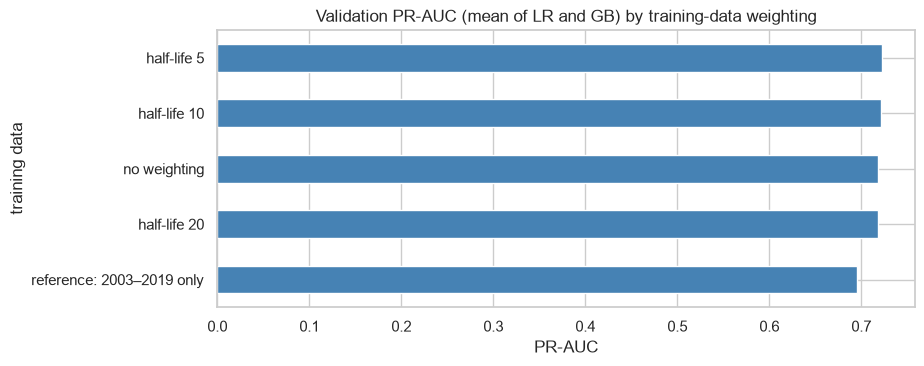

In [72]:
train_df = features[features['split'] == 'train']
val_df = features[features['split'] == 'validation']
X_tr, y_tr = train_df[FEATURES], train_df['podium']
X_va, y_va = val_df[FEATURES], val_df['podium']

def recency_weights(years, half_life):
    return np.ones(len(years)) if half_life is None else 0.5 ** ((2019 - np.asarray(years)) / half_life)

def fit_predict(make, X, y, w, Xe):
    mdl = make()
    if isinstance(mdl, HistGradientBoostingClassifier):
        mdl.fit(X, y, sample_weight=w)
    else:
        mdl.fit(X, y, logisticregression__sample_weight=w)
    return mdl.predict_proba(Xe)[:, 1]

w_rows, w_preds = [], {}
for label, hl in [('no weighting', None), ('half-life 20', 20), ('half-life 10', 10), ('half-life 5', 5)]:
    w = recency_weights(train_df['year'], hl)
    for mname, make in [('logistic regression', make_lr), ('gradient boosting', make_hgb)]:
        p = fit_predict(make, X_tr, y_tr, w, X_va)
        w_preds[(label, mname)] = p
        w_rows.append({'training data': label, 'model': mname, 'PR-AUC': average_precision_score(y_va, p),
                       'ROC-AUC': roc_auc_score(y_va, p)})
ref = train_df[train_df['year'] >= 2003]
for mname, make in [('logistic regression', make_lr), ('gradient boosting', make_hgb)]:
    p = fit_predict(make, ref[FEATURES], ref['podium'], np.ones(len(ref)), X_va)
    w_rows.append({'training data': 'reference: 2003–2019 only', 'model': mname,
                   'PR-AUC': average_precision_score(y_va, p), 'ROC-AUC': roc_auc_score(y_va, p)})
weight_exp = pd.DataFrame(w_rows).pivot_table(index='training data', columns='model', values=['PR-AUC', 'ROC-AUC'])
weight_exp[('PR-AUC', 'mean')] = weight_exp['PR-AUC'].mean(axis=1)
display(weight_exp.sort_values(('PR-AUC', 'mean'), ascending=False).round(4))

cands = weight_exp.drop(index='reference: 2003–2019 only')
BEST_WEIGHTING = cands[('PR-AUC', 'mean')].idxmax()
HALF_LIFE = None if BEST_WEIGHTING == 'no weighting' else int(BEST_WEIGHTING.split()[-1])
if BEST_WEIGHTING != 'no weighting':
    for mname in ['logistic regression', 'gradient boosting']:
        lo, hi = race_bootstrap_ci(y_va, w_preds[('no weighting', mname)], w_preds[(BEST_WEIGHTING, mname)], val_df['raceId'])
        print(f'{mname}: PR-AUC gain of {BEST_WEIGHTING} over no weighting, 95 % CI [{lo:+.4f}, {hi:+.4f}]')
print(f'chosen: {BEST_WEIGHTING}')
W_TRAIN = recency_weights(train_df['year'], HALF_LIFE)

fig, ax = plt.subplots(figsize=(9, 3.6))
weight_exp[('PR-AUC', 'mean')].sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set(title='Validation PR-AUC (mean of LR and GB) by training-data weighting', xlabel='PR-AUC')
save_fig(fig, 's5_recency_weighting')
plt.show()

**Result.**
* **Old seasons help.** Every weighting that keeps all seasons beats the 2003–2019-only reference
  (mean PR-AUC 0.719–0.722 vs 0.695), most clearly for gradient boosting (0.707–0.726 vs 0.674). Keeping the full
  history is therefore not only a constraint but also the better choice.
* **The amount of down-weighting barely matters:** all four variants lie within 0.004 of each other and the bootstrap
  intervals of the best vs no weighting include 0; logistic regression slightly prefers no weighting, gradient
  boosting a half-life of 5. By the rule fixed in advance (best mean validation PR-AUC), **half-life 5** is used —
  a 2014 race counts half as much as a 2019 race, a 1990s race only a few percent, so modern F1 dominates while
  older seasons still contribute.

## 5.5 Season split vs random row split
**Question:** how optimistic would a random row split be? Hold out a random 20 % of the 2020–21 rows as the evaluation
set and compare two training sets: (a) **season split** — seasons ≤ 2019 only; (b) **random split** — the same plus
the other 80 % of the 2020–21 rows, i.e. rows from the same seasons and the same races as the evaluation rows. Both
are scored on exactly the same evaluation rows (gradient boosting, chosen weighting).

In [73]:
rng = np.random.default_rng(SEED)
hold = rng.random(len(val_df)) < 0.2
ev_rows, leak_rows_ = val_df[hold], val_df[~hold]
w_leak = np.concatenate([W_TRAIN, np.ones(len(leak_rows_))])
X_leak = pd.concat([X_tr, leak_rows_[FEATURES]])
y_leak = pd.concat([y_tr, leak_rows_['podium']])
p_season = fit_predict(make_hgb, X_tr, y_tr, W_TRAIN, ev_rows[FEATURES])
p_random = fit_predict(make_hgb, X_leak, y_leak, w_leak, ev_rows[FEATURES])
lo, hi = race_bootstrap_ci(ev_rows['podium'], p_season, p_random, ev_rows['raceId'])
split_exp = pd.DataFrame({'PR-AUC': [average_precision_score(ev_rows['podium'], p) for p in (p_season, p_random)],
                          'ROC-AUC': [roc_auc_score(ev_rows['podium'], p) for p in (p_season, p_random)]},
                         index=['season split (train ≤ 2019)', 'random row split (+ 80 % of 2020–21 rows)'])
display(split_exp.round(4))
print(f'evaluation rows: {len(ev_rows)} from {ev_rows["raceId"].nunique()} races; '
      f'PR-AUC difference (random − season), 95 % CI [{lo:+.4f}, {hi:+.4f}]')

,PR-AUC,ROC-AUC
season split (train ≤ 2019),0.6341,0.8710
random row split (+ 80 % of 2020–21 rows),0.6201,0.8619


evaluation rows: 173 from 39 races; PR-AUC difference (random − season), 95 % CI [-0.0761, +0.0474]


**Result.** Here the random row split is **not** more optimistic (PR-AUC 0.620 vs 0.634, CI includes 0). This is
itself evidence that the Step 4 features are leakage-safe: since no feature contains same-race outcomes, seeing other
rows of the same races gives the model nothing to exploit. The season split is still the right design for a
conceptual reason — the model is used to predict *future* races, and only a season split trains strictly on the past
and evaluates on later seasons, as in deployment (and keeps the test era entirely unseen).

## 5.6 Preprocessing-order experiments (validation 2020–21)
Same features, same model, only the **order / scope** of a preprocessing step changes.

* **A — fit imputer & scaler before vs after the split.** *Wrong:* medians and means computed on **all** rows
  (train + validation + test) before splitting. *Right:* computed on training rows only inside the pipeline.
  Model: logistic regression (scale-sensitive).
* **B — target-based feature before vs after the split.** `circuit_grid_prior` (podium rate of a grid slot at a
  circuit) *wrong:* computed from **all seasons**, including the validation/test podiums it is meant to predict;
  *right:* from previous races only (Step 4).
* **C — how missing values enter the model.** C1 median only · C2 median + missing-value flags (both logistic
  regression) · C3 gradient boosting with the C2 imputation · C4 gradient boosting with native NaN handling.

In [74]:
test_df = features[features['split'] == 'test']
X_all = pd.concat([X_tr, X_va, test_df[FEATURES]])

def lr_only():
    return LogisticRegression(max_iter=2000)

# --- A: preprocessing fitted on all rows vs train only ------------------------------------------------------
prep_all = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()).fit(X_all)
lr_a = lr_only().fit(prep_all.transform(X_tr), y_tr, sample_weight=W_TRAIN)
p_A_wrong = lr_a.predict_proba(prep_all.transform(X_va))[:, 1]
p_A_right = fit_predict(make_lr, X_tr, y_tr, W_TRAIN, X_va)
prep_tr = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()).fit(X_tr)
shift = pd.DataFrame({'mean (train only)': prep_tr[-1].mean_[:len(FEATURES)],
                      'mean (all rows)': prep_all[-1].mean_[:len(FEATURES)]}, index=FEATURES)
shift['relative change %'] = 100 * (shift['mean (all rows)'] / shift['mean (train only)'] - 1)

# --- B: circuit_grid_prior from all seasons vs past only --------------------------------------------------------
def leaky_circuit_prior(f, M=5):
    g = f['grid_f'].clip(upper=21)
    p_slot = f.groupby(g)['podium'].transform('mean')
    k = f.groupby([f['circuitId'], g])['podium'].transform('sum')
    n = f.groupby([f['circuitId'], g])['podium'].transform('count')
    return (k + M * p_slot) / (n + M)
leaky = features.assign(circuit_grid_prior=leaky_circuit_prior(features))
B = {}
for mname, make in [('logistic regression', make_lr), ('gradient boosting', make_hgb)]:
    B[(mname, 'wrong')] = fit_predict(make, leaky.loc[train_df.index, FEATURES], y_tr, W_TRAIN, leaky.loc[val_df.index, FEATURES])
    B[(mname, 'right')] = fit_predict(make, X_tr, y_tr, W_TRAIN, X_va)

# --- C: missing-value strategies -----------------------------------------------------------------------------------
c1 = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=2000))
c1.fit(X_tr, y_tr, logisticregression__sample_weight=W_TRAIN)
p_C1 = c1.predict_proba(X_va)[:, 1]
p_C2 = p_A_right
c3 = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), make_hgb())
c3.fit(X_tr, y_tr, histgradientboostingclassifier__sample_weight=W_TRAIN)
p_C3 = c3.predict_proba(X_va)[:, 1]
p_C4 = fit_predict(make_hgb, X_tr, y_tr, W_TRAIN, X_va)

def row(exp, variant, p, ref=None):
    r_ = {'experiment': exp, 'variant': variant, 'PR-AUC': average_precision_score(y_va, p), 'ROC-AUC': roc_auc_score(y_va, p)}
    if ref is not None:
        lo, hi = race_bootstrap_ci(y_va, ref, p, val_df['raceId'])
        r_['PR-AUC diff vs right/ref'] = r_['PR-AUC'] - average_precision_score(y_va, ref)
        r_['95% CI'] = f'[{lo:+.4f}, {hi:+.4f}]'
    return r_

prep_exp = pd.DataFrame([
    row('A preprocessing scope', 'right: fit on train only', p_A_right),
    row('A preprocessing scope', 'wrong: fit on all rows', p_A_wrong, p_A_right),
    row('B circuit prior (LR)', 'right: past races only', B[('logistic regression', 'right')]),
    row('B circuit prior (LR)', 'wrong: all seasons', B[('logistic regression', 'wrong')], B[('logistic regression', 'right')]),
    row('B circuit prior (GB)', 'right: past races only', B[('gradient boosting', 'right')]),
    row('B circuit prior (GB)', 'wrong: all seasons', B[('gradient boosting', 'wrong')], B[('gradient boosting', 'right')]),
    row('C missing values', 'C1 LR: median only', p_C1),
    row('C missing values', 'C2 LR: median + flags', p_C2, p_C1),
    row('C missing values', 'C3 GB: median + flags', p_C3),
    row('C missing values', 'C4 GB: native NaN', p_C4, p_C3),
]).set_index(['experiment', 'variant'])
display(prep_exp.round(4))
print('features whose scaler mean moves most when validation/test rows are included (experiment A):')
display(shift.reindex(shift['relative change %'].abs().sort_values(ascending=False).index).head(6).round(3))

PR-AUC  ROC-AUC  PR-AUC diff vs right/ref              95% CI
experiment            variant                                                                                
A preprocessing scope right: fit on train only  0.7178   0.9282                       NaN                 NaN
                      wrong: fit on all rows    0.7164   0.9282                   -0.0013  [-0.0057, +0.0012]
B circuit prior (LR)  right: past races only    0.7178   0.9282                       NaN                 NaN
                      wrong: all seasons        0.7527   0.9355                    0.0349  [+0.0057, +0.0601]
B circuit prior (GB)  right: past races only    0.7263   0.9286                       NaN                 NaN
                      wrong: all seasons        0.7422   0.9347                    0.0159  [-0.0199, +0.0516]
C missing values      C1 LR: median only        0.7190   0.9293                       NaN                 NaN
                      C2 LR: median + flags     0.7178   0.9282                   -0.0012  [-0.0144, +0.0081]
                      C3 GB: median + flags     0.7096   0.9296                       NaN                 NaN
                      C4 GB: native NaN         0.7263   0.9286                    0.0168  [-0.0110, +0.0423]

features whose scaler mean moves most when validation/test rows are included (experiment A):


,mean (train only),mean (all rows),relative change %
grid_penalty_d,0.002,0.008,269.053
pit_lane_start,0.003,0.005,66.370
team_starts,226.497,261.154,15.301
drv_starts,61.746,68.251,10.535
quali_source,0.631,0.576,-8.626
con_form_mech,0.278,0.260,-6.649


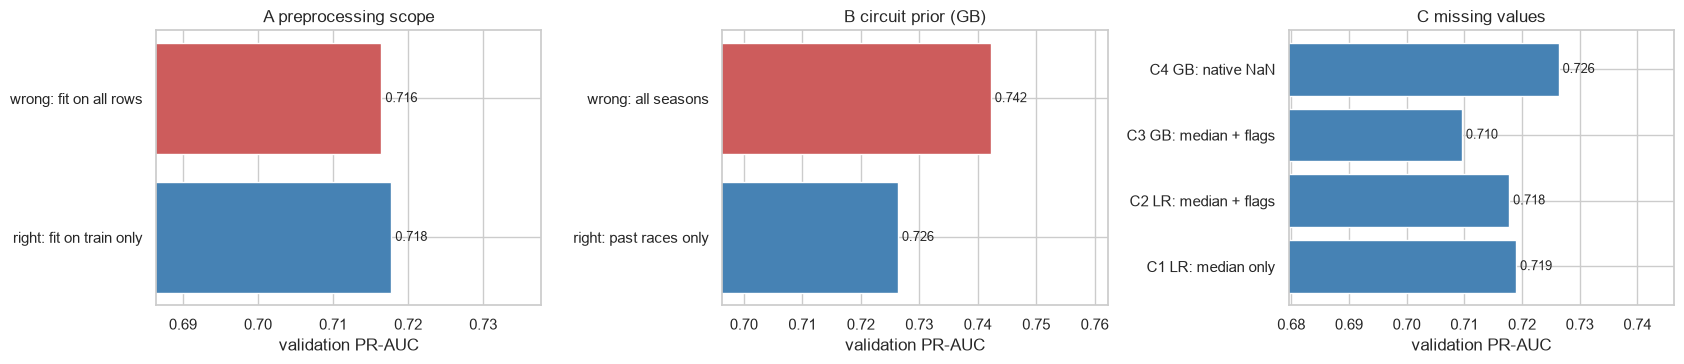

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, exp in zip(axes, ['A preprocessing scope', 'B circuit prior (GB)', 'C missing values']):
    d = prep_exp.loc[exp, 'PR-AUC']
    colors = ['indianred' if v.startswith('wrong') else 'steelblue' for v in d.index]
    ax.barh(d.index, d.values, color=colors)
    ax.set(title=exp, xlabel='validation PR-AUC', xlim=(d.min() - 0.03, d.max() + 0.02))
    for y_, v in enumerate(d.values):
        ax.text(v, y_, f' {v:.3f}', va='center', fontsize=9)
plt.tight_layout()
save_fig(fig, 's5_preprocessing_experiments')
plt.show()

**Interpretation**
* **A — preprocessing scope.** Fitting imputer and scaler on all rows changes validation PR-AUC by only −0.001 (CI
  includes 0): with 22,618 training rows, the ≈ 2,100 validation/test rows move the statistics only a little — but they
  *do* move them (e.g. the mean of `team_starts` +15 %, `drv_starts` +11 %), i.e. information from the evaluation
  seasons enters training. The effect is small here but the order is wrong in principle, so preprocessing is fitted
  **on training rows only, inside each model's pipeline**.
* **B — target-based feature.** This is the clearly harmful order: a circuit prior computed from all seasons includes
  the podiums of the very races being predicted, and inflates validation PR-AUC by **+0.035** for logistic regression
  (CI [+0.006, +0.060], excludes 0) and +0.016 for gradient boosting. The inflated score would not hold on real future
  races. The Step 4 past-only version is kept.
* **C — missing values.** Missing-value flags do not change logistic regression (0.719 vs 0.718, within noise); they
  are kept because they make "no history" explicit at no cost. For gradient boosting, **native NaN handling** beats
  median imputation (+0.017, CI includes 0) — the tree can learn on its own which way a "no past data" row should go.
  **Decision:** logistic regression and the neural network use *median + flags + scaling*; tree models use the raw
  features with native NaN handling where supported.

## 5.7 Data handed to Step 6

In [76]:
X_train, y_train, w_train = X_tr, y_tr, W_TRAIN
X_val, y_val = X_va, y_va
X_test, y_test = test_df[FEATURES], test_df['podium']
ids_val, ids_test = val_df[['raceId', 'driverId', 'year']], test_df[['raceId', 'driverId', 'year']]

def make_preprocessor(scale=True):
    """Experiments A/C: median imputation + missing-value flags (+ scaling) for LR / NN, fitted on train only.
    Tree models use the raw features with native NaN handling instead."""
    steps = [SimpleImputer(strategy='median', add_indicator=True)]
    return make_pipeline(*(steps + [StandardScaler()] if scale else steps))

print({k: v.shape for k, v in {'X_train': X_train, 'X_val': X_val, 'X_test': X_test}.items()})
print(f'training weights: {BEST_WEIGHTING}; min weight {w_train.min():.4f} (season {train_df["year"].min()}), max {w_train.max():.1f}')

drift = pd.DataFrame({'train mean': X_train.mean(), 'validation mean': X_val.mean(), 'test mean': X_test.mean()})
drift['test shift (SD of train)'] = (drift['test mean'] - drift['train mean']) / X_train.std()
display(drift.reindex(drift['test shift (SD of train)'].abs().sort_values(ascending=False).index).head(8).round(3))

{'X_train': (22618, 38), 'X_val': (780, 38), 'X_test': (1357, 38)}
training weights: half-life 5; min weight 0.0001 (season 1950), max 1.0


,train mean,validation mean,test mean,test shift (SD of train)
team_starts,226.497,593.800,647.600,1.952
season,1989.964,2020.564,2023.029,1.804
drv_starts,61.746,121.054,146.322,1.365
quali_source,0.631,0.001,0.000,-1.307
con_form_mech,0.278,0.070,0.064,-1.251
drv_form_dnf,0.421,0.150,0.144,-1.163
years_since_reg_change,4.592,6.564,1.029,-1.033
field_size,22.889,20.000,19.958,-0.972


**Distribution shift to watch in Step 6–7.** Cumulative counts (`team_starts`, `drv_starts`) and `season` take values
in the test seasons that are far beyond the training range (1.4–2 training SDs), and `years_since_reg_change` restarts
at 0–2 in the new 2022 rules era. Tree models cannot extrapolate beyond the largest training value, so these features
may behave differently on the test set — the ablation of the *experience* and *era* groups (Step 7) will show whether
they help or hurt.

### 5.7.1 What the LR / NN preprocessing does to the data
`make_preprocessor()` is fitted on the **training rows only** (inside each LR / NN model in Step 6). It does two things:
1. **Median imputation + missing flags.** Every NaN becomes that feature's training median, and for each of the 18
   features that can be missing, a 0/1 column `missingindicator_<feature>` records that it was missing.
   38 features → **56 columns**.
2. **Standard scaling.** Each column becomes (value − training mean) / training SD, so LR coefficients and NN weights
   act on comparable scales. Without it, `team_starts` (0–991) would dominate a 0–1 feature like `drv_circuit_podium`.

The four features below show the effects:
* `grid_f`: complete;
* `drv_circuit_podium`: 31 % missing (first visit);
* `con_points_share`: 5 % missing (before 1958);
* `team_starts`: a skewed count whose test values exceed the training range.

Tree models skip this step and use the raw values with native NaN.

**Encoding: no label or one-hot encoding is needed, by design.** All 38 features are numeric: positions, counts,
rates, ranks, ratings and 0/1 flags. The categorical columns of the raw tables are turned into **pre-race numeric
summaries** in Step 4 instead of being encoded as categories:

| Categorical source | Becomes (numeric, computed from past races) |
|---|---|
| driver (`driverId`) | form, standings, Elo, starts, age, rookie flag |
| constructor / team lineage | constructor form, team Elo, team starts, mechanical-failure rate |
| circuit | circuit grid-slot prior, overtaking difficulty, circuit history |
| nationality × circuit country | `home_race` flag (0/1) |
| status | past DNF and mechanical-failure rates (never the current race's status) |

Why not one-hot encode driver, team or circuit?
* Identity columns let a model memorise names ("Hamilton → podium") instead of learning signals that transfer across
  seasons.
* Drivers and teams that are new in 2022–24, or renamed, would have no column at all.
* 861 drivers + 112 team lineages + 77 circuits would add about 1,000 sparse columns to 22,618 training rows.

38 input features -> 56 model columns (18 missing-value flags)


,grid_f,drv_circuit_podium,con_points_share,team_starts
% missing (train),0.0,31.359979,5.243611,0.0
raw: min / max,1 / 34,0 / 1,0 / 1,0 / 991
raw: mean / SD,11.956 / 6.836,0.146 / 0.247,0.299 / 0.340,226.497 / 215.756
fill value (median),12.0,0.0,0.142857,156.0
imputed: mean / SD,11.956 / 6.836,0.100 / 0.216,0.291 / 0.332,226.497 / 215.756
scaled: mean / SD,-0.00 / 1.00,-0.00 / 1.00,0.00 / 1.00,0.00 / 1.00
scaled: min / max (train),-1.60 / 3.22,-0.46 / 4.18,-0.88 / 2.13,-1.05 / 3.54
scaled: mean / max (test),-0.21 / 1.32,0.14 / 4.18,0.05 / 2.13,1.95 / 4.04


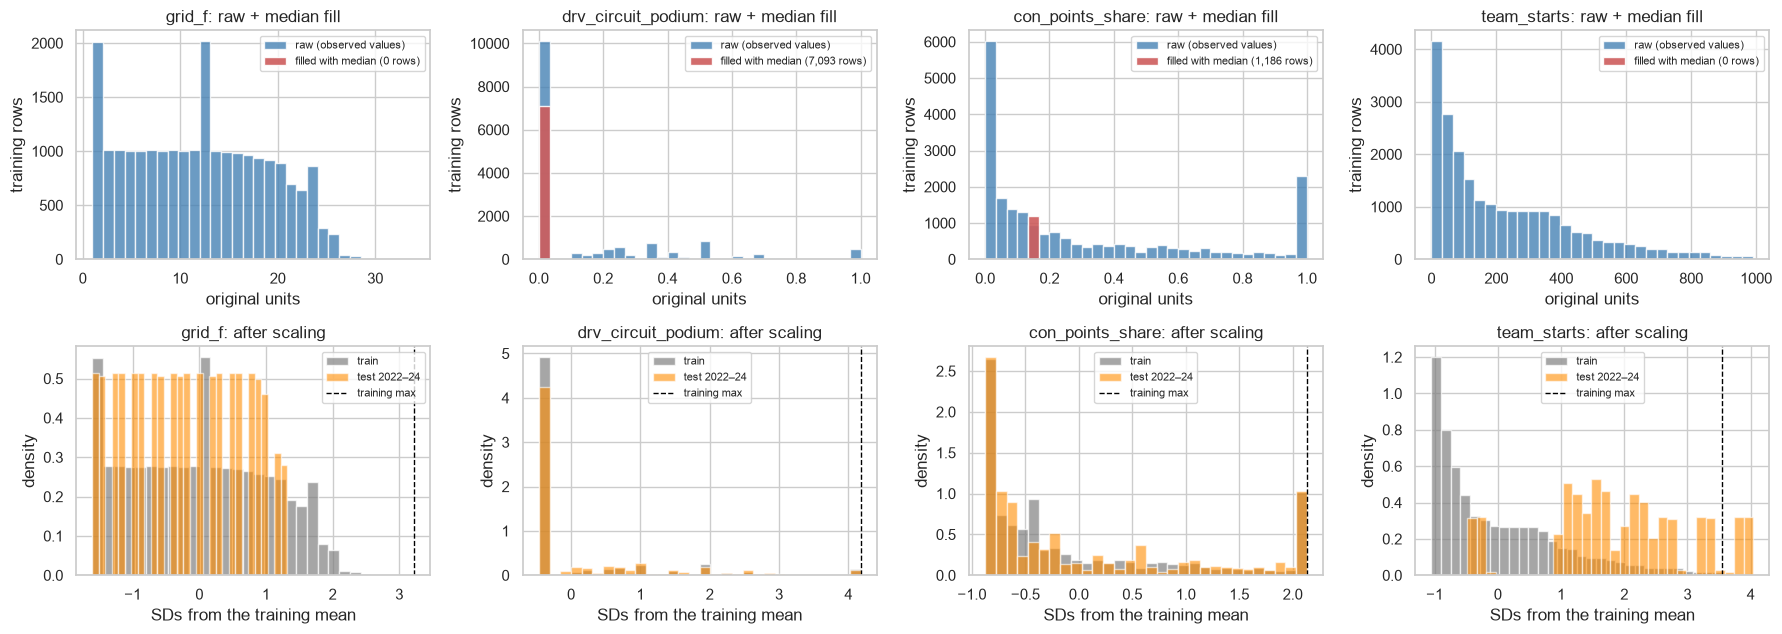

In [77]:
prep_demo = make_preprocessor().fit(X_train)
imp_demo = prep_demo[0]
out_cols = list(prep_demo.get_feature_names_out(FEATURES))
imputed = pd.DataFrame(imp_demo.transform(X_train), columns=out_cols, index=X_train.index)
scaled = {s: pd.DataFrame(prep_demo.transform(X), columns=out_cols, index=X.index)
          for s, X in [('train', X_train), ('test', X_test)]}
flags = [c for c in out_cols if c.startswith('missingindicator_')]
print(f'{len(FEATURES)} input features -> {len(out_cols)} model columns ({len(flags)} missing-value flags)')

PREP_SHOW = ['grid_f', 'drv_circuit_podium', 'con_points_share', 'team_starts']
prep_effect = pd.DataFrame({f: {
    '% missing (train)': 100 * X_train[f].isna().mean(),
    'raw: min / max': f'{X_train[f].min():.3g} / {X_train[f].max():.3g}',
    'raw: mean / SD': f'{X_train[f].mean():.3f} / {X_train[f].std():.3f}',
    'fill value (median)': imp_demo.statistics_[FEATURES.index(f)],
    'imputed: mean / SD': f'{imputed[f].mean():.3f} / {imputed[f].std():.3f}',
    'scaled: mean / SD': f'{scaled["train"][f].mean():.2f} / {scaled["train"][f].std():.2f}',
    'scaled: min / max (train)': f'{scaled["train"][f].min():.2f} / {scaled["train"][f].max():.2f}',
    'scaled: mean / max (test)': f'{scaled["test"][f].mean():.2f} / {scaled["test"][f].max():.2f}',
} for f in PREP_SHOW})
display(prep_effect)

fig, axes = plt.subplots(2, 4, figsize=(18, 6.5))
for j, f in enumerate(PREP_SHOW):
    bins = np.histogram_bin_edges(X_train[f].dropna(), bins=30)
    axes[0, j].hist(X_train[f].dropna(), bins=bins, color='steelblue', alpha=0.8, label='raw (observed values)')
    axes[0, j].hist(imputed[f][X_train[f].isna()], bins=bins, color='indianred', alpha=0.9,
                    label=f'filled with median ({X_train[f].isna().sum():,} rows)')
    axes[0, j].set(title=f'{f}: raw + median fill', xlabel='original units', ylabel='training rows')
    axes[0, j].legend(fontsize=8)
    axes[1, j].hist(scaled['train'][f], bins=30, color='grey', alpha=0.7, density=True, label='train')
    axes[1, j].hist(scaled['test'][f], bins=30, color='darkorange', alpha=0.6, density=True, label='test 2022–24')
    axes[1, j].axvline(scaled['train'][f].max(), color='black', ls='--', lw=1, label='training max')
    axes[1, j].set(title=f'{f}: after scaling', xlabel='SDs from the training mean', ylabel='density')
    axes[1, j].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, 's5_preprocessing_effect')
plt.show()

**Effect of the preprocessing (training rows).**
* **Imputation changes the distribution where values are missing.**
  * `drv_circuit_podium` (31 % missing): the median is 0, so every first visit becomes a spike at 0. The mean falls
    from 0.146 to 0.100 and the SD from 0.247 to 0.216.
  * `con_points_share` (5 % missing): it shifts only slightly (0.299 → 0.291).
  * That is why the **missing flags** are kept. Without them the model could not tell "first visit" from "visited and
    never on the podium", two different situations that now share the value 0.
* **Scaling changes the range, not the shape.** Every column now has mean 0 and SD 1 on the training rows. `grid_f`
  runs from −1.6 to +3.2, `team_starts` from −1.05 to +3.5. The histograms keep their shape: `team_starts` stays
  right-skewed.
* **Test rows are scaled with the training statistics,** so drift stays visible. `team_starts` sits at **+1.95 SD**
  on average in 2022–24, and up to 4.0 vs a training maximum of 3.5. A linear model extrapolates such values; trees cap
  them (checked in Step 7).

## 5.8 Step 5 summary
| Decision | Choice | Evidence |
|---|---|---|
| Split | train ≤ 2019 · validation 2020–21 · test ≥ 2022 (by season) | deployment-like; test = unseen rules era; random split gave no advantage (§5.5) |
| Qualifying for old seasons | `quali_pos` derived from grid where no qualifying row exists, flagged | exact for 98.2 % of 1994–2002 drivers (§5.1) |
| Lap-time features | dropped | PR-AUC change −0.0002 / −0.0037, CIs include 0 (§5.2) |
| Training seasons | **all 1950–2019 kept**, recency weights (half-life 5) | all-season variants beat 2003-only (0.72 vs 0.70); weighting differences within noise (§5.4) |
| Preprocessing scope | fitted on training rows only, inside each pipeline | A: statistics shift up to 15 %; B: leaky target feature inflates PR-AUC by +0.035 (§5.6) |
| Missing values | LR / NN: median + flags + scaling; trees: native NaN | C (§5.6); effect on the data in §5.7.1 (38 → 56 columns) |
| Features | 38 in 10 groups (`FINAL_GROUPS`) | Steps 4–5 |

# 6. Models
Four model families are trained on **the same table, the same 38 `FEATURES` and the same rows** (Section 5.7):
logistic regression (baseline), random forest, gradient boosting and a shallow Keras neural network. Every choice
(hyperparameters, class weighting, post-processing, decision threshold) is made on **validation 2020–21 only**. The test
seasons ≥ 2022 are scored **once**, after everything is frozen (§6.7).

| Attempt | What changes | Section |
|---|---|---|
| 1 | Library defaults, recency weights only | §6.3 |
| 2 | Hyperparameter + class-weight tuning on validation | §6.4 |
| 3 | Race-wise normalisation (exactly 3 podium places per race) and an ensemble of the four tuned models | §6.5 |

## 6.1 Metrics
**Primary metric: PR-AUC (average precision).** Podiums are rare (15 % of starters in 2020–24), and the question
is *"which drivers will finish on the podium?"*. PR-AUC measures how well the podium finishers are ranked at the top,
using only the positive class. A model with no skill scores the positive rate (≈ 0.15), so the scale is honest. ROC-AUC
also rewards correctly ranking the many easy cases at the back of the grid against each other, which says little about
the podium. That is why the grid rule below reaches a high ROC-AUC with a single feature.

**Secondary metric: F1 at the threshold chosen on validation.** A podium *call* needs a yes/no decision. F1 balances
precision ("of the drivers we call, how many make it?") against recall ("of the real podium finishers, how many did we
call?"). Both errors matter equally here. ROC-AUC, precision and recall are reported for every model as well.

**F1-specific diagnostic: top-3 hit rate.** Exactly three drivers stand on the podium in every race. For each race we
take the three highest-scored drivers and count how many actually finished on the podium. This metric needs no threshold
and is easy to explain: "on average, X of our 3 picks per race were right". Ties are broken at random, never by row
order (rows are stored in finishing order).

**Which training rows?** The required *train* scores use all 1950–2019 rows, unweighted. Old seasons had 30+ entrants
and frequent retirements, so they are harder to predict, and full-train scores come out *below* validation. That says
nothing about overfitting. A diagnostic split, **train (2015–19)**, covers the last five training seasons. Their fields
look like validation, so the gap between the two is the honest overfitting check.

**Reference points.** These scores are computed the same way for every split, so the models have a meaningful floor:
* *No skill*: the same score for everybody (ROC-AUC 0.5, PR-AUC = positive rate). Its top-3 hit rate is the expected
  value of 3 random picks per race.
* *Always "no podium"*: never calls a podium. It shows why **accuracy** (also reported, as taught in Lab 2) is
  misleading here: this useless rule is already about 85 % accurate, because 85 % of starters miss the podium.
* *Grid rule*: score = 1 / grid slot, so drivers starting P1–P3 are predicted to finish P1–P3. This is the obvious
  pre-race rule, and any model must beat it to be worth deploying.

In [78]:
import keras
from itertools import product
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, roc_curve,
                             precision_recall_curve, brier_score_loss)
from sklearn.calibration import calibration_curve

RECENT = (train_df['year'] >= 2015).values          # diagnostic: the last 5 training seasons, comparable with validation
XS = {'train': X_train, 'train (2015–19)': X_train[RECENT], 'validation': X_val, 'test': X_test}
YS = {'train': y_train.values, 'train (2015–19)': y_train.values[RECENT], 'validation': y_val.values, 'test': y_test.values}
RACES = {'train': train_df['raceId'].values, 'train (2015–19)': train_df['raceId'].values[RECENT],
         'validation': val_df['raceId'].values, 'test': test_df['raceId'].values}

def top3_hit_rate(y, p, race, seed=SEED):
    """Share of actual podium finishers among each race's 3 highest-scored drivers (ties broken at random)."""
    d = pd.DataFrame({'y': y, 'p': p, 'race': race}).sample(frac=1, random_state=seed)
    return d.sort_values('p', ascending=False, kind='mergesort').groupby('race').head(3)['y'].mean()

def top3_hits_by_race(y, p, race, seed=SEED):
    d = pd.DataFrame({'y': y, 'p': p, 'race': race}).sample(frac=1, random_state=seed)
    return d.sort_values('p', ascending=False, kind='mergesort').groupby('race').head(3).groupby('race')['y'].mean()

def top3_diff_ci(y, p_a, p_b, race, n_boot=2000, seed=SEED):
    """Top-3 hit rate of b minus a, with a 95 % CI from resampling races."""
    diff = (top3_hits_by_race(y, p_b, race) - top3_hits_by_race(y, p_a, race)).values
    boots = np.random.default_rng(seed).choice(diff, (n_boot, len(diff))).mean(axis=1)
    return diff.mean(), *np.percentile(boots, [2.5, 97.5])

def scores(y, p, race, thr):
    yhat = (p >= thr).astype(int)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'F1': f1_score(y, yhat, zero_division=0), 'precision': precision_score(y, yhat, zero_division=0),
            'recall': recall_score(y, yhat, zero_division=0), 'accuracy': accuracy_score(y, yhat),
            'top-3 hit rate': top3_hit_rate(y, p, race)}

assert (pd.concat(XS.values())['grid_f'] >= 1).all()          # pit-lane starters sit behind the last slot
REF = {'no skill (base rate)': lambda X: np.full(len(X), y_train.mean()),
       'always "no podium"': lambda X: np.zeros(len(X)),
       'grid rule (P1–P3)': lambda X: 1 / X['grid_f'].values}
REF_THR = {'no skill (base rate)': y_train.mean(), 'always "no podium"': 0.5, 'grid rule (P1–P3)': 1 / 3}
REF_PRED = {(r, s): f(XS[s]) for r, f in REF.items() for s in XS}
ref_table = pd.DataFrame([{'reference': r, 'split': s, **scores(YS[s], REF_PRED[(r, s)], RACES[s], REF_THR[r])}
                          for r in REF for s in XS]).set_index(['reference', 'split'])
for s in XS:   # a constant score ranks at random: expected hits per pick = podium finishers / starters, averaged over races
    for r in ['no skill (base rate)', 'always "no podium"']:
        ref_table.loc[(r, s), 'top-3 hit rate'] = pd.Series(YS[s]).groupby(RACES[s]).mean().mean()
display(ref_table.round(3))

ROC-AUC  PR-AUC     F1  precision  recall  accuracy  top-3 hit rate
reference            split                                                                               
no skill (base rate) train              0.500   0.134  0.237      0.134   1.000     0.134           0.137
                     train (2015–19)    0.500   0.147  0.257      0.147   1.000     0.147           0.147
                     validation         0.500   0.150  0.261      0.150   1.000     0.150           0.150
                     test               0.500   0.150  0.261      0.150   1.000     0.150           0.150
always "no podium"   train              0.500   0.134  0.000      0.000   0.000     0.866           0.137
                     train (2015–19)    0.500   0.147  0.000      0.000   0.000     0.853           0.147
                     validation         0.500   0.150  0.000      0.000   0.000     0.850           0.150
                     test               0.500   0.150  0.000      0.000   0.000     0.850           0.150
grid rule (P1–P3)    train              0.883   0.498  0.543      0.545   0.541     0.878           0.545
                     train (2015–19)    0.934   0.711  0.723      0.725   0.722     0.919           0.725
                     validation         0.909   0.639  0.692      0.692   0.692     0.908           0.692
                     test               0.914   0.647  0.649      0.650   0.647     0.895           0.652

**Result: the bar any model must clear.**
* **No skill:** PR-AUC equals the positive rate (0.150 on validation and test). Three random picks per race hit the
  podium about 15 % of the time.
* **Grid rule:** validation PR-AUC **0.639**, test **0.647**.
  * Its ROC-AUC is already **0.91** with a single feature. That is why ROC-AUC is not the primary metric: it is high
    for any sensible ranking of the back of the grid.
  * It makes exactly 3 calls per race, so its F1, precision, recall and top-3 hit rate coincide: on validation, 69 % of
    front-three starters finished on the podium.
* **Always "no podium":** accuracy **0.850** on validation and test, with F1, precision and recall all 0. A rule that
  never finds a single podium is already 85 % "accurate", so accuracy cannot be the yardstick. It is reported for
  completeness only.
* **Train (2015–19):** the grid rule scores 0.711, higher than on validation (0.639). The Mercedes-dominated
  2015–19 seasons were simply more predictable. This gap of **0.07 is caused by the era, not by overfitting**, and it is
  the yardstick for the model gaps in §6.7.

## 6.2 Shared set-up — weights, missing values, model factories
* **Sample weights.** Every model is trained with the recency weights from §5.4 (`w_train`, half-life 5 seasons).
  *Class weighting* is a hyperparameter tuned in §6.4. When it is on, the recency weights are rescaled so that podium
  and non-podium rows carry equal total weight. This makes errors on the rare podium class cost more. It changes the
  probability scale, not just the ranking, so each model gets its own threshold (§6.6).
* **Missing values: no rows are removed.** LR and NN use `make_preprocessor()` (median + missing flag + scaling,
  fitted on training rows only, inside the model). RF and gradient boosting use native NaN. The check below shows why
  dropping incomplete rows is not an option.
* **Determinism.** Each Keras network is seeded with `keras.utils.set_random_seed(42)`, and TensorFlow op determinism is
  on. Re-running the notebook gives the same networks.

In [79]:
tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel('ERROR')                       # silence tf.function retracing warnings during the grid search

def class_balanced(w, y):
    """Recency weights rescaled so podium and non-podium rows carry equal total weight (total weight unchanged)."""
    w, y = np.asarray(w, float), np.asarray(y)
    pos, neg = w[y == 1].sum(), w[y == 0].sum()
    return np.where(y == 1, w * (pos + neg) / (2 * pos), w * (pos + neg) / (2 * neg))

W_FIT = {False: np.asarray(w_train, float), True: class_balanced(w_train, y_train)}
for bal, w in W_FIT.items():
    print(f'class weighting {"on " if bal else "off"}: podium share of total training weight = '
          f'{w[y_train.values == 1].sum() / w.sum():.3f}')
print(f'effective training sample size under recency weights (Kish): {w_train.sum() ** 2 / (w_train ** 2).sum():,.0f} '
      f'of {len(w_train):,} rows')

class ExactPRAUC(keras.callbacks.Callback):
    """Exact (sklearn) PR-AUC after every epoch. Keras' own AUC metric interpolates over 200 fixed thresholds and is
    sample-weighted, which distorts it when class weights push probabilities towards 1."""
    def __init__(self, Xv, yv, Xt=None, yt=None):
        super().__init__()
        self.Xv, self.yv, self.Xt, self.yt = Xv, yv, Xt, yt

    def on_epoch_end(self, epoch, logs=None):
        logs['val_ap'] = average_precision_score(self.yv, self.model.predict(self.Xv, batch_size=4096, verbose=0).ravel())
        if self.Xt is not None:
            logs['train_ap'] = average_precision_score(self.yt, self.model.predict(self.Xt, batch_size=4096, verbose=0).ravel())

class KerasPodium:
    """Shallow Keras network with its own train-fitted preprocessor (median + flags + scaling).
    Early stopping monitors the exact validation PR-AUC and restores the best epoch's weights.
    With track_train=True the (unweighted) PR-AUC on training seasons 2015–19 is also recorded per epoch."""
    def __init__(self, hidden=(32,), dropout=0.0, lr=1e-3, batch_size=256, max_epochs=300, patience=20, track_train=False,
                 early_stopping=True):
        self.hidden, self.dropout, self.lr = tuple(hidden), dropout, lr
        self.batch_size, self.max_epochs, self.patience, self.track_train = batch_size, max_epochs, patience, track_train
        self.early_stopping = early_stopping

    def fit(self, X, y, sample_weight, X_val, y_val):
        keras.utils.set_random_seed(SEED)
        self.prep = make_preprocessor().fit(X)
        Xt, Xv = (self.prep.transform(d).astype('float32') for d in (X, X_val))
        layers = [keras.Input((Xt.shape[1],))]
        for units in self.hidden:
            layers.append(keras.layers.Dense(units, activation='relu'))
            if self.dropout:
                layers.append(keras.layers.Dropout(self.dropout))
        self.net = keras.Sequential(layers + [keras.layers.Dense(1, activation='sigmoid')])
        self.net.compile(keras.optimizers.Adam(self.lr), 'binary_crossentropy')
        w = np.asarray(sample_weight, float)
        exact = ExactPRAUC(Xv, np.asarray(y_val), *((self.prep.transform(X_train[RECENT]).astype('float32'),
                                                     y_train.values[RECENT]) if self.track_train else ()))
        stop = keras.callbacks.EarlyStopping(monitor='val_ap', mode='max', patience=self.patience, restore_best_weights=True)
        self.history = self.net.fit(Xt, np.asarray(y), sample_weight=w / w.mean(), validation_data=(Xv, np.asarray(y_val)),
                                    epochs=self.max_epochs, batch_size=self.batch_size, verbose=0,
                                    callbacks=[exact, stop] if self.early_stopping else [exact]).history
        # the epoch whose weights the model keeps: the best one with early stopping, otherwise the last one
        self.best_epoch = int(np.argmax(self.history['val_ap'])) + 1 if self.early_stopping else len(self.history['loss'])
        return self

    def predict_proba(self, X):
        p = self.net.predict(self.prep.transform(X).astype('float32'), batch_size=4096, verbose=0).ravel()
        return np.column_stack([1 - p, p])

NAMES = {'LR': 'Logistic regression', 'RF': 'Random forest', 'GB': 'Gradient boosting', 'NN': 'Neural network'}

def make_model(family, hp):
    hp = dict(hp)
    if family == 'LR':
        return make_pipeline(make_preprocessor(), LogisticRegression(C=hp.get('C', 1.0), max_iter=5000))
    if family == 'RF':
        return RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **hp)
    if family == 'GB':
        return HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **hp)
    return KerasPodium(**hp)

def fit_model(family, hp=None, balanced=False, rows=None):
    """Fit one model on the training seasons (optionally a subset of rows) with recency (x class) weights."""
    X, y, w = X_train, y_train.values, W_FIT[balanced]
    if rows is not None:
        X, y, w = X[rows], y[rows], w[rows]
    model = make_model(family, hp or {})
    if family == 'LR':
        model.fit(X, y, logisticregression__sample_weight=w)
    elif family == 'NN':
        model.fit(X, y, w, X_val, y_val.values)
    else:
        model.fit(X, y, sample_weight=w)
    return model

proba = lambda model, X: model.predict_proba(X)[:, 1]

class weighting off: podium share of total training weight = 0.141
class weighting on : podium share of total training weight = 0.500
effective training sample size under recency weights (Kish): 5,816 of 22,618 rows


### 6.2.1 Missing values: keep the rows or drop them?
37 % of training rows have at least one missing feature. These values are not errors. They are histories that **do not
exist yet**: a driver's debut, a first visit to a circuit, a team's first race, the seasons before the constructors'
championship (1950–57). The test below compares the chosen handling with training on complete rows only (validation rows
are always kept, because a model must still predict a rookie at deployment).

In [80]:
miss_cols = [c for c in FEATURES if X_train[c].isna().any()]
has_nan = {s: XS[s][miss_cols].isna().any(axis=1).values for s in XS}
mv_overview = pd.DataFrame({s: {'rows with ≥1 NaN': has_nan[s].mean(), 'podium rate (NaN rows)': YS[s][has_nan[s]].mean(),
                                'podium rate (complete rows)': YS[s][~has_nan[s]].mean(),
                                'podiums inside NaN rows': YS[s][has_nan[s]].sum()} for s in XS}).T
display(mv_overview.round(3))
debut = X_train['drv_form_podium'].isna().values
print(f'debut races (no driver form): podium rate {y_train.values[debut].mean():.3f} vs {y_train.values[~debut].mean():.3f}')

mv_rows, mv_pred = [], {}
for fam, hp in [('LR', {}), ('GB', {'learning_rate': 0.05, 'max_iter': 300})]:
    for variant, rows in [('keep all rows', None), ('drop rows with NaN', ~has_nan['train'])]:
        p = mv_pred[(fam, variant)] = proba(fit_model(fam, hp, rows=rows), X_val)
        nv = has_nan['validation']
        mv_rows.append({'model': NAMES[fam], 'training rows': variant, 'n train': len(X_train) if rows is None else rows.sum(),
                        'val PR-AUC': average_precision_score(y_val, p),
                        'val PR-AUC (NaN rows)': average_precision_score(y_val[nv], p[nv]),
                        'val PR-AUC (complete rows)': average_precision_score(y_val[~nv], p[~nv])})
    lo, hi = race_bootstrap_ci(y_val, mv_pred[(fam, 'keep all rows')], mv_pred[(fam, 'drop rows with NaN')], RACES['validation'])
    mv_rows[-1]['95 % CI (drop − keep)'] = f'[{lo:+.4f}, {hi:+.4f}]'
display(pd.DataFrame(mv_rows).set_index(['model', 'training rows']).round(4))

lr_const = make_pipeline(SimpleImputer(strategy='constant', fill_value=-1, add_indicator=True), StandardScaler(),
                         LogisticRegression(max_iter=5000))
lr_const.fit(X_train, y_train, logisticregression__sample_weight=w_train)
print(f'LR with fill value −1 instead of the median (+ flags): val PR-AUC '
      f'{average_precision_score(y_val, proba(lr_const, X_val)):.4f} — the fill value hardly matters once a flag exists')

,rows with ≥1 NaN,podium rate (NaN rows),podium rate (complete rows),podiums inside NaN rows
train,0.373,0.075,0.170,633.0
train (2015–19),0.232,0.023,0.185,11.0
validation,0.283,0.086,0.175,19.0
test,0.123,0.048,0.165,8.0


debut races (no driver form): podium rate 0.025 vs 0.138


n train  val PR-AUC  val PR-AUC (NaN rows)  val PR-AUC (complete rows) 95 % CI (drop − keep)
model               training rows                                                                                                   
Logistic regression keep all rows         22618      0.7178                 0.8326                      0.6955                   NaN
                    drop rows with NaN    14185      0.7185                 0.8608                      0.6886    [-0.0180, +0.0210]
Gradient boosting   keep all rows         22618      0.7127                 0.8526                      0.6780                   NaN
                    drop rows with NaN    14185      0.7083                 0.8425                      0.6753    [-0.0413, +0.0289]

LR with fill value −1 instead of the median (+ flags): val PR-AUC 0.7183 — the fill value hardly matters once a flag exists


**Result: keep every row.**
* **The missing values carry information.** Rows with a missing feature have a podium rate of 7.5 % vs 17.0 % for
  complete rows. A debut race gives a podium 2.5 % of the time vs 13.8 %. A missing flag lets the model learn this;
  deleting the rows throws it away.
* **Dropping rows gains nothing.** Training on complete rows only (14,185 of 22,618) changes validation PR-AUC by
  +0.0007 for LR (95 % CI [−0.018, +0.021]) and −0.0044 for gradient boosting ([−0.041, +0.029]). Both are noise.
* **Removal is not possible anyway.**
  * It would delete 633 training podiums.
  * It would delete all of 1950–57, which has no constructors' championship.
  * At prediction time a rookie or a new circuit still needs a prediction. 12 % of test rows have a missing feature,
    and 19 of the 117 validation podiums sit in such rows: Hamilton, Bottas and Verstappen at the new 2020–21 circuits.
* **The median is not a guess.** With a missing flag, LR learns its own constant for "no history". Filling with −1
  instead of the median gives 0.7183 vs 0.7178. The imputed value is just a placeholder.
* **Decision:** LR/NN use median + flags + scaling; RF and gradient boosting use native NaN; no rows are removed.

### 6.2.2 How each model works
All four models receive the same 38 pre-race features of one driver in one race and output **P(podium)**. They
differ in *how* they turn the features into that probability.

**Logistic regression (LR), the baseline.**
* **Mechanism:** a weighted sum of the (imputed, scaled) features, z = b₀ + b₁x₁ + … + bₖxₖ, is turned into a
  probability by the logistic function p = 1 / (1 + e^(−z)). Training finds the weights b that maximise the
  (sample-weighted) likelihood of the observed podiums. An L2 penalty, set by `C`, shrinks the weights so that
  correlated features (standings, form, Elo) cannot take extreme opposite values.
* **Why it fits:** each feature has one direction ("better grid → more likely"), which matches how most F1 signals
  behave.
* **Limit:** effects are additive and only bend through the logistic curve. "Starting P1–P3 is very different from P4+"
  must come from the features themselves.

**Random forest (RF).**
* **Mechanism:** 300 decision trees. Each tree splits the training rows by yes/no questions on single features
  ("`grid_f` ≤ 3.5?", "`team_elo` > 1,650?") until the leaves are small, choosing at each split the question that best
  separates podium from non-podium rows. Every tree sees a bootstrap sample of the rows and only a random √p subset of
  features at each split, so the trees differ. A leaf's podium rate is the tree's prediction, and the forest averages
  all 300 trees. Missing values are sent down the branch learned for them.
* **Why it fits:** it captures thresholds and interactions ("front row *and* strong car") automatically, without
  scaling.
* **Limit:** fully grown trees memorise single races (§6.3), so depth and leaf size must be limited. It cannot predict
  beyond the range of values seen in training.

**Gradient boosting (GB, `HistGradientBoostingClassifier`).**
* **Mechanism:** also trees, but built **one after another**. It starts from the average podium rate. Each new small
  tree (a few leaves) is fitted to the current errors, more precisely to the gradient of the log-loss, and its
  prediction is added, scaled down by the learning rate. After *n* trees, the sum of all trees (in log-odds) is turned
  into a probability. Features are binned into at most 255 values for speed. Missing values get their own learned
  direction at every split.
* **Why it fits:** step-by-step error correction usually gives the most accurate tree model on tabular data.
* **Limit:** too many trees fit noise, so the number of trees and the learning rate must be tuned. Like the RF, it
  cannot extrapolate.

**Neural network (NN), shallow feed-forward (Keras).**
* **Mechanism:** the imputed, scaled features (56 columns) feed one or two hidden layers of ReLU units
  (h = max(0, Wx + b)). Each unit learns its own combination of features. A single sigmoid output unit gives P(podium).
  Training minimises the sample-weighted binary cross-entropy with the Adam optimiser in mini-batches of 256 rows.
  Dropout (optional) randomly switches off units during training. Early stopping keeps the epoch with the best
  validation PR-AUC.
* **Why it fits:** flexible non-linear combinations, the course's shallow-network requirement, and a check whether
  anything beyond trees and linear models is needed.
* **Limit:** many settings, sensitivity to the random seed, and the hardest model to explain (Step 7 uses SHAP and
  LIME for this).

## 6.3 Attempt 1 — library defaults
The starting point for each family uses default settings and no class weighting:
* **LR:** `C = 1`.
* **RF:** 300 fully grown trees, `max_features = √p`.
* **Gradient boosting:** `HistGradientBoostingClassifier` defaults (learning rate 0.1, 100 trees, 31 leaves).
* **NN:** one hidden layer of 32 ReLU units, no dropout, Adam (learning rate 0.001), batch 256, early stopping
  (patience 20).

The training-set PR-AUC is shown next to validation to expose overfitting.

In [81]:
P_VAL = {}                                            # (attempt, family) -> validation probabilities
attempt1 = {fam: fit_model(fam, {'track_train': True} if fam == 'NN' else None) for fam in NAMES}
a1_rows = []
for fam, m in attempt1.items():
    P_VAL[('1 defaults', fam)] = pv = proba(m, X_val)
    a1_rows.append({'model': NAMES[fam], 'train PR-AUC': average_precision_score(y_train, proba(m, X_train)),
                    'train (2015–19) PR-AUC': average_precision_score(YS['train (2015–19)'], proba(m, XS['train (2015–19)'])),
                    'val PR-AUC': average_precision_score(y_val, pv), 'val ROC-AUC': roc_auc_score(y_val, pv),
                    'val top-3 hit rate': top3_hit_rate(y_val.values, pv, RACES['validation'])})
a1_table = pd.DataFrame(a1_rows).set_index('model')
a1_table['train (2015–19) − val'] = a1_table['train (2015–19) PR-AUC'] - a1_table['val PR-AUC']
display(a1_table.round(4))
print(f'NN (defaults) stopped at epoch {attempt1["NN"].best_epoch} of {len(attempt1["NN"].history["loss"])} run')

,train PR-AUC,train (2015–19) PR-AUC,val PR-AUC,val ROC-AUC,val top-3 hit rate,train (2015–19) − val
model,,,,,,
Logistic regression,0.5526,0.7545,0.7178,0.9282,0.6838,0.0368
Random forest,0.8473,1.0000,0.6697,0.9155,0.6923,0.3303
Gradient boosting,0.7281,1.0000,0.6961,0.9277,0.6838,0.3039
Neural network,0.4436,0.7690,0.7241,0.9233,0.6923,0.0449


NN (defaults) stopped at epoch 19 of 39 run


**Result.**
* **Validation PR-AUC with defaults:** NN 0.724, LR 0.718, gradient boosting 0.696, RF **0.670**. Every model beats the
  grid rule (0.639).
* **The default trees memorise the training data.** RF and gradient boosting reach PR-AUC **1.000** on train (2015–19),
  vs 0.67 / 0.70 on validation.
  * Fully grown trees, or 31-leaf boosting, isolate individual driver-races.
  * Recency weights make it worse: the effective training size is only about 5,800 rows (Kish), concentrated in the
    recent seasons.
* **The simple models generalise.** LR and NN gaps are 0.04, smaller than the era gap of the grid rule (0.07).
* **Tie with the grid rule on top-3 hit rate:** 0.68–0.69, the same as the grid rule's 0.692. Picking each race's
  three most likely drivers is mostly decided by the grid. §6.7 checks this on test.

→ RF and gradient boosting need **regularisation**, which is what Attempt 2 tunes.

## 6.4 Attempt 2 — hyperparameter and class-weight tuning (validation only)
Each family gets a grid over the settings that control its complexity, crossed with class weighting on/off. The
configuration with the highest **validation PR-AUC** is kept.
* **LR:** regularisation strength `C` (9 values, 0.001–10).
* **RF:** `max_depth` × `min_samples_leaf` × `max_features` (32 combinations), 300 trees. Shallower trees and bigger leaves
  regularise a forest that otherwise memorises the training rows.
* **Gradient boosting:** learning rate × `max_leaf_nodes` × `min_samples_leaf`. The number of trees is read off
  `staged_predict_proba` at 7 checkpoints, so it is tuned without refitting (16 settings × 7 tree counts).
* **NN:** architecture (1 or 2 hidden layers, 16–64 units) × dropout (10 combinations). The number of epochs comes from
  early stopping.

Every combination is run with class weighting off and on, giving 18 / 64 / 224 / 20 configurations.

With 39 validation races, the winner of a large grid is partly luck. So the table reports the gain over the defaults with
a race-bootstrap CI, and the plots show how flat each grid is.

In [82]:
GRIDS = {
    'LR': [{'C': C} for C in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]],
    'RF': [{'max_depth': d, 'min_samples_leaf': l, 'max_features': f}
           for d, l, f in product([6, 10, 14, None], [1, 5, 20, 50], ['sqrt', 0.5])],
    'GB': [{'learning_rate': lr, 'max_leaf_nodes': n, 'min_samples_leaf': l, 'max_iter': 400}
           for lr, n, l in product([0.03, 0.1], [4, 8, 16, 31], [20, 100])],
    'NN': [{'hidden': h, 'dropout': d} for h, d in product([(16,), (32,), (64,), (32, 16), (64, 32)], [0.0, 0.3])],
}
GB_CHECKPOINTS = [25, 50, 100, 150, 200, 300, 400]

tune_rows = []
for fam, grid in GRIDS.items():
    for hp, bal in product(grid, [False, True]):
        m = fit_model(fam, hp, bal)
        if fam == 'GB':
            for it, pv in enumerate(m.staged_predict_proba(X_val), start=1):
                if it in GB_CHECKPOINTS:
                    tune_rows.append({'family': fam, 'hp': {**hp, 'max_iter': it}, 'balanced': bal,
                                      'val PR-AUC': average_precision_score(y_val, pv[:, 1])})
        else:
            tune_rows.append({'family': fam, 'hp': hp, 'balanced': bal, 'val PR-AUC': average_precision_score(y_val, proba(m, X_val)),
                              'epochs': m.best_epoch if fam == 'NN' else np.nan})
tuning = pd.DataFrame(tune_rows)
tuning['config'] = tuning['hp'].map(lambda d: ', '.join(f'{k}={v}' for k, v in d.items()))
print({fam: int((tuning['family'] == fam).sum()) for fam in NAMES}, 'configurations evaluated')

best_idx = tuning.groupby('family')['val PR-AUC'].idxmax()
BEST_HP = {fam: tuning.loc[i, 'hp'] for fam, i in best_idx.items()}
BEST_BAL = {fam: bool(tuning.loc[i, 'balanced']) for fam, i in best_idx.items()}
for fam in NAMES:
    top = tuning[tuning['family'] == fam].nlargest(5, 'val PR-AUC')[['config', 'balanced', 'val PR-AUC']]
    print(f'\n{NAMES[fam]} — top 5 of {(tuning["family"] == fam).sum()}  (val PR-AUC spread over the grid: '
          f'{tuning.loc[tuning["family"] == fam, "val PR-AUC"].min():.3f}–{top["val PR-AUC"].max():.3f})')
    with pd.option_context('display.max_colwidth', 120):
        display(top.round(4).reset_index(drop=True))

{'LR': 18, 'RF': 64, 'GB': 224, 'NN': 20} configurations evaluated

Logistic regression — top 5 of 18  (val PR-AUC spread over the grid: 0.716–0.723)


,config,balanced,val PR-AUC
0,C=0.003,False,0.7229
1,C=0.1,False,0.7204
2,C=1,True,0.7201
3,C=3,True,0.7195
4,C=0.1,True,0.7194



Random forest — top 5 of 64  (val PR-AUC spread over the grid: 0.637–0.745)


,config,balanced,val PR-AUC
0,"max_depth=6, min_samples_leaf=50, max_features=sqrt",False,0.7450
1,"max_depth=14, min_samples_leaf=20, max_features=sqrt",False,0.7431
2,"max_depth=None, min_samples_leaf=20, max_features=sqrt",False,0.7427
3,"max_depth=None, min_samples_leaf=50, max_features=0.5",False,0.7419
4,"max_depth=14, min_samples_leaf=50, max_features=0.5",False,0.7414



Gradient boosting — top 5 of 224  (val PR-AUC spread over the grid: 0.632–0.742)


,config,balanced,val PR-AUC
0,"learning_rate=0.03, max_leaf_nodes=8, min_samples_leaf=100, max_iter=100",False,0.7422
1,"learning_rate=0.03, max_leaf_nodes=31, min_samples_leaf=100, max_iter=50",False,0.7417
2,"learning_rate=0.1, max_leaf_nodes=4, min_samples_leaf=20, max_iter=25",False,0.7417
3,"learning_rate=0.03, max_leaf_nodes=4, min_samples_leaf=20, max_iter=50",False,0.7409
4,"learning_rate=0.03, max_leaf_nodes=4, min_samples_leaf=100, max_iter=50",False,0.7409



Neural network — top 5 of 20  (val PR-AUC spread over the grid: 0.721–0.738)


,config,balanced,val PR-AUC
0,"hidden=(16,), dropout=0.0",True,0.7383
1,"hidden=(64, 32), dropout=0.3",False,0.7375
2,"hidden=(64,), dropout=0.3",True,0.7354
3,"hidden=(32,), dropout=0.3",True,0.7343
4,"hidden=(64,), dropout=0.3",False,0.7336


,chosen settings,class weighting,train (2015–19) PR-AUC,val PR-AUC (defaults),val PR-AUC (tuned),gain 95 % CI
model,,,,,,
Logistic regression,C=0.003,False,0.7460,0.7178,0.7229,"[-0.0259, +0.0411]"
Random forest,"max_depth=6, min_samples_leaf=50, max_features=sqrt",False,0.8352,0.6697,0.7450,"[+0.0345, +0.0999]"
Gradient boosting,"learning_rate=0.03, max_leaf_nodes=8, min_samples_leaf=100, max_iter=100",False,0.8245,0.6961,0.7422,"[+0.0071, +0.0765]"
Neural network,"hidden=(16,), dropout=0.0",True,0.7867,0.7241,0.7383,"[-0.0069, +0.0353]"


NN (tuned) stopped at epoch 56


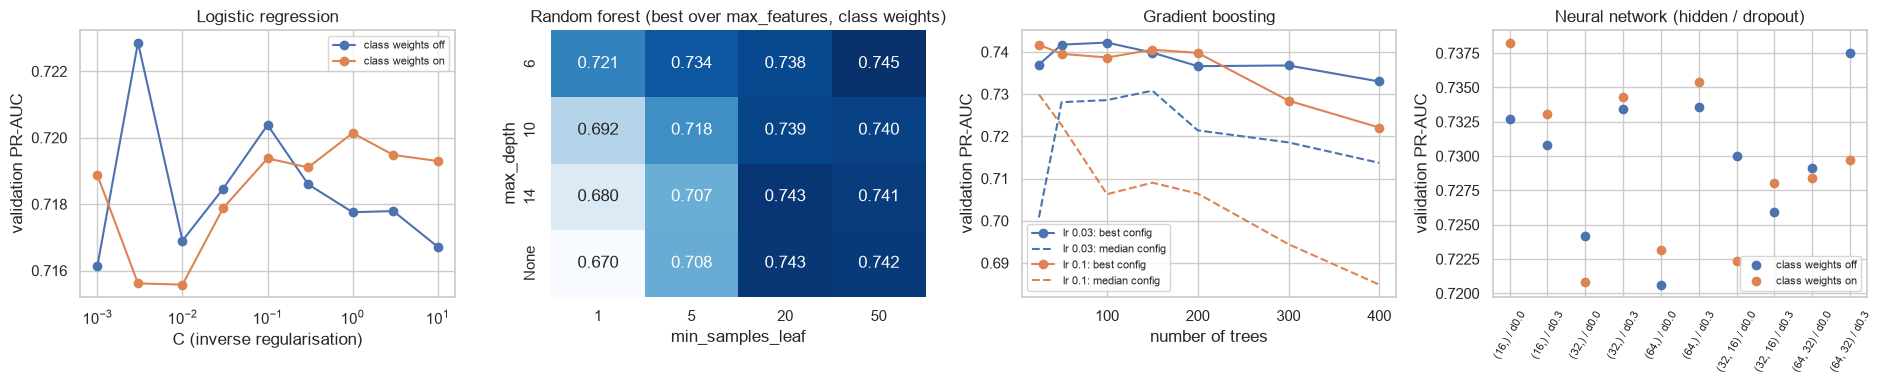

In [83]:
tuned = {fam: fit_model(fam, {**BEST_HP[fam], **({'track_train': True} if fam == 'NN' else {})}, BEST_BAL[fam])
         for fam in NAMES}
t_rows = []
for fam, m in tuned.items():
    P_VAL[('2 tuned', fam)] = pv = proba(m, X_val)
    assert abs(average_precision_score(y_val, pv) - tuning.loc[best_idx[fam], 'val PR-AUC']) < 1e-9   # refit is identical
    lo, hi = race_bootstrap_ci(y_val, P_VAL[('1 defaults', fam)], pv, RACES['validation'])
    t_rows.append({'model': NAMES[fam], 'chosen settings': tuning.loc[best_idx[fam], 'config'], 'class weighting': BEST_BAL[fam],
                   'train (2015–19) PR-AUC': average_precision_score(YS['train (2015–19)'], proba(m, XS['train (2015–19)'])),
                   'val PR-AUC (defaults)': average_precision_score(y_val, P_VAL[('1 defaults', fam)]),
                   'val PR-AUC (tuned)': average_precision_score(y_val, pv), 'gain 95 % CI': f'[{lo:+.4f}, {hi:+.4f}]'})
tuned_table = pd.DataFrame(t_rows).set_index('model')
with pd.option_context('display.max_colwidth', 120):
    display(tuned_table.round(4))
print(f'NN (tuned) stopped at epoch {tuned["NN"].best_epoch}')

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
cw_label = {False: 'class weights off', True: 'class weights on'}
d = tuning[tuning['family'] == 'LR'].assign(C=lambda t: t['hp'].map(lambda h: h['C']))
for bal, g in d.groupby('balanced'):
    axes[0].plot(g['C'], g['val PR-AUC'], marker='o', label=cw_label[bal])
axes[0].set(xscale='log', xlabel='C (inverse regularisation)', title='Logistic regression')
d = tuning[tuning['family'] == 'RF'].assign(depth=lambda t: t['hp'].map(lambda h: str(h['max_depth'])),
                                            leaf=lambda t: t['hp'].map(lambda h: h['min_samples_leaf']))
sns.heatmap(d.pivot_table(index='depth', columns='leaf', values='val PR-AUC', aggfunc='max')
            .reindex(['6', '10', '14', 'None']), annot=True, fmt='.3f', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set(title='Random forest (best over max_features, class weights)', xlabel='min_samples_leaf', ylabel='max_depth')
d = tuning[tuning['family'] == 'GB'].assign(it=lambda t: t['hp'].map(lambda h: h['max_iter']),
                                            lr=lambda t: t['hp'].map(lambda h: h['learning_rate']))
for lr_, g in d.groupby('lr'):
    g = g.groupby('it')['val PR-AUC'].agg(['max', 'median'])
    line, = axes[2].plot(g.index, g['max'], marker='o', label=f'lr {lr_}: best config')
    axes[2].plot(g.index, g['median'], ls='--', color=line.get_color(), label=f'lr {lr_}: median config')
axes[2].set(xlabel='number of trees', title='Gradient boosting')
d = tuning[tuning['family'] == 'NN']
for bal, g in d.groupby('balanced'):
    axes[3].scatter(range(len(g)), g['val PR-AUC'], label=cw_label[bal])
axes[3].set_xticks(range(len(GRIDS['NN'])), [c.replace('hidden=', '').replace(', dropout=', ' / d') for c in d['config'].unique()],
                   rotation=60, fontsize=8)
axes[3].set(title='Neural network (hidden / dropout)')
for ax in [axes[0], axes[2], axes[3]]:
    ax.set_ylabel('validation PR-AUC'); ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, 's6_tuning')
plt.show()

**Result.** Chosen settings (validation PR-AUC, gain over defaults with 95 % CI):

| Model | Chosen | Val PR-AUC | Gain [CI] |
|---|---|---|---|
| LR | C = 0.003, no class weights | 0.723 | +0.005 [−0.026, +0.041] |
| RF | max_depth 6, min_samples_leaf 50, √p features, no class weights | **0.745** | +0.075 [+0.035, +0.100] |
| Gradient boosting | learning rate 0.03, 8 leaves, min_samples_leaf 100, 100 trees, no class weights | 0.742 | +0.046 [+0.007, +0.077] |
| NN | 1 × 16 units, no dropout, class weights on | 0.738 | +0.014 [−0.007, +0.035] |

* **Regularising the trees is the only significant improvement.**
  * The RF heatmap shows that **leaf size** matters most: 0.67–0.72 with 1-row leaves, 0.74 with 20–50-row leaves.
    Train (2015–19) PR-AUC falls from 1.000 to 0.835.
  * Gradient boosting peaks at **50–150 trees** and gets worse with more trees, most clearly at learning rate 0.1. The
    median configuration falls from 0.73 to 0.69 at 400 trees, which is classic boosting overfitting.
* **LR and NN are insensitive to their settings.** The LR grid spans only 0.716–0.723 and the NN grid 0.721–0.738.
  Neither gain is significant. The data has a mostly monotone, additive structure (better grid, form and standings
  → more podiums), which a regularised linear model already captures.
* **Class weighting helped only the NN** (barely). For LR, RF and gradient boosting the unweighted version ranked best.
  PR-AUC depends only on the ranking, and reweighting rarely improves a ranking. It does distort probabilities: the
  class-weighted NN predicts 5.3 podiums per race (§6.5).
* **Caveat:** the best of 18–224 configurations on 39 races is optimistically selected. The validation scores of tuned
  models are biased upwards. The **test** set (§6.7) gives the unbiased estimate.

### 6.4.1 Does early stopping matter? (neural network)
Lab 3 compares a network trained for a fixed number of epochs with one that uses early stopping. Same comparison here:
the **tuned** network (same architecture, weights and seed), once with early stopping (patience 20, best epoch
restored) and once trained for a fixed **200 epochs** keeping the final weights. Both are scored on train (2015–19) and
validation; the test set stays untouched.

,epochs trained,weights from epoch,train (2015–19) PR-AUC,val PR-AUC,val ROC-AUC,val log-loss,train − val PR-AUC
NN,,,,,,,
early stopping (tuned),76,56,0.7867,0.7383,0.9269,0.3047,0.0484
"no early stopping, 200 epochs",200,200,0.8226,0.7215,0.9222,0.3049,0.1011


val PR-AUC change without early stopping: 95 % CI [-0.0496, +0.0122]


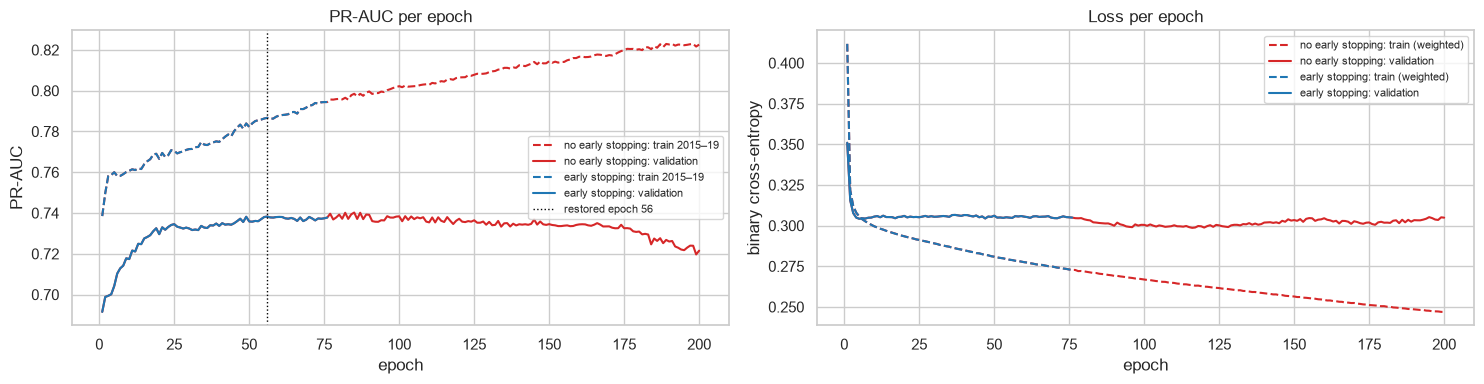

In [84]:
nn_no_es = fit_model('NN', {**BEST_HP['NN'], 'track_train': True, 'early_stopping': False, 'max_epochs': 200},
                     BEST_BAL['NN'])
es_rows = []
for label, m in [('early stopping (tuned)', tuned['NN']), ('no early stopping, 200 epochs', nn_no_es)]:
    pv = proba(m, X_val)
    es_rows.append({'NN': label, 'epochs trained': len(m.history['loss']), 'weights from epoch': m.best_epoch,
                    'train (2015–19) PR-AUC': average_precision_score(YS['train (2015–19)'], proba(m, XS['train (2015–19)'])),
                    'val PR-AUC': average_precision_score(y_val, pv), 'val ROC-AUC': roc_auc_score(y_val, pv),
                    'val log-loss': float(np.mean(-(y_val * np.log(np.clip(pv, 1e-7, 1)) +
                                                    (1 - y_val) * np.log(np.clip(1 - pv, 1e-7, 1)))))})
es_table = pd.DataFrame(es_rows).set_index('NN')
es_table['train − val PR-AUC'] = es_table['train (2015–19) PR-AUC'] - es_table['val PR-AUC']
display(es_table.round(4))
lo, hi = race_bootstrap_ci(y_val, proba(tuned['NN'], X_val), proba(nn_no_es, X_val), RACES['validation'])
print(f'val PR-AUC change without early stopping: 95 % CI [{lo:+.4f}, {hi:+.4f}]')

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for m, label, color in [(nn_no_es, 'no early stopping', 'tab:red'), (tuned['NN'], 'early stopping', 'tab:blue')]:
    h = pd.DataFrame(m.history, index=np.arange(1, len(m.history['loss']) + 1))
    axes[0].plot(h.index, h['train_ap'], color=color, ls='--', label=f'{label}: train 2015–19')
    axes[0].plot(h.index, h['val_ap'], color=color, label=f'{label}: validation')
    axes[1].plot(h.index, h['loss'], color=color, ls='--', label=f'{label}: train (weighted)')
    axes[1].plot(h.index, h['val_loss'], color=color, label=f'{label}: validation')
axes[0].axvline(tuned['NN'].best_epoch, color='black', ls=':', lw=1, label=f'restored epoch {tuned["NN"].best_epoch}')
axes[0].set(xlabel='epoch', ylabel='PR-AUC', title='PR-AUC per epoch')
axes[1].set(xlabel='epoch', ylabel='binary cross-entropy', title='Loss per epoch')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, 's6_nn_early_stopping')
plt.show()

**Result: early stopping is kept.**
* **The two runs are identical up to epoch 76.** Same seed, same data order, so the curves coincide. Early stopping
  halts there and restores the weights of epoch **56**, its best validation PR-AUC.
* **Without early stopping the network keeps memorising the training seasons.**
  * Train (2015–19) PR-AUC climbs to **0.823** and the weighted training loss keeps falling.
  * Validation PR-AUC drifts down to **0.722** (vs 0.738), with the steepest fall after about epoch 175.
  * The train − validation gap doubles, from 0.048 to **0.101**: classic overfitting, as in Lab 3.
* **On 39 validation races the loss is not significant** (−0.017, 95 % CI [−0.050, +0.012]). But the direction is
  clear in the curves, and early stopping also trains 62 % fewer epochs (76 vs 200).
* **Caveat:** the early-stopped epoch is chosen on validation, so its validation score is slightly optimistic. The
  fixed-epoch run is not. The test set (§6.7) is the unbiased check for the final network.

## 6.5 Attempt 3 — race-wise normalisation and an ensemble
Two ideas that use the structure of the problem rather than more model capacity:
* **Race-wise normalisation.** The models score each driver independently, but a race always has exactly 3 podium
  places. Rescaling each race's probabilities so they sum to 3 (capped at 1) turns "how good is this driver" into
  "how good relative to today's field". It uses only the other starters' **pre-race** features, so it is valid at the
  cutoff. The cost: the inference function then needs the whole grid, not a single row.
* **Ensemble.** The mean of the four tuned models' probabilities. Different model families make partly different
  errors.

**Adoption rule (fixed before looking, the same as in Steps 4–5):** a variant replaces the plain tuned model only if
it gains **≥ +0.005 validation PR-AUC and the 95 % race-bootstrap CI lies above 0**.

sum of predicted podium probabilities per validation race (3 = exactly the number of podium places)


,mean,min,50%,max
Logistic regression,2.85,2.44,2.82,3.21
Random forest,2.87,2.65,2.88,3.04
Gradient boosting,2.81,2.55,2.83,3.03
Neural network,5.26,4.45,5.26,6.45


,compared with,val PR-AUC,gain,95 % CI,adopted
variant,,,,,
Logistic regression + race normalisation,Logistic regression (tuned),0.7044,-0.0185,"[-0.0433, +0.0105]",False
Random forest + race normalisation,Random forest (tuned),0.7240,-0.0211,"[-0.0478, +0.0071]",False
Gradient boosting + race normalisation,Gradient boosting (tuned),0.7119,-0.0303,"[-0.0501, +0.0023]",False
Neural network + race normalisation,Neural network (tuned),0.7240,-0.0143,"[-0.0672, +0.0328]",False
Ensemble (mean of 4 tuned models),Random forest (best tuned),0.7394,-0.0056,"[-0.0218, +0.0093]",False


race normalisation adopted for: none | ensemble adopted: False


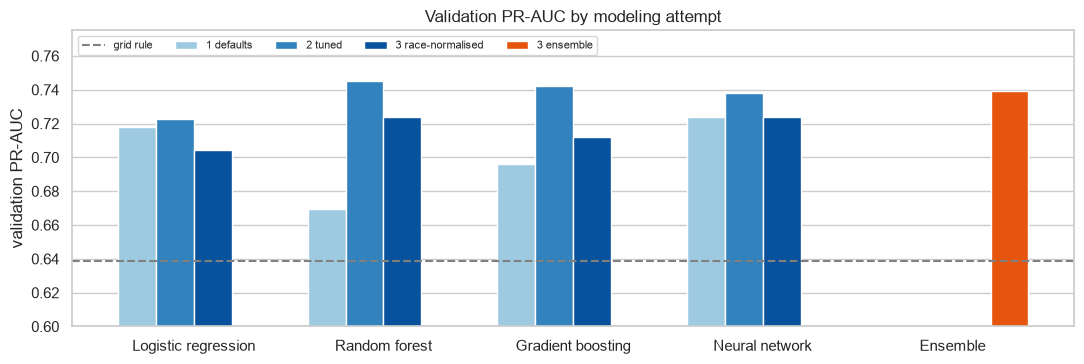

In [85]:
def race_normalise(p, race):
    """Rescale probabilities so each race's sum is 3 (the number of podium places), capped at 1."""
    p = np.asarray(p, float)
    return np.minimum(p * 3 / pd.Series(p).groupby(np.asarray(race)).transform('sum').values, 1.0)

def adopt(gain, lo):
    return gain >= 0.005 and lo > 0

race_sums = pd.DataFrame({NAMES[f]: pd.Series(P_VAL[('2 tuned', f)]).groupby(RACES['validation']).sum().describe()
                          [['mean', 'min', '50%', 'max']] for f in NAMES}).T
print('sum of predicted podium probabilities per validation race (3 = exactly the number of podium places)')
display(race_sums.round(2))
a3_rows = []
for fam in NAMES:
    base = P_VAL[('2 tuned', fam)]
    P_VAL[('3 race-normalised', fam)] = pn = race_normalise(base, RACES['validation'])
    gain = average_precision_score(y_val, pn) - average_precision_score(y_val, base)
    lo, hi = race_bootstrap_ci(y_val, base, pn, RACES['validation'])
    a3_rows.append({'variant': f'{NAMES[fam]} + race normalisation', 'compared with': f'{NAMES[fam]} (tuned)',
                    'val PR-AUC': average_precision_score(y_val, pn), 'gain': gain, '95 % CI': f'[{lo:+.4f}, {hi:+.4f}]',
                    'adopted': adopt(gain, lo)})
best_single = max(NAMES, key=lambda f: average_precision_score(y_val, P_VAL[('2 tuned', f)]))
P_VAL[('3 ensemble', 'ENS')] = pe = np.mean([P_VAL[('2 tuned', f)] for f in NAMES], axis=0)
gain = average_precision_score(y_val, pe) - average_precision_score(y_val, P_VAL[('2 tuned', best_single)])
lo, hi = race_bootstrap_ci(y_val, P_VAL[('2 tuned', best_single)], pe, RACES['validation'])
a3_rows.append({'variant': 'Ensemble (mean of 4 tuned models)', 'compared with': f'{NAMES[best_single]} (best tuned)',
                'val PR-AUC': average_precision_score(y_val, pe), 'gain': gain, '95 % CI': f'[{lo:+.4f}, {hi:+.4f}]',
                'adopted': adopt(gain, lo)})
a3_table = pd.DataFrame(a3_rows).set_index('variant')
display(a3_table.round(4))
NORMALISE = {fam: bool(a3_table.loc[f'{NAMES[fam]} + race normalisation', 'adopted']) for fam in NAMES}
USE_ENSEMBLE = bool(a3_table.iloc[-1]['adopted'])
print('race normalisation adopted for:', [NAMES[f] for f, v in NORMALISE.items() if v] or 'none',
      '| ensemble adopted:', USE_ENSEMBLE)

attempts = pd.Series({k: average_precision_score(y_val, p) for k, p in P_VAL.items()})
fig, ax = plt.subplots(figsize=(11, 3.8))
order = list(NAMES) + ['ENS']
for i, (att, color) in enumerate(zip(['1 defaults', '2 tuned', '3 race-normalised', '3 ensemble'],
                                      ['#9ecae1', '#3182bd', '#08519c', '#e6550d'])):
    vals = [attempts.get((att, f), np.nan) for f in order]
    ax.bar(np.arange(len(order)) + (i - 1.5) * 0.2, vals, width=0.2, label=att, color=color)
ax.axhline(average_precision_score(y_val, REF_PRED[('grid rule (P1–P3)', 'validation')]), color='grey', ls='--',
           label='grid rule')
ax.set_xticks(range(len(order)), [NAMES.get(f, 'Ensemble') for f in order])
ax.set(ylabel='validation PR-AUC', ylim=(0.6, attempts.max() + 0.03), title='Validation PR-AUC by modeling attempt')
ax.legend(fontsize=8, ncol=5, loc='upper left')
ax.grid(axis='x', visible=False)
plt.tight_layout()
save_fig(fig, 's6_attempts')
plt.show()

**Result: neither idea is adopted, and the final models are the tuned models from Attempt 2.**
* **Race normalisation lowers PR-AUC for all four models** (−0.014 to −0.030; CIs include 0 or only just reach it).
  * LR, RF and gradient boosting already sum to **2.8–2.9 podium places per race**. They sit slightly under 3 because
    the validation podium rate (15.0 %) is above training (13.4 %).
  * The sum varies mainly with **how uncertain a race is**, not with how strong the field is. Field strength is already
    in the features (ranks among starters, strong cars ahead, field size).
  * Forcing every race to sum to 3 inflates the probabilities in open, uncertain races. Their drivers then look as safe
    as drivers in clear-cut races, which makes the pooled ranking worse.
  * Not normalising also keeps inference **one row at a time** (Step 8).
* **The ensemble does not beat the best single model** (0.739 vs RF 0.745, CI [−0.022, +0.009]). The four families
  rely on the same strong signals (grid, form, standings) and make highly similar errors, so averaging cancels little.
* The NN's per-race sum of **5.3** shows the effect of class weighting on probability scale (see calibration, §6.7).

## 6.6 Final models and decision threshold
The final version of each family is its tuned model, plus any variant adopted in §6.5. The threshold for a podium
*call* is the probability that **maximises F1 on validation**, chosen separately per model, because class weighting
and normalisation change the probability scale. It is then frozen and applied unchanged to train and test.

selected model (highest validation PR-AUC): Random forest


,threshold (from validation),validation F1 at threshold,podium calls per race (validation)
Logistic regression,0.324,0.700,3.077
Random forest,0.337,0.716,3.231
Gradient boosting,0.363,0.709,3.000
Neural network,0.794,0.708,2.795


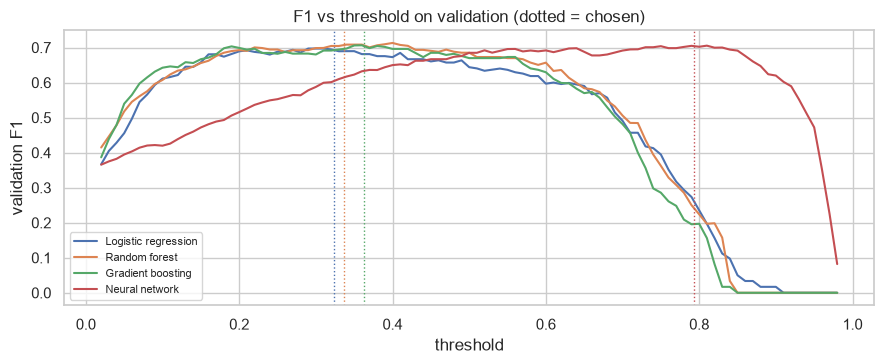

In [86]:
FINAL_MODELS = tuned

def predict_final(fam, X, race):
    """Final probability of a podium for model family `fam` (race ids are needed only if race normalisation is on)."""
    if fam == 'ENS':
        return np.mean([predict_final(f, X, race) for f in NAMES], axis=0)
    p = proba(FINAL_MODELS[fam], X)
    return race_normalise(p, race) if NORMALISE[fam] else p

FINAL = list(NAMES) + (['ENS'] if USE_ENSEMBLE else [])
LABEL = {**NAMES, 'ENS': 'Ensemble'}
PRED = {(fam, s): predict_final(fam, XS[s], RACES[s]) for fam in FINAL for s in XS}

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)]), float(f1.max())

THRESHOLDS = {fam: best_f1_threshold(YS['validation'], PRED[(fam, 'validation')])[0] for fam in FINAL}
BEST_MODEL = max(FINAL, key=lambda f: average_precision_score(YS['validation'], PRED[(f, 'validation')]))
print(f'selected model (highest validation PR-AUC): {LABEL[BEST_MODEL]}')
display(pd.DataFrame({'threshold (from validation)': THRESHOLDS,
                      'validation F1 at threshold': {f: f1_score(YS['validation'], PRED[(f, 'validation')] >= t)
                                                     for f, t in THRESHOLDS.items()},
                      'podium calls per race (validation)': {f: (PRED[(f, 'validation')] >= t).sum() / len(np.unique(RACES['validation']))
                                                             for f, t in THRESHOLDS.items()}}).rename(index=LABEL).round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
grid_t = np.linspace(0.02, 0.98, 97)
for fam in FINAL:
    ax.plot(grid_t, [f1_score(YS['validation'], PRED[(fam, 'validation')] >= t) for t in grid_t], label=LABEL[fam])
    ax.axvline(THRESHOLDS[fam], color=ax.lines[-1].get_color(), ls=':', lw=1)
ax.set(xlabel='threshold', ylabel='validation F1', title='F1 vs threshold on validation (dotted = chosen)')
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, 's6_threshold')
plt.show()

**Result.**
* **Thresholds:** LR 0.32, RF 0.34, gradient boosting 0.36, NN 0.79 (high because class weighting inflates its
  probabilities).
* **The exact threshold is not critical.** For LR, RF and gradient boosting the F1 curve is flat between about 0.2 and
  0.55 (F1 ≈ 0.68–0.71). The NN's plateau is 0.5–0.85.
* **The F1-optimal threshold makes 2.8–3.2 podium calls per race.** It recovers the 3 podium places on its own,
  which is a sanity check that the probabilities are meaningful.
* **Selected model:** random forest, with the highest validation PR-AUC (0.745). Gradient boosting (0.742) and the NN
  (0.738) are within noise of it, so this choice matters little. Step 7 explains the RF, and gradient boosting is
  checked alongside.

## 6.7 Results — train, validation and test
This is the only place where the test seasons are scored. Every setting above was frozen before this cell. The race
bootstrap CIs compare each model with the logistic-regression baseline and with the grid rule.

In [87]:
res_rows = []
for fam in FINAL:
    for s in XS:
        res_rows.append({'model': LABEL[fam], 'split': s, **scores(YS[s], PRED[(fam, s)], RACES[s], THRESHOLDS[fam])})
for r in REF:
    for s in XS:
        res_rows.append({'model': f'ref: {r}', 'split': s, **ref_table.loc[(r, s)].to_dict()})
RESULTS = pd.DataFrame(res_rows).set_index(['model', 'split'])
display(RESULTS.round(3))

primary = RESULTS['PR-AUC'].unstack('split')[list(XS)]
primary['train (2015–19) − validation'] = primary['train (2015–19)'] - primary['validation']
primary['validation − test'] = primary['validation'] - primary['test']
display(primary.round(3))

ci_rows = []
for fam in FINAL:
    row = {'model': LABEL[fam]}
    for s in ['validation', 'test']:
        for ref_name, ref_p in [('LR', PRED[('LR', s)]), ('grid rule', REF_PRED[('grid rule (P1–P3)', s)])]:
            if fam == 'LR' and ref_name == 'LR':
                continue
            lo, hi = race_bootstrap_ci(YS[s], ref_p, PRED[(fam, s)], RACES[s])
            gain = average_precision_score(YS[s], PRED[(fam, s)]) - average_precision_score(YS[s], ref_p)
            row[f'{s}: vs {ref_name}'] = f'{gain:+.3f} [{lo:+.3f}, {hi:+.3f}]'
        d, lo, hi = top3_diff_ci(YS[s], REF_PRED[('grid rule (P1–P3)', s)], PRED[(fam, s)], RACES[s])
        row[f'{s}: top-3 hit rate vs grid rule'] = f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]'
    ci_rows.append(row)
print('PR-AUC difference (and top-3 hit-rate difference) with 95 % race-bootstrap CI')
display(pd.DataFrame(ci_rows).set_index('model').fillna('—'))

season_rows = []
for s in ['validation', 'test']:
    yrs = (val_df if s == 'validation' else test_df)['year'].values
    for yr in np.unique(yrs):
        k = yrs == yr
        row = {'season': yr, 'races': len(np.unique(RACES[s][k]))}
        for fam in FINAL:
            row[LABEL[fam]] = average_precision_score(YS[s][k], PRED[(fam, s)][k])
        row['grid rule'] = average_precision_score(YS[s][k], REF_PRED[('grid rule (P1–P3)', s)][k])
        season_rows.append(row)
print('PR-AUC per season')
display(pd.DataFrame(season_rows).set_index('season').round(3))

ROC-AUC  PR-AUC     F1  precision  recall  accuracy  top-3 hit rate
model                     split                                                                               
Logistic regression       train              0.899   0.566  0.556      0.564   0.548     0.882           0.550
                          train (2015–19)    0.953   0.746  0.732      0.666   0.814     0.912           0.712
                          validation         0.927   0.723  0.700      0.692   0.709     0.909           0.692
                          test               0.935   0.707  0.667      0.606   0.740     0.889           0.637
Random forest             train              0.905   0.600  0.589      0.556   0.626     0.882           0.567
                          train (2015–19)    0.968   0.835  0.768      0.686   0.873     0.923           0.742
                          validation         0.931   0.745  0.716      0.690   0.744     0.912           0.701
                          test               0.938   0.714  0.686      0.622   0.765     0.895           0.642
Gradient boosting         train              0.904   0.593  0.579      0.566   0.592     0.884           0.561
                          train (2015–19)    0.968   0.824  0.761      0.708   0.824     0.924           0.745
                          validation         0.933   0.742  0.709      0.709   0.709     0.913           0.684
                          test               0.938   0.718  0.677      0.643   0.716     0.898           0.642
Neural network            train              0.885   0.456  0.552      0.470   0.667     0.854           0.531
                          train (2015–19)    0.963   0.787  0.769      0.727   0.817     0.928           0.739
                          validation         0.927   0.738  0.708      0.734   0.684     0.915           0.701
                          test               0.934   0.694  0.624      0.630   0.618     0.888           0.632
ref: no skill (base rate) train              0.500   0.134  0.237      0.134   1.000     0.134           0.137
                          train (2015–19)    0.500   0.147  0.257      0.147   1.000     0.147           0.147
                          validation         0.500   0.150  0.261      0.150   1.000     0.150           0.150
                          test               0.500   0.150  0.261      0.150   1.000     0.150           0.150
ref: always "no podium"   train              0.500   0.134  0.000      0.000   0.000     0.866           0.137
                          train (2015–19)    0.500   0.147  0.000      0.000   0.000     0.853           0.147
                          validation         0.500   0.150  0.000      0.000   0.000     0.850           0.150
                          test               0.500   0.150  0.000      0.000   0.000     0.850           0.150
ref: grid rule (P1–P3)    train              0.883   0.498  0.543      0.545   0.541     0.878           0.545
                          train (2015–19)    0.934   0.711  0.723      0.725   0.722     0.919           0.725
                          validation         0.909   0.639  0.692      0.692   0.692     0.908           0.692
                          test               0.914   0.647  0.649      0.650   0.647     0.895           0.652

split,train,train (2015–19),validation,test,train (2015–19) − validation,validation − test
model,,,,,,
Gradient boosting,0.593,0.824,0.742,0.718,0.082,0.024
Logistic regression,0.566,0.746,0.723,0.707,0.023,0.016
Neural network,0.456,0.787,0.738,0.694,0.048,0.045
Random forest,0.600,0.835,0.745,0.714,0.090,0.031
"ref: always ""no podium""",0.134,0.147,0.150,0.150,-0.003,-0.000
ref: grid rule (P1–P3),0.498,0.711,0.639,0.647,0.072,-0.009
ref: no skill (base rate),0.134,0.147,0.150,0.150,-0.003,-0.000


PR-AUC difference (and top-3 hit-rate difference) with 95 % race-bootstrap CI


,validation: vs grid rule,validation: top-3 hit rate vs grid rule,test: vs grid rule,test: top-3 hit rate vs grid rule,validation: vs LR,test: vs LR
model,,,,,,
Logistic regression,"+0.084 [+0.040, +0.131]","+0.000 [-0.051, +0.051]","+0.059 [+0.007, +0.107]","-0.015 [-0.069, +0.034]",—,—
Random forest,"+0.106 [+0.063, +0.146]","+0.009 [-0.043, +0.060]","+0.067 [+0.023, +0.107]","-0.010 [-0.039, +0.020]","+0.022 [-0.002, +0.046]","+0.008 [-0.016, +0.034]"
Gradient boosting,"+0.104 [+0.054, +0.147]","-0.009 [-0.051, +0.034]","+0.070 [+0.037, +0.102]","-0.010 [-0.044, +0.020]","+0.019 [-0.007, +0.046]","+0.011 [-0.013, +0.039]"
Neural network,"+0.100 [+0.056, +0.140]","+0.009 [-0.034, +0.051]","+0.046 [-0.001, +0.090]","-0.020 [-0.064, +0.020]","+0.015 [-0.013, +0.038]","-0.013 [-0.033, +0.012]"


PR-AUC per season


,races,Logistic regression,Random forest,Gradient boosting,Neural network,grid rule
season,,,,,,
2020,17,0.709,0.721,0.706,0.721,0.633
2021,22,0.744,0.780,0.790,0.746,0.645
2022,22,0.709,0.687,0.693,0.683,0.616
2023,22,0.733,0.741,0.739,0.724,0.678
2024,24,0.645,0.699,0.689,0.641,0.657


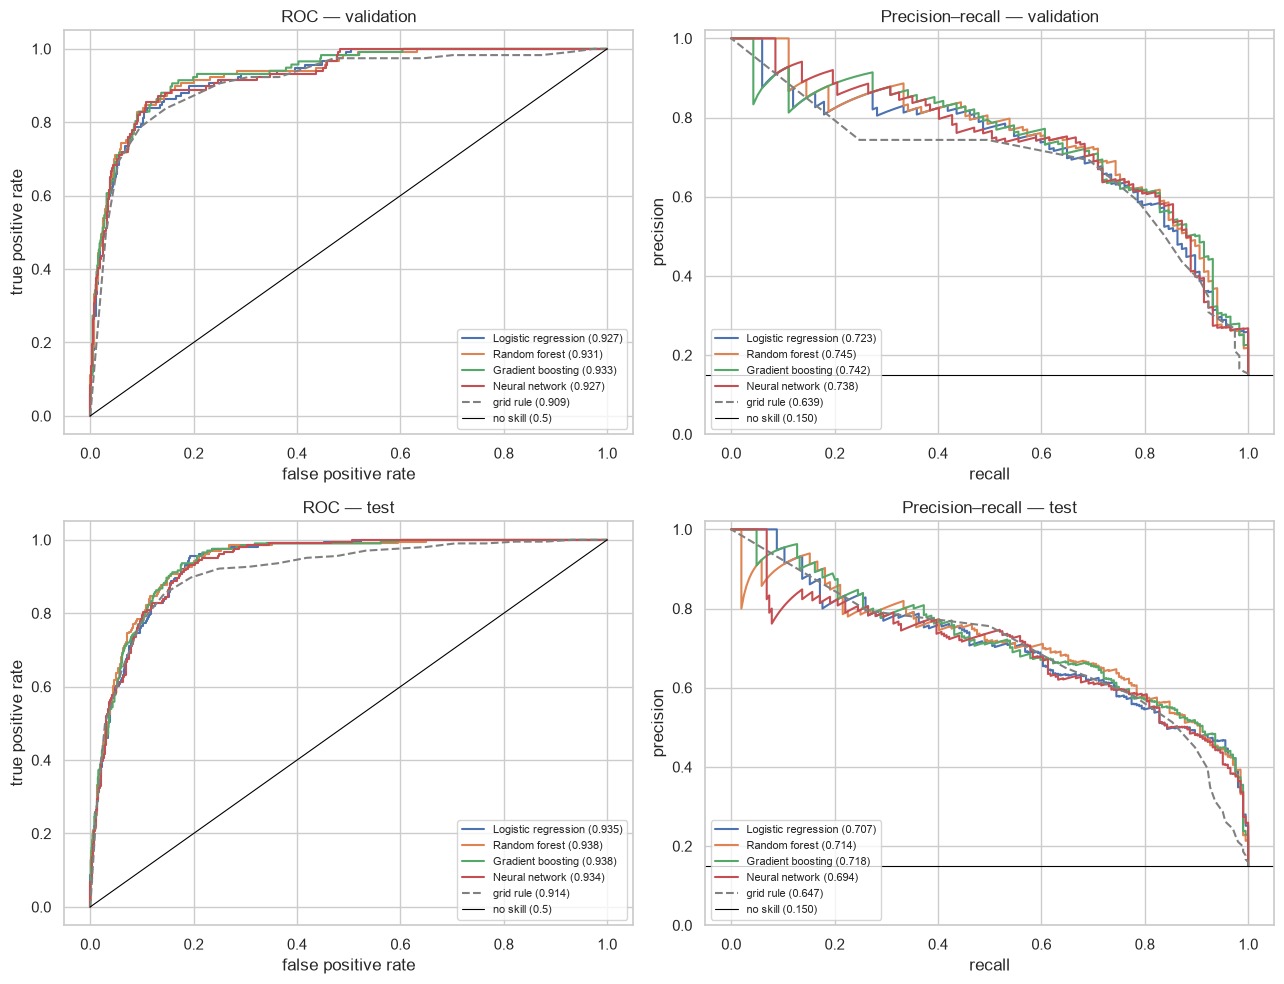

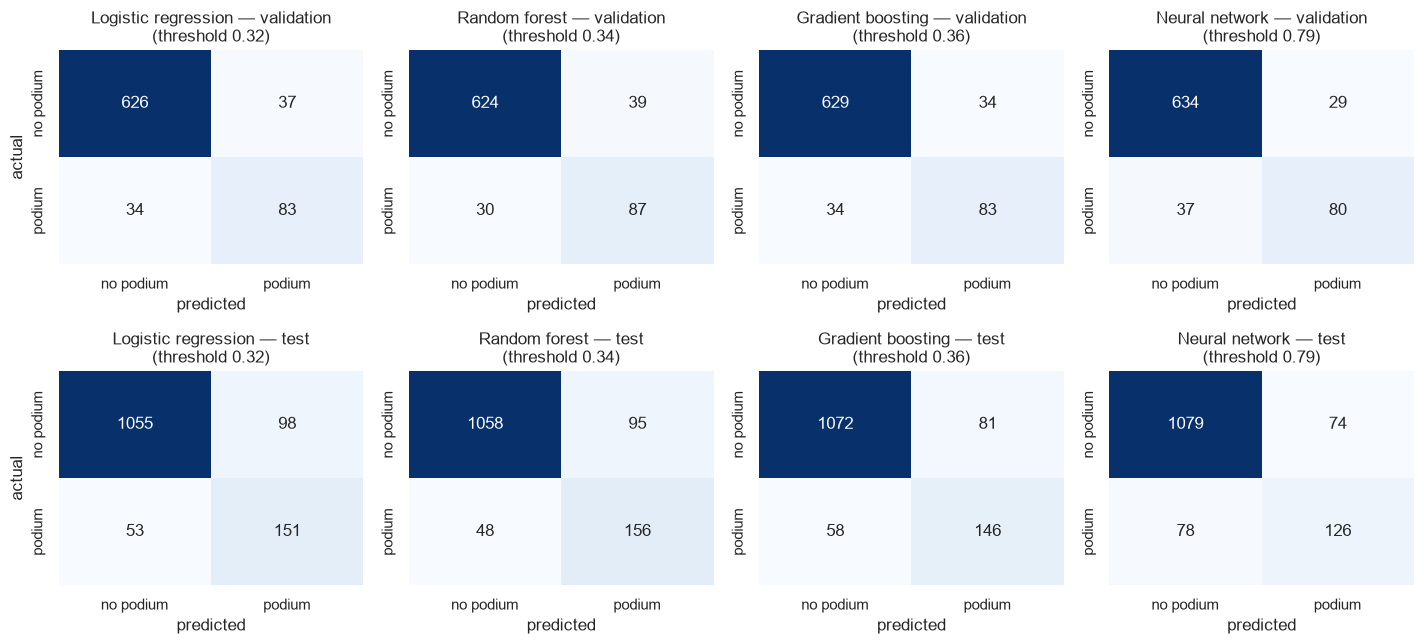

In [88]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, s in enumerate(['validation', 'test']):
    y = YS[s]
    for fam in FINAL:
        p = PRED[(fam, s)]
        fpr, tpr, _ = roc_curve(y, p)
        axes[row, 0].plot(fpr, tpr, label=f'{LABEL[fam]} ({roc_auc_score(y, p):.3f})')
        prec, rec, _ = precision_recall_curve(y, p)
        axes[row, 1].plot(rec, prec, label=f'{LABEL[fam]} ({average_precision_score(y, p):.3f})')
    pg = REF_PRED[('grid rule (P1–P3)', s)]
    fpr, tpr, _ = roc_curve(y, pg)
    axes[row, 0].plot(fpr, tpr, color='grey', ls='--', label=f'grid rule ({roc_auc_score(y, pg):.3f})')
    prec, rec, _ = precision_recall_curve(y, pg)
    axes[row, 1].plot(rec, prec, color='grey', ls='--', label=f'grid rule ({average_precision_score(y, pg):.3f})')
    axes[row, 0].plot([0, 1], [0, 1], color='black', lw=0.8, label='no skill (0.5)')
    axes[row, 1].axhline(y.mean(), color='black', lw=0.8, label=f'no skill ({y.mean():.3f})')
    axes[row, 0].set(xlabel='false positive rate', ylabel='true positive rate', title=f'ROC — {s}')
    axes[row, 1].set(xlabel='recall', ylabel='precision', title=f'Precision–recall — {s}', ylim=(0, 1.02))
    for ax in axes[row]:
        ax.legend(fontsize=8, loc='lower right' if ax is axes[row, 0] else 'lower left')
plt.tight_layout()
save_fig(fig, 's6_roc_pr_curves')
plt.show()

fig, axes = plt.subplots(2, len(FINAL), figsize=(3.6 * len(FINAL), 6.6))
for row, s in enumerate(['validation', 'test']):
    for col, fam in enumerate(FINAL):
        cm = confusion_matrix(YS[s], PRED[(fam, s)] >= THRESHOLDS[fam])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[row, col],
                    xticklabels=['no podium', 'podium'], yticklabels=['no podium', 'podium'])
        axes[row, col].set(title=f'{LABEL[fam]} — {s}\n(threshold {THRESHOLDS[fam]:.2f})', xlabel='predicted',
                           ylabel='actual' if col == 0 else '')
plt.tight_layout()
save_fig(fig, 's6_confusion_matrices')
plt.show()

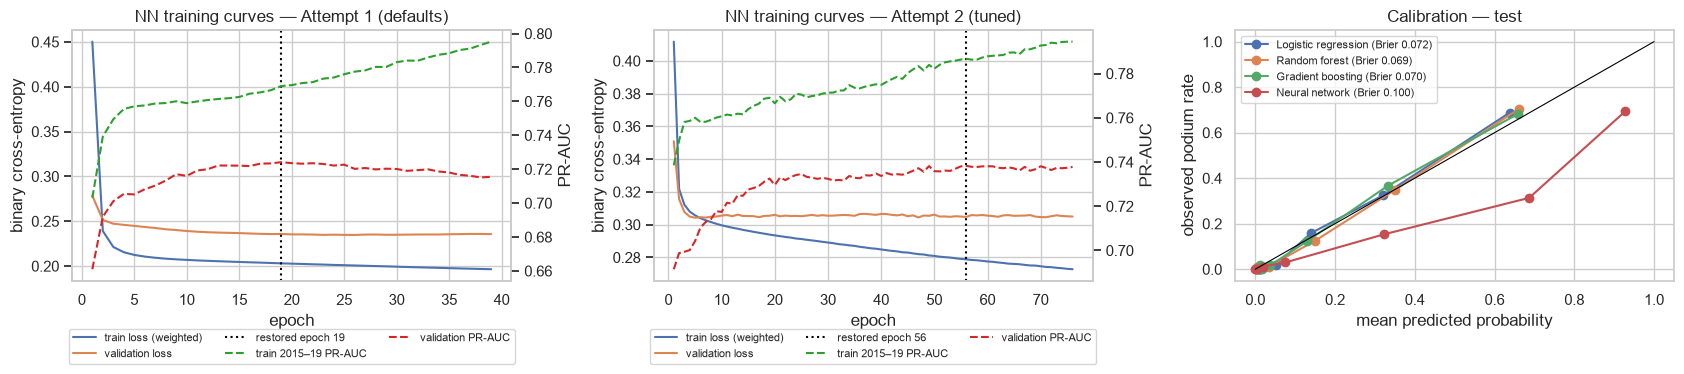

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (m, title) in zip(axes[:2], [(attempt1['NN'], 'Attempt 1 (defaults)'), (tuned['NN'], 'Attempt 2 (tuned)')]):
    h = pd.DataFrame(m.history, index=np.arange(1, len(m.history['loss']) + 1))
    ax.plot(h.index, h['loss'], label='train loss (weighted)')
    ax.plot(h.index, h['val_loss'], label='validation loss')
    ax2 = ax.twinx()
    ax2.plot(h.index, h['train_ap'], color='tab:green', ls='--', label='train 2015–19 PR-AUC')
    ax2.plot(h.index, h['val_ap'], color='tab:red', ls='--', label='validation PR-AUC')
    ax.axvline(m.best_epoch, color='black', ls=':', label=f'restored epoch {m.best_epoch}')
    ax.set(xlabel='epoch', ylabel='binary cross-entropy', title=f'NN training curves — {title}')
    ax2.set_ylabel('PR-AUC'); ax2.grid(False)
    lines = ax.get_legend_handles_labels(); lines2 = ax2.get_legend_handles_labels()
    ax.legend(lines[0] + lines2[0], lines[1] + lines2[1], fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.17),
              ncol=3)
for fam in FINAL:
    frac, mean_p = calibration_curve(YS['test'], PRED[(fam, 'test')], n_bins=8, strategy='quantile')
    axes[2].plot(mean_p, frac, marker='o', label=f'{LABEL[fam]} (Brier {brier_score_loss(YS["test"], PRED[(fam, "test")]):.3f})')
axes[2].plot([0, 1], [0, 1], color='black', lw=0.8)
axes[2].set(xlabel='mean predicted probability', ylabel='observed podium rate', title='Calibration — test')
axes[2].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, 's6_nn_curves_calibration')
plt.show()

**Result: test seasons 2022–24, scored once.**

| | LR | RF | Gradient boosting | NN | Grid rule |
|---|---|---|---|---|---|
| Test PR-AUC | 0.707 | 0.714 | **0.718** | 0.694 | 0.647 |
| Test ROC-AUC | 0.935 | 0.938 | 0.938 | 0.934 | 0.914 |
| Test F1 (validation threshold) | 0.667 | **0.686** | 0.677 | 0.624 | 0.649 |
| Test top-3 hit rate | 0.637 | 0.642 | 0.642 | 0.632 | **0.652** |
| Test accuracy | 0.889 | 0.895 | **0.898** | 0.888 | 0.895 |

* **Accuracy cannot tell the models apart.** All four score 88.8–89.8 %, the grid rule 89.5 % and "always no podium"
  85.0 %. With 85 % negatives, accuracy is dominated by the easy "no podium" calls. This is why PR-AUC and F1 are used
  to judge the models (§6.1).
* **Every model ranks podium finishers better than the grid rule.** Gains in PR-AUC: RF +0.067 [+0.023, +0.107],
  gradient boosting +0.070 [+0.037, +0.102], LR +0.059 [+0.007, +0.107]. The NN's gain (+0.046) reaches just below 0
  [−0.001, +0.090].
* **The models are statistically tied.** No model beats LR on test (RF +0.008 [−0.016, +0.034], gradient boosting
  +0.011 [−0.013, +0.039], NN −0.013 [−0.033, +0.012]). The ranking changed between validation (RF first) and test
  (gradient boosting first), which shows how small these differences are.
* **Generalisation:**
  * **Validation → test:** PR-AUC drops by 0.016 (LR) to 0.045 (NN). 2022+ is a new rules era.
  * **Train (2015–19) → validation:** LR 0.023 and NN 0.048 are below the grid rule's era gap of 0.072, so these
    models do not overfit. RF (0.090) and gradient boosting (0.082) overfit only slightly beyond it.
  * **Full train (1950–2019) scores** (0.46–0.60) are lower than validation because the old seasons are harder to
    predict. The NN scores lowest there: with recency weights and only 16 units, it effectively learned the recent
    seasons.
* **Where the gain comes from.** On the top-3 hit rate the models do **not** beat the grid rule. On test they are 0.010–0.020
lower, and every CI includes 0 (e.g. RF −0.010 [−0.039, +0.020]). On validation the difference is −0.009 to +0.009. When
  exactly 3 drivers must be picked per race, the models mostly pick the first three on the grid. Their PR-AUC advantage
  is **confidence across races**. The grid rule gives every P3 starter the same score. The models know that P3 in a
  dominant car (2023 Red Bull) is safer than P2 in a midfield car, and they rate drivers starting further back by
  form and car strength. F1 at the threshold (0.67–0.69 vs 0.65) reflects this.
* **Precision drops and recall rises on test** (LR/RF precision 0.61–0.62 vs 0.69 on validation). The frozen threshold
  makes more podium calls in the 2022–24 era. That is threshold drift, not a change in ranking quality.
* **Season by season,** **2024 is the hardest**. LR (0.645) and the NN (0.641) fall below the grid rule (0.657);
  RF (0.699) and gradient boosting (0.689) stay above it. 2024 had four winning teams and a mid-season swing (McLaren's
  rise, Red Bull's decline). Form, Elo and standings come from past races, so they lag such swings.
* **Calibration:**
  * LR, RF and gradient boosting are well calibrated (test Brier 0.069–0.072; the curves follow the diagonal).
  * The class-weighted NN over-predicts (Brier 0.100). A predicted 0.9 corresponds to about 0.7 observed.
  * Its ranking is unaffected, but its outputs are scores, not probabilities, unless recalibrated.
* **Training curves (NN):** training PR-AUC keeps rising while validation PR-AUC levels off after about 20 (defaults)
  or 25 (tuned) epochs. Validation loss is flat from about epoch 5. Early stopping restores the best epoch, 19 and 56
  respectively, before the network starts memorising the training seasons.

## 6.8 Limitations of each model
**Logistic regression (baseline)**
* **Linear and additive** in the log-odds. Interactions (e.g. grid matters more where overtaking is hard) exist only if
  a feature encodes them, such as `circuit_grid_prior`.
* **Collinear features share weight.** Standings, form and Elo overlap heavily, so it needed strong regularisation
  (C = 0.003). Individual coefficients are therefore unstable and should not be read as effects (Step 7).
* **Extrapolates linearly.** `season` and `team_starts` lie 1.8–2 training SDs beyond the training range in the test
  seasons. A linear term keeps growing there, which may be unrealistic.

**Random forest (selected model)**
* **Memorises without regularisation:** train PR-AUC 1.000 with default settings. It only works with shallow trees and
  large leaves (depth 6, ≥ 50 rows).
* **Cannot extrapolate:** predictions are flat beyond the largest training value of `season`, `team_starts` and
  `drv_starts`. All three are out of range in the test seasons.
* **Biased built-in importances:** impurity importance favours continuous, high-cardinality features. Step 7 uses
  permutation importance and SHAP instead.
* **Heavier:** 300 trees, slower inference and larger to store than LR.

**Gradient boosting**
* **Sensitive to the number of trees:** performance peaks at 50–150 trees, then declines. That number was chosen on
  39 validation races, from 224 configurations, so the selection is optimistic.
* **Same extrapolation limit as the forest** (tree-based).
* **Best on test (0.718) but not significantly better than LR.** Its extra complexity is not clearly justified by the
  data.

**Neural network**
* **Least stable:** 20 configurations span 0.721–0.738, and the result also depends on the seed and the early-stopping
  epoch.
* **Validation used twice** (epoch choice + configuration), so its validation score is the most optimistic. It has
  the largest validation → test drop (0.045) and the lowest test PR-AUC (0.694).
* **Miscalibrated by class weighting** (5.3 predicted podiums per race, Brier 0.100). Platt or isotonic recalibration
  on validation would be needed before its outputs are used as probabilities.
* **Black box with the most preprocessing** (imputation + flags + scaling inside the model). It needs SHAP or LIME to
  explain.

**Common to all four**
* **Trained only on ≤ 2019** and tested on an unseen rules era. Refitting on 1950–2021 with the frozen settings would
  be the deployment step; it is not done here, so the test protocol stays clean.
* **Small validation set (39 races):** CIs are ±0.02–0.05, so most model-to-model differences are not significant.
* **Past-only information:** no weather, tyre strategy or practice pace, and the models lag mid-season swings in form
  (2024).
* **No better than the grid at choosing the 3 podium finishers per race.** The added value is in ranking confidence
  across races (§6.7).

## 6.9 Step 6 summary
| Decision | Choice | Evidence |
|---|---|---|
| Primary metric | PR-AUC | rare positives (15 %); no-skill = 0.15, grid rule = 0.64, while ROC-AUC is 0.91 for a single feature (§6.1) |
| Secondary metric | F1 at the validation-chosen threshold (+ top-3 hit rate as an F1-specific diagnostic) | a podium call is a yes/no decision; 3 podium places per race (§6.1) |
| Accuracy | reported, never used for decisions | "always no podium" is already 85.0 % accurate; models 88.8–89.8 % (§6.7) |
| Early stopping (NN) | kept | without it, train − val gap 0.048 → 0.101 and val PR-AUC 0.738 → 0.722 (§6.4.1) |
| Missing values | keep all rows; LR/NN median + flags, trees native NaN | dropping changes PR-AUC by +0.0007 / −0.0044, CIs include 0 (§6.2.1) |
| Attempt 1 | defaults | RF/GB memorise (train 2015–19 PR-AUC 1.000) (§6.3) |
| Attempt 2 | tuned on validation; class weights only for the NN | RF +0.075, GB +0.046 (CIs > 0); LR / NN flat (§6.4) |
| Attempt 3 | race normalisation and ensemble **rejected** | −0.014 to −0.030 and −0.006, CIs include 0 (§6.5) |
| Threshold | max-F1 on validation: LR 0.32 · RF 0.34 · GB 0.36 · NN 0.79 | F1 plateau 0.2–0.55; about 3 calls per race (§6.6) |
| Selected model | random forest (highest validation PR-AUC, 0.745) | test: GB 0.718 · RF 0.714 · LR 0.707 · NN 0.694 · grid rule 0.647 (§6.7) |

**Handed to Steps 7–8** (in memory after Run All):
* **Fitted models:**
  * `FINAL_MODELS`: the fitted tuned models, `{'LR', 'RF', 'GB', 'NN'}`.
  * `BEST_MODEL = 'RF'`, plus `BEST_HP` and `BEST_BAL` (settings and class weighting per family).
  * `predict_final(fam, X, race)` and `proba(model, X)` for predictions.
  * The NN is a `KerasPodium` with its own fitted preprocessor (`.prep`) and `.net`. LR is a pipeline that imputes
    internally.
* **Decisions and results:** `THRESHOLDS` (frozen), `PRED[(fam, split)]` (probabilities for train / train (2015–19) /
  validation / test) and `RESULTS` (the full metric table).
* **Data and helpers:**
  * `XS`, `YS`, `RACES` (per split) and `RECENT` (mask of the 2015–19 training rows).
  * `scores`, `top3_hit_rate`, `make_model`, `fit_model`, `NAMES` / `LABEL`.

# 7. Feature-Group Ablation and Explainability
Which information does the podium model actually use, and how much does each kind of information add? Four views,
from coarse to fine:

| Method | Question it answers | Section |
|---|---|---|
| Feature-group ablation | How much worse is the model if it never sees a group (refit without it)? | §7.1 |
| Permutation importance | How much worse are the *fitted* model's predictions if one feature (or group) is scrambled? | §7.2 |
| SHAP (global) | How does each feature push predictions up or down, across all test rows? | §7.3 |
| SHAP waterfall + LIME (local) | Why did the model rate *this one driver* the way it did? | §7.4 |

The model explained is the **random forest** (`BEST_MODEL`, §6.6), with gradient boosting and logistic regression as
cross-checks in §7.1–7.2. Every refit uses the **frozen Step 6 settings**; nothing is retuned.

**This section is explanation only.** The test seasons were already scored in §6.7. Changing the feature set now
because of what the test set shows would turn the test set into a second validation set. Findings that point to a
better feature set are recorded as limitations and future work.

## 7.1 Feature-group ablation
Each variant is refitted from scratch with the same settings, weights and rows. Only the feature columns change.
* **Without group g:** what is lost if the model never sees g. A small loss can mean "g is useless" **or** "another
  group carries the same information". So two *blocks* of overlapping groups are also removed together:
  * starting position = grid + qualifying;
  * past performance = standings + driver form + constructor form + ratings.
* **Only group g:** how much signal g carries on its own.
* **+ `home_race`:** the home-race flag, which Step 3 (Q2) found no effect for, added to all 38 features.

Change in PR-AUC against the full 38-feature model on validation and test. For the random forest, 95 % race-bootstrap
CIs are shown. The NN is left out: its seed-to-seed variation (validation PR-AUC 0.721–0.738 across near-identical
configurations, §6.4) is as large as the effects measured here.

In [90]:
import shap
import lime.lime_tabular
from sklearn.inspection import permutation_importance

DFS = {'train': train_df, 'validation': val_df, 'test': test_df}

def fit_on(fam, cols):
    """Refit model family `fam` with its frozen Step 6 settings on the given feature columns."""
    model, w = make_model(fam, BEST_HP[fam]), W_FIT[BEST_BAL[fam]]
    if fam == 'LR':
        model.fit(train_df[cols], y_train, logisticregression__sample_weight=w)
    else:
        model.fit(train_df[cols], y_train, sample_weight=w)
    return model

GROUP_LABEL = {g: g.replace('_', ' ') for g in FINAL_GROUPS}
BLOCKS = {'starting position (grid + qualifying)': ['grid', 'qualifying'],
          'past performance (standings + form + ratings)': ['standings', 'driver_form', 'constructor_form', 'ratings']}
VARIANTS = {'all 38 features': FEATURES}
VARIANTS.update({f'without {GROUP_LABEL[g]}': [f for f in FEATURES if f not in fs] for g, fs in FINAL_GROUPS.items()})
VARIANTS.update({f'without {b}': [f for f in FEATURES if not any(f in FINAL_GROUPS[g] for g in gs)] for b, gs in BLOCKS.items()})
VARIANTS.update({f'only {GROUP_LABEL[g]}': fs for g, fs in FINAL_GROUPS.items()})
VARIANTS['+ home_race'] = FEATURES + ['home_race']
ABL_MODELS = ['RF', 'GB', 'LR']

abl_pred = {}
for name, cols in VARIANTS.items():
    for fam in ABL_MODELS:
        m = fit_on(fam, cols)
        for s in ['validation', 'test']:
            abl_pred[(name, fam, s)] = proba(m, DFS[s][cols])
assert all(np.allclose(abl_pred[('all 38 features', f, s)], PRED[(f, s)]) for f in ABL_MODELS for s in ['validation', 'test'])

rows = []
for name, cols in VARIANTS.items():
    row = {'variant': name, 'features': len(cols)}
    for fam in ABL_MODELS:
        for s in ['validation', 'test']:
            ref = average_precision_score(YS[s], abl_pred[('all 38 features', fam, s)])
            row[f'{fam} {s} PR-AUC'] = average_precision_score(YS[s], abl_pred[(name, fam, s)])
            row[f'{fam} {s} Δ'] = row[f'{fam} {s} PR-AUC'] - ref
            if fam == 'RF' and name != 'all 38 features' and not name.startswith('only'):
                lo, hi = race_bootstrap_ci(YS[s], abl_pred[('all 38 features', fam, s)], abl_pred[(name, fam, s)], RACES[s])
                row[f'RF {s} 95 % CI'] = f'[{lo:+.3f}, {hi:+.3f}]'
    rows.append(row)
ablation = pd.DataFrame(rows).set_index('variant')
show_cols = ['features', 'RF validation Δ', 'RF validation 95 % CI', 'RF test Δ', 'RF test 95 % CI',
             'GB validation Δ', 'GB test Δ', 'LR validation Δ', 'LR test Δ']
print('Change in PR-AUC when a group is removed / added (vs all 38 features)')
display(ablation.loc[[v for v in VARIANTS if not v.startswith('only')], show_cols].round(3).fillna('—'))
print('PR-AUC with one group only (grid rule: validation '
      f'{average_precision_score(YS["validation"], REF_PRED[("grid rule (P1–P3)", "validation")]):.3f}, test '
      f'{average_precision_score(YS["test"], REF_PRED[("grid rule (P1–P3)", "test")]):.3f})')
display(ablation.loc[[v for v in VARIANTS if v.startswith('only')],
                     ['features'] + [f'{f} {s} PR-AUC' for f in ABL_MODELS for s in ['validation', 'test']]]
        .sort_values('RF test PR-AUC', ascending=False).round(3))

Change in PR-AUC when a group is removed / added (vs all 38 features)


,features,RF validation Δ,RF validation 95 % CI,RF test Δ,RF test 95 % CI,GB validation Δ,GB test Δ,LR validation Δ,LR test Δ
variant,,,,,,,,,
all 38 features,38,0.000,—,0.000,—,0.000,0.000,0.000,0.000
without grid,36,-0.004,"[-0.013, +0.004]",0.002,"[-0.007, +0.010]",-0.001,-0.005,-0.004,-0.003
without qualifying,35,-0.006,"[-0.017, +0.005]",0.002,"[-0.006, +0.011]",-0.008,0.002,-0.004,-0.002
without standings,32,-0.006,"[-0.015, +0.004]",-0.004,"[-0.014, +0.005]",-0.020,-0.008,-0.015,0.003
without driver form,34,0.002,"[-0.005, +0.009]",0.002,"[-0.004, +0.009]",0.000,0.001,-0.004,0.000
without constructor form,35,0.002,"[-0.007, +0.011]",-0.004,"[-0.016, +0.004]",0.005,-0.005,0.006,-0.002
without experience,34,0.001,"[-0.006, +0.009]",0.003,"[-0.004, +0.010]",-0.000,-0.000,-0.000,0.001
without circuit history,35,-0.003,"[-0.010, +0.002]",0.011,"[+0.001, +0.022]",0.005,0.001,0.001,0.003
without ratings,36,-0.003,"[-0.011, +0.006]",-0.004,"[-0.016, +0.008]",-0.000,-0.002,0.001,0.005


PR-AUC with one group only (grid rule: validation 0.639, test 0.647)


,features,RF validation PR-AUC,RF test PR-AUC,GB validation PR-AUC,GB test PR-AUC,LR validation PR-AUC,LR test PR-AUC
variant,,,,,,,
only race context,8,0.712,0.715,0.698,0.700,0.706,0.713
only grid,2,0.638,0.646,0.637,0.646,0.639,0.647
only qualifying,3,0.665,0.638,0.665,0.649,0.662,0.652
only standings,6,0.663,0.577,0.660,0.569,0.658,0.578
only driver form,4,0.641,0.563,0.658,0.561,0.642,0.562
only constructor form,3,0.593,0.532,0.587,0.527,0.552,0.507
only ratings,2,0.653,0.513,0.640,0.536,0.658,0.531
only circuit history,3,0.412,0.381,0.419,0.393,0.432,0.342
only experience,4,0.178,0.297,0.177,0.246,0.209,0.199


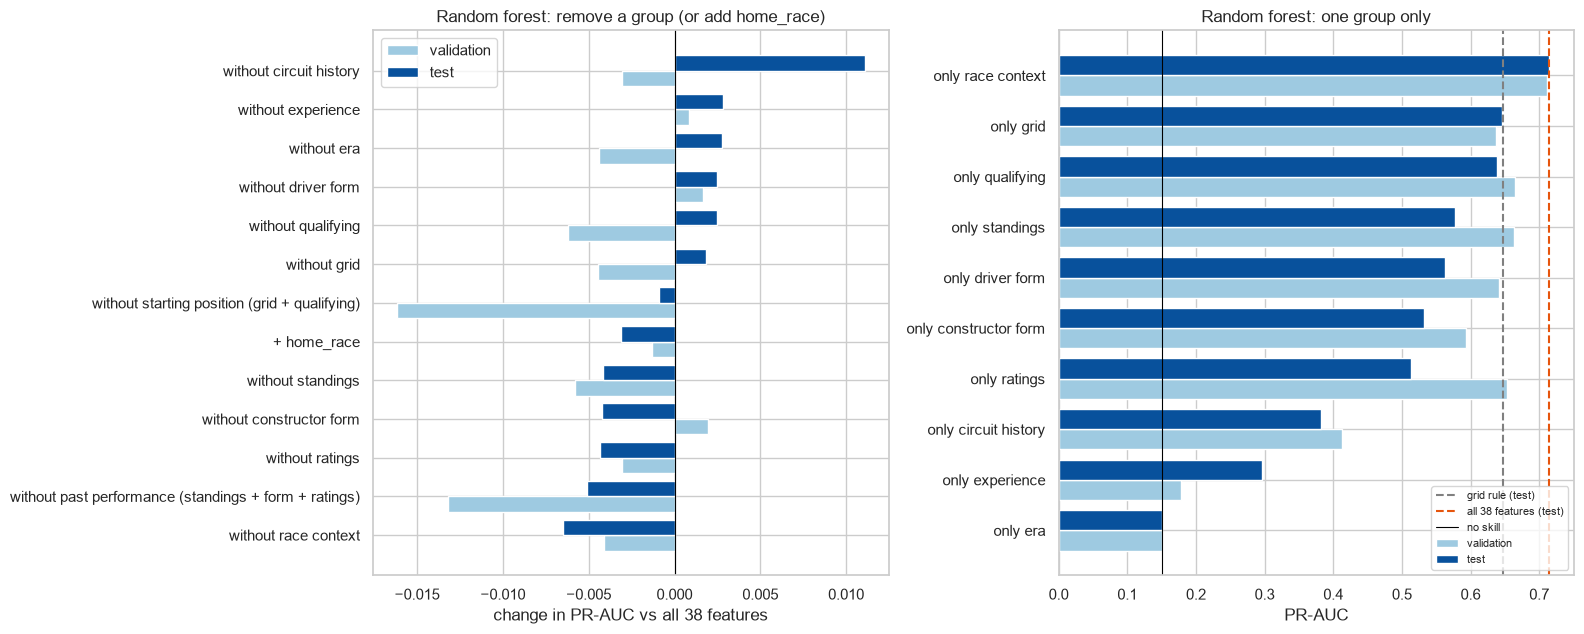

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
loo = ablation.loc[[v for v in VARIANTS if v.startswith(('without', '+'))]].sort_values('RF test Δ')
y_ = np.arange(len(loo))
for k, (s, color) in enumerate([('validation', '#9ecae1'), ('test', '#08519c')]):
    axes[0].barh(y_ + (k - 0.5) * 0.4, loo[f'RF {s} Δ'], height=0.4, color=color, label=s)
axes[0].set_yticks(y_, loo.index)
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set(xlabel='change in PR-AUC vs all 38 features', title='Random forest: remove a group (or add home_race)')
axes[0].legend()
only = ablation.loc[[v for v in VARIANTS if v.startswith('only')]].sort_values('RF test PR-AUC')
y_ = np.arange(len(only))
for k, (s, color) in enumerate([('validation', '#9ecae1'), ('test', '#08519c')]):
    axes[1].barh(y_ + (k - 0.5) * 0.4, only[f'RF {s} PR-AUC'], height=0.4, color=color, label=s)
axes[1].set_yticks(y_, only.index)
axes[1].axvline(average_precision_score(YS['test'], REF_PRED[('grid rule (P1–P3)', 'test')]), color='grey', ls='--',
                label='grid rule (test)')
axes[1].axvline(average_precision_score(YS['test'], PRED[('RF', 'test')]), color='#e6550d', ls='--',
                label='all 38 features (test)')
axes[1].axvline(y_test.mean(), color='black', lw=0.8, label='no skill')
axes[1].set(xlabel='PR-AUC', title='Random forest: one group only')
axes[1].legend(fontsize=8, loc='lower right')
plt.tight_layout()
save_fig(fig, 's7_ablation')
plt.show()

**Result.**
* **No single group is essential.** Removing any one of the 10 groups changes RF PR-AUC by less than ±0.012 on both
  validation and test, and almost every CI includes 0. The groups **overlap**:
  * starting position is also encoded in race context (`circuit_grid_prior` is the historical podium rate of that grid
    slot at that circuit; `strong_cars_ahead` counts strong cars ahead on the grid);
  * standings, form and Elo all describe recent performance.
* **The overlapping blocks matter more.** Removing grid + qualifying together costs −0.016 on validation (CI
  [−0.035, +0.001]); removing all past-performance groups costs −0.013. The losses are still small, because race
  context (computed from the grid slot and from form ranks) carries part of the same information.
* **Race context carries almost everything on its own.** RF with only the 8 race-context features reaches test
  PR-AUC **0.715**, the same as all 38 features (0.714). Grid alone gives 0.646 (= the grid rule), qualifying 0.638,
  standings 0.577, driver form 0.563. Experience (0.30) and era (0.15 = no skill) carry almost nothing alone.
* **Logistic regression depends on race context much more:** −0.061 on test without it, vs −0.007 for RF. The linear
  model cannot bend the grid effect (P1–P3 vs the rest) by itself. `circuit_grid_prior` is the engineered feature that
  gives it that shape.
* **Circuit history is the one group that hurts on test:** removing it *improves* RF test PR-AUC by **+0.011**
  [+0.001, +0.022]. On validation it costs −0.003 (CI includes 0), so this would not have been found without the test
  seasons. Following the rule in §7, the model is **not** changed. It is recorded as a limitation: past results at a
  circuit (31 % missing on first visits) do not carry over well into the new 2022 rules era.
* **`home_race` adds nothing** (−0.001 validation, −0.003 test), which confirms Step 3 (Q2): no home advantage once
  the starting position is known.
* **Era and experience**, the features with test values beyond the training range (§5.7), change PR-AUC by under
  ±0.005. Their extrapolation risk does not materialise (see also the dependence plots in §7.3).

## 7.2 Permutation importance (test seasons)
The fitted model is kept fixed. One feature's values are shuffled across the test rows, which breaks its link with the
outcome, and the drop in PR-AUC is measured (30 repeats). Unlike ablation, the model cannot adapt by leaning on a
substitute, so this measures what the *fitted* model relies on. The test seasons are used because importance on
training data rewards whatever the model memorised.

Correlated features split their importance: shuffling only `grid_f` leaves `quali_pos_d` and `circuit_grid_prior`
intact, so each looks less important than "starting position" really is. **Grouped permutation** shuffles all
features of a group together (the same row order for the whole group). Logistic regression is shown alongside to
check whether two very different models rely on the same information.

Top 15 features (drop in test PR-AUC when shuffled)


,RF mean,LR mean,RF sd,LR sd,group
circuit_grid_prior,0.0270,0.0584,0.0107,0.0109,race_context
grid_f,0.0207,0.0099,0.0114,0.0039,grid
quali_pos_d,0.0126,0.0102,0.0121,0.0037,qualifying
con_form_podium,0.0029,0.0018,0.0050,0.0039,constructor_form
con_points_share,0.0028,0.0001,0.0080,0.0038,standings
circuit_overtaking,0.0024,0.0002,0.0016,0.0005,race_context
con_form_podium_rank,0.0022,0.0007,0.0043,0.0025,race_context
strong_cars_ahead,0.0018,0.0213,0.0057,0.0063,race_context
con_champ_pos,0.0013,-0.0001,0.0043,0.0018,standings
drv_form_podium_rank,0.0012,-0.0004,0.0038,0.0025,race_context


Grouped permutation importance (drop in test PR-AUC)


,RF mean,RF sd,LR mean,LR sd,sum of single-feature importances (RF)
race_context,0.0669,0.0200,0.1731,0.0217,0.0307
standings,0.0274,0.0114,0.0241,0.0096,0.0056
grid,0.0186,0.0124,0.0108,0.0046,0.0207
qualifying,0.0090,0.0115,0.0085,0.0033,0.0127
constructor_form,0.0020,0.0077,0.0032,0.0076,0.0035
driver_form,0.0012,0.0044,0.0036,0.0049,0.0012
era,0.0000,0.0001,-0.0001,0.0001,0.0001
ratings,-0.0010,0.0060,0.0116,0.0084,-0.0014
experience,-0.0012,0.0041,0.0007,0.0019,-0.0005
circuit_history,-0.0071,0.0025,-0.0026,0.0012,-0.0081


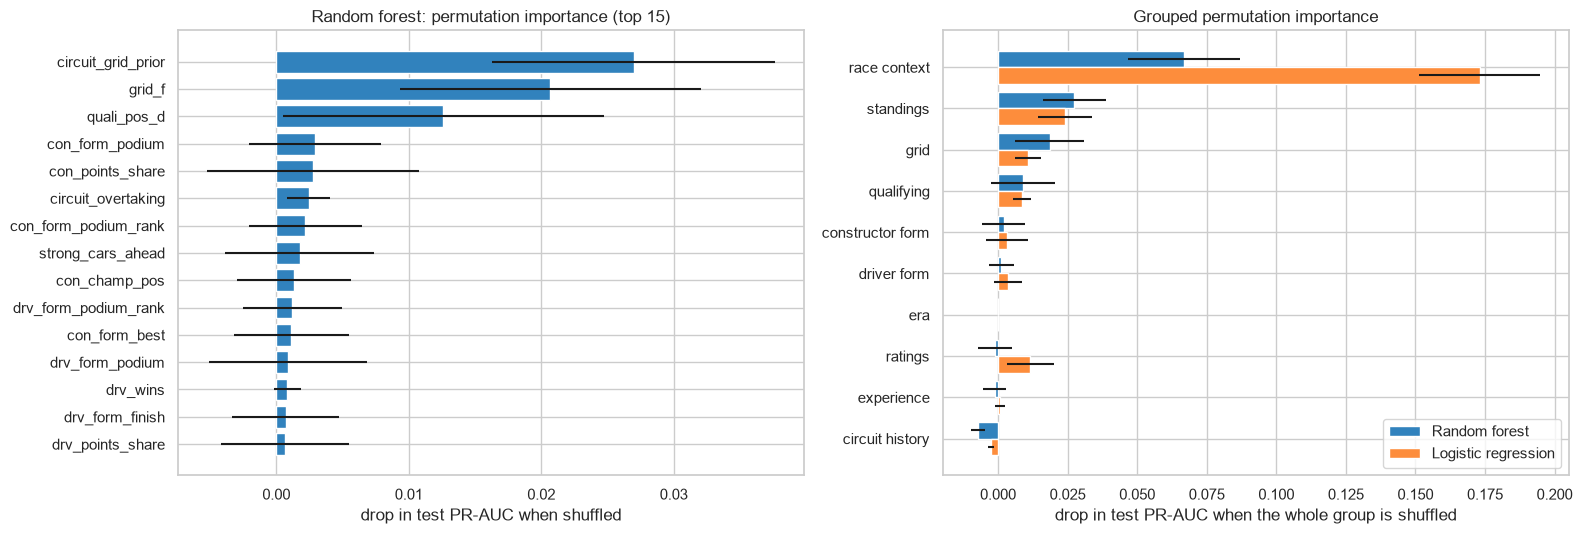

In [92]:
N_REPEATS = 30
perm = {fam: permutation_importance(FINAL_MODELS[fam], X_test, y_test, scoring='average_precision',
                                    n_repeats=N_REPEATS, random_state=SEED) for fam in ['RF', 'LR']}
perm_table = pd.DataFrame({f'{fam} mean': perm[fam].importances_mean for fam in perm} |
                          {f'{fam} sd': perm[fam].importances_std for fam in perm}, index=FEATURES)
perm_table['group'] = [next(g for g, fs in FINAL_GROUPS.items() if f in fs) for f in FEATURES]
print('Top 15 features (drop in test PR-AUC when shuffled)')
display(perm_table.sort_values('RF mean', ascending=False).head(15).round(4))

def grouped_permutation(model, X, y, groups, n_repeats=N_REPEATS, seed=SEED):
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, proba(model, X))
    out = {}
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            drops.append(base - average_precision_score(y, proba(model, Xp)))
        out[g] = (np.mean(drops), np.std(drops))
    return out

group_perm = {fam: grouped_permutation(FINAL_MODELS[fam], X_test, y_test, FINAL_GROUPS) for fam in ['RF', 'LR']}
group_perm_table = pd.DataFrame({f'{fam} {k}': {g: v[i] for g, v in group_perm[fam].items()}
                                 for fam in group_perm for i, k in enumerate(['mean', 'sd'])})
group_perm_table['sum of single-feature importances (RF)'] = perm_table.groupby('group')['RF mean'].sum()
print('Grouped permutation importance (drop in test PR-AUC)')
display(group_perm_table.sort_values('RF mean', ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
top = perm_table.sort_values('RF mean', ascending=False).head(15)[::-1]
axes[0].barh(top.index, top['RF mean'], xerr=top['RF sd'], color='#3182bd')
axes[0].set(xlabel='drop in test PR-AUC when shuffled', title='Random forest: permutation importance (top 15)')
gp = group_perm_table.sort_values('RF mean')
y_ = np.arange(len(gp))
axes[1].barh(y_ + 0.2, gp['RF mean'], height=0.4, xerr=gp['RF sd'], color='#3182bd', label='Random forest')
axes[1].barh(y_ - 0.2, gp['LR mean'], height=0.4, xerr=gp['LR sd'], color='#fd8d3c', label='Logistic regression')
axes[1].set_yticks(y_, [GROUP_LABEL[g] for g in gp.index])
axes[1].set(xlabel='drop in test PR-AUC when the whole group is shuffled', title='Grouped permutation importance')
axes[1].legend()
plt.tight_layout()
save_fig(fig, 's7_permutation_importance')
plt.show()

**Result.**
* **Single features:** the random forest relies on three: `circuit_grid_prior` (shuffling it costs 0.027 test PR-AUC),
  `grid_f` (0.021) and `quali_pos_d` (0.013). Every other feature costs under 0.003, with standard deviations larger
  than the means. For any one of them, a substitute carries the same information.
* **Groups:** race context (0.067) ≫ standings (0.027) > grid (0.019) > qualifying (0.009). Constructor form, driver
  form, era, ratings and experience are about 0.
* **Grouped importance is larger than the sum of its parts:** race context 0.067 vs 0.031 summed, standings 0.027 vs
  0.006. Shuffling one feature of a correlated group leaves its siblings to cover for it, which is why grouped
  permutation is needed.
* **Similar picture for LR.**
  * The same leading feature (`circuit_grid_prior`, 0.058), with `strong_cars_ahead` second (0.021) and qualifying /
    grid next (0.010 each).
  * The same top groups (race context 0.173, standings 0.024). LR leans even harder on race context, as in §7.1.
  * The two models agree on *which information* predicts a podium, even if they read it from different columns.
* **Circuit history is negative** (−0.007 RF, −0.003 LR): the model does *better* on 2022–24 when it is scrambled,
  which agrees with the ablation.
* **Permutation vs ablation.** Permutation asks what the *fitted* model uses. Ablation asks what a *refitted* model
  needs. Grid is 0.019 here but about 0 in ablation: the fitted forest uses it, but without it a new forest learns the
  same thing from qualifying and race context.

## 7.3 SHAP — global explanation
SHAP splits every single prediction into additive contributions:
**predicted probability = average prediction + Σ feature contributions.** `TreeExplainer` computes these exactly for
the random forest, including rows with missing values (checked below). Contributions are in **probability units**, so
+0.10 means "this feature raised the podium probability by 10 percentage points for this driver".
* **Beeswarm:** one dot per test row and feature. The position shows the contribution, the colour the feature's value
  (red = high, blue = low).
* **Dependence plots:** contribution against feature value for four key features. For `season` and `team_starts` the
  dashed line marks the largest training value, to show what the trees do beyond it.

average prediction (base value) 0.141; additivity check: max |base + Σ SHAP − prediction| = 1.3e-15 (rows with NaN: 1.0e-15)


,mean |SHAP| (prob. points),share of total
group,,
race context,0.070,0.294
standings,0.045,0.188
grid,0.031,0.131
driver form,0.030,0.129
qualifying,0.029,0.124
constructor form,0.019,0.080
ratings,0.009,0.037
experience,0.002,0.007
circuit history,0.002,0.007


share of total mean |SHAP| — personal attributes: {'drv_age': '0.3%', 'rookie_season': '0.0%', 'drv_starts': '0.1%'}


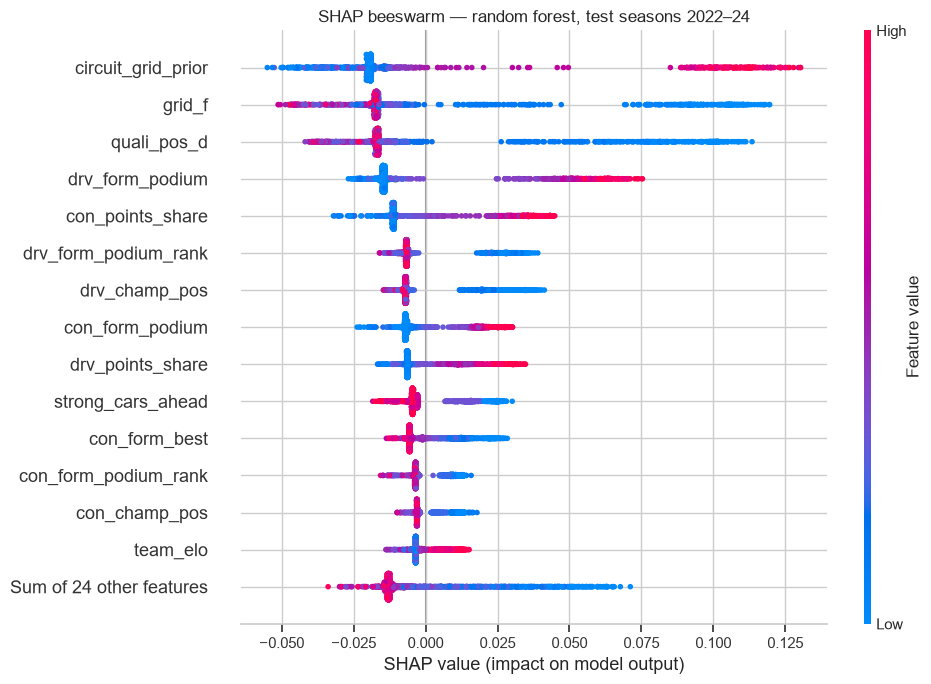

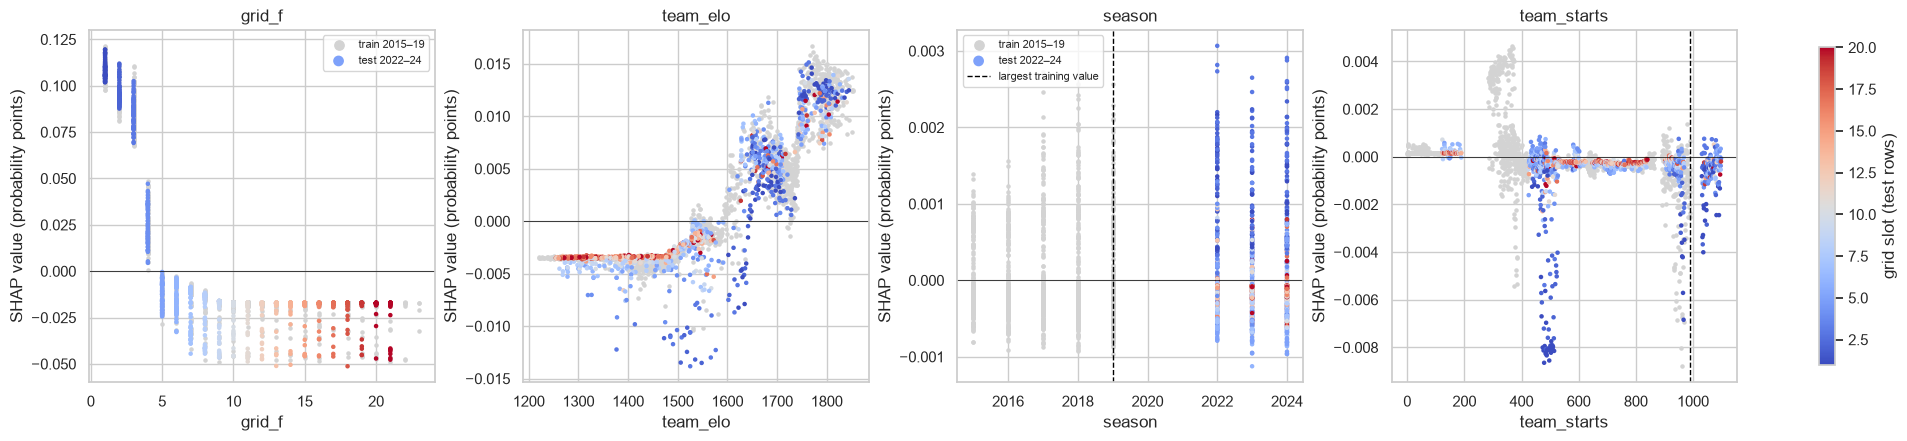

season: share of test rows beyond the largest training value 100%; mean |SHAP| on test 0.0004
team_starts: share of test rows beyond the largest training value 10%; mean |SHAP| on test 0.0006


In [93]:
rf_model = FINAL_MODELS['RF']
explainer = shap.TreeExplainer(rf_model)
shap_test = explainer(X_test)[:, :, 1]                        # contributions to P(podium)
base_value = float(np.atleast_1d(explainer.expected_value)[-1])
recon_err = np.abs(base_value + shap_test.values.sum(axis=1) - PRED[('RF', 'test')])
print(f'average prediction (base value) {base_value:.3f}; additivity check: max |base + Σ SHAP − prediction| = '
      f'{recon_err.max():.1e} (rows with NaN: {recon_err[has_nan["test"]].max():.1e})')

shap_imp = pd.Series(np.abs(shap_test.values).mean(axis=0), index=FEATURES)
shap_group = shap_imp.groupby(perm_table['group']).sum().sort_values(ascending=False)
display(pd.DataFrame({'mean |SHAP| (prob. points)': shap_group,
                      'share of total': shap_group / shap_group.sum()}).rename(index=GROUP_LABEL).round(3))
print('share of total mean |SHAP| — personal attributes:',
      {f: f'{shap_imp[f] / shap_imp.sum():.1%}' for f in ['drv_age', 'rookie_season', 'drv_starts', 'home_race']
       if f in shap_imp})

plt.figure()
shap.plots.beeswarm(shap_test, max_display=15, show=False)
fig = plt.gcf()
fig.set_size_inches(10, 7)
plt.title('SHAP beeswarm — random forest, test seasons 2022–24')
plt.tight_layout()
save_fig(fig, 's7_shap_beeswarm')
plt.show()

DEP = ['grid_f', 'team_elo', 'season', 'team_starts']
shap_recent = explainer(XS['train (2015–19)'])[:, :, 1]          # training rows, to show behaviour inside vs beyond range
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3), constrained_layout=True)
for ax, f in zip(axes, DEP):
    ax.scatter(XS['train (2015–19)'][f], shap_recent[:, f].values, s=5, color='lightgrey', label='train 2015–19')
    sc = ax.scatter(X_test[f], shap_test[:, f].values, s=5, c=X_test['grid_f'], cmap='coolwarm', vmin=1, vmax=20,
                    label='test 2022–24')
    if f in ('season', 'team_starts'):
        ax.axvline(X_train[f].max(), color='black', ls='--', lw=1, label='largest training value')
    ax.axhline(0, color='black', lw=0.5)
    ax.set(xlabel=f, ylabel='SHAP value (probability points)', title=f)
axes[0].legend(fontsize=8, markerscale=3)
axes[2].legend(fontsize=8, markerscale=3)
fig.colorbar(sc, ax=axes.tolist(), label='grid slot (test rows)', shrink=0.9)
save_fig(fig, 's7_shap_dependence')
plt.show()
for f in ['season', 'team_starts']:
    print(f'{f}: share of test rows beyond the largest training value {(X_test[f] > X_train[f].max()).mean():.0%}; '
          f'mean |SHAP| on test {np.abs(shap_test[:, f].values).mean():.4f}')

**Result.**
* **Additivity holds exactly** (error ≈ 1e-15, also for rows with missing values), so the SHAP values are a faithful
  split of every prediction. The average prediction is 0.141, close to the podium rate.
* **Beeswarm, which features push predictions the most:**
  * `circuit_grid_prior`: high values (red) add up to **+0.13** probability points.
  * `grid_f` and `quali_pos_d`: low positions (blue = front of the grid) add up to +0.12.
  * Then driver podium form, constructor points share, form rank and championship position. High form and a leading
    team add; low values subtract a little.
  * Every feature lowers the probability of most drivers by 0.01–0.03. Most starters are not podium contenders, and
    each piece of evidence confirms that a little.
* **By group (mean |SHAP|):** race context 29 %, standings 19 %, grid 13 %, driver form 13 %, qualifying 12 %,
  constructor form 8 %, ratings 4 %. Experience, circuit history and era are each under 1 %. Driver form matters more
  here than in permutation importance (§7.2). SHAP measures how much a feature *moves* predictions; permutation
  measures how much *ranking quality* depends on it. Driver form moves predictions, but `drv_form_podium_rank` and
  the standings carry the same information when it is scrambled.
* **Dependence plots:**
  * **`grid_f` is a step, not a line.** P1 adds about +0.11, P2 +0.09, P3 +0.08, P4 about +0.035, and P5 and
    lower −0.02 to −0.05, with little difference between P8 and P20. The model learned that podiums come from the
    first two rows of the grid.
  * **`team_elo`** rises steeply above about 1,600: only top teams get a boost.
  * **`season` and `team_starts`** (test values beyond the training range): their contributions are tiny, under
    ±0.003 and ±0.008 probability points. Beyond the largest training value the forest treats every row like the last
    training season. The extrapolation risk flagged in §5.7 is real in principle, but these features carry so little
    weight that it does not affect the predictions.

### 7.3.1 Intrinsic view: logistic-regression coefficients
Lab 4 separates **intrinsically interpretable** models from post-hoc explanations. Logistic regression is the
intrinsic one: its coefficients *are* the model. Because every input is standardised (§5.7.1), a coefficient is the
change in **log-odds of a podium for +1 training SD** of that feature, holding the others fixed. exp(coef) is the
odds ratio. The 18 missing-value flags have their own coefficients.

The coefficients are compared with the random forest's SHAP ranking, to see whether two very different models rely
on the same information.

intercept -3.005; C = 0.003 (strong L2 shrinkage); 25 of 56 coefficients are below 0.01 in absolute value


,coef (log-odds per +1 SD),odds ratio
circuit_grid_prior,0.262,1.300
strong_cars_ahead,-0.195,0.823
grid_f,-0.164,0.849
quali_pos_d,-0.160,0.852
team_elo,0.112,1.119
con_points_share,0.101,1.107
drv_form_podium,0.098,1.103
drv_elo,0.098,1.103
con_form_podium,0.097,1.102
drv_points_share,0.092,1.096


Spearman rank correlation, |LR coefficient| (incl. flag) vs RF mean |SHAP| over the 38 features: ρ = 0.88 (p = 3.9e-13)


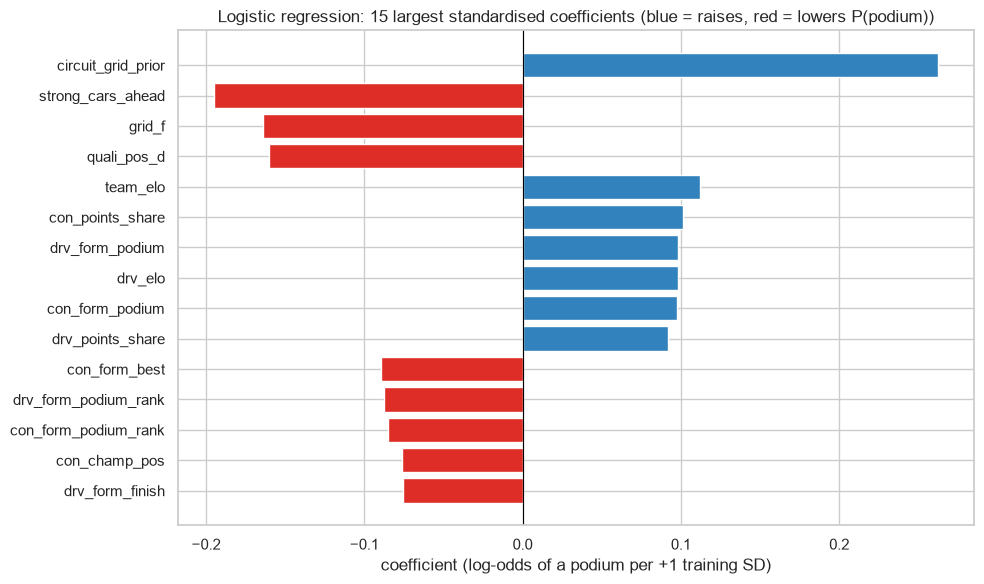

In [94]:
lr_model = FINAL_MODELS['LR']
coef = pd.Series(lr_model[-1].coef_[0], index=lr_model[:-1].get_feature_names_out(FEATURES))
coef_tab = pd.DataFrame({'coef (log-odds per +1 SD)': coef, 'odds ratio': np.exp(coef)})
coef_tab = coef_tab.reindex(coef.abs().sort_values(ascending=False).index)
print(f'intercept {lr_model[-1].intercept_[0]:+.3f}; C = {BEST_HP["LR"]["C"]} (strong L2 shrinkage); '
      f'{(coef.abs() < 0.01).sum()} of {len(coef)} coefficients are below 0.01 in absolute value')
display(coef_tab.head(12).round(3))

base_abs = coef.abs().groupby(lambda n: n.replace('missingindicator_', '')).sum().reindex(FEATURES)
from scipy.stats import spearmanr
rho, pval = spearmanr(base_abs, shap_imp.reindex(FEATURES))
print(f'Spearman rank correlation, |LR coefficient| (incl. flag) vs RF mean |SHAP| over the 38 features: '
      f'ρ = {rho:.2f} (p = {pval:.1e})')

fig, ax = plt.subplots(figsize=(10, 6))
top = coef_tab.head(15)[::-1]
ax.barh(top.index, top['coef (log-odds per +1 SD)'],
        color=np.where(top['coef (log-odds per +1 SD)'] > 0, '#3182bd', '#de2d26'))
ax.axvline(0, color='black', lw=0.8)
ax.set(xlabel='coefficient (log-odds of a podium per +1 training SD)',
       title='Logistic regression: 15 largest standardised coefficients (blue = raises, red = lowers P(podium))')
plt.tight_layout()
save_fig(fig, 's7_lr_coefficients')
plt.show()

**Result.**
* **Strong shrinkage:** the intercept is −3.0 (an average driver, p ≈ 0.05), and 25 of the 56 coefficients are below
  0.01. The L2 penalty (C = 0.003) concentrates the weight on a few features.
* **Largest effects (per +1 training SD):**
  * `circuit_grid_prior` **+0.26** (odds × 1.30);
  * `strong_cars_ahead` **−0.20** (× 0.82);
  * `grid_f` −0.16 and `quali_pos_d` −0.16 (a larger number means further back, so negative is the expected sign);
  * then team Elo, constructor points share, podium form and driver Elo (+0.09 to +0.11 each).
* **Every sign makes racing sense.** Rank-type features (`con_form_best`, `drv_form_podium_rank`, `con_champ_pos`)
  are negative because rank 1 is the best.
* **The two models agree.** The ranking of |coefficient| matches the random forest's mean |SHAP| ranking with Spearman
  **ρ = 0.88**: the intrinsically interpretable model and the black box rely on the same information. Both say
  starting position first (directly or through the circuit prior and strong cars ahead), then car and driver strength.
* **Caveat:** a coefficient is the effect *holding the other features fixed*. With heavily correlated features, the
  split of weight between them (e.g. `grid_f` vs `quali_pos_d`) is not stable. It is not a causal effect (§7.5).

## 7.4 Local explanation — one driver in one race
**Row-selection rule (fixed before looking):** among test drivers who started **P4 or lower** and **did** finish on
the podium, the one with the highest predicted probability. A front-row starter on the podium would teach little,
because the grid rule gets that right too. This row shows what the model knows *beyond* the grid.

The same prediction is explained twice, with two different methods:
* **SHAP waterfall:** exact contributions that add up from the average prediction to this prediction.
* **LIME:** fits a small linear model to the forest's predictions on 5,000 perturbed copies of the row. The copies are
  sampled from the training seasons 2015–19 (with medians filled in for missing values, since LIME cannot sample NaN),
  so that they look like modern F1 rather than the 1950s. LIME reports *ranges* ("grid_f ≤ 3") with weights.

If the two methods agree on the main reasons, the explanation does not depend on the method chosen.

Max Verstappen (Red Bull), 2024 British Grand Prix: started P4, qualified P4, finished P2
predicted podium probability 0.544 (threshold 0.34); 72 candidates satisfied the rule


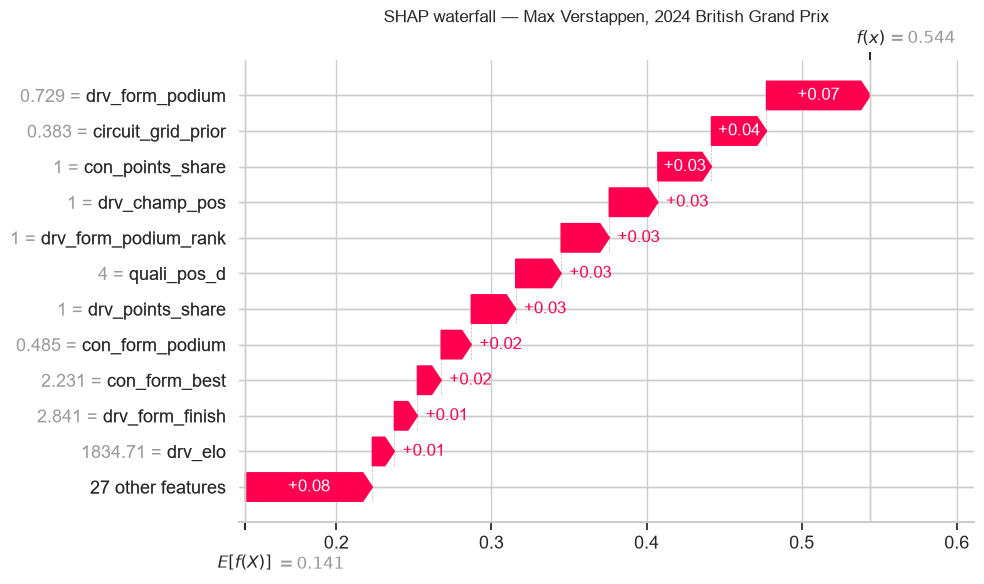

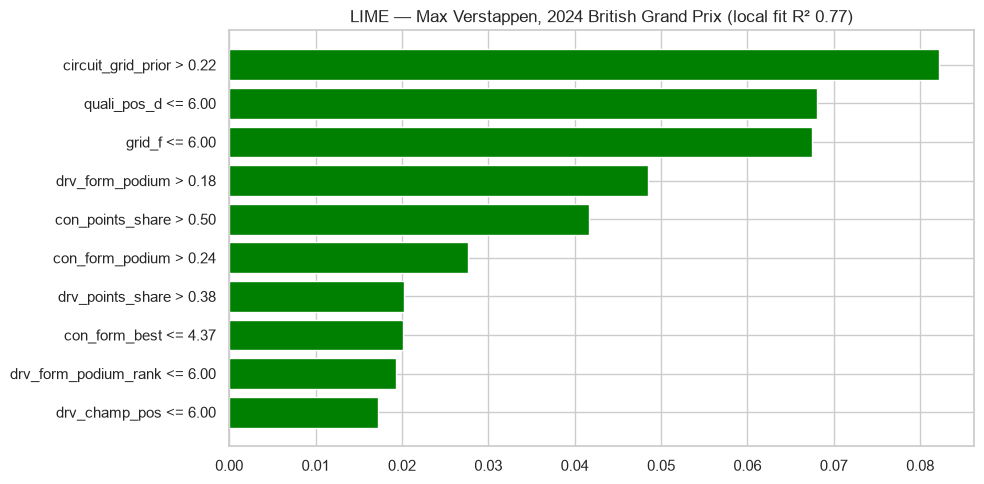

Top 10 SHAP features for this row vs LIME (9 of 10 also in LIME top 10)


,value,SHAP contribution,LIME weight,LIME rule,same direction
drv_form_podium,0.729,0.067,0.048,drv_form_podium > 0.18,yes
circuit_grid_prior,0.383,0.035,0.082,circuit_grid_prior > 0.22,yes
con_points_share,1.000,0.035,0.042,con_points_share > 0.50,yes
drv_champ_pos,1.000,0.031,0.017,drv_champ_pos <= 6.00,yes
drv_form_podium_rank,1.000,0.031,0.019,drv_form_podium_rank <= 6.00,yes
quali_pos_d,4.000,0.029,0.068,quali_pos_d <= 6.00,yes
drv_points_share,1.000,0.029,0.020,drv_points_share > 0.38,yes
con_form_podium,0.485,0.019,0.028,con_form_podium > 0.24,yes
con_form_best,2.231,0.015,0.020,con_form_best <= 4.37,yes
drv_form_finish,2.841,0.015,NaN,(not in LIME top 10),—


In [95]:
info = results_clean.set_index(['raceId', 'driverId'])[['year', 'race_name', 'driver', 'constructor', 'positionOrder', 'status']]
cand = test_df.assign(p=PRED[('RF', 'test')])
cand = cand[(cand['grid_f'] >= 4) & (cand['podium'] == 1)]
LOCAL_IDX = cand['p'].idxmax()
loc_row = test_df.loc[LOCAL_IDX]
li = info.loc[(loc_row['raceId'], loc_row['driverId'])]
loc_pos = test_df.index.get_loc(LOCAL_IDX)
print(f'{li["driver"]} ({li["constructor"]}), {li["year"]} {li["race_name"]}: started P{int(loc_row["grid_f"])}, '
      f'qualified P{int(loc_row["quali_pos_d"])}, finished P{int(li["positionOrder"])}')
print(f'predicted podium probability {PRED[("RF", "test")][loc_pos]:.3f} (threshold {THRESHOLDS["RF"]:.2f}); '
      f'{len(cand)} candidates satisfied the rule')

plt.figure()
shap.plots.waterfall(shap_test[loc_pos], max_display=12, show=False)
fig = plt.gcf()
fig.set_size_inches(10, 6)
plt.title(f'SHAP waterfall — {li["driver"]}, {li["year"]} {li["race_name"]}')
plt.tight_layout()
save_fig(fig, 's7_shap_waterfall')
plt.show()

medians = X_train.median()                                       # the same medians the LR / NN imputer uses
lime_background = X_train[RECENT].fillna(medians).values
lime_explainer = lime.lime_tabular.LimeTabularExplainer(lime_background, feature_names=FEATURES,
                                                        class_names=['no podium', 'podium'], mode='classification',
                                                        discretize_continuous=True, random_state=SEED)
lime_predict = lambda A: rf_model.predict_proba(pd.DataFrame(A, columns=FEATURES))
lime_exp = lime_explainer.explain_instance(X_test.iloc[loc_pos].fillna(medians).values, lime_predict,
                                           num_features=10, num_samples=5000)
fig = lime_exp.as_pyplot_figure(label=1)
fig.set_size_inches(10, 5)
plt.title(f'LIME — {li["driver"]}, {li["year"]} {li["race_name"]} (local fit R² {lime_exp.score:.2f})')
plt.tight_layout()
save_fig(fig, 's7_lime')
plt.show()

lime_w = {FEATURES[i]: w for i, w in lime_exp.as_map()[1]}
lime_rule = {FEATURES[i]: r for (r, _), (i, _) in zip(lime_exp.as_list(label=1), lime_exp.as_map()[1])}
top_shap = pd.Series(shap_test[loc_pos].values, index=FEATURES).abs().sort_values(ascending=False).head(10).index
agree = pd.DataFrame({'value': X_test.iloc[loc_pos][top_shap],
                      'SHAP contribution': pd.Series(shap_test[loc_pos].values, index=FEATURES)[top_shap],
                      'LIME weight': [lime_w.get(f, np.nan) for f in top_shap],
                      'LIME rule': [lime_rule.get(f, '(not in LIME top 10)') for f in top_shap]})
agree['same direction'] = np.where(agree['LIME weight'].isna(), '—',
                                   np.where(np.sign(agree['SHAP contribution']) == np.sign(agree['LIME weight']), 'yes', 'no'))
print(f'Top 10 SHAP features for this row vs LIME ({int(agree["LIME weight"].notna().sum())} of 10 also in LIME top 10)')
display(agree.round(3))

**Result.** The rule picks **Max Verstappen (Red Bull), 2024 British Grand Prix**: started P4, finished P2. The
random forest gave him **0.544** (above the 0.34 threshold, so a podium call). The grid rule would not have picked
him (P4).
* **SHAP waterfall, from the average 0.141 to 0.544:**
  * recent podium form +0.07 (`drv_form_podium` = 0.73: a podium in most recent races);
  * historical podium rate of a P4 start at Silverstone +0.04 (`circuit_grid_prior` = 0.38);
  * leading team in the constructors' championship +0.03, championship leader +0.03, best form in the field +0.03,
    qualifying P4 +0.03.

  The model's reasoning: *a P4 start, but by the championship leader in form, at a circuit where P4 often reaches the
  podium.* That is information the grid alone does not have.
* **LIME** fits its local model reasonably well (R² 0.77) and agrees. **9 of SHAP's top 10 features** are also in
  LIME's top 10, all with the **same direction**. Both name the circuit grid prior, qualifying position, podium form
  and the team's standing as the main reasons.
* **The one difference is the grid slot itself.** LIME ranks "`grid_f` ≤ 6" third (+0.067), but `grid_f` is not in
  SHAP's top 10 for this row. LIME's perturbed copies range over the whole field, where "start in the top 6" vs
  "start further back" is a big difference. SHAP credits the exact value P4, which sits right at the step where the
  grid effect almost disappears (§7.3), and gives the credit to the correlated `circuit_grid_prior` and `quali_pos_d`.
* **Verdict:** the two methods agree on the reasons, and they differ only in how they split credit between correlated
  position features (see §7.5).

## 7.5 Importance is not causation
Every method in this section explains **the model**, not **Formula 1**. A high importance means "the model uses this
feature to predict", not "this feature causes podiums".
* **Proxies.** `team_elo`, `con_points_share` and `con_form_podium` matter because they *stand for* car performance,
  which the dataset does not measure. Raising a team's Elo would not make its car faster. `drv_starts` stands for
  career survival: drivers who are good keep their seats.
* **Correlated features share credit arbitrarily.** Grid, qualifying and `circuit_grid_prior` encode almost the same
  thing. The model could rely on any of them, and the split between them (§7.2–7.3) reflects how the trees happened
  to split, not three separate effects. This is why the grouped views are the ones to read.
* **Reverse direction.** A good grid slot does not just cause podiums. Both come from the same fast car and driver.
  The grid's importance partly measures that shared cause.
* **Only within the data seen.** Contributions describe the model where it has training data. Beyond that (e.g.
  `season` > 2019, §7.3) the trees simply repeat their last value. That is not evidence of "no effect".
* **Scope.** Conclusions apply to this model, these features and these seasons. A low importance for circuit history
  or home race means "no added value given the other features", not "irrelevant to racing".

**Fairness and bias (Lab 4).**
* **No identity or sensitive attribute is a model feature.** Nationality, driver identity and team identity were
  excluded by design (§5.7.1). The only nationality-based feature, `home_race`, was tested and adds nothing (§7.1), so
  it is not in the model.
* **Age is a feature, but barely used:** `drv_age` carries **0.3 %** of the total mean |SHAP|, `rookie_season` 0.0 %,
  `drv_starts` 0.1 %.
* **Newcomers are judged by missing history, not by who they are.** A debutant gets a low probability because debutants
  rarely finish on the podium (2.5 %, §6.2.1) and there is no form to go on. That reflects the data, but it means the
  model cannot spot an exceptional rookie.
* **The model inherits F1's own bias towards established top teams.** Car performance dominates the sport, so the
  model leans on team strength. A rising team is recognised only after its results arrive (McLaren in 2024, §6.7).
  This is a limitation for prediction, not a fairness issue about people.

## 7.6 Step 7 summary
| Question | Answer | Evidence |
|---|---|---|
| Which information predicts a podium? | **Starting position** (grid, qualifying, encoded in race context) and **recent performance** (standings, form) | race context 29 %, standings 19 %, grid 13 %, driver form 13 %, qualifying 12 % of mean \|SHAP\| (§7.3) |
| Is any single group essential? | No. The groups overlap, so each can be removed with a loss under 0.012 | leave-one-group-out, CIs include 0 (§7.1) |
| Most important single features | `circuit_grid_prior`, `grid_f`, `quali_pos_d` | permutation importance (§7.2) |
| Do RF and LR agree? | Yes, on the leading feature and the top groups. LR depends more on race context | §7.1–7.2 |
| `home_race` | no added value | −0.001 / −0.003 (§7.1) |
| Weak or harmful groups | circuit history hurts on test (+0.011 without it); era / experience ≈ 0 | §7.1–7.2. Model **not** changed; recorded as a limitation |
| Extrapolation (`season`, `team_starts`) | real but harmless: contributions under 0.01 | dependence plots (§7.3) |
| LR coefficients vs RF SHAP | same ranking of information (Spearman ρ = 0.88); all signs plausible | §7.3.1 |
| Fairness | no identity / nationality features; age 0.3 % of SHAP weight; rookies judged by missing history | §7.5 |
| One prediction explained | Verstappen, 2024 British GP, P4 → P2, p = 0.544. Form, circuit grid prior and team standing lift him above the grid rule | SHAP and LIME agree on 9 / 10 features (§7.4) |

**Future work suggested by this section:** drop or rework circuit history, and simplify the feature set around the
race-context, grid and standings groups. Such choices would have to be made on validation data in a new round, never
on this test set.

**Handed to Step 8:** `explainer` (SHAP TreeExplainer for the RF), `shap_test`, `ablation`, `perm_table`,
`group_perm_table`, `fit_on(fam, cols)`, `medians` (training medians), `lime_explainer`. The race viewer in the
appendix (`show_race`, `list_races`) uses the same final models.

# 8. Inference Function
`predict_podium(record)` gives the pre-race podium prediction for **one driver in one race**, using the final models
from Step 6 exactly as frozen. Nothing is refitted.

**What a record is.** A record holds the 38 model features of one driver for one race. They are computed by the
leakage-safe pipeline of Step 4 (`build_features`) from information that exists **after qualifying and before the
start**: the grid, qualifying, standings after the previous race, form from past races only, and so on. `record_for()`
fetches such a record from the feature table, the way a deployed system would assemble it before a race.

**Rules of the function**
* **`grid_f` is required.** The starting slot is always known at the cutoff, and a prediction without it would be a
  guess. Every other feature may be missing (absent key, `None` or NaN).
* **Missing values are handled exactly as in training.** RF and gradient boosting send NaN down the branch they learned
  for missing values. LR and the NN fill the training median and set the missing flag inside their fitted pipelines.
  No new statistics are computed from the record.
* **Checks reported with every prediction:**
  * which features were missing;
  * which missing features are **never** missing in training (20 of the 38, e.g. `quali_pos_d`, `drv_starts`). The
    model has learned nothing about a gap in those, so the function attaches a **warning**;
  * which values lie outside the training range (trees cap such values, LR extrapolates);
  * keys that are not model features (ignored).
* **Output:**
  * the podium probability;
  * the podium call at the threshold frozen on validation (§6.6);
  * for the random forest, the three largest SHAP contributions as the "reasons".

In [96]:
TRAIN_MIN, TRAIN_MAX = X_train.min(), X_train.max()
NEVER_MISSING = [f for f in FEATURES if X_train[f].notna().all()]   # the model never learned what a gap here means
RESULT_INFO = results_clean.set_index(['raceId', 'driverId'])[['year', 'race_name', 'driver', 'constructor', 'positionOrder']]
MISSING_HANDLING = {'RF': 'native NaN branch (learned in training)', 'GB': 'native NaN branch (learned in training)',
                    'LR': 'training median + missing flag', 'NN': 'training median + missing flag'}

def record_for(race_id, driver_id):
    """The 38 pre-race features of one driver in one race, as computed by the Step 4 pipeline."""
    row = features[(features['raceId'] == race_id) & (features['driverId'] == driver_id)]
    if len(row) != 1:
        raise ValueError(f'no single modeling row for raceId {race_id}, driverId {driver_id}')
    return row[FEATURES].iloc[0].to_dict()

def predict_podium(record, model=BEST_MODEL, explain=True):
    """Pre-race podium prediction for one driver in one race.

    record : dict, pandas Series or one-row DataFrame with (some of) the 38 FEATURES. grid_f is required;
             any other feature may be absent, None or NaN.
    model  : 'RF' (selected model), 'GB', 'LR' or 'NN'.
    Returns a dict with the probability, the podium call at the frozen threshold, and data-quality notes.
    """
    if model not in FINAL_MODELS:
        raise ValueError(f'model must be one of {list(FINAL_MODELS)}')
    if isinstance(record, pd.DataFrame):
        if len(record) != 1:
            raise ValueError('predict_podium takes one record (one driver in one race) at a time')
        record = record.iloc[0]
    record = dict(record)
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}]).astype(float)   # None -> NaN
    if pd.isna(row.at[0, 'grid_f']):
        raise ValueError('grid_f (starting slot) is required — it is always known after qualifying')
    missing = [f for f in FEATURES if pd.isna(row.at[0, f])]
    out_of_range = [f for f in FEATURES if f not in missing
                    and not TRAIN_MIN[f] <= row.at[0, f] <= TRAIN_MAX[f]]
    unseen = [f for f in missing if f in NEVER_MISSING]
    p = float(proba(FINAL_MODELS[model], row)[0])
    result = {'model': LABEL[model], 'p_podium': round(p, 4), 'podium_call': bool(p >= THRESHOLDS[model]),
              'threshold': round(THRESHOLDS[model], 4), 'n_missing': len(missing), 'missing_features': missing,
              'missing_handled_by': MISSING_HANDLING[model] if missing else '—',
              'missing_never_seen_in_training': unseen,
              'outside_training_range': out_of_range, 'ignored_keys': sorted(set(record) - set(FEATURES)),
              'warning': (f'{len(unseen)} feature(s) missing that are never missing in training — the model has not '
                          'learned this situation; treat the probability with caution (e.g. fall back to the grid rule)')
                         if unseen else '—'}
    if explain and model == 'RF':
        sv = explainer(row)[:, :, 1].values[0]
        result['top_reasons'] = [f'{FEATURES[i]} = {row.iat[0, i]:.3g} → {sv[i]:+.3f}'
                                 for i in np.argsort(-np.abs(sv))[:3]]
    return result

def show_result(result, name):
    with pd.option_context('display.max_colwidth', None):
        display(pd.Series(result, name=name).to_frame())

def compare_models(record, label):
    """predict_podium for all four final models, as one table row each."""
    return pd.DataFrame([{'record': label, **{k: v for k, v in predict_podium(record, fam, explain=False).items()
                                              if k in ('model', 'p_podium', 'podium_call', 'n_missing')}}
                         for fam in FINAL_MODELS])

## 8.1 Demonstration on a complete record
**Choice (fixed rule):** the pole-sitter of the last race in the data, the **2024 Abu Dhabi Grand Prix**, a test-season
race the models never saw. The record must have no missing feature (asserted).

In [97]:
last_race = test_df.loc[test_df['date'].idxmax(), 'raceId']                     # 2024 Abu Dhabi GP
pole = test_df[test_df['raceId'] == last_race].nsmallest(1, 'grid_f').iloc[0]
complete_rec = record_for(last_race, pole['driverId'])
assert not any(pd.isna(v) for v in complete_rec.values()), 'complete record expected'
who = RESULT_INFO.loc[(last_race, pole['driverId'])]
print(f'{who["driver"]} ({who["constructor"]}), {who["year"]} {who["race_name"]} — grid P{int(pole["grid_f"])}; '
      f'actual result: P{int(who["positionOrder"])} ({"podium" if who["positionOrder"] <= 3 else "no podium"})')
print('first 8 features of the record:', {k: round(v, 3) for k, v in list(complete_rec.items())[:8]})

res_complete = predict_podium(complete_rec)
show_result(res_complete, 'predict_podium(complete record)')
display(compare_models(complete_rec, 'complete'))

Lando Norris (McLaren), 2024 Abu Dhabi Grand Prix — grid P1; actual result: P1 (podium)
first 8 features of the record: {'grid_f': 1.0, 'pit_lane_start': 0.0, 'quali_pos_d': 1.0, 'grid_penalty_d': 0.0, 'quali_source': 0.0, 'drv_champ_pos': 2.0, 'drv_points_share': 0.814, 'drv_wins': 3.0}


,predict_podium(complete record)
model,Random forest
p_podium,0.7274
podium_call,True
threshold,0.3366
n_missing,0
missing_features,[]
missing_handled_by,—
missing_never_seen_in_training,[]
outside_training_range,[season]
ignored_keys,[]


,record,model,p_podium,podium_call,n_missing
0,complete,Logistic regression,0.6898,True,0
1,complete,Random forest,0.7274,True,0
2,complete,Gradient boosting,0.7438,True,0
3,complete,Neural network,0.9597,True,0


**Result.** **Lando Norris (McLaren)** started the 2024 Abu Dhabi GP from pole.
* **Random forest:** P(podium) = **0.727**, a podium call (threshold 0.337). He won the race.
* **All four models make the call:** LR 0.690, gradient boosting 0.744, NN 0.960 (its class-weighted scores run
  higher, §6.7).
* **Reasons (SHAP):** pole position (+0.107), a historical podium rate of 0.71 for P1 at Yas Marina (+0.104) and
  qualifying P1 (+0.102).
* **The only data note is `season` = 2024,** which is beyond the training range. Trees treat it like 2019, and its
  contribution is negligible (§7.3).

## 8.2 Demonstration on partially-missing records
Two kinds of gaps occur at prediction time.
1. **Natural gaps:** a real test record with missing history. **Choice (fixed rule):** the test-season row with the
   most missing features (ties: the latest race). Typically a debut, often at a circuit the team has not raced at.
2. **Deliberately removed information:** the complete record from §8.1 with whole groups deleted, step by step. This
   shows how the prediction degrades and that the function still returns a valid answer. The last variant keeps
   only the grid slot.
3. **Invalid record:** without `grid_f` the function refuses with a clear error rather than guessing.

In [98]:
n_miss_test = X_test.isna().sum(axis=1)
gap_idx = n_miss_test[n_miss_test == n_miss_test.max()].index
gap_row = test_df.loc[gap_idx].sort_values('date').iloc[-1]
gap_rec = record_for(gap_row['raceId'], gap_row['driverId'])
gw = RESULT_INFO.loc[(gap_row['raceId'], gap_row['driverId'])]
print(f'{gw["driver"]} ({gw["constructor"]}), {gw["year"]} {gw["race_name"]} — grid P{int(gap_row["grid_f"])}, '
      f'driver starts before this race: {int(gap_row["drv_starts"])}; actual result: P{int(gw["positionOrder"])}')
res_gap = predict_podium(gap_rec)
show_result(res_gap, 'predict_podium(natural gaps)')
display(compare_models(gap_rec, 'natural gaps'))

Jack Doohan (Alpine F1 Team), 2024 Abu Dhabi Grand Prix — grid P17, driver starts before this race: 0; actual result: P15


,predict_podium(natural gaps)
model,Random forest
p_podium,0.0066
podium_call,False
threshold,0.3366
n_missing,6
missing_features,"[drv_form_podium, drv_form_finish, drv_form_dnf, drv_circuit_podium, drv_form_podium_rank, drv_form_finish_rank]"
missing_handled_by,native NaN branch (learned in training)
missing_never_seen_in_training,[]
outside_training_range,[season]
ignored_keys,[]


,record,model,p_podium,podium_call,n_missing
0,natural gaps,Logistic regression,0.0203,False,6
1,natural gaps,Random forest,0.0066,False,6
2,natural gaps,Gradient boosting,0.0129,False,6
3,natural gaps,Neural network,0.0001,False,6


In [99]:
REMOVE_STEPS = [('complete', []),
                ('− qualifying', FINAL_GROUPS['qualifying']),
                ('− qualifying − driver form', FINAL_GROUPS['qualifying'] + FINAL_GROUPS['driver_form']),
                ('− qualifying − driver form − circuit history',
                 FINAL_GROUPS['qualifying'] + FINAL_GROUPS['driver_form'] + FINAL_GROUPS['circuit_history']),
                ('grid slot only', [f for f in FEATURES if f != 'grid_f'])]
degrade = []
for label, drop in REMOVE_STEPS:
    rec = {k: v for k, v in complete_rec.items() if k not in drop}          # keys removed = information not available
    degrade.append(compare_models(rec, label))
degrade = pd.concat(degrade)
display(degrade.pivot_table(index='record', columns='model', values='p_podium', sort=False).round(3)
        .assign(**{'features missing': [len(d) for _, d in REMOVE_STEPS]}))
print(f'{len(NEVER_MISSING)} of {len(FEATURES)} features are never missing in training')
for label, drop in REMOVE_STEPS[1:]:
    r = predict_podium({k: v for k, v in complete_rec.items() if k not in drop})
    print(f'RF, {label}: p = {r["p_podium"]:.3f}, never-seen gaps: {len(r["missing_never_seen_in_training"])} '
          f'{r["missing_never_seen_in_training"][:4]}{" …" if len(r["missing_never_seen_in_training"]) > 4 else ""}')
res_grid = predict_podium({'grid_f': complete_rec['grid_f']})
short = {k: (f'{len(v)} features' + (' (all except grid_f)' if len(v) == len(FEATURES) - 1 else '')
             if isinstance(v, list) and len(v) > 6 else v) for k, v in res_grid.items()}
show_result(short, 'predict_podium(grid slot only)')

try:
    predict_podium({k: v for k, v in complete_rec.items() if k != 'grid_f'})
except ValueError as e:
    print(f'record without grid_f → ValueError: {e}')

model,Logistic regression,Random forest,Gradient boosting,Neural network,features missing
record,,,,,
complete,0.690,0.727,0.744,0.960,0
− qualifying,0.638,0.617,0.624,0.904,3
− qualifying − driver form,0.576,0.586,0.464,0.986,7
− qualifying − driver form − circuit history,0.560,0.577,0.462,0.978,10
grid slot only,0.036,0.166,0.213,0.439,37


20 of 38 features are never missing in training
RF, − qualifying: p = 0.617, never-seen gaps: 3 ['quali_pos_d', 'grid_penalty_d', 'quali_source']
RF, − qualifying − driver form: p = 0.586, never-seen gaps: 4 ['quali_pos_d', 'grid_penalty_d', 'quali_source', 'drv_form_n']
RF, − qualifying − driver form − circuit history: p = 0.577, never-seen gaps: 5 ['quali_pos_d', 'grid_penalty_d', 'quali_source', 'drv_form_n'] …
RF, grid slot only: p = 0.166, never-seen gaps: 19 ['pit_lane_start', 'quali_pos_d', 'grid_penalty_d', 'quali_source'] …


,predict_podium(grid slot only)
model,Random forest
p_podium,0.1657
podium_call,False
threshold,0.3366
n_missing,37
missing_features,37 features (all except grid_f)
missing_handled_by,native NaN branch (learned in training)
missing_never_seen_in_training,19 features
outside_training_range,[]
ignored_keys,[]


record without grid_f → ValueError: grid_f (starting slot) is required — it is always known after qualifying


**Result.**
* **Natural gaps: Jack Doohan (Alpine), 2024 Abu Dhabi GP.** It was his debut (0 previous starts), from P17.
  * Six features are missing: no driver form (3), no form ranks (2), no circuit history.
  * Every model handles them as it was trained to and predicts no podium (RF 0.007, LR 0.020, GB 0.013,
    NN 0.0001). He finished P15.
  * No warning is attached: these are exactly the gaps a debut always has, and the model learned them from the
    debutants in the training data.
* **Information removed step by step (RF):** 0.727 complete → 0.617 without qualifying → 0.586 also without driver
  form → 0.577 also without circuit history.
  * The probability falls gradually as evidence is removed, and the function always returns a valid answer.
  * The prediction stays a podium call, because the remaining standings, team form and race context still describe a
    front-running car.
* **The NN behaves differently:** 0.960 → 0.904 → **0.986** → 0.978. Removing driver form *raises* its score.
  The record has become a combination the NN never saw in training: qualifying is never missing there, so its gap is
  filled with the median (about P12) next to a P1 grid slot, and driver form is missing as well. A neural network's
  output on such inputs is not meaningful. This is one more sign (with §6.8) that the class-weighted NN is the least
  trustworthy model on unusual records, and the reason for the warning.
* **Grid slot only, the extreme case:** RF 0.166, GB 0.213, LR 0.036, NN 0.439, despite pole position.
  * A real pole-sitter in 2022–24 reaches the podium far more often than that.
  * 19 of the missing features are **never missing in training**, so the models have never seen a record like this.
    The trees send each gap down their default branch, and LR fills every gap with the median driver ("average form,
    midfield team").
  * This is why `predict_podium` attaches the **warning**: such a probability should not be trusted, and the grid rule
    is the safer fallback.
  * The demo makes this limit visible instead of hiding it.
* **Without `grid_f`** the function refuses with a `ValueError`. The starting slot is always known at the cutoff, so
  a record without it is an error in the input, not a gap to fill.

# 9. Conclusions
This section summarises the whole notebook. Each row points to the section with the evidence.

## 9.1 Answers at a glance
| Area | Result | Where |
|---|---|---|
| Data | 14 tables → **24,755 driver-race rows** (1950–2024), one per (raceId, driverId); 85 shared-drive duplicates resolved; Indy 500 and non-starters removed; 0 sentinel cells left; outliers checked and kept (real values) | §1–2 |
| Q1: front-row conversion | 68 % → **76 %** after 2014 (grid); Suzuka 89 %, Abu Dhabi 86 %, Monaco 85 % top after 2014; the ranking reshuffled (ρ = 0.21); front-row qualifiers moved back by a penalty converted only 22–31 % | §3.1 |
| Q2: home advantage | **none** once grid position is controlled for: MH OR 0.95 [0.80–1.13], p = 0.56 | §3.2 |
| Q3: mechanical DNFs | 9.9 % → **6.1 %** (2014–21 → 2022–24); Alpine lineage highest in both eras; Mercedes lowest 2014–21, McLaren and Red Bull lowest 2022–24 | §3.3 |
| Features | 38 leakage-safe, numeric pre-race features in 10 groups; time-travel test 0 / 3,510 mismatches | §4–5 |
| Split | train ≤ 2019 (recency-weighted) · validation 2020–21 · test 2022–24 | §5 |
| Best model | random forest (validation PR-AUC 0.745). **Test: PR-AUC 0.714, ROC-AUC 0.938, F1 0.686** (precision 0.62, recall 0.77), accuracy 0.895 | §6 |
| Model comparison | all four beat the grid rule on PR-AUC (test 0.694–0.718 vs 0.647); none beats logistic regression significantly | §6.7 |
| What the model uses | starting position + recent performance; race context alone matches all 38 features; `home_race` adds nothing; LR and RF agree (ρ = 0.88) | §7 |
| Inference | `predict_podium(record)` works on complete and incomplete records, and warns when a gap was never seen in training | §8 |

## 9.2 How to read the results
* **The model is useful, but not magic.** It ranks the podium contenders clearly better than "the first three on the
  grid" (PR-AUC +0.067, CI above 0). Its probabilities are well calibrated: a predicted 60 % happens about 60 % of the
  time (§6.7).
* **Its value is confidence, not picking.** Asked for exactly three names per race, it picks the grid's first three
  about as often as the grid rule does (test top-3 hit rate 0.642 vs 0.652). What it adds is *how sure* to be, e.g. P3
  in a dominant car vs P2 in a midfield car.
* **Accuracy is not the measure.** About 89–90 % for every model, but 85 % for a rule that never predicts a podium.
  That is why PR-AUC (primary) and F1 (secondary) are used.
* **Simple is enough.** Logistic regression is statistically tied with the tree models and the network. The signal is
  mostly monotone and additive: a better start, better form and a stronger car mean more podiums.

## 9.3 Limitations
* **Qualifying-coverage drift:** before 1994 the qualifying position is derived from the grid (verified only for
  1994–2002).
* **Era sensitivity:**
  * the test seasons are a new rules era;
  * circuit history does not carry over (§7.1);
  * the models lag mid-season swings (2024).
* **Small validation set:** 39 races, so most model differences are within noise and tuned validation scores are
  optimistic.
* **Missing information:** no weather, tyre or practice-pace data. Retirements and safety cars cannot be foreseen
  before the start.
* **Importance ≠ causation (§7.5):** the explanations describe the model, not the sport.

# Appendix: race viewer (extra, not part of the graded steps)
An interactive check of the models: pick any race and see the predicted podium next to the real result. Edit `RACE`
(and optionally `MODEL`) in the last cell and re-run that cell only.
* `RACE` can be a raceId (`1121`), a season + round (`(2024, 5)`) or a season + part of the race or circuit name
  (`(2024, 'Monaco')`). `list_races(2024)` lists a season's races.
* `MODEL` is `'RF'` (selected model), `'LR'`, `'GB'`, `'NN'` or `'all'` (all four side by side; the table is then sorted
  by the random forest).
* **Predicted podium (★)** = the model's 3 highest-probability drivers. The probability column is the model's
  pre-race estimate. Drivers above the model's threshold (§6.6) are marked "call".

**Which races are a fair test?** Only **2022–2024** (test seasons). The models never saw those results. 2020–21 were
used to tune the settings, so they are slightly optimistic, and for races up to 2019 the model was trained on that very
result. The viewer prints this warning for every race.

In [100]:
VIEW = pd.concat([train_df, val_df, test_df])
RACE_INFO = results_clean.drop_duplicates('raceId').set_index('raceId')[['year', 'round', 'race_name', 'circuit', 'date']]
DRIVER_INFO = results_clean.set_index(['raceId', 'driverId'])[['driver', 'constructor', 'positionOrder', 'status']]
SPLIT_NOTE = {'test': 'TEST season — the model never saw this result: a fair test.',
              'validation': 'VALIDATION season — used to tune the settings: slightly optimistic.',
              'train': 'TRAINING season — the model learned from this very result: optimistic, not a real test.'}

def list_races(year):
    """Races of one season that are in the modeling table (raceId, round, name, circuit, date)."""
    ids = VIEW.loc[VIEW['year'] == year, 'raceId'].unique()
    display(RACE_INFO.loc[ids].sort_values('round').assign(date=lambda d: d['date'].dt.date))

def find_race(race):
    """raceId from a raceId, (season, round) or (season, part of race/circuit name)."""
    if isinstance(race, (int, np.integer)):
        if race not in RACE_INFO.index:
            raise ValueError(f'raceId {race} not found')
        return int(race)
    year, key = race
    r = RACE_INFO[RACE_INFO['year'] == year]
    if isinstance(key, (int, np.integer)):
        m = r[r['round'] == key]
    else:
        m = r[r['race_name'].str.contains(key, case=False) | r['circuit'].str.contains(key, case=False)]
    if len(m) != 1:
        raise ValueError(f'{race}: {len(m)} matching races — {list(m["race_name"])}. Use list_races({year}).')
    return int(m.index[0])

def show_race(race, model='RF'):
    rid = find_race(race)
    rows = VIEW[VIEW['raceId'] == rid]
    if rows.empty:
        raise ValueError(f'raceId {rid} is not in the modeling table (e.g. an excluded Indianapolis 500).')
    fams = list(NAMES) if model == 'all' else [model]
    sort_by = 'RF' if model == 'all' else model
    probs = {f: predict_final(f, rows[FEATURES], rows['raceId'].values) for f in fams}
    ri, split = RACE_INFO.loc[rid], rows['split'].iloc[0]
    t = DRIVER_INFO.loc[[(rid, d) for d in rows['driverId']]].reset_index(drop=True)
    t.insert(2, 'grid', np.where(rows['pit_lane_start'].values == 1, 'pit lane', rows['grid_f'].astype(int).astype(str).values))
    t.insert(3, 'quali', rows['quali_pos_d'].astype(int).values)
    for f in fams:
        t[f'P(podium) {f}'] = probs[f]
    t = t.sort_values(f'P(podium) {sort_by}', ascending=False).reset_index(drop=True)
    t.insert(0, 'predicted', ['★' if i < 3 else '' for i in range(len(t))])
    t['call'] = np.where(t[f'P(podium) {sort_by}'] >= THRESHOLDS[sort_by], 'call', '')
    t['finish'] = t['positionOrder']
    t['result'] = np.where(t['finish'] <= 3, '✓ podium', '')
    t['status'] = np.where(t['status'] == 'Finished', '', t['status'])

    print(f'{ri["year"]} {ri["race_name"]} (round {ri["round"]}) — {ri["circuit"]}, {ri["date"]:%d %b %Y}  [raceId {rid}]')
    print(SPLIT_NOTE[split])
    print(f'model: {LABEL[sort_by]}' + (' (table sorted by it; all four shown)' if model == 'all' else ''))
    cols = ['predicted', 'driver', 'constructor', 'grid', 'quali'] + [f'P(podium) {f}' for f in fams] + \
           ['call', 'finish', 'result', 'status']
    display(t[cols].style.format({f'P(podium) {f}': '{:.1%}' for f in fams}).hide(axis='index'))

    actual = t.loc[t['finish'] <= 3].sort_values('finish')['driver'].tolist()
    predicted = t.loc[:2, 'driver'].tolist()
    grid_top3 = rows.nsmallest(3, 'grid_f')['driverId']
    grid_hits = int(rows.set_index('driverId').loc[grid_top3, 'podium'].sum())
    print(f'predicted podium: {", ".join(predicted)}')
    print(f'actual podium   : {", ".join(actual)}')
    print(f'{LABEL[sort_by]} picked {len(set(predicted) & set(actual))}/3 podium finishers; '
          f'the grid rule (first three on the grid) picked {grid_hits}/3.')

In [101]:
RACE = (2024, 'Abu Dhabi')     # a raceId, (season, round) or (season, 'part of the name') — see list_races(2024)
MODEL = 'RF'                   # 'RF', 'LR', 'GB', 'NN' or 'all'
show_race(RACE, MODEL)

2024 Abu Dhabi Grand Prix (round 24) — Yas Marina Circuit, 08 Dec 2024  [raceId 1144]
TEST season — the model never saw this result: a fair test.
model: Random forest


predicted,driver,constructor,grid,quali,P(podium) RF,call,finish,result,status
★,Lando Norris,McLaren,1,1,72.7%,call,1,✓ podium,
★,Oscar Piastri,McLaren,2,2,63.0%,call,10,,
★,Carlos Sainz,Ferrari,3,3,60.7%,call,2,✓ podium,
,Max Verstappen,Red Bull,4,5,48.5%,call,6,,
,Charles Leclerc,Ferrari,19,14,29.3%,,3,✓ podium,
,George Russell,Mercedes,6,7,14.8%,,5,,
,Lewis Hamilton,Mercedes,16,18,11.7%,,4,,
,Sergio Pérez,Red Bull,10,10,7.5%,,20,,Collision
,Nico Hülkenberg,Haas F1 Team,7,4,6.0%,,8,,
,Pierre Gasly,Alpine F1 Team,5,6,3.8%,,7,,


predicted podium: Lando Norris, Oscar Piastri, Carlos Sainz
actual podium   : Lando Norris, Carlos Sainz, Charles Leclerc
Random forest picked 2/3 podium finishers; the grid rule (first three on the grid) picked 2/3.
